# Topography and genomic instability of Z-DNA sequences in the human pangenome

## Directories

In [ ]:
# # zseeker haplotypes path
# /scratch/10906/geomeg/pangenomes_hprc/human_pangenome/zdna_csvs
# /corral/utexas/BCS25073/igs_group/group_resources/human_pangenome

In [1]:
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl")

## HPRC data and metadata source

In [ ]:
# https://data.humanpangenome.org
# https://42basepairs.com/browse/s3/human-pangenomics/pangenomes/freeze/release2/minigraph-cactus
# https://github.com/human-pangenomics/hprc_intermediate_assembly

## ZSeeker

In [ ]:
# #!/bin/bash
# #
# #SBATCH --job-name=zseeker_pangenome
# #SBATCH --output=zseeker_pangenome_%j.out
# #SBATCH --error=zseeker_pangenome_%j.err
# #
# #SBATCH --partition=gg
# #SBATCH --nodes=1
# #SBATCH --ntasks-per-node=1
# #SBATCH --cpus-per-task=20
# #SBATCH --time=48:00:00
# #SBATCH --mail-type=END,FAIL
# #SBATCH -A BCS25073

# echo "===================================================="
# echo "ZSeeker Pangenome job started on $(hostname) at $(date)"
# echo "===================================================="

# # --- Activate environment ---
# source ~/.bashrc
# conda activate zseeker_env

# # --- Directories ---
# INPUT_DIR="/scratch/10906/geomeg/pangenome_fastas/human_pangenome/assemblies"
# OUTPUT_DIR="/scratch/10906/geomeg/pangenome_fastas/human_pangenome/zdna_csvs"

# mkdir -p "$OUTPUT_DIR"

# echo "Input directory:  $INPUT_DIR"
# echo "Output directory: $OUTPUT_DIR"
# echo "===================================================="

# # --- Find all FASTA files ---
# mapfile -t FILES < <(find "$INPUT_DIR" -type f \( -name "*.fa.gz" -o -name "*.fasta.gz" \) | sort)

# echo "🧬 Found ${#FILES[@]} compressed FASTA files."
# if (( ${#FILES[@]} == 0 )); then
#     echo "❌ No FASTA files found. Exiting."
#     exit 1
# fi

# # --- Function to run ZSeeker on one file ---
# run_zseeker() {
#     fasta_path="$1"
#     output_dir="$2"
#     base=$(basename "$fasta_path" .gz)
#     base=${base%.fasta}
#     base=${base%.fa}

#     echo "▶️ Running ZSeeker on: $base"

#     tmpdir=$(mktemp -d /scratch/10906/geomeg/tmp_zseeker_${base}_XXXX)
#     out_csv="${output_dir}/${base}.zseeker.csv"

#     if [[ -f "$out_csv" ]]; then
#         echo "⚠️ Skipping existing output: $out_csv"
#     else
#         gunzip -c "$fasta_path" > "${tmpdir}/${base}.fasta"
#         ZSeeker --fasta "${tmpdir}/${base}.fasta" --output_dir "$tmpdir" --n_jobs 1
#         csv_file=$(find "$tmpdir" -type f -name '*.csv' | head -n 1)
#         if [[ -n "$csv_file" ]]; then
#             mv "$csv_file" "$out_csv"
#             echo "✅ Output saved: $out_csv"
#         else
#             echo "⚠️ No CSV produced for $base"
#         fi
#     fi

#     rm -rf "$tmpdir"
#     echo "✅ Finished: $base"
# }
# export -f run_zseeker

# # --- Parallel execution (20 concurrent jobs) ---
# printf "%s\n" "${FILES[@]}" | xargs -P20 -I{} bash -c 'run_zseeker "{}" "$1"' _ "$OUTPUT_DIR"

# echo "===================================================="
# echo "All ZSeeker runs completed at $(date)"
# echo "Results saved in: $OUTPUT_DIR"
# echo "===================================================="

In [ ]:
# All files zipped to ...vista/pangenomes_zdna/zdna_csvs_hprc_20251024.tar.gz

## Metadata manual curation

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm

meta_file = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_release2_metadata.csv")
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
out_tsv   = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")

meta = pd.read_csv(meta_file)
if "sample_id" not in meta.columns:
    raise SystemExit("sample_id column missing")

records = []
for f in sorted(csv_dir.glob("*.csv")):
    name = f.name
    low  = name.lower()
    records.append({
        "filename": name,
        "sample_id": name.split("_")[0],
        "pat_or_mat": "pat" if "pat" in low else "mat" if "mat" in low else "0",
        "hap1_or_hap2": "hap1" if "hap1" in low else "hap2" if "hap2" in low else "0",
    })

base = pd.DataFrame(records).merge(meta, on="sample_id", how="left", validate="many_to_one")

stats = []
for f in tqdm(sorted(csv_dir.glob("*.csv")), desc="Processing Z-DNA CSVs"):
    try:
        d = pd.read_csv(f, dtype={"Chromosome": str})
    except Exception:
        continue
    d = d.dropna(subset=["Chromosome", "Start", "End", "Z-DNA Score", "Sequence"])
    d["Start"] = pd.to_numeric(d["Start"], errors="coerce")
    d["End"] = pd.to_numeric(d["End"], errors="coerce")
    d["Z-DNA Score"] = pd.to_numeric(d["Z-DNA Score"], errors="coerce")
    d = d.dropna(subset=["Start", "End", "Z-DNA Score"])
    stats.append({
        "filename": f.name,
        "n_predictions": len(d),
        "average_length": round((d["End"] - d["Start"] + 1).mean(), 3) if len(d) else np.nan,
        "average_score": round(d["Z-DNA Score"].mean(), 3) if len(d) else np.nan,
    })

out = base.merge(pd.DataFrame(stats), on="filename", how="left", validate="one_to_one")
cols = ["filename", "sample_id", "pat_or_mat", "hap1_or_hap2"]
out = out[cols + [c for c in out.columns if c not in cols]]
out.to_csv(out_tsv, sep="\t", index=False)
print(f"Wrote {len(out)} rows to {out_tsv}")

## Chromosomes and noncanonical contigs

### Analysis scripts

In [ ]:
#!/usr/bin/env python3
import gzip
import re
import pandas as pd
from pathlib import Path
import sys

if len(sys.argv) != 2:
    raise SystemExit("Usage: build_hprc_haplotype_tables.py <zseeker_csv_filename>")

TARGET_CSV = sys.argv[1]

META_PATH  = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
ZDNA_DIR   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
FASTA_DIR  = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/assemblies")
ALIAS_DIR  = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/chrom_aliases")
OUTDIR     = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/haplotype_tables")
OUTDIR.mkdir(parents=True, exist_ok=True)

CANONICAL = {f"chr{i}" for i in range(1, 23)} | {"chrX", "chrY"}
MITO = {"chrM", "chrMT", "MT", "M"}
N_RUN_RE = re.compile(r"[Nn]{10,}")

def fasta_from_zseeker(filename: str) -> str:
    return filename.replace(".zseeker.csv", ".fa.gz")

def infer_alias_key(name: str) -> str:
    n = name.lower()
    if "_pat" in n or "#1#" in n or "_hap1" in n:
        return "pat"
    if "_mat" in n or "#2#" in n or "_hap2" in n:
        return "mat"
    return ""

def find_alias_file(stem: str, prefix: str, key: str):
    exact = list(ALIAS_DIR.glob(f"{stem}.chromAlias.txt"))
    if exact:
        return exact[0]
    if key:
        cand = list(ALIAS_DIR.glob(f"{prefix}*{key}*.chromAlias.txt"))
        if cand:
            return cand[0]
    cand = list(ALIAS_DIR.glob(f"{prefix}*.chromAlias.txt"))
    return cand[0] if cand else None

def load_alias_map(alias_file: Path) -> dict:
    lines = [l.strip() for l in open(alias_file) if l.strip() and not l.startswith("#")]
    parts = [l.split() for l in lines]
    df = pd.DataFrame(parts, columns=["assembly", "ucsc", "genbank"]).apply(lambda x: x.str.strip())
    return dict(zip(df["assembly"], df["ucsc"]))

def chr_class(ucsc: str) -> str:
    if ucsc in CANONICAL:
        return "canonical"
    if ucsc in MITO:
        return "noncanonical"
    if ucsc.startswith("chr"):
        return "noncanonical"
    return "unmapped"


def genome_sizes_from_fasta(fasta_gz: Path, alias_map: dict):
    bp = {"canonical": 0, "noncanonical": 0, "unmapped": 0}

    contig = None
    seq_chunks = []

    def flush(cname, seq):
        if cname is None or not seq:
            return
        total_len = len(seq)
        n_masked = sum(m.end() - m.start() for m in N_RUN_RE.finditer(seq))
        eff = total_len - n_masked

        ucsc = alias_map.get(cname)
        if ucsc is None:
            bp["unmapped"] += eff
        elif ucsc in CANONICAL:
            bp["canonical"] += eff
        else:
            bp["noncanonical"] += eff

    with gzip.open(fasta_gz, "rt") as fh:
        for line in fh:
            if line.startswith(">"):
                flush(contig, "".join(seq_chunks))
                contig = line[1:].strip().split()[0]
                seq_chunks = []
            else:
                seq_chunks.append(line.strip())

        flush(contig, "".join(seq_chunks))

    return bp


def zdna_burden_from_zseeker(csv_path: Path, alias_map: dict):
    bp = {"canonical": 0, "noncanonical": 0, "unmapped": 0}
    df = pd.read_csv(csv_path, dtype=str)
    if "Chromosome" not in df.columns or "Start" not in df.columns or "End" not in df.columns:
        return bp, 0, 0, 0

    df = df.dropna(subset=["Chromosome", "Start", "End"])
    df["Start"] = pd.to_numeric(df["Start"], errors="coerce")
    df["End"] = pd.to_numeric(df["End"], errors="coerce")
    df = df.dropna(subset=["Start", "End"])
    df["len"] = (df["End"].astype(int) - df["Start"].astype(int) + 1)

    mapped = df["Chromosome"].astype(str).str.strip().map(alias_map)
    for l, ucsc in zip(df["len"].tolist(), mapped.tolist()):
        if pd.isna(ucsc):
            bp["unmapped"] += int(l)
        else:
            bp[chr_class(ucsc)] += int(l)

    n_total = len(df)
    n_unmapped = int(mapped.isna().sum())
    n_mapped = n_total - n_unmapped
    return bp, n_total, n_mapped, n_unmapped

meta = pd.read_csv(META_PATH, sep="\t", dtype=str).fillna("")
row = meta.loc[meta["filename"] == TARGET_CSV]

if row.empty:
    raise SystemExit(f"❌ filename not found in metadata: {TARGET_CSV}")

row = row.iloc[0]

fname = TARGET_CSV
zpath = ZDNA_DIR / fname
fasta = FASTA_DIR / fasta_from_zseeker(fname)

stem = fasta.name.replace(".fa.gz", "")
prefix = fasta.name.split("_")[0]
key = infer_alias_key(fasta.name)

alias_file = find_alias_file(stem, prefix, key)
if alias_file is None:
    raise SystemExit(f"❌ Alias file not found for {fname}")

alias_map = load_alias_map(alias_file)

if not zpath.exists():
    raise SystemExit(f"❌ ZSeeker CSV not found: {zpath}")

zdna_bp, n_total, n_mapped, n_unmapped = zdna_burden_from_zseeker(zpath, alias_map)

mapping_qc = {
    "filename": fname,
    "alias_file": alias_file.name,
    "n_intervals_total": n_total,
    "n_intervals_mapped": n_mapped,
    "n_intervals_unmapped_to_alias": n_unmapped,
}
if not fasta.exists():
    raise SystemExit(f"❌ FASTA not found: {fasta}")

g = genome_sizes_from_fasta(fasta, alias_map)

genome_sizes = {
    "genome_bp_canonical_effective": g["canonical"],
    "genome_bp_noncanonical_effective": g["noncanonical"],
    "genome_bp_unmapped_effective": g["unmapped"],
}
out_row = {
    "filename": fname,
    "fasta_file": fasta.name,
    "alias_file": alias_file.name,
    **mapping_qc,
    "zdna_bp_canonical": zdna_bp["canonical"],
    "zdna_bp_noncanonical": zdna_bp["noncanonical"],
    "zdna_bp_unmapped": zdna_bp["unmapped"],
    **genome_sizes,
}

out_row["zdna_bp_per_mb_canonical"] = (
    out_row["zdna_bp_canonical"] /
    (out_row["genome_bp_canonical_effective"] / 1e6)
    if out_row["genome_bp_canonical_effective"] > 0 else float("nan")
)
OUT_CHUNKS = OUTDIR / "haplotype_chunks"
OUT_CHUNKS.mkdir(parents=True, exist_ok=True)

out_file = OUT_CHUNKS / f"{fname}.tsv"

pd.DataFrame([out_row]).to_csv(out_file, sep="\t", index=False)

print(f"✅ Wrote {out_file}")

#!/bin/bash
#SBATCH -J hprc_tables
#SBATCH -p gg
#SBATCH -N 1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH -t 24:00:00
#SBATCH -o logs/hprc_tables_%j.out
#SBATCH -e logs/hprc_tables_%j.err

set -euo pipefail

cd /work/10906/geomeg/vista/pangenomes_zdna

mkdir -p logs
mkdir -p tmp/haplotype_tables/haplotype_chunks

source /work/10906/geomeg/vista/miniconda3/etc/profile.d/conda.sh
conda activate py_env

python - << 'EOF'
import pandas as pd
df = pd.read_csv("hprc_zdna_metrics.tsv", sep="\t", dtype=str)
mask = df["sample_id"].str.startswith(("H","N"))
df.loc[mask, "filename"].to_csv("tmp/hap_list.txt", index=False, header=False)
EOF

xargs -n 1 -P 16 --no-run-if-empty python -u build_hprc_haplotype_tables.py < tmp/hap_list.txt

#!/usr/bin/env python3
import gzip
import re
import pandas as pd
from pathlib import Path
import sys

if len(sys.argv) != 2:
    raise SystemExit("Usage: build_hg002_haplotype_tables.py <zseeker_csv_filename>")

TARGET_CSV = sys.argv[1]

ZDNA_DIR  = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
FASTA_DIR = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/assemblies")
OUTDIR    = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/haplotype_tables/haplotype_chunks")
OUTDIR.mkdir(parents=True, exist_ok=True)

CANONICAL = {f"chr{i}" for i in range(1, 23)} | {"chrX", "chrY"}
MITO = {"chrM", "chrMT"}
N_RUN_RE = re.compile(r"[Nn]{10,}")

def chr_class(chrname: str) -> str:
    if chrname in CANONICAL:
        return "canonical"
    if chrname in MITO:
        return "noncanonical"
    if chrname.startswith("chr"):
        return "noncanonical"
    return "unmapped"

def genome_sizes_from_fasta(fasta_gz: Path):
    bp = {"canonical": 0, "noncanonical": 0, "unmapped": 0}
    contig = None
    seq_chunks = []

    def flush(name, seq):
        if name is None or not seq:
            return
        total = len(seq)
        n_masked = sum(m.end() - m.start() for m in N_RUN_RE.finditer(seq))
        eff = total - n_masked
        bp[chr_class(name)] += eff

    with gzip.open(fasta_gz, "rt") as fh:
        for line in fh:
            if line.startswith(">"):
                flush(contig, "".join(seq_chunks))
                contig = line[1:].strip().split("#")[-1]
                seq_chunks = []
            else:
                seq_chunks.append(line.strip())
        flush(contig, "".join(seq_chunks))

    return bp

def zdna_burden_from_zseeker(csv_path: Path):
    bp = {"canonical": 0, "noncanonical": 0, "unmapped": 0}
    df = pd.read_csv(csv_path, dtype=str)

    df = df.dropna(subset=["Chromosome", "Start", "End"])
    df["Start"] = pd.to_numeric(df["Start"], errors="coerce")
    df["End"] = pd.to_numeric(df["End"], errors="coerce")
    df = df.dropna(subset=["Start", "End"])
    df["len"] = df["End"].astype(int) - df["Start"].astype(int) + 1

    chroms = df["Chromosome"].astype(str).str.split("#").str[-1]

    for l, c in zip(df["len"], chroms):
        bp[chr_class(c)] += int(l)

    return bp, len(df), 0, 0

# --------------------------------------------------
# Run
# --------------------------------------------------
zpath = ZDNA_DIR / TARGET_CSV
def fasta_from_zseeker_hg002(csv_name: str) -> str:
    if csv_name == "HG002_v1.1.mat_MT.PanSN.zseeker.csv":
        return "hg002v1.1.mat_MT.PanSN.fa.gz"
    if csv_name == "HG002_v1.1.pat.PanSN.zseeker.csv":
        return "hg002v1.1.pat.PanSN.fa.gz"
    raise SystemExit(f"❌ Unknown HG002 CSV name: {csv_name}")

fasta = FASTA_DIR / fasta_from_zseeker_hg002(TARGET_CSV)

if not zpath.exists():
    raise SystemExit(f"❌ ZSeeker CSV not found: {zpath}")
if not fasta.exists():
    raise SystemExit(f"❌ FASTA not found: {fasta}")

zdna_bp, n_total, _, _ = zdna_burden_from_zseeker(zpath)
g = genome_sizes_from_fasta(fasta)

out = {
    "filename": TARGET_CSV,
    "fasta_file": fasta.name,
    "alias_file": "INFERRED_FROM_HEADER",
    "n_intervals_total": n_total,
    "n_intervals_mapped": n_total,
    "n_intervals_unmapped_to_alias": 0,
    "zdna_bp_canonical": zdna_bp["canonical"],
    "zdna_bp_noncanonical": zdna_bp["noncanonical"],
    "zdna_bp_unmapped": zdna_bp["unmapped"],
    "genome_bp_canonical_effective": g["canonical"],
    "genome_bp_noncanonical_effective": g["noncanonical"],
    "genome_bp_unmapped_effective": g["unmapped"],
}

out["zdna_bp_per_mb_canonical"] = (
    out["zdna_bp_canonical"] / (out["genome_bp_canonical_effective"] / 1e6)
    if out["genome_bp_canonical_effective"] > 0 else float("nan")
)

outfile = OUTDIR / f"{TARGET_CSV}.tsv"
pd.DataFrame([out]).to_csv(outfile, sep="\t", index=False)
print(f"✅ Wrote {outfile}")

cd /work/10906/geomeg/vista/pangenomes_zdna

conda activate py_env

python build_hg002_haplotype_tables.py HG002_v1.1.mat_MT.PanSN.zseeker.csv
python build_hg002_haplotype_tables.py HG002_v1.1.pat.PanSN.zseeker.csv

### Concat

In [12]:
import pandas as pd
from pathlib import Path

chunk_dir = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/haplotype_tables/haplotype_chunks")
out = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_haplotype_tables.final.tsv")

dfs = [pd.read_csv(f, sep="\t") for f in sorted(chunk_dir.glob("*.tsv"))]
df = pd.concat(dfs, ignore_index=True)

total_genome = (
    df["genome_bp_canonical_effective"]
  + df["genome_bp_noncanonical_effective"]
  + df["genome_bp_unmapped_effective"]
)

df.to_csv(out, sep="\t", index=False)
print(f"Wrote {out} with {len(df)} haplotypes")

Wrote /work/10906/geomeg/vista/pangenomes_zdna/hprc_haplotype_tables.final.tsv with 464 haplotypes


### Canonical

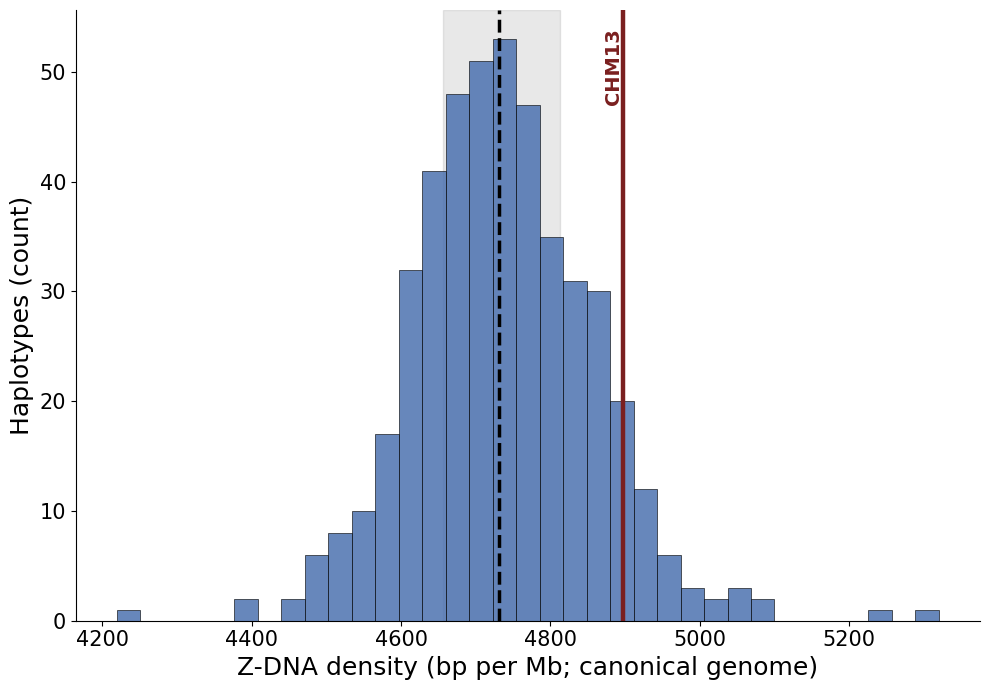

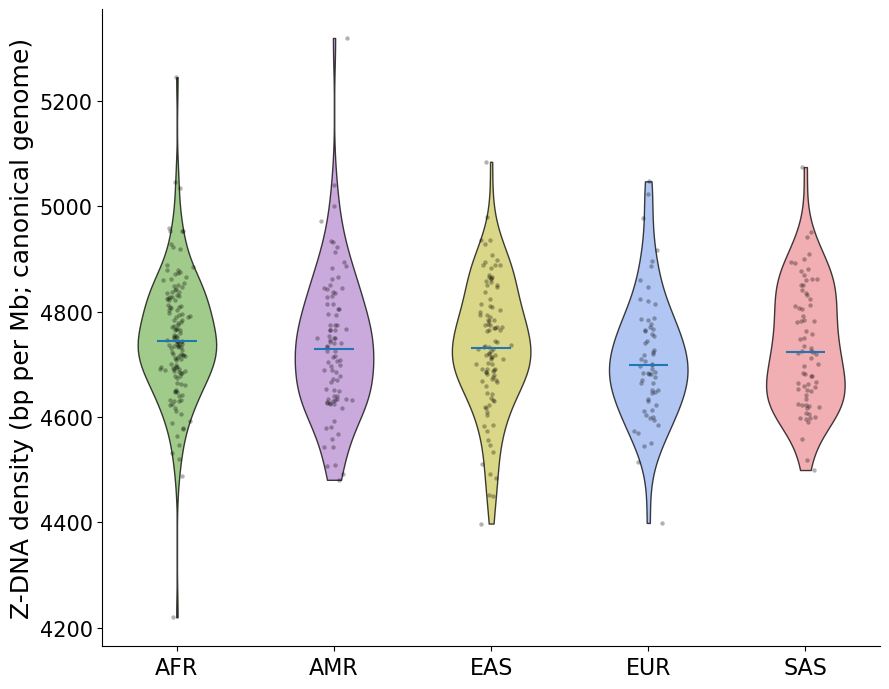

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr

# -----------------------
# Paths
# -----------------------
TABLE_PATH = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_haplotype_tables.final.tsv")
META_PATH  = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")

# -----------------------
# Load + merge metadata
# -----------------------
tbl = pd.read_csv(TABLE_PATH, sep="\t")
meta = pd.read_csv(META_PATH, sep="\t", dtype=str).fillna("")

keep = meta[["filename", "sample_id", "superpopulation"]].copy()
df = tbl.merge(keep, on="filename", how="left", validate="one_to_one")

# Ensure numeric
df["zdna_bp_per_mb_canonical"] = pd.to_numeric(df["zdna_bp_per_mb_canonical"], errors="coerce")
df["genome_bp_canonical_effective"] = pd.to_numeric(df["genome_bp_canonical_effective"], errors="coerce")
df["zdna_bp_canonical"] = pd.to_numeric(df["zdna_bp_canonical"], errors="coerce")

df = df.dropna(subset=["zdna_bp_per_mb_canonical", "genome_bp_canonical_effective", "zdna_bp_canonical"])

# -----------------------
# Reference (CHM13) marker
# -----------------------
CHM13_REF_DENSITY = 4897.0

# -----------------------
# Colors for superpops
# -----------------------
superpop_colors = {
    "AFR": "#81BA65",
    "AMR": "#B98ED1",
    "EAS": "#CFCA61",
    "EUR": "#97B3F0",
    "SAS": "#ED959A",
}

# ============================================================
# FIGURE 1A — Distribution of Z-DNA bp/Mb across haplotypes
# ============================================================
vals = df["zdna_bp_per_mb_canonical"].values
median = np.median(vals)
q1, q3 = np.percentile(vals, [25, 75])

plt.figure(figsize=(10, 7))

# Histogram
plt.hist(
    vals,
    bins=35,
    edgecolor="black",
    linewidth=0.5,
    color="#4C72B0",
    alpha=0.85,
    zorder=1
)

# IQR band + median
plt.axvspan(q1, q3, alpha=0.18, color="gray", zorder=0)
plt.axvline(median, linestyle="--", linewidth=2.5, color="black", zorder=3)

# CHM13 marker (front layer, dark red/brown)
plt.axvline(CHM13_REF_DENSITY, linestyle="-", linewidth=3.2, color="#7A1F1F", zorder=5)
plt.text(
    CHM13_REF_DENSITY,
    plt.gca().get_ylim()[1] * 0.97,
    "CHM13",
    rotation=90,
    va="top",
    ha="right",
    fontsize=14,
    fontweight="bold",
    color="#7A1F1F",
    zorder=6
)

plt.xlabel("Z-DNA density (bp per Mb; canonical genome)", fontsize=18)
plt.ylabel("Haplotypes (count)", fontsize=18)
plt.tick_params(axis="both", labelsize=15)
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/fig1A_density_distribution.png", dpi=600)
plt.show()

# ============================================================
# FIGURE 1B — Superpopulation distributions
# ============================================================
df_sp = df[df["superpopulation"].isin(superpop_colors.keys())].copy()

sp_order = ["AFR", "AMR", "EAS", "EUR", "SAS"]
data = [df_sp.loc[df_sp["superpopulation"] == sp, "zdna_bp_per_mb_canonical"].values for sp in sp_order]

plt.figure(figsize=(9, 7))

vp = plt.violinplot(data, showmedians=True, showextrema=False)

# Color each violin body using your palette
for body, sp in zip(vp["bodies"], sp_order):
    body.set_facecolor(superpop_colors[sp])
    body.set_edgecolor("black")
    body.set_alpha(0.75)

# Jitter points: all black (as requested)
rng = np.random.default_rng(1)
for i, sp in enumerate(sp_order, start=1):
    y = df_sp.loc[df_sp["superpopulation"] == sp, "zdna_bp_per_mb_canonical"].values
    x = i + rng.normal(0, 0.04, size=len(y))
    plt.scatter(x, y, s=10, alpha=0.30, color="black", linewidth=0)

plt.xticks(range(1, len(sp_order)+1), sp_order, fontsize=16)
plt.ylabel("Z-DNA density (bp per Mb; canonical genome)", fontsize=18)
plt.tick_params(axis="y", labelsize=15)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/fig1C_superpopulation_variation.png", dpi=600)
plt.show()

### All contigs

Z-DNA density across all haplotypes (bp/Mb): mean = 4838.66, SD = 55.36, N = 464


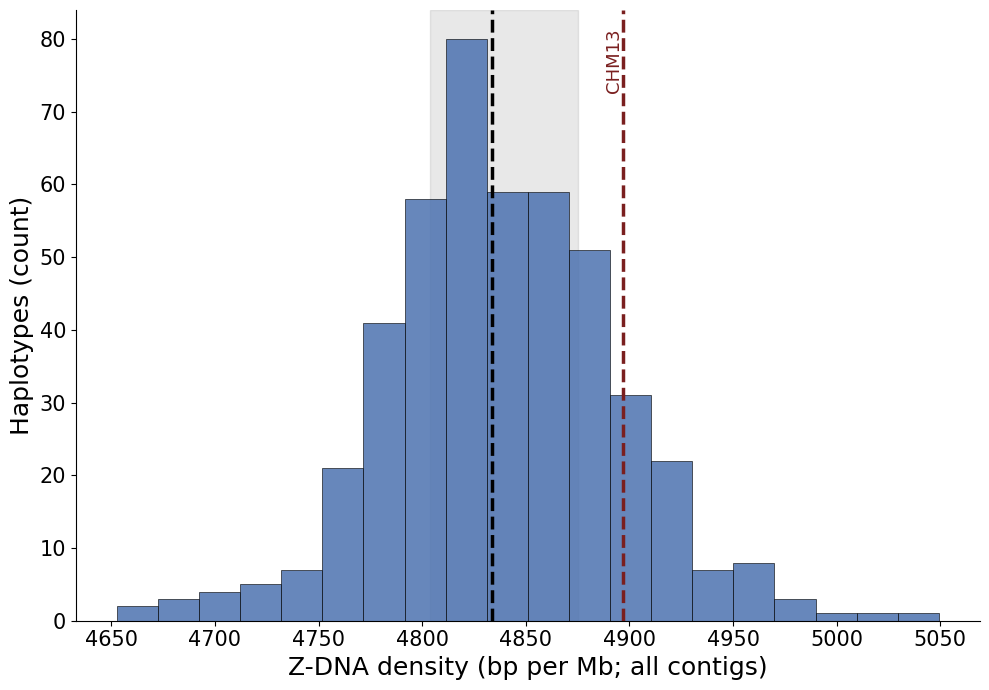

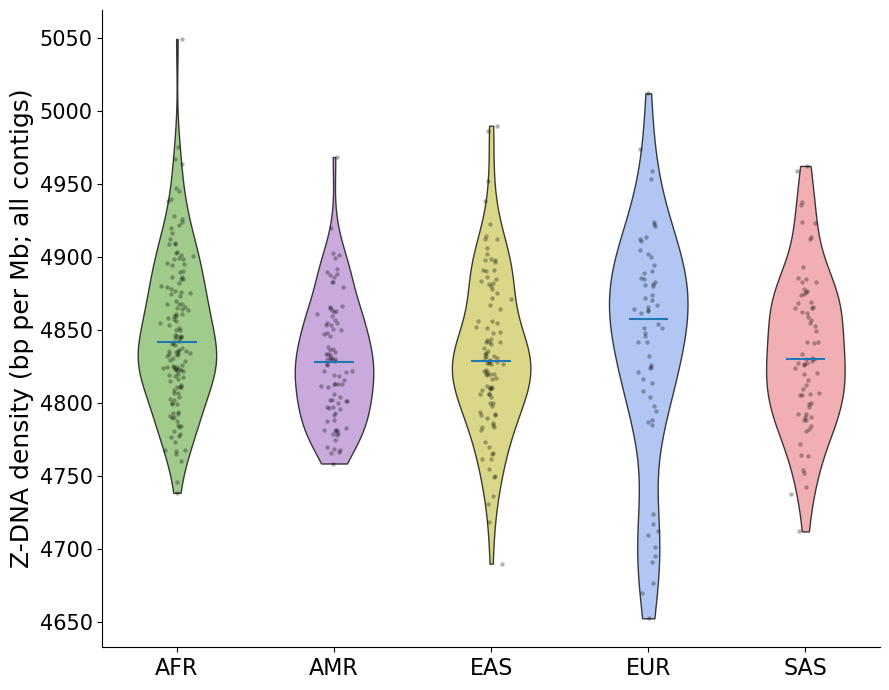

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
CHM13_REF_DENSITY = 4897.0
TABLE_PATH = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_haplotype_tables.final.tsv")
META_PATH  = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
tbl = pd.read_csv(TABLE_PATH, sep="\t")
meta = pd.read_csv(META_PATH, sep="\t", dtype=str).fillna("")

keep = meta[["filename", "sample_id", "superpopulation"]].copy()
df = tbl.merge(keep, on="filename", how="left", validate="one_to_one")
cols = [
    "zdna_bp_canonical",
    "zdna_bp_noncanonical",
    "zdna_bp_unmapped",
    "genome_bp_canonical_effective",
    "genome_bp_noncanonical_effective",
    "genome_bp_unmapped_effective",
]
for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["zdna_bp_all"] = (
    df["zdna_bp_canonical"]
  + df["zdna_bp_noncanonical"]
  + df["zdna_bp_unmapped"]
)

df["genome_bp_all_effective"] = (
    df["genome_bp_canonical_effective"]
  + df["genome_bp_noncanonical_effective"]
  + df["genome_bp_unmapped_effective"]
)

df["zdna_bp_per_mb_all"] = (
    df["zdna_bp_all"] / (df["genome_bp_all_effective"] / 1e6)
)

df = df.dropna(subset=["zdna_bp_per_mb_all"])

# -----------------------
# Colors for superpops
# -----------------------
superpop_colors = {
    "AFR": "#81BA65",
    "AMR": "#B98ED1",
    "EAS": "#CFCA61",
    "EUR": "#97B3F0",
    "SAS": "#ED959A",
}

# ============================================================
# FIGURE — Distribution of Z-DNA bp/Mb across haplotypes (ALL)
# ============================================================
vals = df["zdna_bp_per_mb_all"].values
mean_density = np.mean(vals)
std_density  = np.std(vals, ddof=1)  # sample SD, not population

print(
    f"Z-DNA density across all haplotypes (bp/Mb): "
    f"mean = {mean_density:.2f}, SD = {std_density:.2f}, "
    f"N = {len(vals)}"
)

median = np.median(vals)
q1, q3 = np.percentile(vals, [25, 75])

plt.figure(figsize=(10, 7))

plt.hist(
    vals,
    bins=20,
    edgecolor="black",
    linewidth=0.5,
    color="#4C72B0",
    alpha=0.85,
    zorder=1
)
plt.axvline(
    CHM13_REF_DENSITY,
    linestyle="--",
    linewidth=2.5,
    color="#7A1F1F",
    zorder=5
)
plt.text(
    CHM13_REF_DENSITY,
    plt.gca().get_ylim()[1] * 0.97,
    "CHM13",
    rotation=90,
    va="top",
    ha="right",
    fontsize=13,
    color="#7A1F1F",
    zorder=6
)

plt.axvspan(q1, q3, alpha=0.18, color="gray", zorder=0)
plt.axvline(median, linestyle="--", linewidth=2.5, color="black", zorder=3)

plt.xlabel("Z-DNA density (bp per Mb; all contigs)", fontsize=18)
plt.ylabel("Haplotypes (count)", fontsize=18)
plt.tick_params(axis="both", labelsize=15)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/fig_allcontigs_density_distribution.png",
    dpi=600
)
plt.show()

# ============================================================
# FIGURE — Superpopulation distributions (ALL)
# ============================================================
df_sp = df[df["superpopulation"].isin(superpop_colors.keys())].copy()

sp_order = ["AFR", "AMR", "EAS", "EUR", "SAS"]
data = [
    df_sp.loc[df_sp["superpopulation"] == sp, "zdna_bp_per_mb_all"].values
    for sp in sp_order
]

plt.figure(figsize=(9, 7))

vp = plt.violinplot(data, showmedians=True, showextrema=False)

for body, sp in zip(vp["bodies"], sp_order):
    body.set_facecolor(superpop_colors[sp])
    body.set_edgecolor("black")
    body.set_alpha(0.75)

rng = np.random.default_rng(1)
for i, sp in enumerate(sp_order, start=1):
    y = df_sp.loc[df_sp["superpopulation"] == sp, "zdna_bp_per_mb_all"].values
    x = i + rng.normal(0, 0.04, size=len(y))
    plt.scatter(x, y, s=10, alpha=0.30, color="black", linewidth=0)

plt.xticks(range(1, len(sp_order) + 1), sp_order, fontsize=16)
plt.ylabel("Z-DNA density (bp per Mb; all contigs)", fontsize=18)
plt.tick_params(axis="y", labelsize=15)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/fig_allcontigs_superpopulation_variation.png",
    dpi=600
)
plt.show()


## HPRC Chromosome sizes

### Scripts

In [ ]:
# # build_hprc_chromosome_table.py
# import gzip
# import re
# import sys
# from pathlib import Path
# import numpy as np
# import pandas as pd

# if len(sys.argv) != 2:
#     raise SystemExit("Usage: build_hprc_chromosome_table.py <zseeker_csv_filename>")

# TARGET_CSV = sys.argv[1]
# META_PATH  = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
# ZDNA_DIR   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
# FASTA_DIR  = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/assemblies")
# ALIAS_DIR  = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/chrom_aliases")

# OUTDIR     = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/haplotype_chromosome_tables")
# OUT_CHUNKS = OUTDIR / "chromosome_chunks"
# OUT_CHUNKS.mkdir(parents=True, exist_ok=True)

# CANONICAL_CHROMS = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
# CANONICAL_SET = set(CANONICAL_CHROMS)
# N_RUN_RE = re.compile(r"[Nn]{10,}")

# def fasta_from_zseeker(filename: str) -> str:
#     return filename.replace(".zseeker.csv", ".fa.gz")

# def infer_alias_key(name: str) -> str:
#     n = name.lower()
#     if "_pat" in n or "#1#" in n or "_hap1" in n:
#         return "pat"
#     if "_mat" in n or "#2#" in n or "_hap2" in n:
#         return "mat"
#     return ""

# def find_alias_file(stem: str, prefix: str, key: str):
#     # Prefer exact stem match
#     exact = list(ALIAS_DIR.glob(f"{stem}.chromAlias.txt"))
#     if exact:
#         return exact[0]
#     # Next: include hap key if available
#     if key:
#         cand = list(ALIAS_DIR.glob(f"{prefix}*{key}*.chromAlias.txt"))
#         if cand:
#             return cand[0]
#     # Fallback: any alias for this sample prefix
#     cand = list(ALIAS_DIR.glob(f"{prefix}*.chromAlias.txt"))
#     return cand[0] if cand else None

# def load_alias_map(alias_file: Path) -> dict:
#     # alias file columns: assembly  ucsc  genbank
#     lines = [l.strip() for l in open(alias_file) if l.strip() and not l.startswith("#")]
#     parts = [l.split() for l in lines]
#     df = pd.DataFrame(parts, columns=["assembly", "ucsc", "genbank"]).apply(lambda x: x.str.strip())
#     return dict(zip(df["assembly"], df["ucsc"]))

# def effective_bp(seq: str) -> int:
#     # subtract N-runs >=10bp, consistent with your prior work
#     total_len = len(seq)
#     n_masked = sum(m.end() - m.start() for m in N_RUN_RE.finditer(seq))
#     return total_len - n_masked

# def genome_bp_effective_by_chr(fasta_gz: Path, alias_map: dict) -> dict:
#     bp = {c: 0 for c in CANONICAL_CHROMS}

#     contig = None
#     seq_chunks = []

#     def flush(cname, seq):
#         if cname is None or not seq:
#             return
#         ucsc = alias_map.get(cname)
#         if ucsc in CANONICAL_SET:
#             bp[ucsc] += effective_bp(seq)

#     with gzip.open(fasta_gz, "rt") as fh:
#         for line in fh:
#             if line.startswith(">"):
#                 flush(contig, "".join(seq_chunks))
#                 contig = line[1:].strip().split()[0]
#                 seq_chunks = []
#             else:
#                 seq_chunks.append(line.strip())
#         flush(contig, "".join(seq_chunks))

#     return bp

# def zdna_bp_by_chr_from_zseeker(csv_path: Path, alias_map: dict):
#     zdna_bp_chr = {c: 0 for c in CANONICAL_CHROMS}
#     n_intervals_chr = {c: 0 for c in CANONICAL_CHROMS}
#     n_unmapped_total = 0

#     # Read minimal columns only
#     df = pd.read_csv(csv_path, usecols=["Chromosome", "Start", "End"], dtype=str)

#     df = df.dropna(subset=["Chromosome", "Start", "End"])
#     df["Start"] = pd.to_numeric(df["Start"], errors="coerce")
#     df["End"] = pd.to_numeric(df["End"], errors="coerce")
#     df = df.dropna(subset=["Start", "End"])
#     # integer interval length
#     lens = (df["End"].astype(np.int64) - df["Start"].astype(np.int64) + 1).astype(np.int64)

#     contigs = df["Chromosome"].astype(str).str.strip().tolist()

#     for contig, L in zip(contigs, lens.tolist()):
#         ucsc = alias_map.get(contig)
#         if ucsc is None:
#             n_unmapped_total += 1
#             continue
#         if ucsc in CANONICAL_SET:
#             zdna_bp_chr[ucsc] += int(L)
#             n_intervals_chr[ucsc] += 1
#         # else: ignore non-autosomal/noncanonical for Figure 1 continuation

#     return zdna_bp_chr, n_intervals_chr, n_unmapped_total

# # -----------------------------
# # Main
# # -----------------------------
# # Validate filename exists in metadata (keeps the same hap list logic consistent)
# meta = pd.read_csv(META_PATH, sep="\t", dtype=str).fillna("")
# if "filename" not in meta.columns:
#     raise SystemExit("❌ META missing column: filename")

# row = meta.loc[meta["filename"] == TARGET_CSV]
# if row.empty:
#     raise SystemExit(f"❌ filename not found in metadata: {TARGET_CSV}")

# fname = TARGET_CSV
# zpath = ZDNA_DIR / fname
# if not zpath.exists():
#     raise SystemExit(f"❌ ZSeeker CSV not found: {zpath}")

# fasta = FASTA_DIR / fasta_from_zseeker(fname)
# if not fasta.exists():
#     raise SystemExit(f"❌ FASTA not found: {fasta}")

# stem = fasta.name.replace(".fa.gz", "")
# prefix = fasta.name.split("_")[0]
# key = infer_alias_key(fasta.name)

# alias_file = find_alias_file(stem, prefix, key)
# if alias_file is None:
#     raise SystemExit(f"❌ Alias file not found for {fname}")

# alias_map = load_alias_map(alias_file)

# # Compute denominators (effective chromosome lengths)
# chr_bp_eff = genome_bp_effective_by_chr(fasta, alias_map)

# # Compute numerators (Z-DNA bp per chromosome)
# zdna_bp_chr, n_intervals_chr, n_unmapped_total = zdna_bp_by_chr_from_zseeker(zpath, alias_map)

# # Build output rows (exact schema)
# rows = []
# for chrom in CANONICAL_CHROMS:
#     denom = chr_bp_eff.get(chrom, 0)
#     numer = zdna_bp_chr.get(chrom, 0)

#     per_mb = float("nan")
#     if denom and denom > 0:
#         per_mb = numer / (denom / 1e6)

#     rows.append({
#         "filename": fname,
#         "chromosome": chrom,
#         "zdna_bp_canonical_chr": int(numer),
#         "genome_bp_canonical_effective_chr": int(denom),
#         "zdna_bp_per_mb_chr": per_mb,
#         "n_intervals_chr": int(n_intervals_chr.get(chrom, 0)),
#         "n_intervals_unmapped_chr": int(n_unmapped_total),  # global unmapped count, replicated for QC simplicity
#         "alias_file": alias_file.name,  # optional provenance; remove later if you want
#         "fasta_file": fasta.name,       # optional provenance; remove later if you want
#     })

# out_file = OUT_CHUNKS / f"{fname}.tsv"
# pd.DataFrame(rows).to_csv(out_file, sep="\t", index=False)
# print(f"✅ Wrote {out_file}")




# run_haplotype_chromosome_tables.slurm
# #!/bin/bash
# #SBATCH -J hprc_chr_tables
# #SBATCH -p gg
# #SBATCH -N 1
# #SBATCH --ntasks=1
# #SBATCH --cpus-per-task=16
# #SBATCH -t 24:00:00
# #SBATCH -o logs/hprc_chr_tables_%j.out
# #SBATCH -e logs/hprc_chr_tables_%j.err

# set -euo pipefail

# cd /work/10906/geomeg/vista/pangenomes_zdna

# mkdir -p logs
# mkdir -p tmp/haplotype_chromosome_tables/chromosome_chunks

# source /work/10906/geomeg/vista/miniconda3/etc/profile.d/conda.sh
# conda activate py_env

# # Build the haplotype list exactly the same way (H/N samples)
# python - << 'EOF'
# import pandas as pd
# df = pd.read_csv("hprc_zdna_metrics.tsv", sep="\t", dtype=str).fillna("")
# mask = df["sample_id"].str.startswith(("H","N"))
# df.loc[mask, "filename"].to_csv("tmp/hap_list.txt", index=False, header=False)
# print("Wrote tmp/hap_list.txt")
# EOF

# # Run per file in parallel (16 workers)
# xargs -n 1 -P 16 --no-run-if-empty python -u build_hprc_chromosome_table.py < tmp/hap_list.txt

# # Merge chunks -> final table
# python - << 'EOF'
# import pandas as pd
# from pathlib import Path

# chunk_dir = Path("tmp/haplotype_chromosome_tables/chromosome_chunks")
# out_path  = Path("haplotype_chromosome_zdna.tsv")

# files = sorted(chunk_dir.glob("*.tsv"))
# if not files:
#     raise SystemExit("No chunk TSVs found.")

# dfs = [pd.read_csv(f, sep="\t") for f in files]
# df = pd.concat(dfs, ignore_index=True)
# df = df[df["genome_bp_canonical_effective_chr"] > 0].copy()

# # Minimal ordering
# cols = ["filename","chromosome","zdna_bp_canonical_chr","genome_bp_canonical_effective_chr","zdna_bp_per_mb_chr",
#         "n_intervals_chr","n_intervals_unmapped_chr","alias_file","fasta_file"]
# cols = [c for c in cols if c in df.columns]
# df = df[cols]

# df.to_csv(out_path, sep="\t", index=False)
# print(f"Wrote {out_path} with {len(df)} rows and {df['filename'].nunique()} haplotypes.")
# EOF





# #!/bin/bash
# set -euo pipefail

# cd /work/10906/geomeg/vista/pangenomes_zdna

# source /work/10906/geomeg/vista/miniconda3/etc/profile.d/conda.sh
# conda activate py_env

# OUT_CHUNKS="tmp/haplotype_chromosome_tables/chromosome_chunks"
# mkdir -p "${OUT_CHUNKS}"





# python - << 'EOF'
# import gzip
# import re
# from pathlib import Path
# import pandas as pd
# import numpy as np

# CANONICAL_CHROMS = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
# CANONICAL_SET = set(CANONICAL_CHROMS)
# N_RUN_RE = re.compile(r"[Nn]{10,}")

# ZDNA_DIR   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
# FASTA_DIR  = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/assemblies")
# OUT_CHUNKS = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/haplotype_chromosome_tables/chromosome_chunks")

# HG002 = {
#     "HG002_v1.1.mat_MT.PanSN.zseeker.csv": "hg002v1.1.mat_MT.PanSN.fa.gz",
#     "HG002_v1.1.pat.PanSN.zseeker.csv": "hg002v1.1.pat.PanSN.fa.gz",
# }

# def effective_bp(seq: str) -> int:
#     total = len(seq)
#     n_masked = sum(m.end() - m.start() for m in N_RUN_RE.finditer(seq))
#     return total - n_masked

# def contig_to_canonical_chr(name):
#     if not name:
#         return None
#     chrom = name.split("#")[-1].strip()
#     return chrom if chrom in CANONICAL_SET else None


# def genome_bp_effective_by_chr(fasta_gz: Path) -> dict:
#     bp = {c: 0 for c in CANONICAL_CHROMS}
#     contig = None
#     seq_chunks = []

#     def flush(name, seq):
#         if name is None or not seq:
#             return
#         chrom = contig_to_canonical_chr(name)
#         if chrom is not None:
#             bp[chrom] += effective_bp(seq)

#     with gzip.open(fasta_gz, "rt") as fh:
#         for line in fh:
#             if line.startswith(">"):
#                 flush(contig, "".join(seq_chunks))
#                 contig = line[1:].strip().split()[0]   # keep full token, e.g. HG002#2#chr1
#                 seq_chunks = []
#             else:
#                 seq_chunks.append(line.strip())
#         flush(contig, "".join(seq_chunks))

#     return bp

# def zdna_bp_by_chr(csv_path: Path):
#     zdna_bp = {c: 0 for c in CANONICAL_CHROMS}
#     n_intervals = {c: 0 for c in CANONICAL_CHROMS}
#     n_unmapped = 0

#     df = pd.read_csv(csv_path, usecols=["Chromosome", "Start", "End"], dtype=str)
#     df = df.dropna(subset=["Chromosome", "Start", "End"])
#     df["Start"] = pd.to_numeric(df["Start"], errors="coerce")
#     df["End"]   = pd.to_numeric(df["End"], errors="coerce")
#     df = df.dropna(subset=["Start", "End"])

#     lens = (df["End"].astype(np.int64) - df["Start"].astype(np.int64) + 1).astype(np.int64)

#     # Chromosome strings look like HG002#2#chr1 -> extract chr1
#     chroms = df["Chromosome"].astype(str).map(lambda x: x.split("#")[-1].strip())

#     for c, L in zip(chroms.tolist(), lens.tolist()):
#         if c in CANONICAL_SET:
#             zdna_bp[c] += int(L)
#             n_intervals[c] += 1
#         else:
#             n_unmapped += 1

#     return zdna_bp, n_intervals, n_unmapped

# # --------------------------------------------------
# # Run HG002
# # --------------------------------------------------
# for csv_name, fasta_name in HG002.items():
#     print(f"Processing {csv_name}")

#     zpath = ZDNA_DIR / csv_name
#     fpath = FASTA_DIR / fasta_name

#     if not zpath.exists():
#         raise SystemExit(f"Missing ZSeeker CSV: {zpath}")
#     if not fpath.exists():
#         raise SystemExit(f"Missing FASTA: {fpath}")

#     chr_bp_eff = genome_bp_effective_by_chr(fpath)
#     zdna_bp, n_intervals, n_unmapped = zdna_bp_by_chr(zpath)

#     # HARD QC: if these are all zero, you are still parsing headers wrong
#     if sum(chr_bp_eff.values()) == 0:
#         raise SystemExit(f"❌ HG002 denominator all zero for {fasta_name}. FASTA headers not parsed as expected.")

#     rows = []
#     for chrom in CANONICAL_CHROMS:
#         denom = int(chr_bp_eff.get(chrom, 0))
#         numer = int(zdna_bp.get(chrom, 0))

#         per_mb = float("nan")
#         if denom > 0:
#             per_mb = numer / (denom / 1e6)

#         rows.append({
#             "filename": csv_name,
#             "chromosome": chrom,
#             "zdna_bp_canonical_chr": numer,
#             "genome_bp_canonical_effective_chr": denom,
#             "zdna_bp_per_mb_chr": per_mb,
#             "n_intervals_chr": int(n_intervals.get(chrom, 0)),
#             "n_intervals_unmapped_chr": int(n_unmapped),
#             "alias_file": "INFERRED_FROM_HEADER",
#             "fasta_file": fasta_name,
#         })

#     out = OUT_CHUNKS / f"{csv_name}.tsv"
#     pd.DataFrame(rows).to_csv(out, sep="\t", index=False)
#     print(f"✅ Wrote {out}")

# print("HG002 processing complete.")
# EOF

### Concat

In [9]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# Paths
# --------------------------------------------------
chunk_dir = Path(
    "/work/10906/geomeg/vista/pangenomes_zdna/tmp/haplotype_chromosome_tables/chromosome_chunks"
)

out_path = Path(
    "/work/10906/geomeg/vista/pangenomes_zdna/haplotype_chromosome_zdna.tsv"
)

# --------------------------------------------------
# Collect all per-haplotype chromosome tables
# --------------------------------------------------
files = sorted(chunk_dir.glob("*.tsv"))
if not files:
    raise SystemExit("No chromosome chunk TSVs found.")

dfs = [pd.read_csv(f, sep="\t") for f in files]
df = pd.concat(dfs, ignore_index=True)

# --------------------------------------------------
# Canonical inclusion rule (CRITICAL)
# --------------------------------------------------
# A chromosome is included for a haplotype
# if and only if it has >0 effective bp.
df = df[df["genome_bp_canonical_effective_chr"] > 0].copy()

# --------------------------------------------------
# Column order
# --------------------------------------------------
cols = [
    "filename",
    "chromosome",
    "zdna_bp_canonical_chr",
    "genome_bp_canonical_effective_chr",
    "zdna_bp_per_mb_chr",
    "n_intervals_chr",
    "n_intervals_unmapped_chr",
    "alias_file",
    "fasta_file",
]
df = df[cols]

# --------------------------------------------------
# Write final table
# --------------------------------------------------
df.to_csv(out_path, sep="\t", index=False)

print(
    f"Wrote {out_path}\n"
    f"Rows: {len(df)}\n"
    f"Haplotypes: {df['filename'].nunique()}\n"
    f"Chromosomes present: {sorted(df['chromosome'].unique())}"
)

Wrote /work/10906/geomeg/vista/pangenomes_zdna/haplotype_chromosome_zdna.tsv
Rows: 6201
Haplotypes: 464
Chromosomes present: ['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX', 'chrY']


### Z-DNA Density per chr.

/tmp/ipykernel_2061297/2534738241.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("chromosome")["filename"]


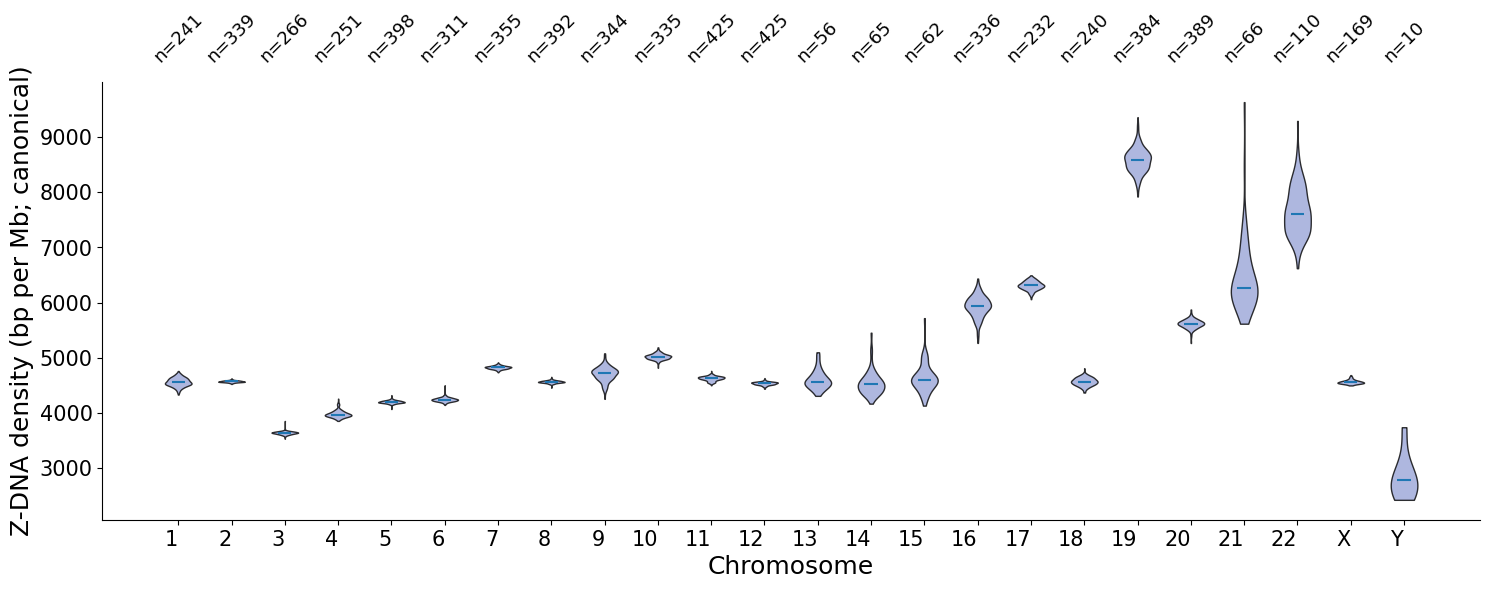

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ============================================================
# Load and filter data (shared setup)
# ============================================================
df = pd.read_csv(
    "/work/10906/geomeg/vista/pangenomes_zdna/haplotype_chromosome_zdna.tsv",
    sep="\t"
)

# Exclude chromosomes absent in the assembly (non-negotiable)
df = df[df["genome_bp_canonical_effective_chr"] > 0].copy()

chrom_order = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
chrom_labels = [str(i) for i in range(1, 23)] + ["X", "Y"]


# ============================================================
# FIGURE 1C — Chromosome-level Z-DNA density
# ============================================================
df["chromosome"] = pd.Categorical(
    df["chromosome"], categories=chrom_order, ordered=True
)

data = [
    df.loc[df["chromosome"] == chrom, "zdna_bp_per_mb_chr"].values
    for chrom in chrom_order
]
n_per_chr = (
    df.groupby("chromosome")["filename"]
      .nunique()
      .reindex(chrom_order, fill_value=0)
)
plt.figure(figsize=(15, 6))

vp = plt.violinplot(
    data,
    showmedians=True,
    showextrema=False
)

for body in vp["bodies"]:
    body.set_facecolor("#9AA5D8")
    body.set_edgecolor("black")
    body.set_alpha(0.80)

plt.xticks(
    range(1, len(chrom_order) + 1),
    chrom_labels,
    rotation=0,
    ha="right",
    fontsize=15
)

plt.ylabel("Z-DNA density (bp per Mb; canonical)", fontsize=18)
plt.xlabel("Chromosome", fontsize=18)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", labelsize=15)
# ------------------------------------------------------------
# Annotate n above each violin
# ------------------------------------------------------------
ymax = plt.gca().get_ylim()[1]
y_offset = 0.03 * ymax   # small vertical offset

for i, chrom in enumerate(chrom_order, start=1):
    n = n_per_chr.loc[chrom]
    if n > 0:
        plt.text(
            i,
            ymax + y_offset,
            f"n={n}",
            ha="center",
            va="bottom",
            fontsize=13,
            rotation=45
        )

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/fig1D_chromosome_density.png",
    dpi=600
)
plt.show()

### %GC per chromosome CHM13

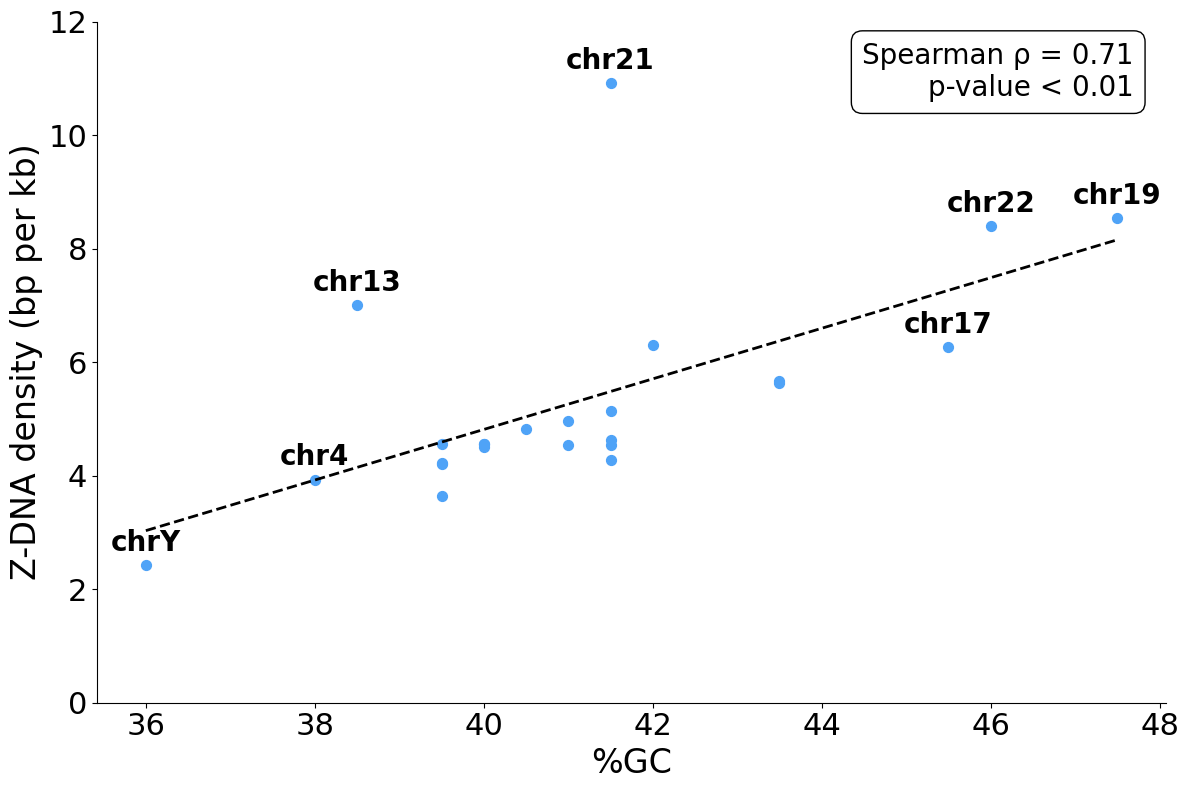

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr
import statsmodels.api as sm

# Load file
path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
df = pd.read_csv(path, sep="\t")

# Keep only needed
df = df[["ucsc_pansn_name", "gc_percent", "gcf_zdna_density_per_kb"]].copy()

# Chromosome order
chrom_order = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
df["ucsc_pansn_name"] = pd.Categorical(df["ucsc_pansn_name"], categories=chrom_order, ordered=True)
df = df.sort_values("ucsc_pansn_name")

# Spearman correlation
rho, pval = spearmanr(df["gc_percent"], df["gcf_zdna_density_per_kb"])
p_text = "p-value < 0.01" if pval < 0.01 else f"p-value = {pval:.2e}"

# Regression
X = sm.add_constant(df["gc_percent"])
model = sm.OLS(df["gcf_zdna_density_per_kb"], X).fit()
df["reg_pred"] = model.predict(X)

# Identify chromosomes to annotate
lowest_gc = df.nsmallest(3, "gc_percent")["ucsc_pansn_name"].tolist()
highest_gc = df.nlargest(3, "gc_percent")["ucsc_pansn_name"].tolist()
extra = ["chr13", "chr21"]

annotate_set = set(lowest_gc + highest_gc + extra)

# Plot
plt.figure(figsize=(12, 8))

# lighter blue
plt.scatter(df["gc_percent"],
            df["gcf_zdna_density_per_kb"],
            color="#4FA3F7",
            s=50)  # smaller dots

# Regression line (smooth)
x_smooth = np.linspace(df["gc_percent"].min(),
                       df["gc_percent"].max(), 300)

X_smooth = sm.add_constant(x_smooth)   # <-- FIX
y_smooth = model.predict(X_smooth)

plt.plot(x_smooth, y_smooth, '--', color='black', linewidth=2)

# Annotate selected chromosomes
for _, row in df.iterrows():
    if row["ucsc_pansn_name"] in annotate_set:
        plt.text(
            row["gc_percent"],
            row["gcf_zdna_density_per_kb"] + 0.25,
            row["ucsc_pansn_name"],
            ha="center",
            fontsize=20,        # larger text
            fontweight="bold"
        )

# Labels and limits
plt.tick_params(axis='both', which='major', labelsize=22)
plt.xlabel("%GC", fontsize=24)
plt.ylabel("Z-DNA density (bp per kb)", fontsize=24)
plt.ylim(0, 12)

# Correlation panel
text = f"Spearman ρ = {rho:.2f}\n{p_text}"
plt.text(
    0.97, 0.97, text,
    transform=plt.gca().transAxes,
    fontsize=20,
    ha="right", va="top",
    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.4")
)

# Despine
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/gc_density_per_chr", dpi=600)
plt.show()

In [ ]:
# Z-DNA density shows a weak negative correlation with chromosome length in the raw CHM13 data; 
# however, this association is fully explained by GC content. 
# After controlling for GC, chromosome length is no longer correlated with Z-DNA density 
# (Spearman ρ = −0.29, p = 0.17), indicating that chromosome-scale variation in Z-DNA enrichment is not driven by genome size effects.

### Paternal-maternal differences

Trio-phased individuals retained: 128
n_individuals: 128
median_abs_delta: 32.42570065662812
mean_abs_delta: 43.02023111660174
fraction_gt_10pct: 0.0
fraction_gt_15pct: 0.0


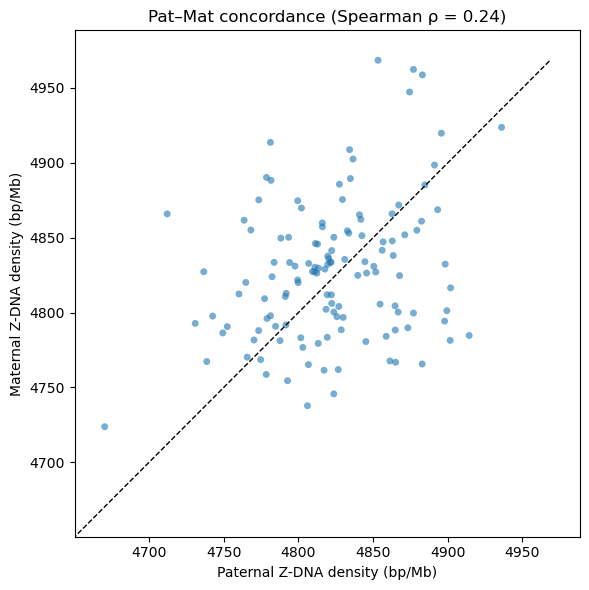

Variance decomposition:
Within-individual variance:  2988.838
Between-individual variance: 1363.682
Ratio (within / between):   2.192


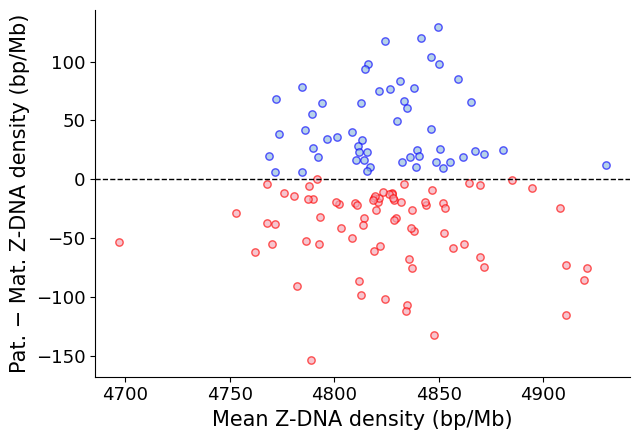

In [13]:
import pandas as pd
import numpy as np

HAP_TABLE = "/work/10906/geomeg/vista/pangenomes_zdna/hprc_haplotype_tables.final.tsv"
META      = "/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv"

hap = pd.read_csv(HAP_TABLE, sep="\t")
meta = pd.read_csv(META, sep="\t", dtype=str)

# Keep only what we need
meta = meta[["filename", "sample_id", "pat_or_mat"]].copy()

df = hap.merge(
    meta,
    on="filename",
    how="inner",
    validate="one_to_one"
)
# --------------------------------------------------
# Ensure numeric (critical)
# --------------------------------------------------
cols = [
    "zdna_bp_canonical",
    "zdna_bp_noncanonical",
    "zdna_bp_unmapped",
    "genome_bp_canonical_effective",
    "genome_bp_noncanonical_effective",
    "genome_bp_unmapped_effective",
]
for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# --------------------------------------------------
# Compute ALL-contig Z-DNA density (bp/Mb)
# --------------------------------------------------
df["zdna_bp_all"] = (
      df["zdna_bp_canonical"]
    + df["zdna_bp_noncanonical"]
    + df["zdna_bp_unmapped"]
)

df["genome_bp_all_effective"] = (
      df["genome_bp_canonical_effective"]
    + df["genome_bp_noncanonical_effective"]
    + df["genome_bp_unmapped_effective"]
)

df["zdna_bp_per_mb_all"] = (
    df["zdna_bp_all"] / (df["genome_bp_all_effective"] / 1e6)
)

# Drop pathological rows (non-negotiable)
df = df.dropna(subset=["zdna_bp_per_mb_all"])
df = df[df["genome_bp_all_effective"] > 0].copy()

df = df[df["pat_or_mat"].isin({"pat", "mat"})].copy()

# Hard sanity checks (now meaningful)
assert df["pat_or_mat"].isin({"pat", "mat"}).all()
assert df["sample_id"].notna().all()

# Count haplotypes per individual
counts = (
    df.groupby(["sample_id", "pat_or_mat"])
      .size()
      .unstack(fill_value=0)
)

# Keep only individuals with exactly one pat and one mat
valid_ids = counts[
    (counts.get("pat", 0) == 1) &
    (counts.get("mat", 0) == 1)
].index

df = df[df["sample_id"].isin(valid_ids)].copy()
# No individual should have >2 trio-phased haplotypes
bad = (
    df.groupby("sample_id")
      .size()
      .loc[lambda x: x != 2]
)

assert bad.empty, f"Unexpected haplotype count per individual:\n{bad}"

print(f"Trio-phased individuals retained: {len(valid_ids)}")
wide = (
    df.pivot(
        index="sample_id",
        columns="pat_or_mat",
        values="zdna_bp_per_mb_all"
    )
    .rename(columns={"pat": "zdna_pat", "mat": "zdna_mat"})
    .dropna()
)

assert len(wide) == len(valid_ids)
wide["delta"] = wide["zdna_pat"] - wide["zdna_mat"]
wide["abs_delta"] = wide["delta"].abs()
wide["mean"] = wide[["zdna_pat", "zdna_mat"]].mean(axis=1)

summary = {
    "n_individuals": len(wide),
    "median_abs_delta": wide["abs_delta"].median(),
    "mean_abs_delta": wide["abs_delta"].mean(),
    "fraction_gt_10pct": np.mean(wide["abs_delta"] / wide["mean"] > 0.10),
    "fraction_gt_15pct": np.mean(wide["abs_delta"] / wide["mean"] > 0.15),
}

for k, v in summary.items():
    print(f"{k}: {v}")
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

rho, pval = spearmanr(wide["zdna_pat"], wide["zdna_mat"])

plt.figure(figsize=(6, 6))
plt.scatter(
    wide["zdna_pat"],
    wide["zdna_mat"],
    s=25,
    alpha=0.6,
    edgecolor="none"
)

lims = [
    min(wide.min()),
    max(wide.max())
]
plt.plot(lims, lims, "--", color="black", linewidth=1)

plt.xlabel("Paternal Z-DNA density (bp/Mb)")
plt.ylabel("Maternal Z-DNA density (bp/Mb)")
plt.title(f"Pat–Mat concordance (Spearman ρ = {rho:.2f})")
lims = [
    min(wide[["zdna_pat","zdna_mat"]].min()) - 20,
    max(wide[["zdna_pat","zdna_mat"]].max()) + 20,
]
plt.xlim(lims)
plt.ylim(lims)

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/fig_pat_mat_concordance.png",
    dpi=600
)
plt.show()
within_var = np.var(wide["delta"], ddof=1)
between_var = np.var(wide["mean"], ddof=1)

print("Variance decomposition:")
print(f"Within-individual variance:  {within_var:.3f}")
print(f"Between-individual variance: {between_var:.3f}")
print(f"Ratio (within / between):   {within_var / between_var:.3f}")




# --------------------------------------------------
# Bland–Altman-style Pat–Mat difference plot
# --------------------------------------------------
plt.figure(figsize=(6.5, 4.5))

# Color by direction of difference
pos = wide["delta"] > 0   # paternal > maternal
neg = ~pos                # maternal > paternal

plt.scatter(
    wide.loc[pos, "mean"],
    wide.loc[pos, "delta"],
    s=28,
    alpha=0.65,
    color="#8FBADD",   # light blue
    edgecolor="blue",
    label="Pat > Mat"
)

plt.scatter(
    wide.loc[neg, "mean"],
    wide.loc[neg, "delta"],
    s=28,
    alpha=0.65,
    color="#F2A7B5",   # light pink
    edgecolor="red",
    label="Mat > Pat"
)

# Zero reference line
plt.axhline(0, color="black", linestyle="--", linewidth=1)

# Labels
plt.xlabel("Mean Z-DNA density (bp/Mb)", fontsize=15)
plt.ylabel("Pat. − Mat. Z-DNA density (bp/Mb)", fontsize=15)

# Tick font sizes
plt.tick_params(axis="both", labelsize=13)

# Despine
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/fig_pat_mat_difference.png",
    dpi=600
)
plt.show()


### Haplotypes GC content

In [5]:
# #!/usr/bin/env python3
# import gzip
# import sys
# from pathlib import Path

# if len(sys.argv) != 2:
#     raise SystemExit("Usage: compute_gc_fasta.py <fasta.fa.gz>")

# fasta = Path(sys.argv[1])

# gc = 0
# total = 0

# with gzip.open(fasta, "rt") as fh:
#     for line in fh:
#         if line.startswith(">"):
#             continue
#         seq = line.strip().upper()
#         if not seq:
#             continue

#         gc += seq.count("G") + seq.count("C")
#         total += len(seq)   # includes Ns automatically

# gc_frac = gc / total if total > 0 else float("nan")

# # stdout is intentional (xargs-safe)
# print(f"{fasta.name}\t{gc_frac:.6f}")




# #!/bin/bash
# #SBATCH -J hprc_gc
# #SBATCH -p gg
# #SBATCH -N 1
# #SBATCH --ntasks=1
# #SBATCH --cpus-per-task=32
# #SBATCH -t 12:00:00
# #SBATCH -o logs/hprc_gc_%j.out
# #SBATCH -e logs/hprc_gc_%j.err

# set -euo pipefail

# cd /work/10906/geomeg/vista/pangenomes_zdna

# mkdir -p logs
# mkdir -p tmp/gc_chunks

# source /work/10906/geomeg/vista/miniconda3/etc/profile.d/conda.sh
# conda activate py_env

# FASTA_DIR="/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/assemblies"

# # Build FASTA list
# ls ${FASTA_DIR}/*.fa.gz > tmp/gc_fasta_list.txt

# # Run GC computation in parallel
# cat tmp/gc_fasta_list.txt \
#   | xargs -n 1 -P 32 --no-run-if-empty \
#     ./compute_gc_fasta.py \
#   > tmp/gc_chunks/gc_results.tsv

# # Add header and move to final location
# OUT="haplotype_gc_content.tsv"
# {
#     echo -e "filename\tgc_fraction"
#     cat tmp/gc_chunks/gc_results.tsv
# } > "${OUT}"

# echo "Wrote ${OUT}"


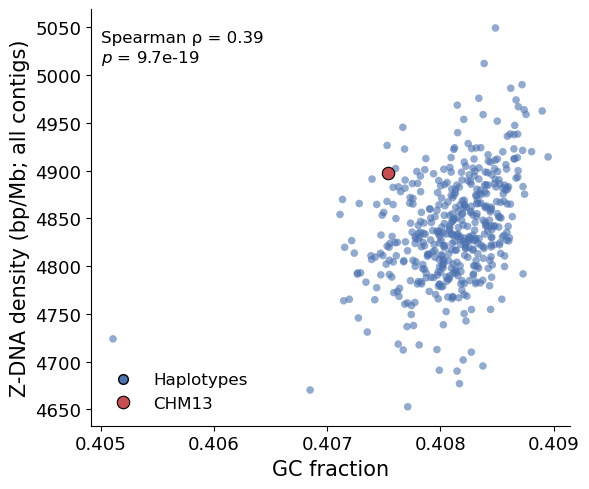

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

GC_TSV = "/work/10906/geomeg/vista/pangenomes_zdna/haplotype_gc_content.tsv"

gc = pd.read_csv(GC_TSV, sep="\t")
CHM13_REF_DENSITY = 4897.0
CHM13_GC_FRACTION = 0.407539

# Drop reference genomes (non-haplotypes)
gc = gc[~gc["filename"].isin([
    "chm13v2.0_maskedY_rCRS.fa.PanSN.fa.gz",
    "GCA_000001405.15_GRCh38_no_alt_analysis_set.PanSN.fa.gz"
])].copy()

assert gc["filename"].nunique() == len(gc)
HAP_TABLE = "/work/10906/geomeg/vista/pangenomes_zdna/hprc_haplotype_tables.final.tsv"

hap = pd.read_csv(HAP_TABLE, sep="\t")

# Ensure numeric
cols = [
    "zdna_bp_canonical",
    "zdna_bp_noncanonical",
    "zdna_bp_unmapped",
    "genome_bp_canonical_effective",
    "genome_bp_noncanonical_effective",
    "genome_bp_unmapped_effective",
]
for c in cols:
    hap[c] = pd.to_numeric(hap[c], errors="coerce")

# All-contig Z-DNA density
hap["zdna_bp_all"] = (
      hap["zdna_bp_canonical"]
    + hap["zdna_bp_noncanonical"]
    + hap["zdna_bp_unmapped"]
)

hap["genome_bp_all_effective"] = (
      hap["genome_bp_canonical_effective"]
    + hap["genome_bp_noncanonical_effective"]
    + hap["genome_bp_unmapped_effective"]
)

hap["zdna_bp_per_mb_all"] = (
    hap["zdna_bp_all"] / (hap["genome_bp_all_effective"] / 1e6)
)

hap = hap.dropna(subset=["zdna_bp_per_mb_all"])
df = hap.merge(
    gc,
    left_on="fasta_file",
    right_on="filename",
    how="inner",
    validate="one_to_one"
)

assert len(df) > 0


rho, pval = spearmanr(df["gc_fraction"], df["zdna_bp_per_mb_all"])

plt.figure(figsize=(6, 5))

# Haplotype points
plt.scatter(
    df["gc_fraction"],
    df["zdna_bp_per_mb_all"],
    s=30,
    alpha=0.6,
    color="#4C72B0",
    edgecolor="none"
)

# CHM13 reference point
plt.scatter(
    CHM13_GC_FRACTION,
    CHM13_REF_DENSITY,
    s=80,
    color="#C44E52",
    edgecolor="black",
    linewidth=0.8,
    zorder=5
)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#4C72B0",
        markersize=7,
        label="Haplotypes"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#C44E52",
        markeredgecolor="black",
        markeredgewidth=0.8,
        markersize=9,
        label="CHM13"
    ),
]

plt.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=12,
    loc="lower left"
)

plt.xlabel("GC fraction", fontsize=15)
plt.ylabel("Z-DNA density (bp/Mb; all contigs)", fontsize=15)

# Spearman annotation (top-left, data coordinates)
ax = plt.gca()
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()

ax.text(
    x0 + 0.02 * (x1 - x0),
    y1 - 0.05 * (y1 - y0),
    f"Spearman ρ = {rho:.2f}\n$p$ = {pval:.1e}",
    ha="left",
    va="top",
    fontsize=12
)

plt.tick_params(axis="both", labelsize=13)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/fig_zdna_vs_gc.png",
    dpi=600
)
plt.show()



## Controls

### %GC and CpG/GpC enrichment to local context

In [4]:
#!/usr/bin/env python3

import os
import gc
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyfaidx import Fasta
import pyranges as pr
from tqdm import tqdm
from scipy.stats import wilcoxon


############################
# USER PARAMETERS
############################

FASTA_PATH = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic.fna"
ZDNA_PATH  = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"

OUT_DIR = "/work/10906/geomeg/vista/pangenomes_zdna/gc_correlations"

# Z-DNA chromosome labels in the CSV are expected to be chr1..chr22, chrX, chrY
CHROMS = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

FLANK_MULTIPLIER = 5        # 5x on left + 5x on right (total 10x Z length)
MIN_BG_LEN = 50             # drop interval if total non-Z background length < this
MIN_BG_DINUC_DENOM = 1      # drop if background dinuc denom < this (rare with MIN_BG_LEN>=50)
CHR_TO_CONTIG = {
    "chr1":  "NC_060925.1",
    "chr2":  "NC_060926.1",
    "chr3":  "NC_060927.1",
    "chr4":  "NC_060928.1",
    "chr5":  "NC_060929.1",
    "chr6":  "NC_060930.1",
    "chr7":  "NC_060931.1",
    "chr8":  "NC_060932.1",
    "chr9":  "NC_060933.1",
    "chr10": "NC_060934.1",
    "chr11": "NC_060935.1",
    "chr12": "NC_060936.1",
    "chr13": "NC_060937.1",
    "chr14": "NC_060938.1",
    "chr15": "NC_060939.1",
    "chr16": "NC_060940.1",
    "chr17": "NC_060941.1",
    "chr18": "NC_060942.1",
    "chr19": "NC_060943.1",
    "chr20": "NC_060944.1",
    "chr21": "NC_060945.1",
    "chr22": "NC_060946.1",
    "chrX":  "NC_060947.1",
    "chrY":  "NC_060948.1",
}
CHROMS = list(CHR_TO_CONTIG.keys())


############################
# METRICS (EXACT DEFINITIONS)
############################

def count_cpg_gpc(seq: str) -> int:
    """Count 'CG' + 'GC' dinucleotides fully contained within seq (no boundary-spanning pairs)."""
    if len(seq) < 2:
        return 0
    c = 0
    for i in range(len(seq) - 1):
        d = seq[i:i+2]
        if d == "CG" or d == "GC":
            c += 1
    return c

def metrics_on_segment(seq: str):
    """
    GC fraction: (G+C)/len(seq)  [Ns included in denominator]
    CpG+GpC density: (CG+GC)/(len(seq)-1)  [denominator includes all adjacent pairs within segment]
    Returns raw counts so we can aggregate across multiple pieces without counting boundary-crossing dinucs.
    """
    L = len(seq)
    gc_count = seq.count("G") + seq.count("C")
    dn_num = count_cpg_gpc(seq)
    dn_den = max(L - 1, 0)
    return L, gc_count, dn_num, dn_den


############################
# FASTA CONTIG MAPPING: chrN -> contig_id
############################

def build_chr_to_contig_map(fa: Fasta):
    """
    Build mapping from 'chr1'..'chr22','chrX','chrY' to FASTA contig IDs by parsing FASTA headers.
    Works for RefSeq-style headers containing 'chromosome 1' / 'chromosome X' etc.
    """
    mapping = {}

    # patterns seen in RefSeq headers: "... chromosome 1, ..." or "... chromosome X, ..."
    chrom_pat = re.compile(r"\bchromosome\s+(\d+|X|Y)\b", re.IGNORECASE)

    for contig in fa.keys():
        try:
            header = fa[contig].long_name
        except Exception:
            continue

        m = chrom_pat.search(header)
        if not m:
            continue

        token = m.group(1).upper()
        if token.isdigit():
            chr_name = f"chr{int(token)}"
        else:
            chr_name = f"chr{token}"

        # keep the first match; warn only if conflicting
        if chr_name in mapping and mapping[chr_name] != contig:
            # If this happens, you can decide how to resolve; for now we keep first.
            continue

        mapping[chr_name] = contig

    return mapping


############################
# PLOTTING: O/E DISTRIBUTION WITH % ON Y
############################

def plot_oe_distribution(values, title, xlabel, bins):
    counts, edges = np.histogram(values, bins=bins)
    perc = counts / counts.sum() * 100
    centers = (edges[:-1] + edges[1:]) / 2

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(centers, perc, width=np.diff(edges), align="center", edgecolor="black")
    ax.axvline(1.0, color="k", linestyle="--", lw=1.5, label="O/E = 1")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Percentage of Z-DNA intervals (%)")
    ax.set_title(title)
    ax.legend()

    ax.text(
        0.98, 0.95,
        f"n = {len(values):,}\nmedian O/E = {np.median(values):.3f}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    plt.tight_layout()
    plt.show()


############################
# MAIN
############################

def main():
    os.makedirs(OUT_DIR, exist_ok=True)

    print("Loading FASTA index...")
    fasta = Fasta(FASTA_PATH, as_raw=True, sequence_always_upper=True)
    chr_to_contig = CHR_TO_CONTIG

    missing = [c for c in CHROMS if c not in chr_to_contig]
    if missing:
        print("WARNING: No FASTA contig mapping found for:", ", ".join(missing))
        print("Those chromosomes will be skipped.\n")

    print("Loading Z-DNA CSV...")
    zdna_all = pd.read_csv(ZDNA_PATH)
    zdna_all.columns = [c.strip() for c in zdna_all.columns]

    # Keep only the chromosomes of interest
    zdna_all = zdna_all[zdna_all["Chromosome"].isin(CHROMS)].copy()
    if len(zdna_all) == 0:
        raise SystemExit("No Z-DNA intervals found for chr1..chr22/chrX/chrY in the CSV.")

    # Collect global results for plotting at end (minimal columns)
    global_rows = []

    # Per-chromosome loop
    for chrom in tqdm(CHROMS, desc="Chromosomes", unit="chr"):
        if chrom not in chr_to_contig:
            continue

        contig = chr_to_contig[chrom]

        zdf = zdna_all[zdna_all["Chromosome"] == chrom].copy()
        if len(zdf) == 0:
            continue

        # Load chromosome sequence once
        chr_seq = fasta[contig][:]
        chr_len = len(chr_seq)

        # Convert coords: 1-based closed -> 0-based half-open
        zdf["Start0"] = (zdf["Start"] - 1).astype(int)
        zdf["End0"] = (zdf["End"]).astype(int)

        # Clip / drop invalid
        zdf = zdf[(zdf["Start0"] >= 0) & (zdf["End0"] <= chr_len) & (zdf["End0"] > zdf["Start0"])].copy()
        zdf = zdf.sort_values(["Start0", "End0"]).reset_index(drop=True)

        if len(zdf) == 0:
            continue

        # PyRanges of ALL Z on this chromosome for subtracting from flanks
        z_pr = pr.PyRanges(pd.DataFrame({
            "Chromosome": contig,
            "Start": zdf["Start0"].values,
            "End": zdf["End0"].values,
        }))

        rows = []
        dropped_bg_short = 0
        dropped_bg_dinuc = 0

        # Interval loop (tqdm per-chromosome, lightweight and informative)
        for i in range(len(zdf)):
            s0 = int(zdf.loc[i, "Start0"])
            e0 = int(zdf.loc[i, "End0"])
            Lz = e0 - s0
            if Lz <= 0:
                continue

            # Z segment metrics
            z_seq = chr_seq[s0:e0]
            z_len, z_gc, z_dn_num, z_dn_den = metrics_on_segment(z_seq)

            # Flanks (5x each side)
            left_start  = max(0, s0 - FLANK_MULTIPLIER * Lz)
            left_end    = s0
            right_start = e0
            right_end   = min(chr_len, e0 + FLANK_MULTIPLIER * Lz)

            flank_df = pd.DataFrame({
                "Chromosome": [contig, contig],
                "Start": [left_start, right_start],
                "End": [left_end, right_end],
            })

            flanks_pr = pr.PyRanges(flank_df)

            # Subtract all Z bases from flanks => local non-Z background
            bg_pr = flanks_pr.subtract(z_pr)

            bg_len_total = 0
            bg_gc_total = 0
            bg_dn_num_total = 0
            bg_dn_den_total = 0

            if len(bg_pr) > 0:
                bg_df = bg_pr.df
                for _, r in bg_df.iterrows():
                    bs = int(r["Start"])
                    be = int(r["End"])
                    if be <= bs:
                        continue
                    seg = chr_seq[bs:be]
                    bl, bgc, bnum, bden = metrics_on_segment(seg)
                    bg_len_total += bl
                    bg_gc_total += bgc
                    bg_dn_num_total += bnum
                    bg_dn_den_total += bden

            # Filters
            if bg_len_total < MIN_BG_LEN:
                dropped_bg_short += 1
                continue
            if bg_dn_den_total < MIN_BG_DINUC_DENOM:
                dropped_bg_dinuc += 1
                continue

            # Fractions/densities
            z_gc_frac = z_gc / z_len
            bg_gc_frac = bg_gc_total / bg_len_total

            z_dn_density = (z_dn_num / z_dn_den) if z_dn_den > 0 else np.nan
            bg_dn_density = (bg_dn_num_total / bg_dn_den_total) if bg_dn_den_total > 0 else np.nan

            # O/E (avoid division by zero)
            oe_gc = (z_gc_frac / bg_gc_frac) if bg_gc_frac > 0 else np.nan
            oe_dn = (z_dn_density / bg_dn_density) if (bg_dn_density is not np.nan and bg_dn_density > 0) else np.nan

            rows.append({
                "chrom": chrom,
                "contig": contig,
                "z_start0": s0,
                "z_end0": e0,
                "z_len": z_len,
                "bg_len": bg_len_total,

                "z_gc_frac": z_gc_frac,
                "bg_gc_frac": bg_gc_frac,
                "delta_gc": z_gc_frac - bg_gc_frac,
                "oe_gc": oe_gc,

                "z_cpg_gpc_density": z_dn_density,
                "bg_cpg_gpc_density": bg_dn_density,
                "delta_cpg_gpc": z_dn_density - bg_dn_density,
                "oe_cpg_gpc": oe_dn,
            })

        res = pd.DataFrame(rows)

        # Save per-chromosome
        out_tsv = os.path.join(OUT_DIR, f"{chrom}_enrichment.tsv")
        res.to_csv(out_tsv, sep="\t", index=False)

        # Print per-chrom summary (useful live feedback)
        kept = len(res)
        print(f"\n{chrom} done: intervals_in_csv={len(zdf):,} kept={kept:,} "
              f"dropped_bg_short={dropped_bg_short:,} dropped_bg_dinuc={dropped_bg_dinuc:,}")
        if kept > 0:
            print(f"  median ΔGC={np.nanmedian(res['delta_gc']):.4f} | median O/E GC={np.nanmedian(res['oe_gc']):.3f}")
            print(f"  median Δ(CpG+GpC)={np.nanmedian(res['delta_cpg_gpc']):.4f} | median O/E CpG+GpC={np.nanmedian(res['oe_cpg_gpc']):.3f}")

        # Free memory aggressively
        del zdf, z_pr, flanks_pr, bg_pr, res, rows, chr_seq
        gc.collect()
if __name__ == "__main__":
    main()

GC fraction O/E
  n                = 273,577
  median O/E       = 1.2082
  mean O/E         = 1.2292
  SD               = 0.2526
  IQR              = 0.2784 (Q1=1.0853, Q3=1.3636)
  fraction > 1     = 0.863
  fraction < 1     = 0.134
  Wilcoxon vs 1.0  = W=3.145e+09, p=0.000e+00

CpG+GpC density O/E
  n                = 255,872
  median O/E       = 2.5870
  mean O/E         = 2.9292
  SD               = 1.9355
  IQR              = 1.7570 (Q1=1.8597, Q3=3.6168)
  fraction > 1     = 0.904
  fraction < 1     = 0.096
  Wilcoxon vs 1.0  = W=6.728e+08, p=0.000e+00



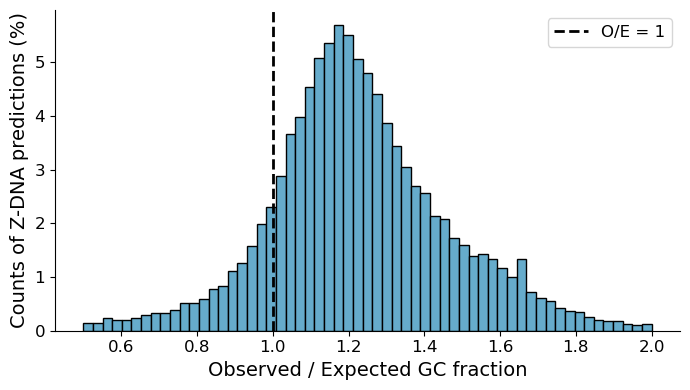

zdna_gc_oe_distribution.png
  n = 273,577
  median O/E = 1.2082



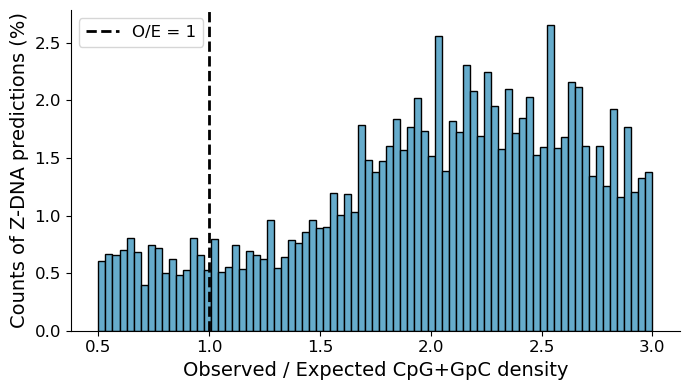

zdna_cpg_gpc_oe_distribution.png
  n = 255,872
  median O/E = 2.5870



In [3]:
#!/usr/bin/env python3

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


############################
# USER PARAMETERS
############################

IN_DIR  = "/work/10906/geomeg/vista/pangenomes_zdna/gc_correlations"
OUT_DIR = "/work/10906/geomeg/vista/pangenomes_zdna"

GC_PNG  = os.path.join(OUT_DIR, "zdna_gc_oe_distribution.png")
DN_PNG  = os.path.join(OUT_DIR, "zdna_cpg_gpc_oe_distribution.png")


############################
# PLOTTING
############################

def plot_oe_distribution(values, xlabel, bins, out_png):
    counts, edges = np.histogram(values, bins=bins)
    perc = counts / counts.sum() * 100
    centers = (edges[:-1] + edges[1:]) / 2

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.bar(
        centers,
        perc,
        width=np.diff(edges),
        edgecolor="black",
        color= "#66ACCC"
    )

    ax.axvline(
        1.0,
        color="black",
        linestyle="--",
        lw=2,
        label="O/E = 1"
    )

    # Axis labels (larger fonts)
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel("Counts of Z-DNA predictions (%)", fontsize=14)

    # Tick label sizes
    ax.tick_params(axis="both", which="major", labelsize=12)

    # Despine: remove top and right spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(fontsize=12)

    plt.tight_layout()
    plt.savefig(out_png, dpi=600)
    plt.show()

    # Print summary statistics AFTER plotting
    print(f"{os.path.basename(out_png)}")
    print(f"  n = {len(values):,}")
    print(f"  median O/E = {np.median(values):.4f}\n")

from scipy.stats import wilcoxon

def summarize_oe(values, label):
    values = np.asarray(values)

    median = np.median(values)
    mean   = np.mean(values)
    sd     = np.std(values, ddof=1)
    q1, q3 = np.percentile(values, [25, 75])
    iqr    = q3 - q1

    frac_gt1 = np.mean(values > 1.0)
    frac_lt1 = np.mean(values < 1.0)

    # Nonparametric test vs null O/E = 1
    w_stat, p_val = wilcoxon(values - 1.0, alternative="two-sided")

    print(f"{label}")
    print(f"  n                = {len(values):,}")
    print(f"  median O/E       = {median:.4f}")
    print(f"  mean O/E         = {mean:.4f}")
    print(f"  SD               = {sd:.4f}")
    print(f"  IQR              = {iqr:.4f} (Q1={q1:.4f}, Q3={q3:.4f})")
    print(f"  fraction > 1     = {frac_gt1:.3f}")
    print(f"  fraction < 1     = {frac_lt1:.3f}")
    print(f"  Wilcoxon vs 1.0  = W={w_stat:.3e}, p={p_val:.3e}")
    print()


############################
# MAIN
############################

def main():
    files = sorted(glob.glob(os.path.join(IN_DIR, "chr*_enrichment.tsv")))
    if not files:
        raise SystemExit("No per-chromosome enrichment files found.")

    dfs = []
    for f in files:
        df = pd.read_csv(f, sep="\t")
        dfs.append(df)

    all_df = pd.concat(dfs, ignore_index=True)

    # Clean O/E values
    oe_gc = (
        all_df["oe_gc"]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )
    oe_gc = oe_gc[oe_gc > 0]

    oe_dn = (
        all_df["oe_cpg_gpc"]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )
    oe_dn = oe_dn[oe_dn > 0]
    summarize_oe(oe_gc.values, "GC fraction O/E")
    summarize_oe(oe_dn.values, "CpG+GpC density O/E")

    # GC O/E distribution
    plot_oe_distribution(
        oe_gc.values,
        xlabel="Observed / Expected GC fraction",
        bins=np.linspace(0.5, 2.0, 60),
        out_png=GC_PNG
    )

    # CpG+GpC O/E distribution
    plot_oe_distribution(
        oe_dn.values,
        xlabel="Observed / Expected CpG+GpC density",
        bins=np.linspace(0.5, 3.0, 80),
        out_png=DN_PNG
    )


if __name__ == "__main__":
    main()

### Z-DNA controls' geneartion - 3 tolerance levels (5, 10 and 15%)

In [ ]:
# #!/usr/bin/env python3
# import os
# import gc
# import time
# import random
# import bisect
# from pathlib import Path

# import numpy as np
# import pandas as pd
# from pyfaidx import Fasta
# from tqdm import tqdm

# # ============================================================
# # SLURM / TOLERANCE SELECTION
# # ============================================================
# BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
# proc = int(os.environ.get("SLURM_PROCID", "0"))

# if proc == 0:
#     GC_TOL = DINUC_TOL = 0.05
#     OUT_DIR = f"{BASE}/controls_5pct"
# elif proc == 1:
#     GC_TOL = DINUC_TOL = 0.10
#     OUT_DIR = f"{BASE}/controls_10pct"
# elif proc == 2:
#     GC_TOL = DINUC_TOL = 0.15
#     OUT_DIR = f"{BASE}/controls_15pct"
# else:
#     raise SystemExit("Unexpected SLURM_PROCID")

# os.makedirs(OUT_DIR, exist_ok=True)

# random.seed(42)
# np.random.seed(42)

# MAX_RANDOM_TRIES = 10_000

# # ============================================================
# # INPUTS
# # ============================================================
# FASTA_FILE = f"{BASE}/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic.fna"
# ZD_FILE    = f"{BASE}/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"

# # UCSC → RefSeq mapping (authoritative)
# CHR_TO_CONTIG = {
#     "chr1":  "NC_060925.1", "chr2":  "NC_060926.1", "chr3":  "NC_060927.1",
#     "chr4":  "NC_060928.1", "chr5":  "NC_060929.1", "chr6":  "NC_060930.1",
#     "chr7":  "NC_060931.1", "chr8":  "NC_060932.1", "chr9":  "NC_060933.1",
#     "chr10": "NC_060934.1", "chr11": "NC_060935.1", "chr12": "NC_060936.1",
#     "chr13": "NC_060937.1", "chr14": "NC_060938.1", "chr15": "NC_060939.1",
#     "chr16": "NC_060940.1", "chr17": "NC_060941.1", "chr18": "NC_060942.1",
#     "chr19": "NC_060943.1", "chr20": "NC_060944.1", "chr21": "NC_060945.1",
#     "chr22": "NC_060946.1", "chrX":  "NC_060947.1", "chrY":  "NC_060948.1",
# }

# # ============================================================
# # HELPERS
# # ============================================================
# def within_tol(val, target, tol):
#     if target <= 0:
#         return val <= tol
#     return abs(val - target) <= tol * target


# def overlaps(intervals, s, e):
#     """
#     intervals: sorted list of (start, end) half-open
#     """
#     if not intervals:
#         return False
#     i = bisect.bisect_right(intervals, (s, e)) - 1
#     for j in (i, i + 1):
#         if 0 <= j < len(intervals):
#             s0, e0 = intervals[j]
#             if not (e <= s0 or e0 <= s):
#                 return True
#     return False


# def random_candidate(L, Lchr):
#     return np.random.randint(0, Lchr - L + 1)


# # ============================================================
# # LOAD DATA
# # ============================================================
# fasta = Fasta(FASTA_FILE)
# zd = pd.read_csv(ZD_FILE)

# # Convert ZSeeker to 0-based half-open immediately
# zd["Start0"] = zd["Start"] - 1
# zd["End0"]   = zd["End"]
# zd["Length"] = zd["End0"] - zd["Start0"]

# # ============================================================
# # MAIN LOOP
# # ============================================================
# for chrom in sorted(zd["Chromosome"].unique()):
#     if chrom not in CHR_TO_CONTIG:
#         continue

#     contig = CHR_TO_CONTIG[chrom]
#     seq = str(fasta[contig]).upper()
#     Lchr = len(seq)

#     print(f"\n=== {chrom} ({Lchr:,} bp) ===")

#     zdf = zd[zd["Chromosome"] == chrom].copy()

#     # Longest-first ordering
#     zdf = zdf.sort_values("Length", ascending=False).reset_index(drop=True)

#     # ------------------------------------------------------------
#     # Precompute GC and dinucleotide prefix sums
#     # ------------------------------------------------------------
#     b = np.frombuffer(seq.encode("ascii"), dtype=np.uint8)

#     is_gc = ((b == ord("G")) | (b == ord("C"))).astype(np.int8)
#     gc_cum = np.concatenate([[0], np.cumsum(is_gc)])

#     dinuc = np.zeros(Lchr - 1, dtype=np.int8)
#     dinuc[(b[:-1] == ord("C")) & (b[1:] == ord("G"))] = 1
#     dinuc[(b[:-1] == ord("G")) & (b[1:] == ord("C"))] = 1
#     dinuc_cum = np.concatenate([[0], np.cumsum(dinuc)])

#     def gc_frac(s, e):
#         return (gc_cum[e] - gc_cum[s]) / (e - s)

#     def dinuc_frac(s, e):
#         if e - s < 2:
#             return 0.0
#         return (dinuc_cum[e - 1] - dinuc_cum[s]) / (e - s - 1)

#     # ------------------------------------------------------------
#     # Z feature computation
#     # ------------------------------------------------------------
#     zdf["GC_pct"] = [
#         gc_frac(s, e) for s, e in zip(zdf["Start0"], zdf["End0"])
#     ]
#     zdf["Dinuc_density"] = [
#         dinuc_frac(s, e) for s, e in zip(zdf["Start0"], zdf["End0"])
#     ]

#     Z_intervals = sorted(zip(zdf["Start0"], zdf["End0"]))
#     control_intervals = []

#     # Output columns
#     zdf["Ctrl_Start"] = np.nan
#     zdf["Ctrl_End"]   = np.nan
#     zdf["Ctrl_Seq"]   = ""
#     zdf["fallback"]   = False

#     # ------------------------------------------------------------
#     # CONTROL ASSIGNMENT
#     # ------------------------------------------------------------
#     for i, r in zdf.iterrows():
#         L = int(r.Length)
#         t_gc = r.GC_pct
#         t_dn = r.Dinuc_density

#         placed = False

#         # ---------- Stage 1: random ----------
#         for _ in range(MAX_RANDOM_TRIES):
#             s = random_candidate(L, Lchr)
#             e = s + L
#             if overlaps(Z_intervals, s, e): continue
#             if overlaps(control_intervals, s, e): continue
#             if not within_tol(gc_frac(s, e), t_gc, GC_TOL): continue
#             if not within_tol(dinuc_frac(s, e), t_dn, DINUC_TOL): continue

#             placed = True
#             break

#         # ---------- Stage 2: randomized fallback ----------
#         if not placed:
#             forbidden = sorted(Z_intervals + control_intervals)
#             free = []
#             prev = 0
#             for s0, e0 in forbidden:
#                 if s0 > prev:
#                     free.append((prev, s0))
#                 prev = max(prev, e0)
#             if prev < Lchr:
#                 free.append((prev, Lchr))

#             random.shuffle(free)

#             for fs, fe in free:
#                 if fe - fs < L:
#                     continue
#                 start = random.randint(fs, fe - L)
#                 e = start + L
#                 if not within_tol(gc_frac(start, e), t_gc, GC_TOL): continue
#                 if not within_tol(dinuc_frac(start, e), t_dn, DINUC_TOL): continue
#                 s = start
#                 placed = True
#                 zdf.at[i, "fallback"] = True
#                 break

#         if placed:
#             zdf.at[i, "Ctrl_Start"] = s
#             zdf.at[i, "Ctrl_End"]   = e
#             zdf.at[i, "Ctrl_Seq"]   = seq[s:e]
#             bisect.insort(control_intervals, (s, e))

#     # ------------------------------------------------------------
#     # SAVE
#     # ------------------------------------------------------------
#     out = f"{OUT_DIR}/{chrom}_controls.tsv"
#     zdf.to_csv(out, sep="\t", index=False)
#     print(f"Saved {out}")

#     del zdf, gc_cum, dinuc_cum
#     gc.collect()

# print("\nDONE.")

# #!/bin/bash
# #SBATCH -J zdna_controls
# #SBATCH -p gg
# #SBATCH -N 1
# #SBATCH --ntasks=3
# #SBATCH --cpus-per-task=1
# #SBATCH -t 48:00:00
# #SBATCH -o logs/controls_%j.out
# #SBATCH -e logs/controls_%j.err

# set -euo pipefail

# cd /work/10906/geomeg/vista/pangenomes_zdna
# mkdir -p logs

# source /work/10906/geomeg/vista/miniconda3/etc/profile.d/conda.sh
# conda activate py_env

# echo "Starting Z-DNA controls on $(hostname)"
# date

# srun --ntasks=3 python generate_controls.py

# echo "All control runs finished"
# date

### Check for overlaps

In [3]:
import pandas as pd
import pyranges as pr
from pathlib import Path
import sys

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5%":  f"{BASE}/controls_5pct",
    "10%": f"{BASE}/controls_10pct",
    "15%": f"{BASE}/controls_15pct",
}

bad = []

print("Checking Z–C and C–C overlaps (0-based, half-open)")
print("=================================================\n")

for tol, d in CONTROL_DIRS.items():
    d = Path(d)
    print(f"Tolerance {tol}")

    for path in sorted(d.glob("chr*_controls.tsv")):
        df = pd.read_csv(path, sep="\t")

        chrom = df["Chromosome"].iloc[0]
        rows = []

        for i, r in df.iterrows():
            # -------------------------
            # Z interval (already 0-based)
            # -------------------------
            rows.append({
                "Chromosome": chrom,
                "Start": int(r["Start0"]),
                "End":   int(r["End0"]),
                "Type":  "Z",
                "Index": i,
            })

            # -------------------------
            # Control interval (already 0-based)
            # -------------------------
            if pd.notna(r["Ctrl_Start"]):
                rows.append({
                    "Chromosome": chrom,
                    "Start": int(r["Ctrl_Start"]),
                    "End":   int(r["Ctrl_End"]),
                    "Type":  "C",
                    "Index": i,
                })

        gr = pr.PyRanges(pd.DataFrame(rows))

        # All pairwise overlaps
        ov = gr.join(gr)

        if ov.df.empty:
            print(f"  ✅ {path.name}")
            continue

        df_ov = ov.df

        # Remove self-hits
        df_ov = df_ov[
            ~(
                (df_ov["Type"] == df_ov["Type_b"]) &
                (df_ov["Index"] == df_ov["Index_b"])
            )
        ]

        # Allow Z–Z overlaps
        df_ov = df_ov[
            ~(
                (df_ov["Type"] == "Z") &
                (df_ov["Type_b"] == "Z")
            )
        ]

        if not df_ov.empty:
            print(f"  ❌ {path.name}: REAL overlaps detected")
            print(df_ov.head(10))
            bad.append((tol, path.name))
        else:
            print(f"  ✅ {path.name}")

    print("")

if bad:
    print("OVERLAP ERRORS DETECTED")
    for tol, fname in bad:
        print(f"  {tol} → {fname}")
    sys.exit(1)

print("FINAL RESULT: No Z–C or C–C overlaps across all chromosomes and tolerances.")


Checking Z–C and C–C overlaps (0-based, half-open)

Tolerance 5%
  ✅ chr10_controls.tsv
  ✅ chr11_controls.tsv
  ✅ chr12_controls.tsv
  ✅ chr13_controls.tsv
  ✅ chr14_controls.tsv
  ✅ chr15_controls.tsv
  ✅ chr16_controls.tsv
  ✅ chr17_controls.tsv
  ✅ chr18_controls.tsv
  ✅ chr19_controls.tsv
  ✅ chr1_controls.tsv
  ✅ chr20_controls.tsv
  ✅ chr21_controls.tsv
  ✅ chr22_controls.tsv
  ✅ chr2_controls.tsv
  ✅ chr3_controls.tsv
  ✅ chr4_controls.tsv
  ✅ chr5_controls.tsv
  ✅ chr6_controls.tsv
  ✅ chr7_controls.tsv
  ✅ chr8_controls.tsv
  ✅ chr9_controls.tsv
  ✅ chrX_controls.tsv
  ✅ chrY_controls.tsv

Tolerance 10%
  ✅ chr10_controls.tsv
  ✅ chr11_controls.tsv
  ✅ chr12_controls.tsv
  ✅ chr13_controls.tsv
  ✅ chr14_controls.tsv
  ✅ chr15_controls.tsv
  ✅ chr16_controls.tsv
  ✅ chr17_controls.tsv
  ✅ chr18_controls.tsv
  ✅ chr19_controls.tsv
  ✅ chr1_controls.tsv
  ✅ chr20_controls.tsv
  ✅ chr21_controls.tsv
  ✅ chr22_controls.tsv
  ✅ chr2_controls.tsv
  ✅ chr3_controls.tsv
  ✅ chr4_contr

### Controls' yields and fallback ratios

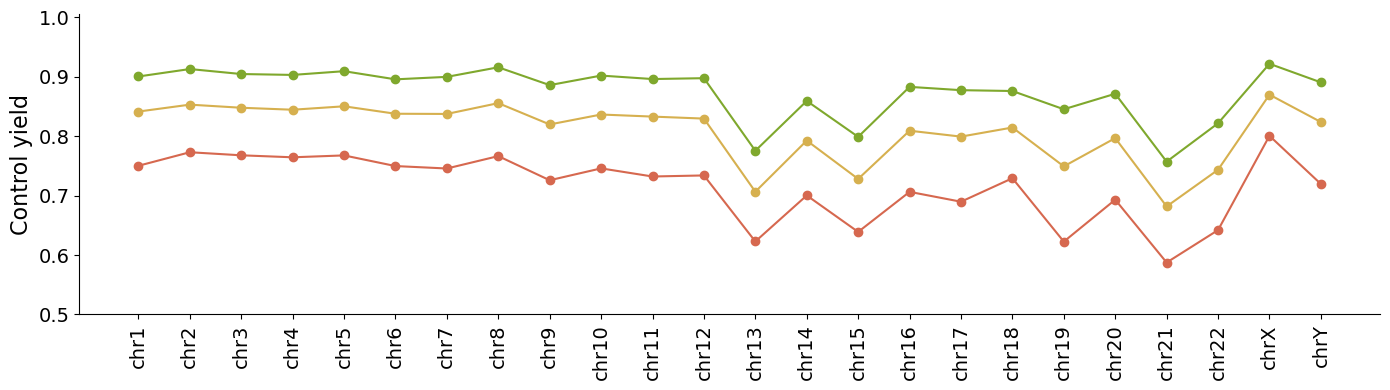

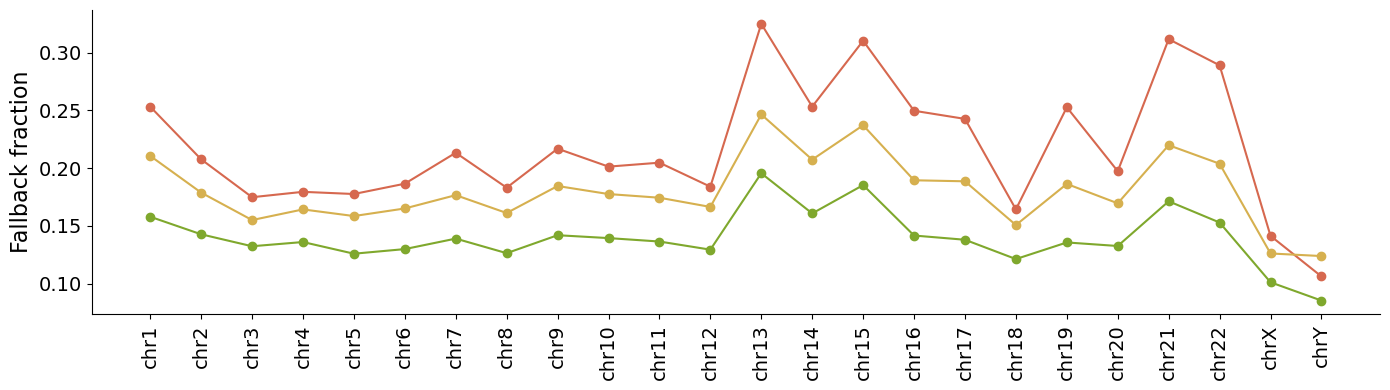

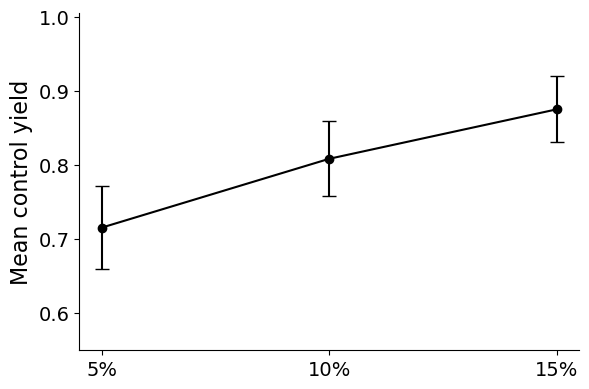

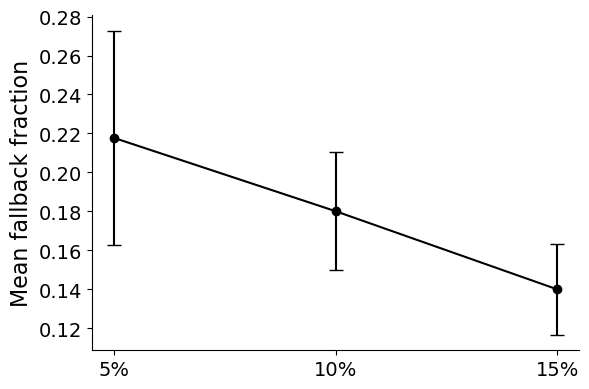

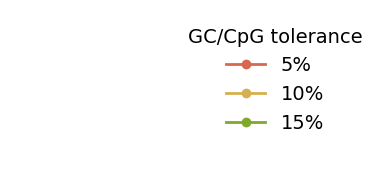

In [5]:
#!/usr/bin/env python3

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# =========================
# GLOBAL STYLE PARAMETERS
# =========================
AXIS_LABEL_SIZE = 16
TICK_LABEL_SIZE = 14
LEGEND_FONT_SIZE = 14
MARKER_SIZE = 6

# =========================
# CONFIGURATION
# =========================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5%":  f"{BASE}/controls_5pct",
    "10%": f"{BASE}/controls_10pct",
    "15%": f"{BASE}/controls_15pct",
}

OUTDIR = Path(f"{BASE}/figure2_panels")
OUTDIR.mkdir(exist_ok=True)

CHROM_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

COLORS = {
    "5%":  "#d6684f",
    "10%": "#d6b04f",
    "15%": "#7fa82d",
}

# =========================
# LOAD + AGGREGATE DATA
# =========================
records = []

for tol, d in CONTROL_DIRS.items():
    d = Path(d)
    for chrom in CHROM_ORDER:
        f = d / f"{chrom}_controls.tsv"
        if not f.exists():
            raise FileNotFoundError(f)

        df = pd.read_csv(f, sep="\t")

        total = len(df)
        matched = df["Ctrl_Start"].notna().sum()

        fallback_rate = (
            df.loc[df["Ctrl_Start"].notna(), "fallback"].mean()
            if matched > 0 else np.nan
        )

        records.append({
            "chrom": chrom,
            "tolerance": tol,
            "yield": matched / total,
            "fallback_rate": fallback_rate
        })

summary = pd.DataFrame(records)

# =========================
# PANEL A — Yield by chromosome
# =========================
plt.figure(figsize=(14, 4))

for tol in CONTROL_DIRS:
    df = summary[summary["tolerance"] == tol]
    plt.plot(
        df["chrom"], df["yield"],
        marker="o",
        markersize=MARKER_SIZE,
        color=COLORS[tol]
    )

plt.ylim(0.50, 1.005)
plt.ylabel("Control yield", fontsize=AXIS_LABEL_SIZE)
plt.xticks(rotation=90, fontsize=TICK_LABEL_SIZE)
plt.yticks(fontsize=TICK_LABEL_SIZE)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUTDIR / "Fig2A_yield_by_chrom.png", dpi=600)
plt.show()

# =========================
# PANEL B — Fallback rate by chromosome
# =========================
plt.figure(figsize=(14, 4))

for tol in CONTROL_DIRS:
    df = summary[summary["tolerance"] == tol]
    plt.plot(
        df["chrom"], df["fallback_rate"],
        marker="o",
        markersize=MARKER_SIZE,
        color=COLORS[tol]
    )

plt.ylabel("Fallback fraction", fontsize=AXIS_LABEL_SIZE)
plt.xticks(rotation=90, fontsize=TICK_LABEL_SIZE)
plt.yticks(fontsize=TICK_LABEL_SIZE)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUTDIR / "Fig2B_fallback_by_chrom.png", dpi=600)
plt.show()

# =========================
# PANEL C — Genome-wide yield vs tolerance (bounded error bars)
# =========================
gw = (
    summary
    .groupby("tolerance")["yield"]
    .agg(["mean", "std"])
    .reindex(["5%", "10%", "15%"])
)

y = gw["mean"].values
err = gw["std"].values

yerr = np.vstack([
    np.minimum(y, err),
    np.minimum(1 - y, err)
])

plt.figure(figsize=(6, 4))
plt.errorbar(
    gw.index, y,
    yerr=yerr,
    fmt="o-",
    color="black",
    capsize=5,
    markersize=MARKER_SIZE
)

plt.ylim(0.60, 1.005)
plt.ylabel("Mean control yield", fontsize=AXIS_LABEL_SIZE)
plt.xticks(fontsize=TICK_LABEL_SIZE)
plt.yticks(fontsize=TICK_LABEL_SIZE)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUTDIR / "Fig2C_genomewide_yield.png", dpi=600)
plt.show()

# =========================
# PANEL D — Genome-wide fallback vs tolerance (bounded error bars)
# =========================
gw = (
    summary
    .groupby("tolerance")["fallback_rate"]
    .agg(["mean", "std"])
    .reindex(["5%", "10%", "15%"])
)

y = gw["mean"].values
err = gw["std"].values

yerr = np.vstack([
    np.minimum(y, err),
    np.minimum(1 - y, err)
])

plt.figure(figsize=(6, 4))
plt.errorbar(
    gw.index, y,
    yerr=yerr,
    fmt="o-",
    color="black",
    capsize=5,
    markersize=MARKER_SIZE
)

plt.ylabel("Mean fallback fraction", fontsize=AXIS_LABEL_SIZE)
plt.xticks(fontsize=TICK_LABEL_SIZE)
plt.yticks(fontsize=TICK_LABEL_SIZE)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(OUTDIR / "Fig2D_genomewide_fallback.png", dpi=600)
plt.show()

# =========================
# PANEL E — Standalone legend
# =========================
plt.figure(figsize=(4, 2))

legend_handles = [
    Line2D([0], [0], color=COLORS["5%"],  marker="o", lw=2, label="5%"),
    Line2D([0], [0], color=COLORS["10%"], marker="o", lw=2, label="10%"),
    Line2D([0], [0], color=COLORS["15%"], marker="o", lw=2, label="15%"),
]

plt.legend(
    handles=legend_handles,
    title="GC/CpG tolerance",
    frameon=False,
    fontsize=LEGEND_FONT_SIZE,
    title_fontsize=LEGEND_FONT_SIZE
)

plt.axis("off")
plt.tight_layout()
plt.savefig(OUTDIR / "Fig2E_legend.png", dpi=600)
plt.show()

### Metrics

In [1]:
#!/usr/bin/env python3

import pandas as pd
from pathlib import Path
import re

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5%":  f"{BASE}/controls_5pct",
    "10%": f"{BASE}/controls_10pct",
    "15%": f"{BASE}/controls_15pct",
}

def gc_fraction(seq):
    if not isinstance(seq, str) or len(seq) == 0:
        return float("nan")
    return len(re.findall(r"[GCgc]", seq)) / len(seq)

print("GC parity check (Z-DNA GC_pct vs control GC fraction)")
print("---------------------------------------------------")

for tol, d in CONTROL_DIRS.items():
    deltas = []

    for f in Path(d).glob("chr*_controls.tsv"):
        df = pd.read_csv(f, sep="\t")

        # Only rows with valid controls
        df = df[df["Ctrl_Start"].notna()].copy()

        if df.empty:
            continue

        ctrl_gc = df["Ctrl_Seq"].apply(gc_fraction)
        delta = df["GC_pct"] - ctrl_gc
        deltas.append(delta)

    if not deltas:
        print(f"{tol}: NO DATA")
        continue

    delta_all = pd.concat(deltas)

    print(
        f"{tol}: "
        f"mean |ΔGC| = {delta_all.abs().mean():.6f}, "
        f"max |ΔGC| = {delta_all.abs().max():.6f}"
    )

GC parity check (Z-DNA GC_pct vs control GC fraction)
---------------------------------------------------
5%: mean |ΔGC| = 0.010379, max |ΔGC| = 0.047619
10%: mean |ΔGC| = 0.028559, max |ΔGC| = 0.100000
15%: mean |ΔGC| = 0.040796, max |ΔGC| = 0.145194


### Evaluation

In [10]:
import pandas as pd
import numpy as np

ZD_FILE = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"

zd = pd.read_csv(ZD_FILE)

# Sanity
assert {"Chromosome","Start","End"}.issubset(zd.columns)

zd["Length"] = zd["End"] - zd["Start"] + 1

# ---------------------------
# Per-chromosome stats
# ---------------------------
per_chr = (
    zd
    .groupby("Chromosome")["Length"]
    .agg(
        n_sites="count",
        min_len="min",
        median_len="median",
        max_len="max",
        n_unique_lengths=lambda x: x.nunique()
    )
    .sort_index()
)

print("\nPer-chromosome Z-DNA length statistics:")
print(per_chr)

# ---------------------------
# Genome-wide stats
# ---------------------------
genome_stats = {
    "n_sites": len(zd),
    "min_len": zd["Length"].min(),
    "median_len": zd["Length"].median(),
    "max_len": zd["Length"].max(),
    "n_unique_lengths": zd["Length"].nunique()
}

print("\nGenome-wide Z-DNA length statistics:")
for k, v in genome_stats.items():
    print(f"{k:20s}: {v}")

# ---------------------------
# Optional: length frequency table
# ---------------------------
length_counts = zd["Length"].value_counts().sort_index()
print("\nTop 20 most frequent Z-DNA lengths:")
print(length_counts.head(20))

import pandas as pd
from pathlib import Path

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5pct":  Path(f"{BASE}/controls_5pct"),
    "10pct": Path(f"{BASE}/controls_10pct"),
    "15pct": Path(f"{BASE}/controls_15pct"),
}

records = []

for tol, d in CONTROL_DIRS.items():
    for path in sorted(d.glob("chr*_controls.tsv")):
        df = pd.read_csv(path, sep="\t")

        chrom = df["Chromosome"].iloc[0]
        n_total = len(df)
        n_matched = df["Ctrl_Start"].notna().sum()
        n_fallback = df.loc[df["Ctrl_Start"].notna(), "fallback"].sum()

        records.append({
            "tolerance": tol,
            "chromosome": chrom,
            "n_z": n_total,
            "n_matched": n_matched,
            "yield": n_matched / n_total if n_total else np.nan,
            "fallback_fraction": n_fallback / n_matched if n_matched else np.nan
        })

yield_df = pd.DataFrame(records)

print("\nYield table (per chromosome, per tolerance):")
print(yield_df.sort_values(["tolerance","chromosome"]))

print("\nGenome-wide yield summary:")
print(
    yield_df
    .groupby("tolerance")[["n_z","n_matched","yield","fallback_fraction"]]
    .mean()
)
CHR_TO_CONTIG = {
    "chr1":  "NC_060925.1",
    "chr2":  "NC_060926.1",
    "chr3":  "NC_060927.1",
    "chr4":  "NC_060928.1",
    "chr5":  "NC_060929.1",
    "chr6":  "NC_060930.1",
    "chr7":  "NC_060931.1",
    "chr8":  "NC_060932.1",
    "chr9":  "NC_060933.1",
    "chr10": "NC_060934.1",
    "chr11": "NC_060935.1",
    "chr12": "NC_060936.1",
    "chr13": "NC_060937.1",
    "chr14": "NC_060938.1",
    "chr15": "NC_060939.1",
    "chr16": "NC_060940.1",
    "chr17": "NC_060941.1",
    "chr18": "NC_060942.1",
    "chr19": "NC_060943.1",
    "chr20": "NC_060944.1",
    "chr21": "NC_060945.1",
    "chr22": "NC_060946.1",
    "chrX":  "NC_060947.1",
    "chrY":  "NC_060948.1",
}
from pyfaidx import Fasta
import pandas as pd

FASTA = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic.fna"

fasta = Fasta(FASTA)

records = []

for chrom, dfc in zd.groupby("Chromosome"):
    contig = CHR_TO_CONTIG.get(chrom)
    if contig is None:
        continue
    if contig not in fasta:
        raise RuntimeError(f"{contig} not found in FASTA")

    Lchr = len(fasta[contig])
    z_bp = dfc["Length"].sum()

    records.append({
        "chromosome": chrom,
        "chr_length": Lchr,
        "n_z": len(dfc),
        "z_bp": z_bp,
        "z_bp_per_mb": z_bp / (Lchr / 1e6),
        "z_fraction": z_bp / Lchr,
        "mean_z_len": dfc["Length"].mean(),
        "max_z_len": dfc["Length"].max(),
    })

z_density_df = pd.DataFrame(records).sort_values("chromosome")

merged = (
    yield_df[yield_df["tolerance"] == "5pct"]
    .drop(columns=["n_z"])
    .merge(z_density_df, on="chromosome", how="left")
    .sort_values("yield")
)

print(
    merged[
        ["chromosome","n_z","yield","z_bp_per_mb","z_fraction","mean_z_len","max_z_len"]
    ]
)



from scipy.stats import spearmanr

rho, p = spearmanr(
    merged["yield"],
    merged["z_bp_per_mb"],
    nan_policy="omit"
)

print(f"Spearman rho (yield vs Z bp/Mb): {rho:.3f}, p={p:.3e}")




Per-chromosome Z-DNA length statistics:
            n_sites  min_len  median_len  max_len  n_unique_lengths
Chromosome                                                         
chr1          20757        9        43.0     4074               446
chr10         11764        9        44.0     4924               426
chr11         11403        9        45.0     2130               351
chr12         10773        9        44.0     3124               364
chr13         15017        9        43.0     2538               357
chr14          9766        9        42.0     1760               291
chr15         12484        9        41.0     2481               289
chr16          9725        9        40.0     2525               363
chr17         10410        9        38.0     2388               336
chr18          6102        9        46.0     1954               314
chr19         10547        9        35.0     1689               327
chr2          19054        9        45.0     3346               483
chr20  

In [12]:
#!/usr/bin/env python3

import pandas as pd
import numpy as np
from pathlib import Path
import re

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5%":  f"{BASE}/controls_5pct",
    "10%": f"{BASE}/controls_10pct",
    "15%": f"{BASE}/controls_15pct",
}

def gc_frac(seq):
    return len(re.findall(r"[GCgc]", seq)) / len(seq)

def dinuc_frac(seq):
    s = seq.upper()
    if len(s) < 2:
        return 0.0
    cnt = sum(
        (s[i:i+2] == "CG") or (s[i:i+2] == "GC")
        for i in range(len(s) - 1)
    )
    return cnt / (len(s) - 1)

records = []

for tol, d in CONTROL_DIRS.items():
    for f in sorted(Path(d).glob("chr*_controls.tsv")):
        df = pd.read_csv(f, sep="\t")

        chrom = df["Chromosome"].iloc[0]

        # keep matched only
        df = df[df["Ctrl_Start"].notna()].copy()
        if df.empty:
            continue

        # compute control composition
        ctrl_gc = df["Ctrl_Seq"].apply(gc_frac)
        ctrl_dn = df["Ctrl_Seq"].apply(dinuc_frac)

        dGC = ctrl_gc - df["GC_pct"]
        dDN = ctrl_dn - df["Dinuc_density"]

        records.append({
            "tolerance": tol,
            "chromosome": chrom,
            "n_pairs": len(df),

            "mean_dGC": dGC.mean(),
            "median_dGC": dGC.median(),
            "pct_ctrl_gc_higher": (dGC > 0).mean() * 100,
            "pct_ctrl_gc_lower":  (dGC < 0).mean() * 100,

            "mean_dDN": dDN.mean(),
            "median_dDN": dDN.median(),
            "pct_ctrl_dn_higher": (dDN > 0).mean() * 100,
            "pct_ctrl_dn_lower":  (dDN < 0).mean() * 100,
        })

summary = pd.DataFrame(records)

print("\n=== Signed-bias diagnostics (Z vs control) ===\n")
print(summary.sort_values(["tolerance", "chromosome"]).to_string(index=False))

# Global verdict per tolerance
print("\n=== GLOBAL NULL QUALITY CHECK ===\n")
RELATIVE_TOL = {"5%": 0.05, "10%": 0.10, "15%": 0.15}

for tol in CONTROL_DIRS:
    sub = summary[summary["tolerance"] == tol]

    max_gc = sub["mean_dGC"].abs().max()
    max_dn = sub["mean_dDN"].abs().max()

    tol_val = RELATIVE_TOL[tol]

    print(f"{tol}:")
    print(f"  max |mean dGC| = {max_gc:.4f}")
    print(f"  max |mean dDN| = {max_dn:.4f}")

    if max_gc > tol_val or max_dn > tol_val:
        print("  ❌ bias comparable to tolerance → investigate\n")
    else:
        print("  ✅ bias ≪ tolerance → null acceptable\n")




=== Signed-bias diagnostics (Z vs control) ===

tolerance chromosome  n_pairs  mean_dGC   median_dGC  pct_ctrl_gc_higher  pct_ctrl_gc_lower  mean_dDN    median_dDN  pct_ctrl_dn_higher  pct_ctrl_dn_lower
      10%       chr1    17467  0.009446 4.329004e-03           52.189844          28.556707 -0.003781  0.000000e+00           45.663251          26.484227
      10%      chr10     9841  0.009012 5.263158e-03           52.647089          28.919825 -0.002288  0.000000e+00           49.486841          23.564678
      10%      chr11     9499  0.009616 7.812500e-03           52.910833          28.213496 -0.002714  0.000000e+00           49.131488          23.876197
      10%      chr12     8938  0.008865 5.551115e-17           51.980309          29.066905 -0.001811  6.938894e-18           50.760797          21.861714
      10%      chr13    10610  0.011953 1.265823e-02           53.892554          27.360980 -0.006375  0.000000e+00           40.914232          32.384543
      10%      chr14 

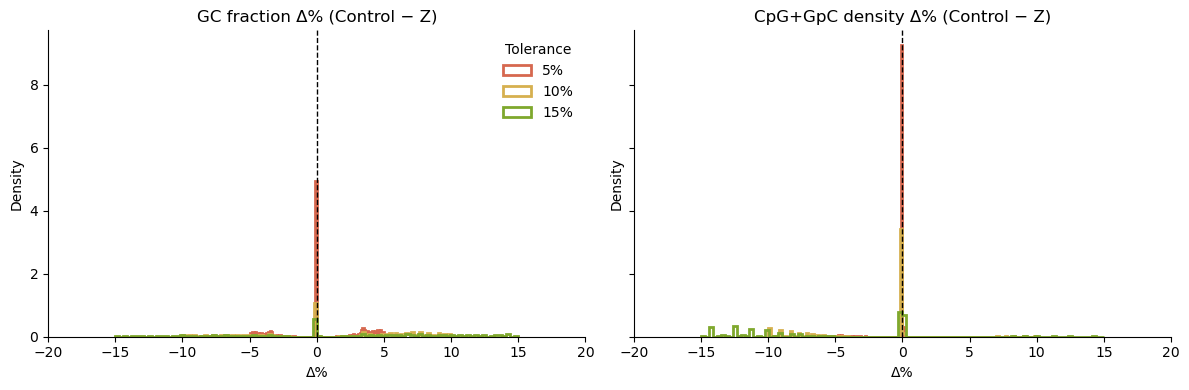


5%
GC Δ%:  mean = 0.37378638667773767 median = 0.0
DN Δ%:  mean = -0.11892650307630577 median = 1.4130111222501995e-14

10%
GC Δ%:  mean = 1.4444338338826275 median = 0.6027596223674608
DN Δ%:  mean = -1.9922553423255558 median = 0.0

15%
GC Δ%:  mean = 1.6703214152572448 median = 1.6666666666666738
DN Δ%:  mean = -5.471815346004712 median = -6.250000000000005


In [9]:
#!/usr/bin/env python3

import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# CONFIG
# =========================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5%":  f"{BASE}/controls_5pct",
    "10%": f"{BASE}/controls_10pct",
    "15%": f"{BASE}/controls_15pct",
}

OUT_PNG = f"{BASE}/Fig2F_control_delta_percent.png"

CHROMS = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

COLORS = {
    "5%":  "#d6684f",
    "10%": "#d6b04f",
    "15%": "#7fa82d",
}

# =========================
# HELPERS
# =========================
def gc_fraction(seq):
    if not isinstance(seq, str) or len(seq) == 0:
        return np.nan
    return (seq.count("G") + seq.count("C")) / len(seq)

def dinuc_density(seq):
    if not isinstance(seq, str) or len(seq) < 2:
        return np.nan
    count = 0
    for i in range(len(seq) - 1):
        if seq[i:i+2] in ("CG", "GC"):
            count += 1
    return count / (len(seq) - 1)

def clean(arr):
    arr = np.asarray(arr, dtype=float)
    return arr[np.isfinite(arr)]


# =========================
# COLLECT DELTAS
# =========================
delta_gc = {}
delta_dn = {}

for tol, d in CONTROL_DIRS.items():
    d = Path(d)
    dgcs = []
    ddns = []

    for chrom in CHROMS:
        f = d / f"{chrom}_controls.tsv"
        if not f.exists():
            continue

        df = pd.read_csv(f, sep="\t")
        df = df[df["Ctrl_Start"].notna()].copy()
        if df.empty:
            continue

        # GC Δ%
        ctrl_gc = df["Ctrl_Seq"].apply(gc_fraction)
        z_gc = df["GC_pct"]
        dgcs.append(100 * (ctrl_gc - z_gc) / z_gc)

        # CpG+GpC Δ%
        ctrl_dn = df["Ctrl_Seq"].apply(dinuc_density)
        z_dn = df["Dinuc_density"]
        ddns.append(100 * (ctrl_dn - z_dn) / z_dn)

    delta_gc[tol] = clean(pd.concat(dgcs))
    delta_dn[tol] = clean(pd.concat(ddns))


# =========================
# PLOT
# =========================
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for tol in CONTROL_DIRS:
    axes[0].hist(
        delta_gc[tol],
        bins=100,
        density=True,
        histtype="step",
        lw=2,
        color=COLORS[tol],
        label=tol
    )
    axes[1].hist(
        delta_dn[tol],
        bins=100,
        density=True,
        histtype="step",
        lw=2,
        color=COLORS[tol]
    )

for ax in axes:
    ax.axvline(0, color="black", ls="--", lw=1)
    ax.set_xlim(-20, 20)
    ax.set_ylabel("Density")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_title("GC fraction Δ% (Control − Z)")
axes[1].set_title("CpG+GpC density Δ% (Control − Z)")
axes[0].set_xlabel("Δ%")
axes[1].set_xlabel("Δ%")

axes[0].legend(title="Tolerance", frameon=False)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=600)
plt.show()

# =========================
# PRINT NUMERICAL SUMMARY
# =========================
for tol in CONTROL_DIRS:
    print(f"\n{tol}")
    print("GC Δ%:  mean =", np.mean(delta_gc[tol]), "median =", np.median(delta_gc[tol]))
    print("DN Δ%:  mean =", np.mean(delta_dn[tol]), "median =", np.median(delta_dn[tol]))


### Concat

In [13]:
#!/usr/bin/env python3

from pathlib import Path
import pandas as pd

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

CONTROL_DIRS = {
    "5pct":  f"{BASE}/controls_5pct",
    "10pct": f"{BASE}/controls_10pct",
    "15pct": f"{BASE}/controls_15pct",
}

OUTDIR = f"{BASE}/controls_combined"
Path(OUTDIR).mkdir(exist_ok=True)

for label, cdir in CONTROL_DIRS.items():
    cdir = Path(cdir)

    files = sorted(cdir.glob("chr*_controls.tsv"))
    if not files:
        raise RuntimeError(f"No control files found in {cdir}")

    dfs = []
    for f in files:
        df = pd.read_csv(f, sep="\t")
        dfs.append(df)

    combined = pd.concat(dfs, ignore_index=True)

    out_path = Path(OUTDIR) / f"CHM13_controls_{label}.tsv"
    combined.to_csv(out_path, sep="\t", index=False)

    print(f"[OK] {label}: {len(files)} files → {len(combined):,} rows → {out_path}")

[OK] 5pct: 24 files → 274,037 rows → /work/10906/geomeg/vista/pangenomes_zdna/controls_combined/CHM13_controls_5pct.tsv
[OK] 10pct: 24 files → 274,037 rows → /work/10906/geomeg/vista/pangenomes_zdna/controls_combined/CHM13_controls_10pct.tsv
[OK] 15pct: 24 files → 274,037 rows → /work/10906/geomeg/vista/pangenomes_zdna/controls_combined/CHM13_controls_15pct.tsv


In [14]:
#!/usr/bin/env python3

import pandas as pd
from pathlib import Path

BASE = "/work/10906/geomeg/vista/pangenomes_zdna/controls_combined"

FILES = {
    "5%":  Path(BASE) / "CHM13_controls_5pct.tsv",
    "10%": Path(BASE) / "CHM13_controls_10pct.tsv",
    "15%": Path(BASE) / "CHM13_controls_15pct.tsv",
}

OUTFILE = Path(BASE) / "CHM13_controls_MASTER.tsv"

dfs = []

# ------------------------------------------------------------
# LOAD + TAG
# ------------------------------------------------------------
for tol, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path, sep="\t")

    # Insert tol_level as FIRST column
    df.insert(0, "tol_level", tol)

    # Add has_control as LAST column
    df["has_control"] = df["Ctrl_Start"].notna()

    dfs.append(df)

# ------------------------------------------------------------
# CONCATENATE
# ------------------------------------------------------------
master = pd.concat(dfs, ignore_index=True)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
master.to_csv(OUTFILE, sep="\t", index=False)

print(f"\n[OK] Master file written:")
print(f"     {OUTFILE}")
print(f"     rows = {len(master):,}")
print(f"     columns = {len(master.columns)}")

# ============================================================
# DIAGNOSTICS
# ============================================================

print("\n================ MERGE DIAGNOSTICS ================\n")

# ---- tolerance counts
print("Rows per tolerance:")
print(
    master["tol_level"]
    .value_counts()
    .sort_index()
)

# ---- chromosome coverage
print("\nChromosomes present:")
print(
    master["Chromosome"]
    .value_counts()
    .sort_index()
)

# ---- control availability
print("\nControl availability by tolerance:")
print(
    master
    .groupby("tol_level")["has_control"]
    .agg(
        n_total="count",
        n_with_control="sum",
        frac_with_control="mean"
    )
)

# ---- internal consistency checks
print("\nConsistency checks:")

# Ctrl_Start / Ctrl_End must both be NA or both be present
bad_ctrl = master[
    master["has_control"]
    & (master["Ctrl_End"].isna())
]

print(f"  Ctrl_Start present but Ctrl_End missing: {len(bad_ctrl)}")

# Control length sanity
bad_len = master[
    master["has_control"]
    & (master["Ctrl_End"] <= master["Ctrl_Start"])
]

print(f"  Control intervals with non-positive length: {len(bad_len)}")

# Z interval sanity (0-based half-open)
bad_z = master[
    (master["End0"] <= master["Start0"]) | (master["Start0"] < 0)
]

print(f"  Z intervals with invalid coordinates: {len(bad_z)}")

# ---- final verdict
if len(bad_ctrl) == 0 and len(bad_len) == 0 and len(bad_z) == 0:
    print("\n✅ ALL CHECKS PASSED — MASTER TABLE IS CONSISTENT")
else:
    print("\n❌ ISSUES DETECTED — INVESTIGATE BEFORE DOWNSTREAM ANALYSIS")



[OK] Master file written:
     /work/10906/geomeg/vista/pangenomes_zdna/controls_combined/CHM13_controls_MASTER.tsv
     rows = 822,111
     columns = 16

================ MERGE DIAGNOSTICS ================

Rows per tolerance:
tol_level
10%    274037
15%    274037
5%     274037
Name: count, dtype: int64

Chromosomes present:
Chromosome
chr1     62271
chr10    35292
chr11    34209
chr12    32319
chr13    45051
chr14    29298
chr15    37452
chr16    29175
chr17    31230
chr18    18306
chr19    31641
chr2     57162
chr20    19326
chr21    27762
chr22    22926
chr3     40953
chr4     39822
chr5     40497
chr6     38793
chr7     39783
chr8     34407
chr9     33246
chrX     34632
chrY      6558
Name: count, dtype: int64

Control availability by tolerance:
           n_total  n_with_control  frac_with_control
tol_level                                            
10%         274037          222577           0.812215
15%         274037          240541           0.877768
5%          274037    

### matched vs unmatched

[10%] GC_pct: matched n=222577, unmatched n=51460, Mann–Whitney p=0.000e+00, Cliff’s δ=-0.810
[10%] GC_pct
  matched   median=0.5610, IQR=0.2885 (Q1=0.4615, Q3=0.7500)
  unmatched median=0.8667, IQR=0.1052 (Q1=0.8148, Q3=0.9200)
[10%] Dinuc_density: matched n=222577, unmatched n=51460, Mann–Whitney p=0.000e+00, Cliff’s δ=-0.874
[10%] Dinuc_density
  matched   median=0.1842, IQR=0.2913 (Q1=0.0758, Q3=0.3671)
  unmatched median=0.5200, IQR=0.1399 (Q1=0.4510, Q3=0.5909)


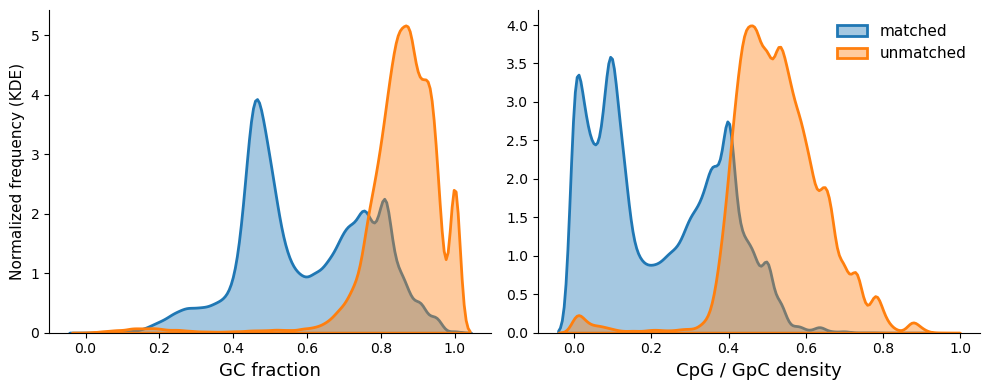

In [4]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# ============================================================
# LOAD MASTER CONTROL TABLE
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna/controls_combined"
df = pd.read_csv(f"{BASE}/CHM13_controls_MASTER.tsv", sep="\t")

REQUIRED = {
    "tol_level","has_control","GC_pct","Dinuc_density",
    "Length","Z-DNA Score","Chromosome","Start","End"
}
assert REQUIRED.issubset(df.columns)

# ============================================================
# SELECT SINGLE TOLERANCE LEVEL
# ============================================================
TOL = "10%"

d = df[df["tol_level"] == TOL].copy()
matched   = d[d["has_control"]]
unmatched = d[~d["has_control"]]

assert len(matched) > 0 and len(unmatched) > 0

# ============================================================
# FIGURE SETUP (GC + DINUC)
# ============================================================
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(10, 4),
    sharey=False
)

COLS = [
    ("GC_pct", "GC fraction"),
    ("Dinuc_density", "CpG / GpC density"),
]

# ============================================================
# PLOTTING + STATS
# ============================================================
for idx, (ax, (col, xlabel)) in enumerate(zip(axes, COLS)):

    m = matched[col].dropna()
    u = unmatched[col].dropna()

    # KDE plots
    sns.kdeplot(
        m,
        ax=ax,
        label="matched",
        linewidth=2,
        fill=True,
        alpha=0.4,
        common_norm=False
    )

    sns.kdeplot(
        u,
        ax=ax,
        label="unmatched",
        linewidth=2,
        fill=True,
        alpha=0.4,
        common_norm=False
    )

    ax.set_xlabel(xlabel, fontsize=13)

    # Y label only on left panel
    if idx == 0:
        ax.set_ylabel("Normalized frequency (KDE)", fontsize=11)
    else:
        ax.set_ylabel("")

    ax.tick_params(axis="both", labelsize=10)

    sns.despine(ax=ax)

    # --------------------------------------------------------
    # Non-parametric test + effect size
    # --------------------------------------------------------
    U, pval = mannwhitneyu(m, u, alternative="two-sided")

    # Cliff's delta
    delta = (2 * U) / (len(m) * len(u)) - 1

    print(
        f"[{TOL}] {col}: "
        f"matched n={len(m)}, unmatched n={len(u)}, "
        f"Mann–Whitney p={pval:.3e}, "
        f"Cliff’s δ={delta:.3f}"
    )
    def summarize(x):
        q1, q3 = np.percentile(x, [25, 75])
        return {
            "median": np.median(x),
            "IQR": q3 - q1,
            "Q1": q1,
            "Q3": q3
        }
    
    sm = summarize(m)
    su = summarize(u)
    
    print(
        f"[{TOL}] {col}\n"
        f"  matched   median={sm['median']:.4f}, IQR={sm['IQR']:.4f} "
        f"(Q1={sm['Q1']:.4f}, Q3={sm['Q3']:.4f})\n"
        f"  unmatched median={su['median']:.4f}, IQR={su['IQR']:.4f} "
        f"(Q1={su['Q1']:.4f}, Q3={su['Q3']:.4f})"
    )

axes[1].legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig(
    "/work/10906/geomeg/vista/pangenomes_zdna/gc_cpg_matched_unmatched_10pct_kde.png",
    dpi=600
)
plt.show()

### matched and unmatched (methylation)

[10%] GC_pct
  matched   median=0.5610, IQR=0.2885 (Q1=0.4615, Q3=0.7500)
  unmatched median=0.8667, IQR=0.1052 (Q1=0.8148, Q3=0.9200)
[10%] GC_pct: matched n=222577, unmatched n=51460, MW p=0.000e+00, Cliff’s δ=-0.810
[10%] Dinuc_density
  matched   median=0.1842, IQR=0.2913 (Q1=0.0758, Q3=0.3671)
  unmatched median=0.5200, IQR=0.1399 (Q1=0.4510, Q3=0.5909)
[10%] Dinuc_density: matched n=222577, unmatched n=51460, MW p=0.000e+00, Cliff’s δ=-0.874
[10%] meth_mean
  matched   median=0.8631, IQR=0.5416 (Q1=0.4043, Q3=0.9459)
  unmatched median=0.0535, IQR=0.6308 (Q1=0.0350, Q3=0.6658)
[10%] meth_mean: matched n=174209, unmatched n=45595, MW p=0.000e+00, Cliff’s δ=0.502


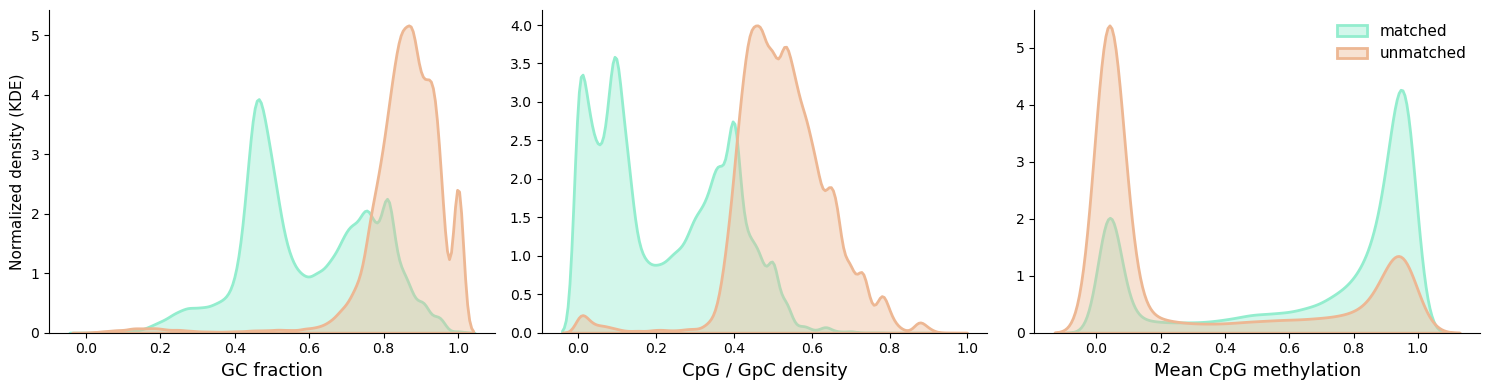

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyBigWig
from scipy.stats import mannwhitneyu

# ============================================================
# INPUTS
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna/controls_combined"
TSV  = f"{BASE}/CHM13_controls_MASTER.tsv"

BW_CPG = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/chm13v2.0_hg002_CpG_ont_guppy6.1.2.bw"

TOL = "10%"

# Custom HTML colors
COLORS = {
    "matched":   "#93EDCE",  # blue
    "unmatched": "#EDB793",  # orange
}

# ============================================================
# LOAD TABLE
# ============================================================
df = pd.read_csv(TSV, sep="\t")

REQUIRED = {
    "tol_level", "has_control", "GC_pct", "Dinuc_density",
    "Length", "Chromosome", "Start", "End"
}
missing = REQUIRED.difference(df.columns)
if missing:
    raise RuntimeError(f"Missing required columns: {sorted(missing)}")

d = df[df["tol_level"] == TOL].copy()
matched   = d[d["has_control"]].copy()
unmatched = d[~d["has_control"]].copy()

assert len(matched) > 0 and len(unmatched) > 0

# ============================================================
# COMPUTE CpG METHYLATION (interval mean, CpG-observed space)
# ============================================================
bw = pyBigWig.open(BW_CPG)

def interval_mean_methylation(row):
    start0 = int(row.Start) - 1   # 1-based → 0-based
    end0   = int(row.End)
    if end0 <= start0:
        return np.nan
    m = bw.stats(row.Chromosome, start0, end0, type="mean", exact=True)[0]
    return float(m) if m is not None else np.nan

matched["meth_mean"]   = matched.apply(interval_mean_methylation, axis=1)
unmatched["meth_mean"] = unmatched.apply(interval_mean_methylation, axis=1)

bw.close()

matched_m   = matched["meth_mean"].dropna()
unmatched_m = unmatched["meth_mean"].dropna()
def summarize(x):
    q1, q3 = np.percentile(x, [25, 75])
    return {
        "median": np.median(x),
        "IQR": q3 - q1,
        "Q1": q1,
        "Q3": q3
    }

# ============================================================
# FIGURE SETUP
# ============================================================
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 4),
    sharey=False
)

PANELS = [
    ("GC_pct",        "GC fraction"),
    ("Dinuc_density", "CpG / GpC density"),
    ("meth_mean",     "Mean CpG methylation"),
]

# ============================================================
# PLOTTING + STATS
# ============================================================
for idx, (ax, (col, xlabel)) in enumerate(zip(axes, PANELS)):

    if col == "meth_mean":
        m = matched_m
        u = unmatched_m
    else:
        m = matched[col].dropna()
        u = unmatched[col].dropna()

    sns.kdeplot(
        m,
        ax=ax,
        label="matched",
        linewidth=2,
        fill=True,
        alpha=0.4,
        color=COLORS["matched"],
        common_norm=False,
    )

    sns.kdeplot(
        u,
        ax=ax,
        label="unmatched",
        linewidth=2,
        fill=True,
        alpha=0.4,
        color=COLORS["unmatched"],
        common_norm=False,
    )

    ax.set_xlabel(xlabel, fontsize=13)

    if idx == 0:
        ax.set_ylabel("Normalized density (KDE)", fontsize=11)
    else:
        ax.set_ylabel("")

    ax.tick_params(axis="both", labelsize=10)
    sns.despine(ax=ax)

    # --------------------------------------------------------
    # Nonparametric stats
    # --------------------------------------------------------
    U, pval = mannwhitneyu(m, u, alternative="two-sided")
    cliff_delta = (2 * U) / (len(m) * len(u)) - 1
    sm = summarize(m)
    su = summarize(u)
    
    print(
        f"[{TOL}] {col}\n"
        f"  matched   median={sm['median']:.4f}, IQR={sm['IQR']:.4f} "
        f"(Q1={sm['Q1']:.4f}, Q3={sm['Q3']:.4f})\n"
        f"  unmatched median={su['median']:.4f}, IQR={su['IQR']:.4f} "
        f"(Q1={su['Q1']:.4f}, Q3={su['Q3']:.4f})"
    )

    print(
        f"[{TOL}] {col}: "
        f"matched n={len(m)}, unmatched n={len(u)}, "
        f"MW p={pval:.3e}, Cliff’s δ={cliff_delta:.3f}"
    )

axes[-1].legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/matched_vs_unmatched.png", dpi=600)
plt.show()


[10%] GC_pct: matched n=222577, unmatched n=51460, MW p=0.000e+00, Cliff’s δ=-0.810
[10%] Dinuc_density: matched n=222577, unmatched n=51460, MW p=0.000e+00, Cliff’s δ=-0.874
[10%] meth_mean: matched n=174209, unmatched n=45595, MW p=0.000e+00, Cliff’s δ=0.502
[10%] gpc_mean: matched n=189340, unmatched n=43246, MW p=0.000e+00, Cliff’s δ=-0.225


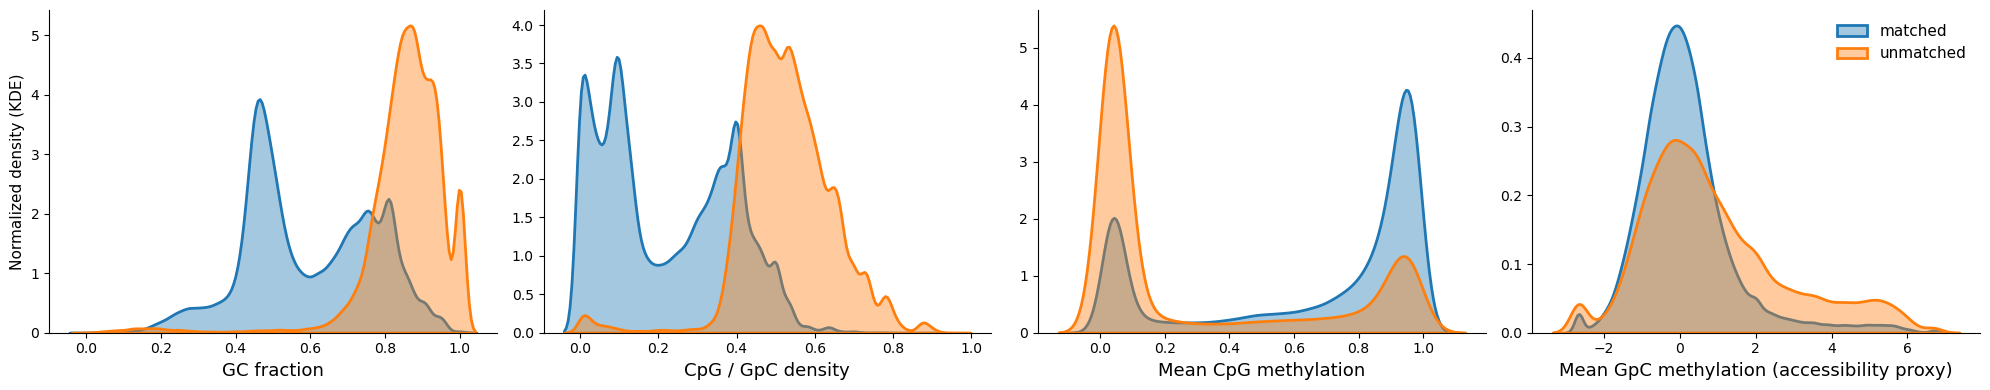

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyBigWig
from scipy.stats import mannwhitneyu

# ============================================================
# INPUTS
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna/controls_combined"
TSV  = f"{BASE}/CHM13_controls_MASTER.tsv"
BW   = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/chm13v2.0_hg002_CpG_ont_guppy6.1.2.bw"
BW_GPC = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/" \
         "chm13v2.0_hg002_GpC_zscore_ont_guppy5.0.7_nanopolish0.13.2.bw"

TOL = "10%"

# ============================================================
# LOAD TABLE
# ============================================================
df = pd.read_csv(TSV, sep="\t")

REQUIRED = {
    "tol_level","has_control","GC_pct","Dinuc_density",
    "Length","Chromosome","Start","End"
}
assert REQUIRED.issubset(df.columns)

d = df[df["tol_level"] == TOL].copy()
matched   = d[d["has_control"]].copy()
unmatched = d[~d["has_control"]].copy()

assert len(matched) > 0 and len(unmatched) > 0

# ============================================================
# COMPUTE METHYLATION (interval mean, CpG-observed space)
# ============================================================
bw = pyBigWig.open(BW)

def interval_mean_methylation(row):
    start0 = int(row.Start) - 1   # 1-based → 0-based
    end0   = int(row.End)
    if end0 <= start0:
        return np.nan
    m = bw.stats(row.Chromosome, start0, end0, type="mean", exact=True)[0]
    return float(m) if m is not None else np.nan

matched["meth_mean"] = matched.apply(interval_mean_methylation, axis=1)
unmatched["meth_mean"] = unmatched.apply(interval_mean_methylation, axis=1)

bw.close()

# Drop NaN only for methylation comparisons
matched_m = matched["meth_mean"].dropna()
unmatched_m = unmatched["meth_mean"].dropna()
bw_gpc = pyBigWig.open(BW_GPC)

def interval_mean_gpc(row):
    start0 = int(row.Start) - 1
    end0   = int(row.End)
    if end0 <= start0:
        return np.nan
    m = bw_gpc.stats(row.Chromosome, start0, end0, type="mean", exact=True)[0]
    return float(m) if m is not None else np.nan

matched["gpc_mean"]   = matched.apply(interval_mean_gpc, axis=1)
unmatched["gpc_mean"] = unmatched.apply(interval_mean_gpc, axis=1)

bw_gpc.close()

matched_g = matched["gpc_mean"].dropna()
unmatched_g = unmatched["gpc_mean"].dropna()

# ============================================================
# FIGURE SETUP
# ============================================================
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))

PANELS = [
    ("GC_pct", "GC fraction"),
    ("Dinuc_density", "CpG / GpC density"),
    ("meth_mean", "Mean CpG methylation"),
    ("gpc_mean", "Mean GpC methylation (accessibility proxy)"),
]


# ============================================================
# PLOTTING + STATS
# ============================================================
for idx, (ax, (col, xlabel)) in enumerate(zip(axes, PANELS)):
    if col == "meth_mean":
        m, u = matched_m, unmatched_m
    elif col == "gpc_mean":
        m, u = matched_g, unmatched_g
    else:
        m = matched[col].dropna()
        u = unmatched[col].dropna()


    sns.kdeplot(
        m, ax=ax, label="matched",
        linewidth=2, fill=True, alpha=0.4, common_norm=False
    )
    sns.kdeplot(
        u, ax=ax, label="unmatched",
        linewidth=2, fill=True, alpha=0.4, common_norm=False
    )

    ax.set_xlabel(xlabel, fontsize=13)

    if idx == 0:
        ax.set_ylabel("Normalized density (KDE)", fontsize=11)
    else:
        ax.set_ylabel("")

    ax.tick_params(axis="both", labelsize=10)
    sns.despine(ax=ax)

    # -----------------------------
    # Nonparametric stats
    # -----------------------------
    U, pval = mannwhitneyu(m, u, alternative="two-sided")
    cliff_delta = (2 * U) / (len(m) * len(u)) - 1

    print(
        f"[{TOL}] {col}: "
        f"matched n={len(m)}, unmatched n={len(u)}, "
        f"MW p={pval:.3e}, Cliff’s δ={cliff_delta:.3f}"
    )

axes[-1].legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.show()


## Genomic features

### Features

#### Bash script for annotation files

In [ ]:
#!/usr/bin/env bash
set -euo pipefail

GFF="chm13v2.0_RefSeq_Liftoff_v5.2.gff3.gz"
ZDNA="zdna.bed"
CTRL="zdna_ctrl.bed"

CENSAT="chm13v2.0_censat_v2.1.bed"
TELO="chm13v2.0_telomere.bed"
RMSK="chm13v2.0_RepeatMasker_4.1.2p1.2022Apr14.bed"
INTRONS="pc_transcript_introns.bed"

OUTDIR="enrichment_investigation_v2"
mkdir -p "${OUTDIR}"

for t in bedtools awk sort zgrep cut; do
  command -v "$t" >/dev/null || { echo "Missing tool: $t"; exit 1; }
done

sort_bed3() { LC_ALL=C sort -k1,1 -k2,2n; }
merge_bed3() { cut -f1-3 | sort_bed3 | bedtools merge -i -; }
bed_len() { awk '{s+=($3-$2)} END{print s+0}'; }

sort_bed3 < "$ZDNA" > "${OUTDIR}/Z.sorted.bed"
sort_bed3 < "$CTRL" > "${OUTDIR}/C.sorted.bed"

zgrep -v '^#' "$GFF" \
| awk -F'\t' '$3=="gene"' \
| awk -F'[;\t]' '
  {
    for(i=1;i<=NF;i++) if($i~/^gene_biotype=/){
      sub(/^gene_biotype=/,"",$i);
      s=$4-1; e=$5;
      if(e>s) print $1,s,e,$i
    }
  }' OFS="\t" \
> "${OUTDIR}/genes_all.bed4"

# explicit gene classes
for bt in protein_coding lncRNA pseudogene miRNA snoRNA; do
  awk -v B="$bt" '$4==B{print $1,$2,$3}' OFS="\t" "${OUTDIR}/genes_all.bed4" \
  | merge_bed3 > "${OUTDIR}/gene_${bt}.merged.bed"
done

# gene_other
awk '
  $4!="protein_coding" && $4!="lncRNA" && $4!="pseudogene" &&
  $4!="miRNA" && $4!="snoRNA" && $4!="rRNA" && $4!="tRNA"
  {print $1,$2,$3}
' OFS="\t" "${OUTDIR}/genes_all.bed4" \
| merge_bed3 > "${OUTDIR}/gene_other.merged.bed"

# gene rRNA / tRNA (for globals)
awk '$4=="rRNA"{print $1,$2,$3}' OFS="\t" "${OUTDIR}/genes_all.bed4" \
| merge_bed3 > "${OUTDIR}/gene_rRNA.tmp.bed"

awk '$4=="tRNA"{print $1,$2,$3}' OFS="\t" "${OUTDIR}/genes_all.bed4" \
| merge_bed3 > "${OUTDIR}/gene_tRNA.tmp.bed"

# gene union
cut -f1-3 "${OUTDIR}/genes_all.bed4" | merge_bed3 > "${OUTDIR}/genes_any.merged.bed"

awk '$4=="protein_coding"{print $1,$2,$3}' OFS="\t" "${OUTDIR}/genes_all.bed4" \
| merge_bed3 > "${OUTDIR}/pc_gene_span.merged.bed"

zgrep -v '^#' "$GFF" | awk -F'\t' '$3=="exon"{print $1,$4-1,$5}' OFS="\t" \
| merge_bed3 > "${OUTDIR}/pc_exon.merged.bed"

zgrep -v '^#' "$GFF" | awk -F'\t' '$3=="CDS"{print $1,$4-1,$5}' OFS="\t" \
| merge_bed3 > "${OUTDIR}/pc_CDS.merged.bed"

merge_bed3 < "$INTRONS" > "${OUTDIR}/pc_intron.merged.bed"

awk -F'\t' '
  {
    name=$4; sub(/\(.*/,"",name);
    split(name,a,"_"); print $1,$2,$3,a[1]
  }' OFS="\t" "$CENSAT" > "${OUTDIR}/censat.bed4"

awk '$4=="rDNA"{print $1,$2,$3}' OFS="\t" "${OUTDIR}/censat.bed4" \
| merge_bed3 > "${OUTDIR}/censat_rDNA.tmp.bed"

for p in ct censat hor dhor mon hsat1A hsat1B hsat2 hsat3 gsat bsat; do
  awk -v P="$p" '$4==P{print $1,$2,$3}' OFS="\t" "${OUTDIR}/censat.bed4" \
  | merge_bed3 > "${OUTDIR}/censat_${p}.merged.bed"
done

# rRNA / tRNA → globals
awk '$7=="rRNA"{print $1,$2,$3}' OFS="\t" "$RMSK" | merge_bed3 > "${OUTDIR}/rmsk_rRNA.tmp.bed"
awk '$7=="tRNA"{print $1,$2,$3}' OFS="\t" "$RMSK" | merge_bed3 > "${OUTDIR}/rmsk_tRNA.tmp.bed"

awk '$7=="DNA"{print $1,$2,$3}' OFS="\t" "$RMSK" | merge_bed3 > "${OUTDIR}/rmsk_DNA_transposon.merged.bed"
awk '$7!="DNA" && $7~/^DNA/{print $1,$2,$3}' OFS="\t" "$RMSK" | merge_bed3 > "${OUTDIR}/rmsk_DNA_other.merged.bed"

for cls in LINE SINE LTR Simple_repeat Satellite Low_complexity Retroposon RC Beta snRNA srpRNA scRNA Unknown; do
  awk -v C="$cls" '$7==C{print $1,$2,$3}' OFS="\t" "$RMSK" \
  | merge_bed3 > "${OUTDIR}/rmsk_${cls}.merged.bed"
done

cut -f1-3 "$RMSK" | merge_bed3 > "${OUTDIR}/rmsk_all.merged.bed"

cat \
  "${OUTDIR}/gene_rRNA.tmp.bed" \
  "${OUTDIR}/rmsk_rRNA.tmp.bed" \
  "${OUTDIR}/censat_rDNA.tmp.bed" \
| merge_bed3 > "${OUTDIR}/rDNA_arrays.merged.bed"

cat \
  "${OUTDIR}/gene_tRNA.tmp.bed" \
  "${OUTDIR}/rmsk_tRNA.tmp.bed" \
| merge_bed3 > "${OUTDIR}/tRNA_arrays.merged.bed"
merge_bed3 < "$TELO" > "${OUTDIR}/telomere.merged.bed"

cat \
  "${OUTDIR}/genes_any.merged.bed" \
  "${OUTDIR}/rmsk_all.merged.bed" \
  "${OUTDIR}/telomere.merged.bed" \
| merge_bed3 > "${OUTDIR}/UNION_annot.merged.bed"

overlap_bp() { bedtools intersect -a "$1" -b "$2" -wo | awk '{s+=$NF} END{print s+0}'; }
emit() {
  Zbp=$(bed_len < "${OUTDIR}/Z.sorted.bed")
  Cbp=$(bed_len < "${OUTDIR}/C.sorted.bed")
  Zo=$(overlap_bp "${OUTDIR}/Z.sorted.bed" "$2")
  Co=$(overlap_bp "${OUTDIR}/C.sorted.bed" "$2")
  fZ=$(awk -v o=$Zo -v t=$Zbp 'BEGIN{print o/t}')
  fC=$(awk -v o=$Co -v t=$Cbp 'BEGIN{print o/t}')
  l2=$(awk -v a=$fZ -v b=$fC 'BEGIN{print (b>0 && a>0)?log(a/b)/log(2):"NA"}')  
  printf "%s\t%.6f\t%.6f\t%s\t%d\t%d\t%d\t%d\n" \
    "$1" "$fZ" "$fC" "$l2" "$Zbp" "$Cbp" "$Zo" "$Co"
}

OUTTSV="${OUTDIR}/zdna_vs_ctrl_feature_enrichment.tsv"
{
  echo -e "feature\tfracZ\tfracC\tlog2_enrichment\ttotalZ_bp\ttotalC_bp\toverlapZ_bp\toverlapC_bp"
  for f in "${OUTDIR}"/*.merged.bed; do
    name=$(basename "$f" .merged.bed)
    emit "$name" "$f"
  done
} > "$OUTTSV"

echo "[DONE] Wrote $OUTTSV"

#### zdna vs control

In [ ]:
# #!/usr/bin/env python3
# import argparse
# from pathlib import Path
# import numpy as np
# import pandas as pd
# import pyranges as pr
# def read_bed3(path: Path) -> pr.PyRanges:
#     df = pd.read_csv(
#         path, sep="\t", header=None,
#         usecols=[0, 1, 2],
#         names=["Chromosome", "Start", "End"],
#         dtype={"Chromosome": str}
#     )
#     df = df[df["End"] > df["Start"]]
#     return pr.PyRanges(df)


# def read_chrom_lengths(tsv: Path) -> dict:
#     return dict(
#         pd.read_csv(
#             tsv, sep="\t",
#             usecols=["ucsc_pansn_name", "gcf_seq_length"]
#         ).values
#     )


# def build_blocks(chrom_len: dict, block_size: int) -> pr.PyRanges:
#     rows = []
#     for chrom, L in chrom_len.items():
#         for s in range(0, L, block_size):
#             rows.append((chrom, s, min(s + block_size, L)))
#     return pr.PyRanges(pd.DataFrame(
#         rows, columns=["Chromosome", "Start", "End"]
#     ))


# def bp_overlap(a: pr.PyRanges, b: pr.PyRanges) -> np.ndarray:
#     """
#     Returns array ov[i] = bp overlap between a[i] and b
#     a must be a PyRanges with a stable row order
#     """
#     if a.empty or b.empty:
#         return np.zeros(len(a), dtype=np.int64)

#     j = a.join(b)
#     if j.empty:
#         return np.zeros(len(a), dtype=np.int64)

#     df = j.df

#     ovlen = (df["End"] - df["Start"]).to_numpy(np.int64)

#     out = np.zeros(len(a), dtype=np.int64)
#     np.add.at(out, df.index.to_numpy(np.int64), ovlen)

#     return out


# # ============================================================
# # MAIN
# # ============================================================
# def main():
#     ap = argparse.ArgumentParser()
#     ap.add_argument("--z", required=True)
#     ap.add_argument("--c", required=True)
#     ap.add_argument("--featdir", required=True)
#     ap.add_argument("--chrom_len_tsv", required=True)
#     ap.add_argument("--out_tsv", required=True)
#     ap.add_argument("--n_boot", type=int, default=500)
#     ap.add_argument("--seed", type=int, default=42)
#     ap.add_argument("--block_size", type=int, default=1_000_000)
#     args = ap.parse_args()

#     rng = np.random.default_rng(args.seed)

#     Z = read_bed3(Path(args.z))
#     C = read_bed3(Path(args.c))

#     chrom_len = read_chrom_lengths(Path(args.chrom_len_tsv))
#     blocks = build_blocks(chrom_len, args.block_size)

#     Zb = blocks.intersect(Z)
#     Cb = blocks.intersect(C)

#     Z_bp = Zb.lengths().to_numpy(np.int64)
#     C_bp = Cb.lengths().to_numpy(np.int64)

#     Z_tot = Z_bp.sum()
#     C_tot = C_bp.sum()

#     # ========================================================
#     # FEATURE LIST (EXACTLY mirrors bash)
#     # ========================================================
#     FEATURES = [
#         # genes
#         "gene_protein_coding",
#         "gene_lncRNA",
#         "gene_pseudogene",
#         "gene_miRNA",
#         "gene_snoRNA",
#         "gene_other",

#         # protein-coding architecture
#         "pc_gene_span",
#         "pc_exon",
#         "pc_CDS",
#         "pc_intron",

#         # cenSat
#         "censat_ct",
#         "censat_censat",
#         "censat_hor",
#         "censat_dhor",
#         "censat_mon",
#         "censat_hsat1A",
#         "censat_hsat1B",
#         "censat_hsat2",
#         "censat_hsat3",
#         "censat_gsat",
#         "censat_bsat",

#         # RepeatMasker
#         "rmsk_LINE",
#         "rmsk_SINE",
#         "rmsk_LTR",
#         "rmsk_Simple_repeat",
#         "rmsk_Satellite",
#         "rmsk_Low_complexity",
#         "rmsk_Retroposon",
#         "rmsk_RC",
#         "rmsk_Beta",
#         "rmsk_snRNA",
#         "rmsk_srpRNA",
#         "rmsk_scRNA",
#         "rmsk_Unknown",
#         "rmsk_DNA_transposon",
#         "rmsk_DNA_other",

#         # globals
#         "rDNA_arrays",
#         "tRNA_arrays",

#         # other
#         "telomere",
#         "UNION_annot",
#     ]

#     rows = []

#     for feat in FEATURES:
#         bed_path = Path(args.featdir) / f"{feat}.merged.bed"

#         if not bed_path.exists():
#             raise FileNotFoundError(f"Missing feature BED: {bed_path}")

#         fbed = read_bed3(bed_path)
#         if feat == "unannotated_intergenic":
#             ZX_bp = Z_bp - bp_overlap(Zb, fbed)
#             CX_bp = C_bp - bp_overlap(Cb, fbed)
#             ZX_bp = np.clip(ZX_bp, 0, None)
#             CX_bp = np.clip(CX_bp, 0, None)
#         else:
#             ZX_bp = bp_overlap(Zb, fbed)
#             CX_bp = bp_overlap(Cb, fbed)


#         fZ = ZX_bp.sum() / Z_tot if Z_tot else np.nan
#         fC = CX_bp.sum() / C_tot if C_tot else np.nan
#         log2_point = np.log2(fZ / fC) if (fZ > 0 and fC > 0) else np.nan

#         boots = np.full(args.n_boot, np.nan)
#         for i in range(args.n_boot):
#             idx = rng.choice(len(Z_bp), size=len(Z_bp), replace=True)
#             zt = Z_bp[idx].sum()
#             ct = C_bp[idx].sum()
#             zxt = ZX_bp[idx].sum()
#             cxt = CX_bp[idx].sum()

#             if zt > 0 and ct > 0 and zxt > 0 and cxt > 0:
#                 boots[i] = np.log2((zxt / zt) / (cxt / ct))

#         lo, hi = np.nanpercentile(boots, [2.5, 97.5])

#         rows.append(dict(
#             feature=feat,
#             fracZ=fZ,
#             fracC=fC,
#             log2_enrichment=log2_point,
#             log2_lo=lo,
#             log2_hi=hi,
#         ))

#         print(f"[OK] {feat}: log2={log2_point:.3f}")

#     pd.DataFrame(rows).to_csv(args.out_tsv, sep="\t", index=False)
#     print(f"[DONE] wrote {args.out_tsv}")


# if __name__ == "__main__":
#     main()



# python3 bootstrap_enrichment_block_ci.py \
#   --z zdna.bed \
#   --c zdna_ctrl.bed \
#   --featdir enrichment_investigation_v2 \
#   --chrom_len_tsv /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv \
#   --out_tsv enrichment_investigation_v2/zdna_vs_ctrl_feature_enrichment_withCI.tsv \
#   --n_boot 10000


#### zdna over genome

In [ ]:
# #!/usr/bin/env python3

# import argparse
# from pathlib import Path
# import pandas as pd
# import numpy as np

# # ------------------------------------------------------------
# # helpers
# # ------------------------------------------------------------
# def bed_length(path: Path) -> int:
#     df = pd.read_csv(
#         path, sep="\t", header=None, usecols=[1, 2],
#         names=["start", "end"]
#     )
#     return int((df["end"] - df["start"]).sum())


# # ------------------------------------------------------------
# # main
# # ------------------------------------------------------------
# def main():
#     ap = argparse.ArgumentParser()
#     ap.add_argument("--in_tsv", required=True)
#     ap.add_argument("--featdir", required=True)
#     ap.add_argument("--chrom_len_tsv", required=True)
#     ap.add_argument("--z_bed", required=True)
#     ap.add_argument("--out_tsv", required=True)
#     args = ap.parse_args()

#     df = pd.read_csv(args.in_tsv, sep="\t")

#     featdir = Path(args.featdir)

#     # --------------------------------------------------------
#     # genome size
#     # --------------------------------------------------------
#     chrom = pd.read_csv(
#         args.chrom_len_tsv,
#         sep="\t",
#         usecols=["gcf_seq_length"]
#     )
#     GENOME_BP = chrom["gcf_seq_length"].astype(int).sum()

#     # --------------------------------------------------------
#     # total Z bp (authoritative)
#     # --------------------------------------------------------
#     Z_TOTAL_BP = bed_length(Path(args.z_bed))

#     # --------------------------------------------------------
#     # feature lengths
#     # --------------------------------------------------------
#     feature_bp = {}
#     for feat in df["feature"]:
#         bed = featdir / f"{feat}.merged.bed"
#         if not bed.exists():
#             raise FileNotFoundError(bed)
#         feature_bp[feat] = bed_length(bed)

#     df["feature_bp"] = df["feature"].map(feature_bp)

#     # --------------------------------------------------------
#     # genome-background enrichment
#     # --------------------------------------------------------
#     # (Z_F / L_F) / (Z_tot / G)
#     df["ratio_genome"] = (
#         (df["fracZ"] * Z_TOTAL_BP / df["feature_bp"]) /
#         (Z_TOTAL_BP / GENOME_BP)
#     )

#     df["log2_genome_enrichment"] = np.where(
#         df["ratio_genome"] > 0,
#         np.log2(df["ratio_genome"]),
#         np.nan
#     )

#     df.to_csv(args.out_tsv, sep="\t", index=False)
#     print(f"[DONE] wrote {args.out_tsv}")


# if __name__ == "__main__":
#     main()



# python3 compute_genome_background_enrichment.py \
#   --in_tsv enrichment_investigation_v2/zdna_vs_ctrl_feature_enrichment_withCI.tsv \
#   --featdir enrichment_investigation_v2 \
#   --chrom_len_tsv /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv \
#   --z_bed enrichment_investigation_v2/Z.sorted.bed \
#   --out_tsv enrichment_investigation_v2/zdna_vs_ctrl_feature_enrichment_withCI_plusGenome.tsv


#### All features

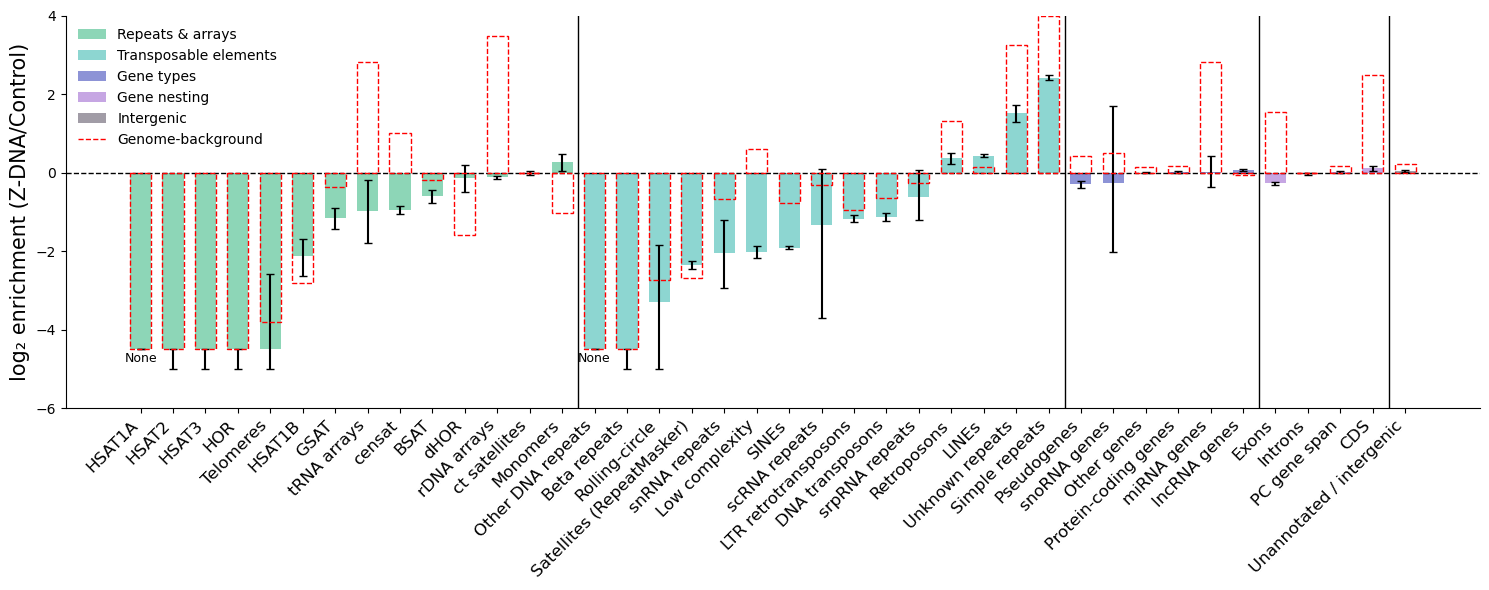


Raw Z-DNA / Control enrichment ratios:

censat_hsat1A: NA
censat_hsat2: depletion 0.00×
censat_hsat3: depletion 0.00×
censat_hor: depletion 0.01×
telomere: depletion 0.01×
censat_hsat1B: depletion 0.23×
censat_gsat: depletion 0.45×
tRNA_arrays: depletion 0.50×
censat_censat: depletion 0.52×
censat_bsat: depletion 0.66×
censat_dhor: depletion 0.91×
rDNA_arrays: depletion 0.92×
censat_ct: depletion 1.00×
censat_mon: enriched 1.20×
rmsk_DNA_other: NA
rmsk_Beta: depletion 0.01×
rmsk_RC: depletion 0.10×
rmsk_Satellite: depletion 0.20×
rmsk_snRNA: depletion 0.24×
rmsk_Low_complexity: depletion 0.25×
rmsk_SINE: depletion 0.27×
rmsk_scRNA: depletion 0.40×
rmsk_LTR: depletion 0.44×
rmsk_DNA_transposon: depletion 0.46×
rmsk_srpRNA: depletion 0.66×
rmsk_Retroposon: enriched 1.29×
rmsk_LINE: enriched 1.35×
rmsk_Unknown: enriched 2.84×
rmsk_Simple_repeat: enriched 5.35×
gene_pseudogene: depletion 0.81×
gene_snoRNA: depletion 0.83×
gene_other: depletion 1.00×
gene_protein_coding: enriched 1.01×
gen

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_TSV = (
    "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/"
    "enrichment_investigation_v2/"
    "zdna_vs_ctrl_feature_enrichment_withCI_plusGenome.tsv"
)

OUT_PNG = (
    "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/"
    "enrichment_investigation_v2/"
    "zdna_vs_ctrl_feature_enrichment_double.png"
)

# ------------------------------------------------------------
# feature order + metadata (UNCHANGED)
# ------------------------------------------------------------
FEATURE_ORDER = [
    "censat_ct","censat_censat","censat_hor","censat_dhor","censat_mon",
    "censat_hsat1A","censat_hsat1B","censat_hsat2","censat_hsat3",
    "censat_gsat","censat_bsat",
    "rDNA_arrays","tRNA_arrays","telomere",
    "rmsk_LINE","rmsk_SINE","rmsk_LTR","rmsk_Simple_repeat","rmsk_Satellite",
    "rmsk_Low_complexity","rmsk_Retroposon","rmsk_RC","rmsk_Beta",
    "rmsk_snRNA","rmsk_srpRNA","rmsk_scRNA","rmsk_Unknown",
    "rmsk_DNA_transposon","rmsk_DNA_other",
    "gene_protein_coding","gene_lncRNA","gene_pseudogene",
    "gene_miRNA","gene_snoRNA","gene_other",
    "pc_gene_span","pc_exon","pc_CDS","pc_intron",
    "UNION_annot",
]



# ------------------------------------------------------------
# FEATURE META (REWRITTEN CATEGORIES)
# ------------------------------------------------------------
FEATURE_META = {
    # repeats + arrays
    "censat_ct": ("ct satellites","repeats_arrays"),
    "censat_censat": ("censat","repeats_arrays"),
    "censat_hor": ("HOR","repeats_arrays"),
    "censat_dhor": ("dHOR","repeats_arrays"),
    "censat_mon": ("Monomers","repeats_arrays"),
    "censat_hsat1A": ("HSAT1A","repeats_arrays"),
    "censat_hsat1B": ("HSAT1B","repeats_arrays"),
    "censat_hsat2": ("HSAT2","repeats_arrays"),
    "censat_hsat3": ("HSAT3","repeats_arrays"),
    "censat_gsat": ("GSAT","repeats_arrays"),
    "censat_bsat": ("BSAT","repeats_arrays"),
    "rDNA_arrays": ("rDNA arrays","repeats_arrays"),
    "tRNA_arrays": ("tRNA arrays","repeats_arrays"),
    "telomere": ("Telomeres","repeats_arrays"),

    # transposable elements
    "rmsk_LINE": ("LINEs","transposable_elements"),
    "rmsk_SINE": ("SINEs","transposable_elements"),
    "rmsk_LTR": ("LTR retrotransposons","transposable_elements"),
    "rmsk_Simple_repeat": ("Simple repeats","transposable_elements"),
    "rmsk_Satellite": ("Satellites (RepeatMasker)","transposable_elements"),
    "rmsk_Low_complexity": ("Low complexity","transposable_elements"),
    "rmsk_Retroposon": ("Retroposons","transposable_elements"),
    "rmsk_RC": ("Rolling-circle","transposable_elements"),
    "rmsk_Beta": ("Beta repeats","transposable_elements"),
    "rmsk_snRNA": ("snRNA repeats","transposable_elements"),
    "rmsk_srpRNA": ("srpRNA repeats","transposable_elements"),
    "rmsk_scRNA": ("scRNA repeats","transposable_elements"),
    "rmsk_Unknown": ("Unknown repeats","transposable_elements"),
    "rmsk_DNA_transposon": ("DNA transposons","transposable_elements"),
    "rmsk_DNA_other": ("Other DNA repeats","transposable_elements"),

    # gene types
    "gene_protein_coding": ("Protein-coding genes","gene_types"),
    "gene_lncRNA": ("lncRNA genes","gene_types"),
    "gene_pseudogene": ("Pseudogenes","gene_types"),
    "gene_miRNA": ("miRNA genes","gene_types"),
    "gene_snoRNA": ("snoRNA genes","gene_types"),
    "gene_other": ("Other genes","gene_types"),

    # parent–child
    "pc_gene_span": ("PC gene span","parent_child"),
    "pc_exon": ("Exons","parent_child"),
    "pc_CDS": ("CDS","parent_child"),
    "pc_intron": ("Introns","parent_child"),

    # background
    "UNION_annot": ("Unannotated / intergenic","background"),
}

COLOR_MAP = {
    "repeats_arrays": "#8DD6B7",
    "transposable_elements": "#8DD6D1",
    "gene_types": "#8D93D6",
    "parent_child": "#C6A6E3",
    "background": "#A19CA6",
}

# ------------------------------------------------------------
# load + order
# ------------------------------------------------------------
df = pd.read_csv(IN_TSV, sep="\t")

rows = []
for f in FEATURE_ORDER:
    r = df[df["feature"] == f]
    if r.empty:
        raise RuntimeError(f"Missing feature: {f}")
    rows.append(r.iloc[0])

df = pd.DataFrame(rows).reset_index(drop=True)
df["pretty"] = df["feature"].map(lambda x: FEATURE_META[x][0])
df["class"]  = df["feature"].map(lambda x: FEATURE_META[x][1])
df["color"]  = df["class"].map(COLOR_MAP)
# ------------------------------------------------------------
# sort within each category by control-based enrichment
# ------------------------------------------------------------
ordered_blocks = []

for cls in df["class"].drop_duplicates():
    block = df[df["class"] == cls].copy()

    # sort ascending by ZDNA / control enrichment
    block = block.sort_values(
        by="log2_enrichment",
        ascending=True,
        na_position="first"   # push "None" to the bottom visually
    )

    ordered_blocks.append(block)

df = pd.concat(ordered_blocks, ignore_index=True)

x = np.arange(len(df))
CLASS_LABELS = {
    "repeats_arrays": "Repeats & arrays",
    "transposable_elements": "Transposable elements",
    "gene_types": "Gene types",
    "parent_child": "Gene nesting",
    "background": "Intergenic",
}

# ------------------------------------------------------------
# PLOT CONFIG
# ------------------------------------------------------------
Y_MIN = -5.0
Y_MIN_2 = -4.5
Y_MAX =  4.0
GENOME_LINEWIDTH = 1.0
OFFSET = 0.1

# ------------------------------------------------------------
# values + clipping
# ------------------------------------------------------------
y_ctrl = df["log2_enrichment"].to_numpy()
y_gen  = df["log2_genome_enrichment"].to_numpy()

y_ctrl_plot = np.where(
    np.isfinite(y_ctrl),
    np.clip(y_ctrl, Y_MIN_2, Y_MAX),
    Y_MIN_2
)

y_gen_plot = np.where(
    np.isfinite(y_gen),
    np.clip(y_gen, Y_MIN_2, Y_MAX),
    Y_MIN_2
)

# ------------------------------------------------------------
# plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))

# filled bars
# ------------------------------------------------------------
# error bars (robust to clipping)
# ------------------------------------------------------------
lo = np.clip(df["log2_lo"].to_numpy(), Y_MIN, Y_MAX)
hi = np.clip(df["log2_hi"].to_numpy(), Y_MIN, Y_MAX)

err_low = np.zeros_like(y_ctrl_plot)
err_high = np.zeros_like(y_ctrl_plot)

mask = np.isfinite(df["log2_lo"]) & np.isfinite(y_ctrl_plot)
err_low[mask] = np.maximum(0.0, y_ctrl_plot[mask] - lo[mask])

mask = np.isfinite(df["log2_hi"]) & np.isfinite(y_ctrl_plot)
err_high[mask] = np.maximum(0.0, hi[mask] - y_ctrl_plot[mask])

yerr = np.vstack([err_low, err_high])


# ------------------------------------------------------------
# filled bars
# ------------------------------------------------------------
ax.bar(
    x,
    y_ctrl_plot,
    yerr=yerr,
    width=0.65,
    capsize=3,
    color=df["color"],
    zorder=2
)


# dashed outline bars
ax.bar(
    x,
    y_gen_plot,
    width=0.65,
    facecolor="none",
    edgecolor="red",
    linestyle="--",
    linewidth=GENOME_LINEWIDTH,
    zorder=3
)

# baseline + axes
ax.axhline(0, color="black", lw=1, ls="--")
ax.set_ylim(-6, Y_MAX)
ax.set_ylabel("log₂ enrichment (Z-DNA/Control)", fontsize=15)

ax.set_xticks(x)
ax.set_xticklabels(df["pretty"], rotation=45, ha="right", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# category separators
# ------------------------------------------------------------
last = df.loc[0, "class"]
for i in range(1, len(df)):
    if df.loc[i, "class"] != last:
        ax.axvline(i - 0.5, color="black", lw=1)
        last = df.loc[i, "class"]

# ------------------------------------------------------------
# annotate missing values
# ------------------------------------------------------------
for i in range(len(df)):
    if not np.isfinite(y_ctrl[i]):
        ax.text(i, Y_MIN + OFFSET, "None",
                ha="center", va="bottom", fontsize=9, rotation=0)

    # if not np.isfinite(y_gen[i]):
    #     ax.text(i, Y_MIN + 2*OFFSET, "None",
    #             ha="center", va="bottom", fontsize=9,
    #             rotation=90, color="red")

# ------------------------------------------------------------
# legend
# ------------------------------------------------------------
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

class_handles = [
    Patch(facecolor=COLOR_MAP[k], label=CLASS_LABELS[k])
    for k in COLOR_MAP
]


semantic_handles = [
    Line2D([0], [0], color="red", lw=GENOME_LINEWIDTH, ls="--",
           label="Genome-background"),
]

ax.legend(
    handles=class_handles + semantic_handles,
    frameon=False,
    fontsize=10,
    ncol=1,
    loc="upper left"
)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=600)
plt.show()


# ------------------------------------------------------------
# print raw enrichment (observed / expected = 2^log2)
# ------------------------------------------------------------
print("\nRaw Z-DNA / Control enrichment ratios:\n")

for i, row in df.iterrows():
    log2_val = row["log2_enrichment"]

    if not np.isfinite(log2_val):
        print(f"{row['feature']}: NA")
        continue

    ratio = 2 ** log2_val

    if log2_val > 0:
        print(f"{row['feature']}: enriched {ratio:.2f}×")
    elif log2_val < 0:
        print(f"{row['feature']}: depletion {ratio:.2f}×")
    else:
        print(f"{row['feature']}: no enrichment (1.00×)")

#### zdna extreme

In [ ]:
# #!/usr/bin/env python3

# import argparse
# from pathlib import Path
# import pandas as pd
# import numpy as np
# import subprocess
# import tempfile

# # ------------------------------------------------------------
# # helpers
# # ------------------------------------------------------------
# def bed_length(path: Path) -> int:
#     df = pd.read_csv(
#         path, sep="\t", header=None, usecols=[1, 2],
#         names=["start", "end"]
#     )
#     return int((df["end"] - df["start"]).sum())


# def bed_overlap_bp(a: Path, b: Path) -> int:
#     """
#     bp overlap between BED a and BED b
#     """
#     cmd = [
#         "bedtools", "intersect",
#         "-a", str(a),
#         "-b", str(b),
#         "-wo"
#     ]
#     p = subprocess.run(cmd, capture_output=True, text=True, check=True)
#     s = 0
#     for line in p.stdout.splitlines():
#         s += int(line.split()[-1])
#     return s


# # ------------------------------------------------------------
# # main
# # ------------------------------------------------------------
# def main():
#     ap = argparse.ArgumentParser()
#     ap.add_argument("--z_extreme_bed", required=True)
#     ap.add_argument("--featdir", required=True)
#     ap.add_argument("--chrom_len_tsv", required=True)
#     ap.add_argument("--out_tsv", required=True)
#     args = ap.parse_args()

#     featdir = Path(args.featdir)
#     zbed = Path(args.z_extreme_bed)

#     # --------------------------------------------------------
#     # genome size
#     # --------------------------------------------------------
#     chrom = pd.read_csv(
#         args.chrom_len_tsv,
#         sep="\t",
#         usecols=["gcf_seq_length"]
#     )
#     GENOME_BP = chrom["gcf_seq_length"].astype(int).sum()

#     # --------------------------------------------------------
#     # total Z bp (extreme set)
#     # --------------------------------------------------------
#     Z_TOTAL_BP = bed_length(zbed)

#     if Z_TOTAL_BP == 0:
#         raise RuntimeError("Extreme Z-DNA BED has zero total bp")

#     rows = []

#     for bed in sorted(featdir.glob("*.merged.bed")):
#         feature = bed.stem.replace(".merged", "")

#         FEATURE_BP = bed_length(bed)
#         if FEATURE_BP == 0:
#             log2_genome = np.nan
#             ZF = 0
#         else:
#             ZF = bed_overlap_bp(zbed, bed)
#             ratio = (ZF / FEATURE_BP) / (Z_TOTAL_BP / GENOME_BP)
#             log2_genome = np.log2(ratio) if ratio > 0 else np.nan

#         rows.append(dict(
#             feature=feature,
#             feature_bp=FEATURE_BP,
#             overlapZ_bp=ZF,
#             totalZ_bp=Z_TOTAL_BP,
#             log2_genome_enrichment=log2_genome
#         ))

#     df = pd.DataFrame(rows)
#     df.to_csv(args.out_tsv, sep="\t", index=False)
#     print(f"[DONE] wrote {args.out_tsv}")


# if __name__ == "__main__":
#     main()



# python3 compute_genome_background_enrichment_no_control.py \
#   --z_extreme_bed /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/zdna_extreme_no_control.bed \
#   --featdir enrichment_investigation_v2 \
#   --chrom_len_tsv /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv \
#   --out_tsv enrichment_investigation_v2/zdna_extreme_genome_background.tsv


#### zdna extreme plot

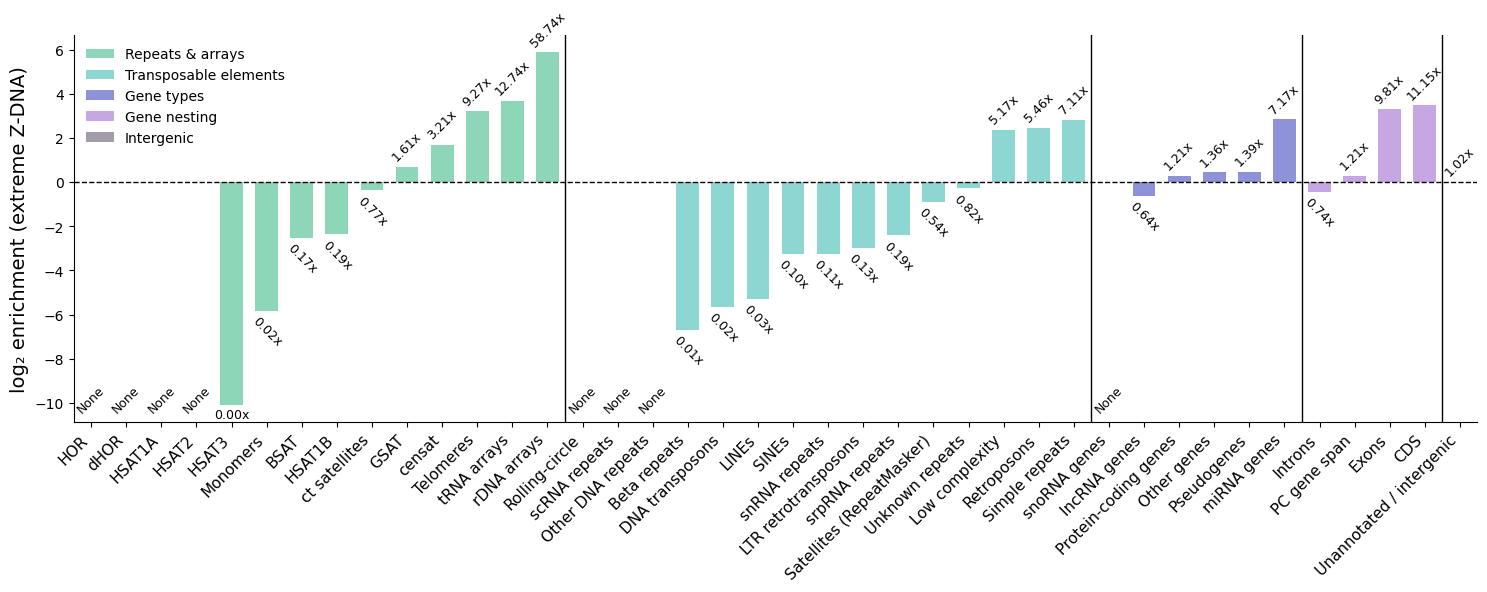

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_TSV = (
    "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/"
    "enrichment_investigation_v2/"
    "zdna_extreme_genome_background.tsv"
)

OUT_PNG = (
    "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/"
    "enrichment_investigation_v2/"
    "zdna_extreme_genome_background.png"
)

# ------------------------------------------------------------
# feature order
# ------------------------------------------------------------
FEATURE_ORDER = [
    "censat_ct","censat_censat","censat_hor","censat_dhor","censat_mon",
    "censat_hsat1A","censat_hsat1B","censat_hsat2","censat_hsat3",
    "censat_gsat","censat_bsat",
    "rDNA_arrays","tRNA_arrays","telomere",
    "rmsk_LINE","rmsk_SINE","rmsk_LTR","rmsk_Simple_repeat","rmsk_Satellite",
    "rmsk_Low_complexity","rmsk_Retroposon","rmsk_RC","rmsk_Beta",
    "rmsk_snRNA","rmsk_srpRNA","rmsk_scRNA","rmsk_Unknown",
    "rmsk_DNA_transposon","rmsk_DNA_other",
    "gene_protein_coding","gene_lncRNA","gene_pseudogene",
    "gene_miRNA","gene_snoRNA","gene_other",
    "pc_gene_span","pc_exon","pc_CDS","pc_intron",
    "UNION_annot",
]

# ------------------------------------------------------------
# metadata (same semantics as main figure)
# ------------------------------------------------------------
FEATURE_META = {
    "censat_ct": ("ct satellites","repeats_arrays"),
    "censat_censat": ("censat","repeats_arrays"),
    "censat_hor": ("HOR","repeats_arrays"),
    "censat_dhor": ("dHOR","repeats_arrays"),
    "censat_mon": ("Monomers","repeats_arrays"),
    "censat_hsat1A": ("HSAT1A","repeats_arrays"),
    "censat_hsat1B": ("HSAT1B","repeats_arrays"),
    "censat_hsat2": ("HSAT2","repeats_arrays"),
    "censat_hsat3": ("HSAT3","repeats_arrays"),
    "censat_gsat": ("GSAT","repeats_arrays"),
    "censat_bsat": ("BSAT","repeats_arrays"),
    "rDNA_arrays": ("rDNA arrays","repeats_arrays"),
    "tRNA_arrays": ("tRNA arrays","repeats_arrays"),
    "telomere": ("Telomeres","repeats_arrays"),

    "rmsk_LINE": ("LINEs","transposable_elements"),
    "rmsk_SINE": ("SINEs","transposable_elements"),
    "rmsk_LTR": ("LTR retrotransposons","transposable_elements"),
    "rmsk_Simple_repeat": ("Simple repeats","transposable_elements"),
    "rmsk_Satellite": ("Satellites (RepeatMasker)","transposable_elements"),
    "rmsk_Low_complexity": ("Low complexity","transposable_elements"),
    "rmsk_Retroposon": ("Retroposons","transposable_elements"),
    "rmsk_RC": ("Rolling-circle","transposable_elements"),
    "rmsk_Beta": ("Beta repeats","transposable_elements"),
    "rmsk_snRNA": ("snRNA repeats","transposable_elements"),
    "rmsk_srpRNA": ("srpRNA repeats","transposable_elements"),
    "rmsk_scRNA": ("scRNA repeats","transposable_elements"),
    "rmsk_Unknown": ("Unknown repeats","transposable_elements"),
    "rmsk_DNA_transposon": ("DNA transposons","transposable_elements"),
    "rmsk_DNA_other": ("Other DNA repeats","transposable_elements"),

    "gene_protein_coding": ("Protein-coding genes","gene_types"),
    "gene_lncRNA": ("lncRNA genes","gene_types"),
    "gene_pseudogene": ("Pseudogenes","gene_types"),
    "gene_miRNA": ("miRNA genes","gene_types"),
    "gene_snoRNA": ("snoRNA genes","gene_types"),
    "gene_other": ("Other genes","gene_types"),

    "pc_gene_span": ("PC gene span","parent_child"),
    "pc_exon": ("Exons","parent_child"),
    "pc_CDS": ("CDS","parent_child"),
    "pc_intron": ("Introns","parent_child"),

    "UNION_annot": ("Unannotated / intergenic","background"),
}

COLOR_MAP = {
    "repeats_arrays": "#8DD6B7",
    "transposable_elements": "#8DD6D1",
    "gene_types": "#8D93D6",
    "parent_child": "#C6A6E3",
    "background": "#A19CA6",
}

CLASS_LABELS = {
    "repeats_arrays": "Repeats & arrays",
    "transposable_elements": "Transposable elements",
    "gene_types": "Gene types",
    "parent_child": "Gene nesting",
    "background": "Intergenic",
}

# ------------------------------------------------------------
# load + order
# ------------------------------------------------------------
df = pd.read_csv(IN_TSV, sep="\t")

rows = []
for f in FEATURE_ORDER:
    r = df[df["feature"] == f]
    if r.empty:
        raise RuntimeError(f"Missing feature: {f}")
    rows.append(r.iloc[0])

df = pd.DataFrame(rows).reset_index(drop=True)
df["pretty"] = df["feature"].map(lambda x: FEATURE_META[x][0])
df["class"]  = df["feature"].map(lambda x: FEATURE_META[x][1])
df["color"]  = df["class"].map(COLOR_MAP)

# ------------------------------------------------------------
# sort within each class by genome-background enrichment
# ------------------------------------------------------------
blocks = []
for cls in df["class"].drop_duplicates():
    b = df[df["class"] == cls].copy()
    b = b.sort_values(
        by="log2_genome_enrichment",
        ascending=True,
        na_position="first"
    )
    blocks.append(b)

df = pd.concat(blocks, ignore_index=True)

x = np.arange(len(df))
y = df["log2_genome_enrichment"].to_numpy()

# ------------------------------------------------------------
# plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 6))

ax.bar(
    x,
    y,
    width=0.65,
    color=df["color"],
    zorder=2
)

ax.axhline(0, color="black", lw=1, ls="--")
ax.set_ylabel("log₂ enrichment (extreme Z-DNA)", fontsize=14)

ax.set_xticks(x)
ax.set_xticklabels(df["pretty"], rotation=45, ha="right", fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(-0.5, len(x) - 0.5)

# separators
last = df.loc[0, "class"]
for i in range(1, len(df)):
    if df.loc[i, "class"] != last:
        ax.axvline(i - 0.5, color="black", lw=1)
        last = df.loc[i, "class"]

# annotate missing
ymin = np.nanmin(y)
for i in range(len(df)):
    if not np.isfinite(y[i]):
        ax.text(
            i, ymin+1,
            "None",
            ha="center",
            va="top",
            fontsize=9,
            rotation=45
        )

# legend
from matplotlib.patches import Patch

ax.legend(
    handles=[Patch(facecolor=COLOR_MAP[k], label=CLASS_LABELS[k])
             for k in COLOR_MAP],
    frameon=False,
    fontsize=10,
    loc="upper left",
    ncol=1
)
# ------------------------------------------------------------
# annotate raw fold enrichment (unlogged)
# ------------------------------------------------------------
# ------------------------------------------------------------
# annotate raw fold enrichment (HSAT3 no rotation)
# ------------------------------------------------------------
yvals = df["log2_genome_enrichment"].to_numpy()
features = df["feature"].to_numpy()

for i, val in enumerate(yvals):

    if not np.isfinite(val):
        continue

    fold = 2 ** val
    label = f"{fold:.2f}x"

    is_hsat3 = (features[i] == "censat_hsat3")

    if val >= 0:
        ax.text(
            i,
            val + 0.15,
            label,
            ha="center",
            va="bottom",
            fontsize=9,
            rotation=0 if is_hsat3 else 45
        )
    else:
        ax.text(
            i,
            val - 0.15,
            label,
            ha="center",
            va="top",
            fontsize=9,
            rotation=0 if is_hsat3 else -45
        )



plt.tight_layout()
plt.savefig(OUT_PNG, dpi=600)
plt.show()


### Feature methylation

#### Scripts

In [ ]:
# #!/usr/bin/env python3
# import argparse
# from pathlib import Path
# from typing import Dict, Tuple, List, Optional

# import numpy as np
# import pandas as pd
# import pyranges as pr
# import pyBigWig


# # ----------------------------
# # IO
# # ----------------------------
# def read_bed3_df(path: Path) -> pd.DataFrame:
#     df = pd.read_csv(
#         path, sep="\t", header=None, usecols=[0, 1, 2],
#         names=["Chromosome", "Start", "End"],
#         dtype={"Chromosome": str, "Start": np.int64, "End": np.int64},
#     )
#     df = df[df["End"] > df["Start"]].copy()
#     df["length"] = (df["End"] - df["Start"]).astype(np.int64)
#     df.reset_index(drop=True, inplace=True)
#     return df



# def read_chrom_lengths(tsv: Path) -> Dict[str, int]:
#     x = pd.read_csv(tsv, sep="\t", usecols=["ucsc_pansn_name", "gcf_seq_length"])
#     return dict(zip(x["ucsc_pansn_name"].astype(str), x["gcf_seq_length"].astype(int)))


# def build_blocks(chrom_len: Dict[str, int], block_size: int) -> pd.DataFrame:
#     rows = []
#     bid = 0
#     for chrom, L in chrom_len.items():
#         L = int(L)
#         for s in range(0, L, block_size):
#             e = min(s + block_size, L)
#             rows.append((chrom, s, e, bid))
#             bid += 1
#     return pd.DataFrame(rows, columns=["Chromosome", "Start", "End", "block_id"])


# # ----------------------------
# # BigWig methylation
# # ----------------------------
# def bw_interval_mean(bw, chrom: str, start: int, end: int) -> float:
#     if end <= start:
#         return np.nan
#     try:
#         m = bw.stats(chrom, start, end, type="mean", exact=True)[0]
#         return float(m) if m is not None else np.nan
#     except Exception:
#         vals = bw.values(chrom, start, end, numpy=True)
#         if vals is None:
#             return np.nan
#         vals = np.asarray(vals)
#         finite = np.isfinite(vals)
#         if finite.sum() == 0:
#             return np.nan
#         return float(np.nanmean(vals[finite]))

# def bw_interval_coverage(bw, chrom: str, start: int, end: int) -> float:
#     if end <= start:
#         return np.nan
#     try:
#         cov = bw.stats(chrom, start, end, type="coverage", exact=True)[0]
#         return float(cov) if cov is not None else np.nan
#     except Exception:
#         return np.nan


# # ----------------------------
# # Overlap logic
# # ----------------------------
# def overlap_bp_table(intervals: pr.PyRanges, feature: pr.PyRanges) -> pd.DataFrame:
#     j = intervals.join(feature)
#     if j.df.empty:
#         return pd.DataFrame(columns=["idx", "Chromosome", "Start", "End", "overlap_bp"])
#     df = j.df.copy()
#     df["overlap_bp"] = (df["End"] - df["Start"]).astype(np.int64)
#     # pr.join keeps original row index as index; preserve it explicitly
#     df["idx"] = df.index.values
#     return df[["idx", "Chromosome", "Start", "End", "overlap_bp"]]


# def filter_by_overlap_fraction(intervals_df: pd.DataFrame, ov_df: pd.DataFrame, min_frac: float) -> Tuple[pd.DataFrame, pd.DataFrame]:
#     if ov_df.empty:
#         return intervals_df.iloc[0:0].copy(), ov_df

#     ov = ov_df.groupby("idx")["overlap_bp"].sum()
#     frac = ov / intervals_df.loc[ov.index, "length"]
#     keep = frac[frac >= min_frac].index

#     keep_df = intervals_df.loc[keep].copy()
#     keep_df.reset_index(drop=False, inplace=True)  # preserve original idx
#     keep_df.rename(columns={"index": "idx"}, inplace=True)
#     keep_df.set_index("idx", inplace=True)

#     ov_keep = ov_df[ov_df["idx"].isin(keep)].copy()
#     return keep_df, ov_keep


# # ----------------------------
# # Annotate methylation
# # ----------------------------
# def annotate_methylation_full(bw, intervals_df_idx: pd.DataFrame) -> pd.DataFrame:
#     rows = []
#     for idx, r in intervals_df_idx.iterrows():
#         m = bw_interval_mean(bw, r["Chromosome"], int(r["Start"]), int(r["End"]))
#         c = bw_interval_coverage(bw, r["Chromosome"], int(r["Start"]), int(r["End"]))
#         rows.append((idx, m, c))

#     out = intervals_df_idx.copy()
#     tmp = pd.DataFrame(rows, columns=["idx", "meth_mean", "cov_frac"]).set_index("idx")
#     out = out.join(tmp, how="left")
#     out["meth_mean"] = pd.to_numeric(out["meth_mean"], errors="coerce")
#     out["cov_frac"] = pd.to_numeric(out["cov_frac"], errors="coerce")
#     out = out[np.isfinite(out["meth_mean"].to_numpy())].copy()

#     return out



# def annotate_methylation_overlap_weighted(bw, intervals_df_idx: pd.DataFrame, ov_df: pd.DataFrame) -> pd.DataFrame:
#     if ov_df.empty:
#         return intervals_df_idx.iloc[0:0].assign(meth_mean=np.nan)

#     rows = []
#     for idx, g in ov_df.groupby("idx"):
#         tot = 0.0
#         wsum = 0.0
#         for _, r in g.iterrows():
#             m = bw_interval_mean(bw, str(r["Chromosome"]), int(r["Start"]), int(r["End"]))
#             if np.isfinite(m):
#                 obp = float(r["overlap_bp"])
#                 wsum += m * obp
#                 tot += obp
#         if tot > 0:
#             rows.append((idx, wsum / tot, tot))

#     mdf = pd.DataFrame(rows, columns=["idx", "meth_mean", "eff_bp"]).set_index("idx")
#     out = intervals_df_idx.join(mdf, how="inner")
#     out["meth_mean"] = pd.to_numeric(out["meth_mean"], errors="coerce")
#     out = out[np.isfinite(out["meth_mean"].to_numpy())].copy()

#     return out


# # ----------------------------
# # Effect sizes
# # ----------------------------
# def cohens_d(x: np.ndarray, y: np.ndarray) -> float:
#     x = x[np.isfinite(x)]
#     y = y[np.isfinite(y)]
#     nx, ny = len(x), len(y)
#     if nx < 2 or ny < 2:
#         return np.nan
#     vx = np.var(x, ddof=1)
#     vy = np.var(y, ddof=1)
#     sp = np.sqrt(((nx - 1) * vx + (ny - 1) * vy) / (nx + ny - 2))
#     if sp == 0:
#         return np.nan
#     return float((np.mean(x) - np.mean(y)) / sp)


# def rank_biserial_from_mwu(x: np.ndarray, y: np.ndarray, rng: np.random.Generator) -> float:
#     """
#     Rank-biserial correlation derived from Mann–Whitney U:
#       r_rb = 1 - 2U/(n_x n_y)  (for U counting x<y). With ties handled via average ranks.
#     We compute U from ranks without SciPy.
#     """
#     x = x[np.isfinite(x)]
#     y = y[np.isfinite(y)]
#     nx, ny = len(x), len(y)
#     if nx == 0 or ny == 0:
#         return np.nan

#     vals = np.concatenate([x, y])
#     # average ranks with ties
#     order = np.argsort(vals, kind="mergesort")
#     ranks = np.empty_like(order, dtype=float)
#     ranks[order] = np.arange(1, len(vals) + 1, dtype=float)

#     # tie correction: average ranks for equal values
#     sorted_vals = vals[order]
#     i = 0
#     while i < len(sorted_vals):
#         j = i + 1
#         while j < len(sorted_vals) and sorted_vals[j] == sorted_vals[i]:
#             j += 1
#         if j - i > 1:
#             avg = np.mean(ranks[order[i:j]])
#             ranks[order[i:j]] = avg
#         i = j

#     rx = np.sum(ranks[:nx])
#     # U for x: Ux = rx - nx(nx+1)/2
#     Ux = rx - nx * (nx + 1) / 2.0
#     # rank-biserial (positive means x>y)
#     rrb = 1.0 - 2.0 * Ux / (nx * ny)
#     return float(rrb)


# # ----------------------------
# # Bootstrap (chromosome-respecting via blocks)
# # ----------------------------
# def assign_blocks(df_idx: pd.DataFrame, blocks_df: pd.DataFrame) -> pd.DataFrame:
#     """Assign each interval to a block by interval start position."""
#     # Build PyRanges for join
#     pr_int = pr.PyRanges(df_idx.reset_index()[["Chromosome", "Start", "End", "idx"]])
#     pr_blk = pr.PyRanges(blocks_df[["Chromosome", "Start", "End", "block_id"]])
#     j = pr_int.join(pr_blk)
#     if j.df.empty:
#         return df_idx.iloc[0:0].copy()
#     out = j.df[["idx", "block_id"]].drop_duplicates("idx")
#     out = out.set_index("idx")
#     return df_idx.join(out, how="inner")


# def bootstrap_delta_mean_blocks(
#     z_df: pd.DataFrame,
#     c_df: pd.DataFrame,
#     rng: np.random.Generator,
#     n_boot: int = 1000,
# ) -> Tuple[float, float, float]:
#     """
#     Proper multiset bootstrap over blocks:
#       - sample blocks with replacement from the union of observed blocks
#       - include all intervals whose block_id is sampled, with multiplicity
#     Returns (low, high, boot_sd) for delta_mean.
#     """
#     if z_df.empty or c_df.empty:
#         return (np.nan, np.nan, np.nan)

#     obs = float(z_df["meth_mean"].mean() - c_df["meth_mean"].mean())

#     zb = z_df[["block_id", "meth_mean"]].copy()
#     cb = c_df[["block_id", "meth_mean"]].copy()

#     # Use blocks present in either group; keeps chrom structure comparable
#     blocks = np.unique(np.concatenate([zb["block_id"].unique(), cb["block_id"].unique()]))
#     if len(blocks) < 2:
#         return (np.nan, np.nan, np.nan)

#     # Pre-split methyl arrays per block for fast sampling
#     z_map = {bid: zb.loc[zb.block_id == bid, "meth_mean"].to_numpy() for bid in blocks}
#     c_map = {bid: cb.loc[cb.block_id == bid, "meth_mean"].to_numpy() for bid in blocks}

#     deltas = np.empty(n_boot, dtype=float)
#     for i in range(n_boot):
#         draw = rng.choice(blocks, size=len(blocks), replace=True)
    
#         z_arrays = [z_map[bid] for bid in draw if z_map[bid].size > 0]
#         c_arrays = [c_map[bid] for bid in draw if c_map[bid].size > 0]
    
#         if len(z_arrays) == 0 or len(c_arrays) == 0:
#             deltas[i] = np.nan
#             continue
    
#         z_samp = np.concatenate(z_arrays)
#         c_samp = np.concatenate(c_arrays)
    
#         deltas[i] = float(np.mean(z_samp) - np.mean(c_samp))


#     deltas = deltas[np.isfinite(deltas)]
#     if deltas.size < max(50, n_boot * 0.5):
#         # too sparse to trust
#         return (np.nan, np.nan, np.nan)

#     lo, hi = np.quantile(deltas, [0.025, 0.975])
#     return (float(lo), float(hi), float(np.std(deltas, ddof=1)))


# # ----------------------------
# # Feature analysis
# # ----------------------------
# def analyze_feature(
#     feat_name: str,
#     feat_bed: Path,
#     Z_df_raw: pd.DataFrame,
#     C_df_raw: pd.DataFrame,
#     bw,
#     blocks_df: pd.DataFrame,
#     rng: np.random.Generator,
#     mode: str,
#     min_overlap_frac: float,
#     block_size: int,
#     n_boot: int,
# ) -> pd.DataFrame:
#     feat_pr = pr.PyRanges(read_bed3_df(feat_bed))
#     Z_pr = pr.PyRanges(Z_df_raw)
#     C_pr = pr.PyRanges(C_df_raw)

#     Z_ov = overlap_bp_table(Z_pr, feat_pr)
#     C_ov = overlap_bp_table(C_pr, feat_pr)

#     # filter by overlap fraction, returning idx-indexed interval tables
#     Z_df = Z_df_raw.copy()
#     C_df = C_df_raw.copy()
#     Z_df.index.name = "idx"
#     C_df.index.name = "idx"

#     Z_keep, Z_ov_keep = filter_by_overlap_fraction(Z_df, Z_ov, min_overlap_frac)
#     C_keep, C_ov_keep = filter_by_overlap_fraction(C_df, C_ov, min_overlap_frac)

#     if mode == "full":
#         Z_ann = annotate_methylation_full(bw, Z_keep)
#         C_ann = annotate_methylation_full(bw, C_keep)
#     elif mode == "overlap":
#         Z_ann = annotate_methylation_overlap_weighted(bw, Z_keep, Z_ov_keep)
#         C_ann = annotate_methylation_overlap_weighted(bw, C_keep, C_ov_keep)
#     else:
#         raise ValueError("mode must be 'full' or 'overlap'")

#     # assign blocks for bootstrap
#     Z_blk = assign_blocks(Z_ann, blocks_df)
#     C_blk = assign_blocks(C_ann, blocks_df)

#     z = Z_blk["meth_mean"].to_numpy()
#     c = C_blk["meth_mean"].to_numpy()
#     if "cov_frac" in Z_blk.columns and "cov_frac" in C_blk.columns:
#         z_cov = Z_blk["cov_frac"].to_numpy()
#         c_cov = C_blk["cov_frac"].to_numpy()
    
#         z_cov = z_cov[np.isfinite(z_cov)]
#         c_cov = c_cov[np.isfinite(c_cov)]
    
#         Z_cov_med = float(np.median(z_cov)) if len(z_cov) else np.nan
#         C_cov_med = float(np.median(c_cov)) if len(c_cov) else np.nan
#         cov_delta_med = (
#             float(Z_cov_med - C_cov_med)
#             if np.isfinite(Z_cov_med) and np.isfinite(C_cov_med)
#             else np.nan
#         )
    
#         cov_rrb = (
#             rank_biserial_from_mwu(z_cov, c_cov, rng)
#             if len(z_cov) and len(c_cov)
#             else np.nan
#         )
#     else:
#         Z_cov_med = np.nan
#         C_cov_med = np.nan
#         cov_delta_med = np.nan
#         cov_rrb = np.nan



#     nZ = int(np.isfinite(z).sum())
#     nC = int(np.isfinite(c).sum())
#     Z_mean = float(np.mean(z)) if nZ > 0 else np.nan
#     C_mean = float(np.mean(c)) if nC > 0 else np.nan
#     delta = float(Z_mean - C_mean) if np.isfinite(Z_mean) and np.isfinite(C_mean) else np.nan

#     d = cohens_d(z, c)
#     rrb = rank_biserial_from_mwu(z, c, rng)

#     ci_lo, ci_hi, boot_sd = bootstrap_delta_mean_blocks(Z_blk, C_blk, rng, n_boot=n_boot)

#     return pd.DataFrame([dict(
#         feature=feat_name,
#         mode=mode,
#         min_overlap_frac=min_overlap_frac,
#         nZ=nZ,
#         nC=nC,
#         Z_mean=Z_mean,
#         C_mean=C_mean,
#         delta_mean=delta,
#         ci95_lo=ci_lo,
#         ci95_hi=ci_hi,
#         boot_sd=boot_sd,
#         cohens_d=d,
#         rank_biserial=rrb,
#         Z_cov_median=Z_cov_med,
#         C_cov_median=C_cov_med,
#         delta_cov_median=cov_delta_med,
#         cov_rank_biserial=cov_rrb,
#         block_size=block_size,
#         n_boot=n_boot,
#     )])

# def main():
#     ap = argparse.ArgumentParser()
#     ap.add_argument("--bw", required=True)
#     ap.add_argument("--z_bed", required=True)
#     ap.add_argument("--c_bed", required=True)
#     ap.add_argument("--featdir", required=True)
#     ap.add_argument("--chrom_len_tsv", required=True)
#     ap.add_argument("--features", nargs="+", required=True)
#     ap.add_argument("--overlap_fracs", nargs="+", default=["0.1"], help="e.g. 0.1 0.25 0.5 or 'all'")
#     ap.add_argument("--modes", nargs="+", default=["full", "overlap"], choices=["full", "overlap"])
#     ap.add_argument("--block_size", type=int, default=1_000_000)
#     ap.add_argument("--n_boot", type=int, default=1000)
#     ap.add_argument("--seed", type=int, default=42)
#     ap.add_argument("--out_tsv", required=True)
#     args = ap.parse_args()

#     if args.overlap_fracs == ["all"]:
#         overlap_fracs = [0.1, 0.25, 0.5]
#     else:
#         overlap_fracs = [float(x) for x in args.overlap_fracs]

#     rng = np.random.default_rng(args.seed)

#     Z_df = read_bed3_df(Path(args.z_bed))
#     C_df = read_bed3_df(Path(args.c_bed))

#     chrom_len = read_chrom_lengths(Path(args.chrom_len_tsv))
#     blocks_df = build_blocks(chrom_len, block_size=args.block_size)

#     bw = pyBigWig.open(args.bw)

#     out_rows = []
#     for feat in args.features:
#         bed = Path(args.featdir) / f"{feat}.merged.bed"
#         for ov in overlap_fracs:
#             for mode in args.modes:
#                 out_rows.append(
#                     analyze_feature(
#                         feat, bed, Z_df, C_df, bw, blocks_df, rng,
#                         mode=mode, min_overlap_frac=ov,
#                         block_size=args.block_size, n_boot=args.n_boot
#                     )
#                 )

#     bw.close()

#     out = pd.concat(out_rows, ignore_index=True)
#     out.to_csv(args.out_tsv, sep="\t", index=False)


# if __name__ == "__main__":
#     main()







# #!/bin/bash
# #SBATCH -J zdna_meth_effects
# #SBATCH -p gg
# #SBATCH -N 1
# #SBATCH --ntasks=1
# #SBATCH --cpus-per-task=20
# #SBATCH -t 24:00:00
# #SBATCH -o logs/zdna_meth_effects_%j.out
# #SBATCH -e logs/zdna_meth_effects_%j.err

# set -euo pipefail

# cd /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl

# mkdir -p logs
# mkdir -p tmp/meth_effect_chunks

# source /work/10906/geomeg/vista/miniconda3/etc/profile.d/conda.sh
# conda activate py_env

# BW="chm13v2.0_hg002_CpG_ont_guppy6.1.2.bw"
# ZBED="enrichment_investigation_v2/Z.sorted.bed"
# CBED="enrichment_investigation_v2/C.sorted.bed"
# FEATDIR="enrichment_investigation_v2"
# CHROMLEN="/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"

# FEATURES=(
#   gene_protein_coding
#   gene_lncRNA
#   gene_pseudogene
#   gene_miRNA
#   gene_snoRNA
#   gene_other
#   pc_gene_span
#   pc_exon
#   pc_CDS
#   pc_intron
#   censat_ct
#   censat_censat
#   censat_hor
#   censat_dhor
#   censat_mon
#   censat_hsat1A
#   censat_hsat1B
#   censat_hsat2
#   censat_hsat3
#   censat_gsat
#   censat_bsat
#   rmsk_LINE
#   rmsk_SINE
#   rmsk_LTR
#   rmsk_Simple_repeat
#   rmsk_Satellite
#   rmsk_Low_complexity
#   rmsk_Retroposon
#   rmsk_RC
#   rmsk_Beta
#   rmsk_snRNA
#   rmsk_srpRNA
#   rmsk_scRNA
#   rmsk_Unknown
#   rmsk_DNA_transposon
#   rmsk_DNA_other
#   rDNA_arrays
#   tRNA_arrays
#   telomere
#   UNION_annot
# )

# export BW ZBED CBED FEATDIR CHROMLEN

# printf "%s\n" "${FEATURES[@]}" \
# | xargs -n 1 -P 20 --no-run-if-empty bash -c '
#     feat="$1"
#     python3 zdna_feature_methyl_effects.py \
#       --bw "$BW" \
#       --z_bed "$ZBED" \
#       --c_bed "$CBED" \
#       --featdir "$FEATDIR" \
#       --chrom_len_tsv "$CHROMLEN" \
#       --features "$feat" \
#       --overlap_fracs all \
#       --modes full overlap \
#       --block_size 1000000 \
#       --n_boot 1000 \
#       --seed 42 \
#       --out_tsv "tmp/meth_effect_chunks/${feat}.tsv"
# ' _

# OUT="enrichment_investigation_v2/meth_feature_effects.tsv"
# {
#   head -n 1 tmp/meth_effect_chunks/*.tsv | head -n 1
#   cat tmp/meth_effect_chunks/*.tsv | grep -v "^feature"
# } > "$OUT"

# echo "[DONE] Wrote $OUT"








# sbatch run_zdna_feature_methyl_effects.slurm






# #!/usr/bin/env python3
# import pandas as pd
# from pathlib import Path

# # directory with per-feature outputs
# IN_DIR = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/tmp/meth_effect_chunks")
# OUT_TSV = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/enrichment_investigation_v2/meth_feature_effects.tsv")

# dfs = []

# for f in sorted(IN_DIR.glob("*.tsv")):
#     df = pd.read_csv(f, sep="\t")
#     dfs.append(df)

# if not dfs:
#     raise RuntimeError("No TSV files found to concatenate")

# out = pd.concat(dfs, ignore_index=True)
# out.to_csv(OUT_TSV, sep="\t", index=False)

# print(f"Wrote {OUT_TSV} ({len(out)} rows)")

#### depth comparison

In [13]:
#!/usr/bin/env python3
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

TSV = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/enrichment_investigation_v2/meth_feature_effects.tsv"

MODE = "full"
MIN_OVERLAP = 0.25
MIN_N = 500

df = pd.read_csv(TSV, sep="\t")

# ---------------------------------------
# filter to plotted panel
# ---------------------------------------
df = df[
    (df["mode"] == MODE) &
    (df["min_overlap_frac"] == MIN_OVERLAP) &
    (df["nZ"] >= MIN_N) &
    (df["nC"] >= MIN_N)
].copy()

if df.empty:
    raise RuntimeError("No rows after filtering")

print(f"\nFeatures retained: {len(df)}\n")

# ---------------------------------------
# basic coverage summary
# ---------------------------------------
print("Coverage median difference summary (Z - C):")
print(df["delta_cov_median"].describe())
print()

print("Coverage rank-biserial summary:")
print(df["cov_rank_biserial"].describe())
print()

# ---------------------------------------
# correlation between coverage shift and methylation shift
# ---------------------------------------
rho, p = spearmanr(df["delta_cov_median"], df["delta_mean"], nan_policy="omit")

print("Correlation between coverage shift and methylation shift:")
print(f"Spearman rho = {rho:.4f}, p = {p:.3e}")
print()

# ---------------------------------------
# flag features with notable coverage bias
# ---------------------------------------
BIAS_THRESHOLD_MED = 0.05      # 5% absolute median coverage shift
BIAS_THRESHOLD_RRB = 0.2       # moderate effect size

biased = df[
    (df["delta_cov_median"].abs() > BIAS_THRESHOLD_MED) |
    (df["cov_rank_biserial"].abs() > BIAS_THRESHOLD_RRB)
].copy()

print(f"Features exceeding bias thresholds: {len(biased)}\n")

if len(biased):
    print(
        biased[
            [
                "feature",
                "delta_cov_median",
                "cov_rank_biserial",
                "delta_mean",
                "rank_biserial"
            ]
        ].sort_values("delta_cov_median", key=np.abs, ascending=False)
    )
else:
    print("No features show substantial coverage bias.")



Features retained: 22

Coverage median difference summary (Z - C):
count    22.000000
mean      0.000958
std       0.013703
min      -0.029108
25%      -0.006781
50%       0.000000
75%       0.008569
max       0.024510
Name: delta_cov_median, dtype: float64

Coverage rank-biserial summary:
count    22.000000
mean     -0.020795
std       0.051932
min      -0.131509
25%      -0.035550
50%      -0.015702
75%       0.000274
max       0.091890
Name: cov_rank_biserial, dtype: float64

Correlation between coverage shift and methylation shift:
Spearman rho = -0.2437, p = 2.745e-01

Features exceeding bias thresholds: 0

No features show substantial coverage bias.


#### Plots

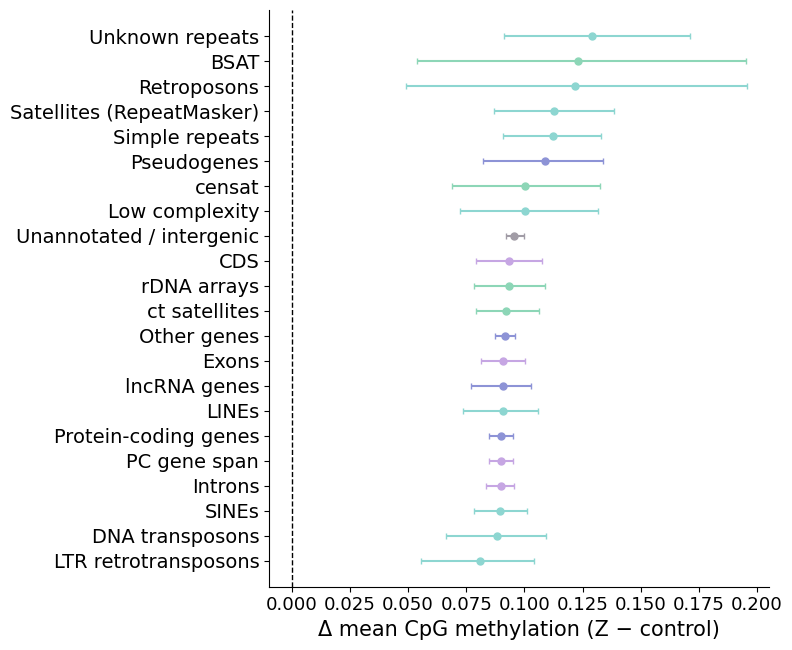

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

TSV = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/enrichment_investigation_v2/meth_feature_effects.tsv"

MODE = "full"
MIN_OVERLAP_FRAC = 0.25
MIN_N = 500

# ------------------------------------------------------------
# feature metadata (same as enrichment plots)
# ------------------------------------------------------------
FEATURE_META = {
    "censat_ct": ("ct satellites","repeats_arrays"),
    "censat_censat": ("censat","repeats_arrays"),
    "censat_hor": ("HOR","repeats_arrays"),
    "censat_dhor": ("dHOR","repeats_arrays"),
    "censat_mon": ("Monomers","repeats_arrays"),
    "censat_hsat1A": ("HSAT1A","repeats_arrays"),
    "censat_hsat1B": ("HSAT1B","repeats_arrays"),
    "censat_hsat2": ("HSAT2","repeats_arrays"),
    "censat_hsat3": ("HSAT3","repeats_arrays"),
    "censat_gsat": ("GSAT","repeats_arrays"),
    "censat_bsat": ("BSAT","repeats_arrays"),
    "rDNA_arrays": ("rDNA arrays","repeats_arrays"),
    "tRNA_arrays": ("tRNA arrays","repeats_arrays"),
    "telomere": ("Telomeres","repeats_arrays"),

    "rmsk_LINE": ("LINEs","transposable_elements"),
    "rmsk_SINE": ("SINEs","transposable_elements"),
    "rmsk_LTR": ("LTR retrotransposons","transposable_elements"),
    "rmsk_Simple_repeat": ("Simple repeats","transposable_elements"),
    "rmsk_Satellite": ("Satellites (RepeatMasker)","transposable_elements"),
    "rmsk_Low_complexity": ("Low complexity","transposable_elements"),
    "rmsk_Retroposon": ("Retroposons","transposable_elements"),
    "rmsk_RC": ("Rolling-circle","transposable_elements"),
    "rmsk_Beta": ("Beta repeats","transposable_elements"),
    "rmsk_snRNA": ("snRNA repeats","transposable_elements"),
    "rmsk_srpRNA": ("srpRNA repeats","transposable_elements"),
    "rmsk_scRNA": ("scRNA repeats","transposable_elements"),
    "rmsk_Unknown": ("Unknown repeats","transposable_elements"),
    "rmsk_DNA_transposon": ("DNA transposons","transposable_elements"),
    "rmsk_DNA_other": ("Other DNA repeats","transposable_elements"),

    "gene_protein_coding": ("Protein-coding genes","gene_types"),
    "gene_lncRNA": ("lncRNA genes","gene_types"),
    "gene_pseudogene": ("Pseudogenes","gene_types"),
    "gene_miRNA": ("miRNA genes","gene_types"),
    "gene_snoRNA": ("snoRNA genes","gene_types"),
    "gene_other": ("Other genes","gene_types"),

    "pc_gene_span": ("PC gene span","parent_child"),
    "pc_exon": ("Exons","parent_child"),
    "pc_CDS": ("CDS","parent_child"),
    "pc_intron": ("Introns","parent_child"),

    "UNION_annot": ("Unannotated / intergenic","background"),
}

COLOR_MAP = {
    "repeats_arrays": "#8DD6B7",
    "transposable_elements": "#8DD6D1",
    "gene_types": "#8D93D6",
    "parent_child": "#C6A6E3",
    "background": "#A19CA6",
}

CLASS_LABELS = {
    "repeats_arrays": "Repeats & arrays",
    "transposable_elements": "Transposable elements",
    "gene_types": "Gene types",
    "parent_child": "Gene architecture",
    "background": "Intergenic",
}

# ------------------------------------------------------------
# load + filter (UNCHANGED logic)
# ------------------------------------------------------------
df = pd.read_csv(TSV, sep="\t")

df = df[
    (df["mode"] == MODE) &
    (df["min_overlap_frac"] == MIN_OVERLAP_FRAC) &
    (df["nZ"] >= MIN_N) &
    (df["nC"] >= MIN_N)
].copy()

if df.empty:
    raise RuntimeError("No features left after filtering.")

# ------------------------------------------------------------
# annotate labels + colors
# ------------------------------------------------------------
df["pretty"] = df["feature"].map(lambda f: FEATURE_META[f][0])
df["class"]  = df["feature"].map(lambda f: FEATURE_META[f][1])
df["color"]  = df["class"].map(COLOR_MAP)

# sort by effect size
df = df.sort_values("delta_mean").reset_index(drop=True)

y = np.arange(len(df))

# ------------------------------------------------------------
# plot
# ------------------------------------------------------------

height = max(2.5, 0.3 * len(df))
fig, ax = plt.subplots(figsize=(8, height))

has_ci = df["ci95_lo"].notna() & df["ci95_hi"].notna()

# ---- CI rows (draw one by one for per-point color) ----
for i, r in df[has_ci].iterrows():
    ax.errorbar(
        r["delta_mean"],
        i,
        xerr=[
            [r["delta_mean"] - r["ci95_lo"]],
            [r["ci95_hi"] - r["delta_mean"]],
        ],
        fmt="o",
        color=r["color"],
        ecolor=r["color"],
        capsize=2,
        markersize=5,
        zorder=3,
    )


# ---- No-CI rows (points only) ----
ax.scatter(
    df.loc[~has_ci, "delta_mean"],
    df.index[~has_ci],
    color=df.loc[~has_ci, "color"],
    alpha=0.4,
    zorder=2,
)

# baseline
ax.axvline(0, color="black", lw=1, ls="--")

# axes + labels
ax.set_yticks(df.index)
ax.set_yticklabels(df["pretty"], fontsize=14)   # <-- y-label font size

ax.set_xlabel("Δ mean CpG methylation (Z − control)", fontsize=15)  # <-- x-axis title

ax.tick_params(axis="x", labelsize=13)  # <-- x tick numbers
#ax.tick_params(axis="y", labelsize=11)  # <-- y tick numbers (if not set above)


for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

# ------------------------------------------------------------
# legend (only categories present)
# ------------------------------------------------------------
from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLOR_MAP[c],
        label=CLASS_LABELS[c],
        markersize=6,
    )
    for c in df["class"].unique()
]

plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/enrichment_investigation_v2/meth_feature_colored.png",dpi=600)
plt.show()


### TSS/TES

#### scripts

In [ ]:
# #!/usr/bin/env python3
# """
# Compute Z-DNA / control occupancy around TSS and TES for CDS-overlapping genes.

# Inputs:
#   --gff       Liftoff GFF3 (.gff3.gz)
#   --zdna      Z-DNA BED (0-based, half-open)
#   --ctrl      Control BED (0-based, half-open)
#   --outdir    Output directory
#   --w         Window radius (default 150 -> 301 columns)
#   --gzip      If set, write .tsv.gz

# Outputs (4 files):
#   zdna_TSS.tsv(.gz)   rows=genes, cols=pos_-150..pos_+150 (0/1)
#   zdna_TES.tsv(.gz)
#   ctrl_TSS.tsv(.gz)
#   ctrl_TES.tsv(.gz)

# Important conventions:
# - GFF coordinates converted to 0-based half-open:
#     Start0 = start_1based - 1
#     End0   = end_1based
# - Anchors:
#     TSS: plus strand -> Start0 ; minus strand -> End0-1
#     TES: plus strand -> End0-1 ; minus strand -> Start0
# - Relative axis is always transcription-oriented:
#     plus: genomic_pos = anchor + rel
#     minus: genomic_pos = anchor - rel
# """

# import argparse
# import gzip
# import re
# from pathlib import Path

# import numpy as np
# import pandas as pd
# import pyranges as pr


# def parse_gff_attrs(attr: str) -> dict:
#     d = {}
#     for part in attr.split(";"):
#         if "=" in part:
#             k, v = part.split("=", 1)
#             d[k] = v
#     return d


# def load_genes_and_cds(gff_path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
#     # Minimal GFF parser: chromosome, feature, start, end, strand, attributes
#     rows = []
#     with gzip.open(gff_path, "rt") if gff_path.endswith(".gz") else open(gff_path, "r") as fh:
#         for line in fh:
#             if not line or line.startswith("#"):
#                 continue
#             f = line.rstrip("\n").split("\t")
#             if len(f) < 9:
#                 continue
#             chrom, source, feature, start, end, score, strand, phase, attrs = f
#             if feature not in {"gene", "CDS"}:
#                 continue
#             start_i = int(start)
#             end_i = int(end)
#             rows.append((chrom, feature, start_i, end_i, strand, attrs))

#     df = pd.DataFrame(rows, columns=["Chromosome", "Feature", "Start1", "End1", "Strand", "Attributes"])
#     if df.empty:
#         return pd.DataFrame(), pd.DataFrame()

#     # Convert to 0-based half-open for geometry with BEDs
#     df["Start"] = df["Start1"].astype(np.int64) - 1
#     df["End"] = df["End1"].astype(np.int64)

#     genes = df[df["Feature"] == "gene"].copy()
#     cds = df[df["Feature"] == "CDS"].copy()

#     # Extract GeneID from ID=... for genes. If missing, drop (better than silent garbage).
#     gids = []
#     for a in genes["Attributes"].tolist():
#         ad = parse_gff_attrs(a)
#         gid = ad.get("ID", "")
#         gids.append(gid)
#     genes["GeneID"] = gids
#     genes = genes[genes["GeneID"].astype(bool)].copy()

#     # Keep only the required columns
#     genes = genes[["Chromosome", "Start", "End", "Strand", "GeneID"]].copy()
#     cds = cds[["Chromosome", "Start", "End"]].copy()

#     # Sanity
#     genes = genes[genes["End"] > genes["Start"]].copy()
#     cds = cds[cds["End"] > cds["Start"]].copy()

#     return genes, cds


# def read_bed3(path: str) -> pd.DataFrame:
#     # Accept 3+ columns; keep first 3; enforce int
#     df = pd.read_csv(path, sep="\t", header=None, comment="#", dtype={0: str})
#     if df.shape[1] < 3:
#         raise ValueError(f"{path} has <3 columns")
#     df = df.iloc[:, :3].copy()
#     df.columns = ["Chromosome", "Start", "End"]
#     df["Start"] = df["Start"].astype(np.int64)
#     df["End"] = df["End"].astype(np.int64)
#     df = df[df["End"] > df["Start"]].copy()
#     return df


# def filter_genes_with_any_cds(genes: pd.DataFrame, cds: pd.DataFrame) -> pd.DataFrame:
#     if genes.empty:
#         return genes
#     if cds.empty:
#         # No CDS in annotation -> nothing passes
#         return genes.iloc[0:0].copy()

#     pr_g = pr.PyRanges(genes[["Chromosome", "Start", "End", "Strand", "GeneID"]])
#     pr_c = pr.PyRanges(cds[["Chromosome", "Start", "End"]])
#     ov = pr_g.join(pr_c).df  # genes that overlap at least one CDS interval
#     if ov.empty:
#         return genes.iloc[0:0].copy()

#     keep = ov["GeneID"].drop_duplicates()
#     return genes[genes["GeneID"].isin(set(keep))].copy()


# def build_windows(genes: pd.DataFrame, w: int, anchor: str) -> pd.DataFrame:
#     # anchor in {"TSS","TES"}
#     plus = (genes["Strand"].to_numpy() == "+")

#     start0 = genes["Start"].to_numpy(np.int64)
#     end0 = genes["End"].to_numpy(np.int64)
#     # Anchor base is a single genomic base coordinate in 0-based space
#     tss_anchor = np.where(plus, start0, end0 - 1)
#     tes_anchor = np.where(plus, end0 - 1, start0)

#     if anchor == "TSS":
#         a = tss_anchor
#     elif anchor == "TES":
#         a = tes_anchor
#     else:
#         raise ValueError("anchor must be TSS or TES")

#     win_start = a - w
#     win_end = a + w + 1  # half-open
#     # clamp at 0 to avoid negatives
#     win_start = np.maximum(win_start, 0)

#     out = pd.DataFrame({
#         "Chromosome": genes["Chromosome"].to_numpy(),
#         "Start": win_start.astype(np.int64),
#         "End": win_end.astype(np.int64),
#         "GeneID": genes["GeneID"].to_numpy(),
#         "Strand": genes["Strand"].to_numpy(),
#         "Anchor": anchor,
#         "AnchorPos": a.astype(np.int64),
#     })
#     out = out[out["End"] > out["Start"]].copy()
#     return out


# def overlaps_to_rel_ranges(ov: pd.DataFrame, w: int) -> pd.DataFrame:
#     """
#     Convert overlap intervals to [a,b) in relative index space 0..(2w).
#     ov must include: Start, End, Start_b, End_b, GeneID, Strand, AnchorPos
#     where (Start,End) is the window interval and (Start_b,End_b) is the bed interval.
#     """
#     if ov.empty:
#         return pd.DataFrame(columns=["GeneID", "a", "b"])

#     s_win = ov["Start"].to_numpy(np.int64)
#     e_win = ov["End"].to_numpy(np.int64)
#     s_b = ov["Start_b"].to_numpy(np.int64)
#     e_b = ov["End_b"].to_numpy(np.int64)

#     o_s = np.maximum(s_win, s_b)
#     o_e = np.minimum(e_win, e_b)

#     anchor = ov["AnchorPos"].to_numpy(np.int64)
#     strand = ov["Strand"].to_numpy(str)

#     # Convert to transcription-oriented relative coordinates
#     # plus: rel = pos - anchor
#     # minus: rel = anchor - pos  (so upstream is negative, downstream positive in transcription direction)
#     rel_a = o_s - anchor
#     rel_b = o_e - anchor

#     neg = (strand == "-")
#     # For minus, flip axis and preserve half-open: [o_s,o_e) becomes [anchor-o_e, anchor-o_s)
#     rel_a[neg], rel_b[neg] = (anchor[neg] - o_e[neg]), (anchor[neg] - o_s[neg])

#     # Clip to [-w, w+1)
#     rel_a = np.maximum(rel_a, -w)
#     rel_b = np.minimum(rel_b,  w + 1)

#     keep = rel_b > rel_a
#     if not np.any(keep):
#         return pd.DataFrame(columns=["GeneID", "a", "b"])

#     a_idx = (rel_a[keep] + w).astype(np.int32)
#     b_idx = (rel_b[keep] + w).astype(np.int32)

#     return pd.DataFrame({
#         "GeneID": ov.loc[keep, "GeneID"].to_numpy(),
#         "a": a_idx,
#         "b": b_idx,
#     })


# def build_gene_matrix(ranges: pd.DataFrame, gene_ids: np.ndarray, w: int) -> pd.DataFrame:
#     """
#     For each gene, merge its [a,b) ranges and output a 0/1 vector length 2w+1.
#     """
#     L = 2 * w + 1
#     cols = [f"pos_{p:+d}" for p in range(-w, w + 1)]

#     # Prepare output array
#     mat = np.zeros((gene_ids.shape[0], L), dtype=np.uint8)
#     gene_index = {g: i for i, g in enumerate(gene_ids)}

#     if ranges.empty:
#         return pd.DataFrame(mat, index=gene_ids, columns=cols).reset_index(names="GeneID")

#     # Group by GeneID and fill
#     for gid, sub in ranges.groupby("GeneID", sort=False):
#         if gid not in gene_index:
#             continue
#         i = gene_index[gid]
#         a = sub["a"].to_numpy(np.int32)
#         b = sub["b"].to_numpy(np.int32)
#         order = np.argsort(a, kind="mergesort")
#         a = a[order]
#         b = b[order]

#         # merge
#         merged = []
#         cur_a = cur_b = None
#         for ai, bi in zip(a, b):
#             ai = int(ai); bi = int(bi)
#             if cur_a is None:
#                 cur_a, cur_b = ai, bi
#             elif ai <= cur_b:
#                 cur_b = max(cur_b, bi)
#             else:
#                 merged.append((cur_a, cur_b))
#                 cur_a, cur_b = ai, bi
#         if cur_a is not None:
#             merged.append((cur_a, cur_b))

#         diff = np.zeros(L + 1, dtype=np.int32)
#         for ai, bi in merged:
#             if ai < 0: ai = 0
#             if bi > L: bi = L
#             if bi <= ai:
#                 continue
#             diff[ai] += 1
#             diff[bi] -= 1

#         mat[i, :] = (np.cumsum(diff[:-1]) > 0).astype(np.uint8)

#     out = pd.DataFrame(mat, index=gene_ids, columns=cols).reset_index(names="GeneID")
#     return out


# def compute_anchor_matrix(genes: pd.DataFrame, bed_df: pd.DataFrame, w: int, anchor: str) -> pd.DataFrame:
#     win = build_windows(genes, w=w, anchor=anchor)
#     pr_win = pr.PyRanges(win[["Chromosome", "Start", "End", "Strand", "GeneID", "Anchor", "AnchorPos"]])

#     pr_bed = pr.PyRanges(bed_df[["Chromosome", "Start", "End"]])
#     ov = pr_win.join(pr_bed, suffix="_b").df if len(pr_bed) else pd.DataFrame()

#     rel = overlaps_to_rel_ranges(ov, w=w)
#     gene_ids = genes["GeneID"].to_numpy()
#     return build_gene_matrix(rel, gene_ids=gene_ids, w=w)


# def write_tsv(df: pd.DataFrame, out_path: Path, gzip_out: bool) -> None:
#     if gzip_out:
#         with gzip.open(out_path.with_suffix(out_path.suffix + ".gz"), "wt") as fh:
#             df.to_csv(fh, sep="\t", index=False)
#     else:
#         df.to_csv(out_path, sep="\t", index=False)


# def main():
#     ap = argparse.ArgumentParser()
#     ap.add_argument("--gff", required=True, help="Liftoff GFF3 (.gff3 or .gff3.gz)")
#     ap.add_argument("--zdna", required=True, help="Z-DNA BED (0-based half-open)")
#     ap.add_argument("--ctrl", required=True, help="Control BED (0-based half-open)")
#     ap.add_argument("--outdir", required=True, help="Output directory")
#     ap.add_argument("--w", type=int, default=150, help="Window radius (default 150 => 301 columns)")
#     ap.add_argument("--gzip", action="store_true", help="Write .tsv.gz instead of .tsv")
#     args = ap.parse_args()

#     outdir = Path(args.outdir)
#     outdir.mkdir(parents=True, exist_ok=True)

#     genes, cds = load_genes_and_cds(args.gff)
#     if genes.empty:
#         raise SystemExit("No genes found in GFF.")
#     if cds.empty:
#         raise SystemExit("No CDS found in GFF; cannot filter to CDS-overlapping genes.")

#     genes = filter_genes_with_any_cds(genes, cds)
#     if genes.empty:
#         raise SystemExit("No genes overlap any CDS intervals (coordinate-based).")

#     # Stable ordering
#     genes = genes.sort_values(["Chromosome", "Start", "End", "GeneID"], kind="mergesort").reset_index(drop=True)

#     zdna = read_bed3(args.zdna)
#     ctrl = read_bed3(args.ctrl)

#     # Compute 4 matrices
#     zdna_tss = compute_anchor_matrix(genes, zdna, w=args.w, anchor="TSS")
#     zdna_tes = compute_anchor_matrix(genes, zdna, w=args.w, anchor="TES")
#     ctrl_tss = compute_anchor_matrix(genes, ctrl, w=args.w, anchor="TSS")
#     ctrl_tes = compute_anchor_matrix(genes, ctrl, w=args.w, anchor="TES")

#     # Write
#     write_tsv(zdna_tss, outdir / "zdna_TSS.tsv", args.gzip)
#     write_tsv(zdna_tes, outdir / "zdna_TES.tsv", args.gzip)
#     write_tsv(ctrl_tss, outdir / "zdna_ctrl_TSS.tsv", args.gzip)
#     write_tsv(ctrl_tes, outdir / "zdna_ctrl_TES.tsv", args.gzip)

#     print("Done.")
#     print(f"Genes used (CDS-overlapping): {genes['GeneID'].nunique()}")
#     print(f"Window: -{args.w}..+{args.w} (301 columns if w=150)")
#     print(f"Outputs in: {outdir}")


# if __name__ == "__main__":
#     main()



python3 zdna_tss_tes_matrix.py \
  --gff chm13v2.0_RefSeq_Liftoff_v5.2.gff3.gz \
  --zdna zdna.bed \
  --ctrl zdna_ctrl.bed \
  --outdir /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/tss_tes_matrices \
  --w 250







# #!/usr/bin/env bash
# set -euo pipefail

# # ------------------
# # Paths
# # ------------------
# BASE="/work/10906/geomeg/vista/pangenomes_zdna"

# GFF="chm13v2.0_RefSeq_Liftoff_v5.2.gff3.gz"

# ZDNA_STD="${BASE}/zdna.bed"
# CTRL_STD="${BASE}/zdna_ctrl.bed"
# ZDNA_EXTREME="${BASE}/tmp/marbl/zdna_extreme_no_control.bed"

# OUTBASE="${BASE}/tmp/marbl"
# W=250

# SCRIPT="zdna_tss_tes_matrix.py"

# # ------------------
# # 1) Standard Z-DNA vs control (MAIN FIGURES)
# # ------------------
# python3 ${SCRIPT} \
#   --gff ${GFF} \
#   --zdna ${ZDNA_STD} \
#   --ctrl ${CTRL_STD} \
#   --outdir ${OUTBASE}/tss_tes_standard \
#   --w ${W}

# # ------------------
# # 2) Extreme Z-DNA (NO CONTROL) – Supplementary
# # ------------------
# python3 ${SCRIPT} \
#   --gff ${GFF} \
#   --zdna ${ZDNA_EXTREME} \
#   --ctrl ${CTRL_STD} \
#   --outdir ${OUTBASE}/tss_tes_extreme \
#   --w ${W}


# echo "[OK] All TSS/TES analyses completed"



# chmod +x run_all_tss_tes.sh
# ./run_all_tss_tes.sh

#### main tss/tes plots

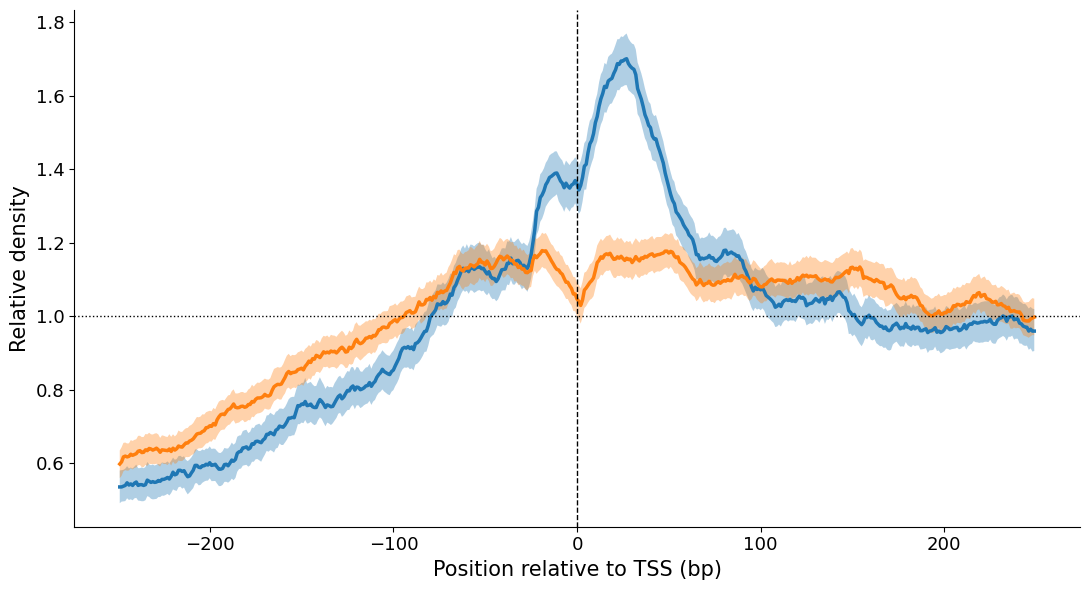

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/tss_tes_profiles_plots/zdna_profile_TSS.png


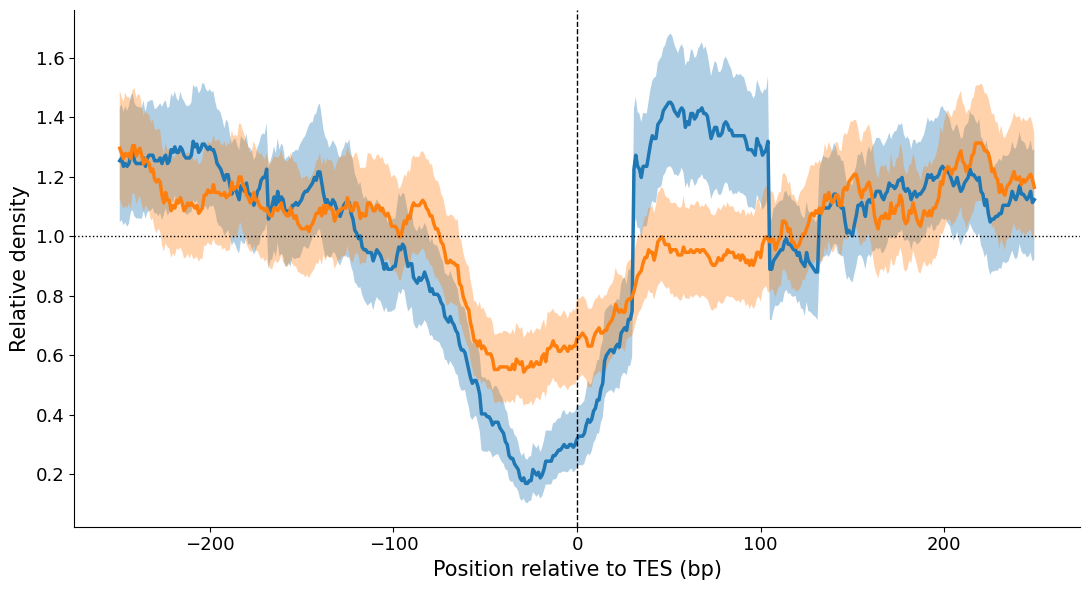

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/tss_tes_profiles_plots/zdna_profile_TES.png


In [23]:
import numpy as np

def bootstrap_mean_rows_norm(mat, n_boot=500, seed=42, clip=1):
    """
    mat: (n_genes, n_positions)
    clip: number of bins to drop from each end (default 1)
    """
    rng = np.random.default_rng(seed)
    n = mat.shape[0]

    # clip edges
    mat_c = mat[:, clip:-clip]

    mean = mat_c.mean(axis=0)
    mean_norm = mean / mean.mean()

    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v = mat_c[idx].mean(axis=0)
        m = v.mean()
        boots.append(v / m if m else np.full_like(v, np.nan))

    boots = np.stack(boots)
    lo = np.nanpercentile(boots, 2.5, axis=0)
    hi = np.nanpercentile(boots, 97.5, axis=0)

    return mean_norm, lo, hi

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
INDIR = Path(f"{BASE}/tmp/marbl/tss_tes_matrices")
OUTDIR = Path(f"{BASE}/tss_tes_profiles_plots")
OUTDIR.mkdir(exist_ok=True)

N_BOOTS = 500
LABEL_FONTSIZE = 15
TICK_FONTSIZE  = 13
TITLE_FONTSIZE = 16

def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def bootstrap_mean_rows(mat, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    n = mat.shape[0]
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        boots.append(mat[idx].mean(axis=0))
    boots = np.stack(boots)
    return (
        mat.mean(axis=0),
        np.percentile(boots, 2.5, axis=0),
        np.percentile(boots, 97.5, axis=0),
    )

def plot_anchor(anchor):
    zdna = pd.read_csv(INDIR / f"zdna_{anchor}.tsv", sep="\t")
    ctrl = pd.read_csv(INDIR / f"zdna_ctrl_{anchor}.tsv", sep="\t")

    cols = [c for c in zdna.columns if c.startswith("pos_")]
    offsets = np.array([int(c.split("_")[1]) for c in cols])

    Z = zdna[cols].to_numpy(dtype=float)
    C = ctrl[cols].to_numpy(dtype=float)

    # clip first and last bin
    CLIP = 1
    offsets_c = offsets[CLIP:-CLIP]

    Z_mean, Z_lo, Z_hi = bootstrap_mean_rows_norm(Z, N_BOOTS, clip=CLIP)
    C_mean, C_lo, C_hi = bootstrap_mean_rows_norm(C, N_BOOTS, clip=CLIP)

    plt.figure(figsize=(11, 6))

    plt.plot(offsets_c, Z_mean, lw=2.5, label="Z-DNA")
    plt.fill_between(offsets_c, Z_lo, Z_hi, alpha=0.35)

    plt.plot(offsets_c, C_mean, lw=2.5, label="Control")
    plt.fill_between(offsets_c, C_lo, C_hi, alpha=0.35)

    plt.axvline(0, ls="--", color="black", lw=1)
    plt.axhline(1, ls=":", color="black", lw=1)

    plt.xlabel(f"Position relative to {anchor} (bp)", fontsize=LABEL_FONTSIZE)
    plt.ylabel("Relative density", fontsize=LABEL_FONTSIZE)
    plt.tick_params(labelsize=TICK_FONTSIZE)
    despine(plt.gca())
    #plt.legend(frameon=False)

    plt.tight_layout()
    out = OUTDIR / f"zdna_profile_{anchor}.png"
    plt.savefig(out, dpi=600)
    plt.show()
    print(f"[OK] Wrote {out}")

for anchor in ("TSS", "TES"):
    plot_anchor(anchor)

#### + extreme plot

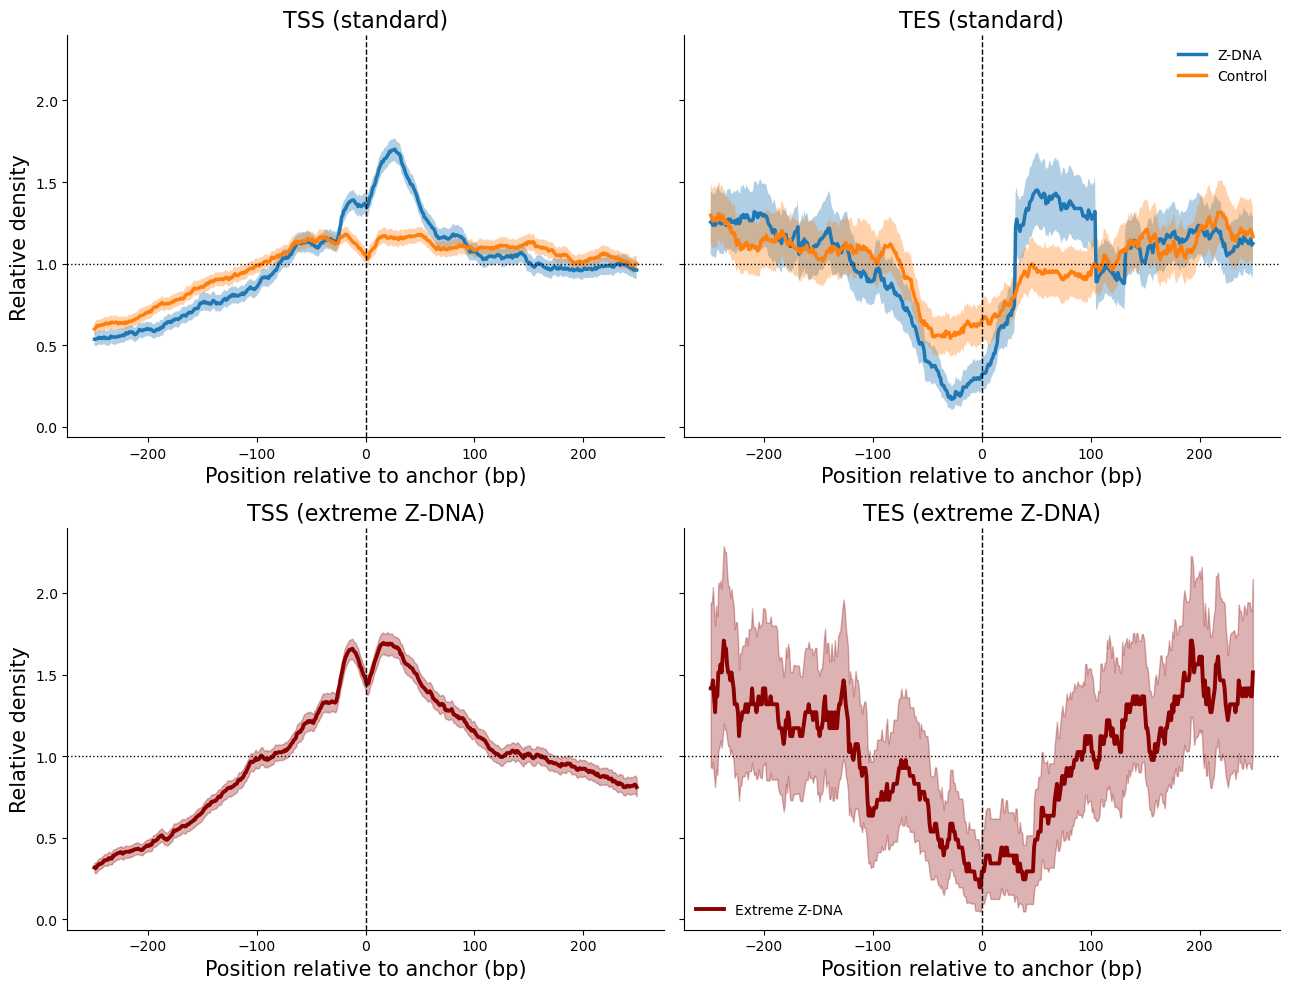

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/tss_tes_profiles_plots/zdna_TSS_TES_standard_vs_extreme.png


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------
# Paths
# ------------------
BASE = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl"

STD_DIR = Path(f"{BASE}/tss_tes_standard")
EXT_DIR = Path(f"{BASE}/tss_tes_extreme")

OUTDIR = Path("/work/10906/geomeg/vista/pangenomes_zdna/tss_tes_profiles_plots")
OUTDIR.mkdir(exist_ok=True)

# ------------------
# Parameters
# ------------------
N_BOOTS = 500
CLIP = 1

LABEL_FONTSIZE = 15
TICK_FONTSIZE  = 13
TITLE_FONTSIZE = 16

# ------------------
# Utilities
# ------------------
def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def bootstrap_mean_rows_norm(mat, n_boot=500, seed=42, clip=1):
    rng = np.random.default_rng(seed)
    n = mat.shape[0]

    mat_c = mat[:, clip:-clip]

    mean = mat_c.mean(axis=0)
    mean_norm = mean / mean.mean()

    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v = mat_c[idx].mean(axis=0)
        m = v.mean()
        boots.append(v / m if m else np.full_like(v, np.nan))

    boots = np.stack(boots)
    lo = np.nanpercentile(boots, 2.5, axis=0)
    hi = np.nanpercentile(boots, 97.5, axis=0)

    return mean_norm, lo, hi

# ------------------
# Plotting helpers
# ------------------
def plot_standard(ax, anchor):
    zdna = pd.read_csv(STD_DIR / f"zdna_{anchor}.tsv", sep="\t")
    ctrl = pd.read_csv(STD_DIR / f"zdna_ctrl_{anchor}.tsv", sep="\t")

    cols = [c for c in zdna.columns if c.startswith("pos_")]
    offsets = np.array([int(c.split("_")[1]) for c in cols])
    offsets_c = offsets[CLIP:-CLIP]

    Z = zdna[cols].to_numpy(float)
    C = ctrl[cols].to_numpy(float)

    Zm, Zlo, Zhi = bootstrap_mean_rows_norm(Z, N_BOOTS, clip=CLIP)
    Cm, Clo, Chi = bootstrap_mean_rows_norm(C, N_BOOTS, clip=CLIP)

    ax.plot(offsets_c, Zm, lw=2.5, label="Z-DNA")
    ax.fill_between(offsets_c, Zlo, Zhi, alpha=0.35)

    ax.plot(offsets_c, Cm, lw=2.5, label="Control")
    ax.fill_between(offsets_c, Clo, Chi, alpha=0.35)

    ax.axvline(0, ls="--", color="black", lw=1)
    ax.axhline(1, ls=":", color="black", lw=1)

    ax.set_title(f"{anchor} (standard)", fontsize=TITLE_FONTSIZE)
    ax.set_xlabel("Position relative to anchor (bp)", fontsize=LABEL_FONTSIZE)
    despine(ax)

def plot_extreme(ax, anchor):
    zdna = pd.read_csv(EXT_DIR / f"zdna_{anchor}.tsv", sep="\t")

    cols = [c for c in zdna.columns if c.startswith("pos_")]
    offsets = np.array([int(c.split("_")[1]) for c in cols])
    offsets_c = offsets[CLIP:-CLIP]

    Z = zdna[cols].to_numpy(float)

    Zm, Zlo, Zhi = bootstrap_mean_rows_norm(Z, N_BOOTS, clip=CLIP)

    ax.plot(
        offsets_c,
        Zm,
        lw=2.8,
        color="darkred",
        label="Extreme Z-DNA"
    )
    ax.fill_between(offsets_c, Zlo, Zhi, alpha=0.30, color="darkred")

    ax.axvline(0, ls="--", color="black", lw=1)
    ax.axhline(1, ls=":", color="black", lw=1)

    ax.set_title(f"{anchor} (extreme Z-DNA)", fontsize=TITLE_FONTSIZE)
    ax.set_xlabel("Position relative to anchor (bp)", fontsize=LABEL_FONTSIZE)
    despine(ax)

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharey=True)

plot_standard(axes[0, 0], "TSS")
plot_standard(axes[0, 1], "TES")

plot_extreme(axes[1, 0], "TSS")
plot_extreme(axes[1, 1], "TES")

axes[0, 0].set_ylabel("Relative density", fontsize=LABEL_FONTSIZE)
axes[1, 0].set_ylabel("Relative density", fontsize=LABEL_FONTSIZE)

axes[0, 1].legend(frameon=False)
axes[1, 1].legend(frameon=False)

plt.tight_layout()

out = OUTDIR / "zdna_TSS_TES_standard_vs_extreme.png"
plt.savefig(out, dpi=600)
plt.show()

print(f"[OK] Wrote {out}")

### Introns and splice sites

#### scripts

In [ ]:
# #!/usr/bin/env python3
# """
# Compute Z-DNA / control occupancy around splice sites (donor / acceptor).

# Anchors:
# - BED6 splice sites
# - Anchor base:
#     plus strand  -> Start
#     minus strand -> End - 1
# - Relative axis is transcription-oriented.

# Outputs:
# - zdna_splice_sites.tsv
# - ctrl_splice_sites.tsv
# (rows = splice sites, cols = pos_-w .. pos_+w)
# """

# import argparse
# import numpy as np
# import pandas as pd
# import pyranges as pr
# from pathlib import Path

# def read_bed3(path):
#     df = pd.read_csv(path, sep="\t", header=None, comment="#", dtype={0: str})
#     if df.shape[1] < 3:
#         raise ValueError(f"{path} has <3 columns (expected BED3+)")
#     df = df.iloc[:, :3].copy()
#     df.columns = ["Chromosome", "Start", "End"]
#     df["Start"] = df["Start"].astype(np.int64)
#     df["End"] = df["End"].astype(np.int64)
#     df = df[df["End"] > df["Start"]].copy()
#     return df


# def read_bed6(path):
#     df = pd.read_csv(path, sep="\t", header=None, comment="#")
#     if df.shape[1] < 6:
#         raise ValueError("Expected BED6")
#     df = df.iloc[:, :6]
#     df.columns = ["Chromosome", "Start", "End", "Name", "Score", "Strand"]
#     df["Start"] = df["Start"].astype(np.int64)
#     df["End"] = df["End"].astype(np.int64)
#     df = df[df["End"] > df["Start"]].copy()
#     return df

# def build_windows(sites, w):
#     plus = (sites["Strand"].to_numpy() == "+")
#     start = sites["Start"].to_numpy()
#     end = sites["End"].to_numpy()

#     anchor = np.where(plus, start, end - 1)
#     win_start = np.maximum(anchor - w, 0)
#     win_end = anchor + w + 1

#     out = pd.DataFrame({
#         "Chromosome": sites["Chromosome"].to_numpy(),
#         "Start": win_start,
#         "End": win_end,
#         "SiteID": sites["SiteID"].to_numpy(),
#         "Strand": sites["Strand"].to_numpy(),
#         "AnchorPos": anchor,
#     })
#     return out[out["End"] > out["Start"]].copy()

# def overlaps_to_rel_ranges(ov, w):
#     if ov.empty:
#         return pd.DataFrame(columns=["SiteID", "a", "b"])

#     s_win = ov["Start"].to_numpy()
#     e_win = ov["End"].to_numpy()
#     s_b = ov["Start_b"].to_numpy()
#     e_b = ov["End_b"].to_numpy()

#     o_s = np.maximum(s_win, s_b)
#     o_e = np.minimum(e_win, e_b)

#     anchor = ov["AnchorPos"].to_numpy()
#     strand = ov["Strand"].to_numpy()

#     rel_a = o_s - anchor
#     rel_b = o_e - anchor

#     neg = strand == "-"
#     rel_a[neg], rel_b[neg] = (anchor[neg] - o_e[neg]), (anchor[neg] - o_s[neg])

#     rel_a = np.maximum(rel_a, -w)
#     rel_b = np.minimum(rel_b,  w + 1)

#     keep = rel_b > rel_a
#     a = (rel_a[keep] + w).astype(np.int32)
#     b = (rel_b[keep] + w).astype(np.int32)

#     return pd.DataFrame({
#         "SiteID": ov.loc[keep, "SiteID"].to_numpy(),
#         "a": a,
#         "b": b,
#     })

# def build_matrix(ranges, site_ids, w):
#     L = 2 * w + 1
#     mat = np.zeros((len(site_ids), L), dtype=np.uint8)
#     idx = {sid: i for i, sid in enumerate(site_ids)}

#     for sid, sub in ranges.groupby("SiteID", sort=False):
#         i = idx[sid]
#         diff = np.zeros(L + 1, dtype=np.int32)
#         for a, b in zip(sub["a"], sub["b"]):
#             diff[a] += 1
#             diff[b] -= 1
#         mat[i] = (np.cumsum(diff[:-1]) > 0).astype(np.uint8)

#     cols = [f"pos_{p:+d}" for p in range(-w, w + 1)]
#     return pd.DataFrame(mat, index=site_ids, columns=cols).reset_index(names="SiteID")

# def compute_matrix(sites, bed, w):
#     win = build_windows(sites, w)
#     pr_win = pr.PyRanges(win)
#     pr_bed = pr.PyRanges(bed[["Chromosome", "Start", "End"]])
#     ov = pr_win.join(pr_bed, suffix="_b").df if len(pr_bed) else pd.DataFrame()
#     rel = overlaps_to_rel_ranges(ov, w)
#     return build_matrix(rel, sites["SiteID"].to_numpy(), w)

# def main():
#     ap = argparse.ArgumentParser()
#     ap.add_argument("--sites", required=True, help="splice sites BED6")
#     ap.add_argument("--zdna", required=True)
#     ap.add_argument("--ctrl", required=True)
#     ap.add_argument("--outdir", required=True)
#     ap.add_argument("--w", type=int, default=150)
#     args = ap.parse_args()

#     outdir = Path(args.outdir)
#     outdir.mkdir(parents=True, exist_ok=True)

#     sites = read_bed6(args.sites)
#     sites["SiteID"] = np.arange(len(sites), dtype=np.int64)

#     zdna = read_bed3(args.zdna)
#     ctrl = read_bed3(args.ctrl)


#     Z = compute_matrix(sites, zdna, args.w)
#     C = compute_matrix(sites, ctrl, args.w)

#     Z.to_csv(outdir / "zdna_splice_sites.tsv", sep="\t", index=False)
#     C.to_csv(outdir / "ctrl_splice_sites.tsv", sep="\t", index=False)

#     print(f"[OK] splice sites: {len(sites)}")
#     print(f"[OK] window: -{args.w}..+{args.w}")

# if __name__ == "__main__":
#     main()



awk '$4=="donor"' pc_splice_sites_2bp_unique.bed > donor.bed
awk '$4=="acceptor"' pc_splice_sites_2bp_unique.bed > acceptor.bed


python3 zdna_splice_site_matrix.py \
  --sites donor.bed \
  --zdna zdna.bed \
  --ctrl zdna_ctrl.bed \
  --outdir /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/splice_donor_matrices \
  --w 150


python3 zdna_splice_site_matrix.py \
  --sites acceptor.bed \
  --zdna zdna.bed \
  --ctrl zdna_ctrl.bed \
  --outdir /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/splice_acceptor_matrices \
  --w 150

# extreme donor
python3 zdna_splice_site_matrix.py \
  --sites donor.bed \
  --zdna zdna_extreme_no_control.bed \
  --ctrl zdna_ctrl.bed \
  --outdir /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/splice_donor_extreme \
  --w 150

# extreme acceptor
python3 zdna_splice_site_matrix.py \
  --sites acceptor.bed \
  --zdna zdna_extreme_no_control.bed \
  --ctrl zdna_ctrl.bed \
  --outdir /work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/splice_acceptor_extreme \
  --w 150


#### Plot

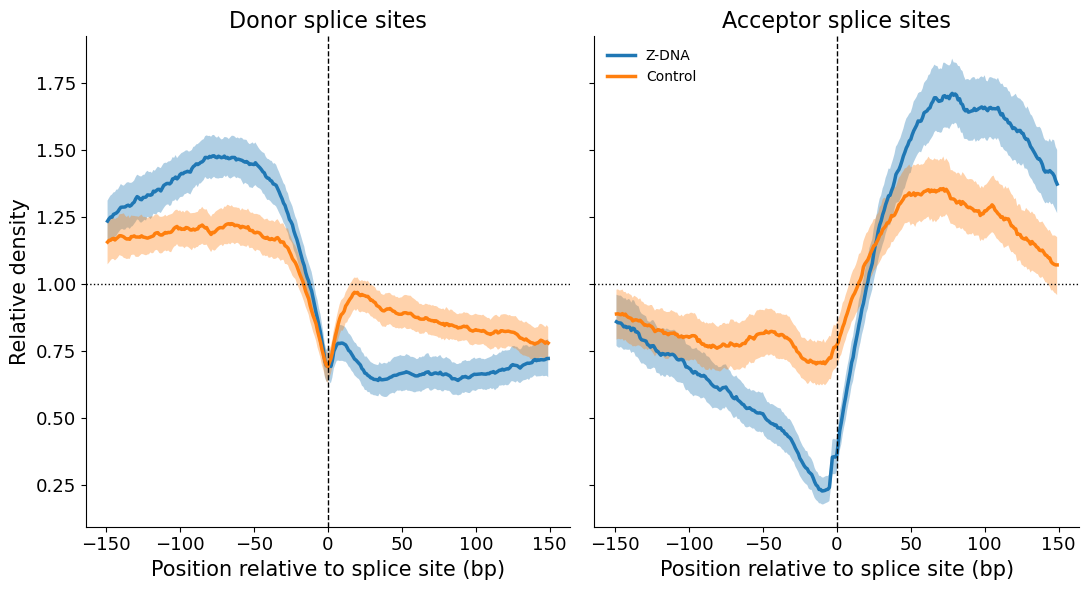

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/splice_site_profiles_plots/zdna_splice_sites_donor_vs_acceptor.png


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------
# Paths
# ------------------
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

DONOR_DIR = Path(f"{BASE}/tmp/marbl/splice_donor_matrices")
ACCEPTOR_DIR = Path(f"{BASE}/tmp/marbl/splice_acceptor_matrices")

OUTDIR = Path(f"{BASE}/splice_site_profiles_plots")
OUTDIR.mkdir(exist_ok=True)

# ------------------
# Parameters
# ------------------
N_BOOTS = 500
MAX_ROWS_BOOT = 50_000   # subsample for speed; increase to 50k for final figure
CLIP = 1

LABEL_FONTSIZE = 15
TICK_FONTSIZE  = 13
TITLE_FONTSIZE = 16

# ------------------
# Utilities
# ------------------
def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def bootstrap_mean_rows_norm(mat, n_boot=500, seed=42, clip=1, max_rows=10_000):
    """
    Bootstrap mean profile across rows, normalized by mean density.
    Subsamples rows for speed.
    """
    rng = np.random.default_rng(seed)
    n = mat.shape[0]

    # clip edges
    mat_c = mat[:, clip:-clip]

    mean = mat_c.mean(axis=0)
    mean_norm = mean / mean.mean()

    k = min(n, max_rows)

    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, k)
        v = mat_c[idx].mean(axis=0)
        m = v.mean()
        boots.append(v / m if m else np.full_like(v, np.nan))

    boots = np.stack(boots)
    lo = np.nanpercentile(boots, 2.5, axis=0)
    hi = np.nanpercentile(boots, 97.5, axis=0)

    return mean_norm, lo, hi

# ------------------
# Core plotting function
# ------------------
def plot_one(ax, indir, title):
    zdna = pd.read_csv(indir / "zdna_splice_sites.tsv", sep="\t")
    ctrl = pd.read_csv(indir / "ctrl_splice_sites.tsv", sep="\t")

    cols = [c for c in zdna.columns if c.startswith("pos_")]
    offsets = np.array([int(c.split("_")[1]) for c in cols])

    Z = zdna[cols].to_numpy(dtype=float)
    C = ctrl[cols].to_numpy(dtype=float)

    offsets_c = offsets[CLIP:-CLIP]

    Zm, Zlo, Zhi = bootstrap_mean_rows_norm(
        Z, n_boot=N_BOOTS, clip=CLIP, max_rows=MAX_ROWS_BOOT
    )
    Cm, Clo, Chi = bootstrap_mean_rows_norm(
        C, n_boot=N_BOOTS, clip=CLIP, max_rows=MAX_ROWS_BOOT
    )

    ax.plot(offsets_c, Zm, lw=2.5, label="Z-DNA")
    ax.fill_between(offsets_c, Zlo, Zhi, alpha=0.35)

    ax.plot(offsets_c, Cm, lw=2.5, label="Control")
    ax.fill_between(offsets_c, Clo, Chi, alpha=0.35)

    ax.axvline(0, ls="--", color="black", lw=1)
    ax.axhline(1, ls=":", color="black", lw=1)

    ax.set_title(title, fontsize=TITLE_FONTSIZE)
    ax.set_xlabel("Position relative to splice site (bp)", fontsize=LABEL_FONTSIZE)
    ax.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax)

# ------------------
# Make figure
# ------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 6),
    sharey=True
)

plot_one(
    axes[0],
    DONOR_DIR,
    "Donor splice sites"
)

plot_one(
    axes[1],
    ACCEPTOR_DIR,
    "Acceptor splice sites"
)

axes[0].set_ylabel("Relative density", fontsize=LABEL_FONTSIZE)
axes[1].legend(frameon=False)
plt.tight_layout()
out = OUTDIR / "zdna_splice_sites_donor_vs_acceptor.png"
plt.savefig(out, dpi=600)
plt.show()
print(f"[OK] Wrote {out}")

#### Extreme plot

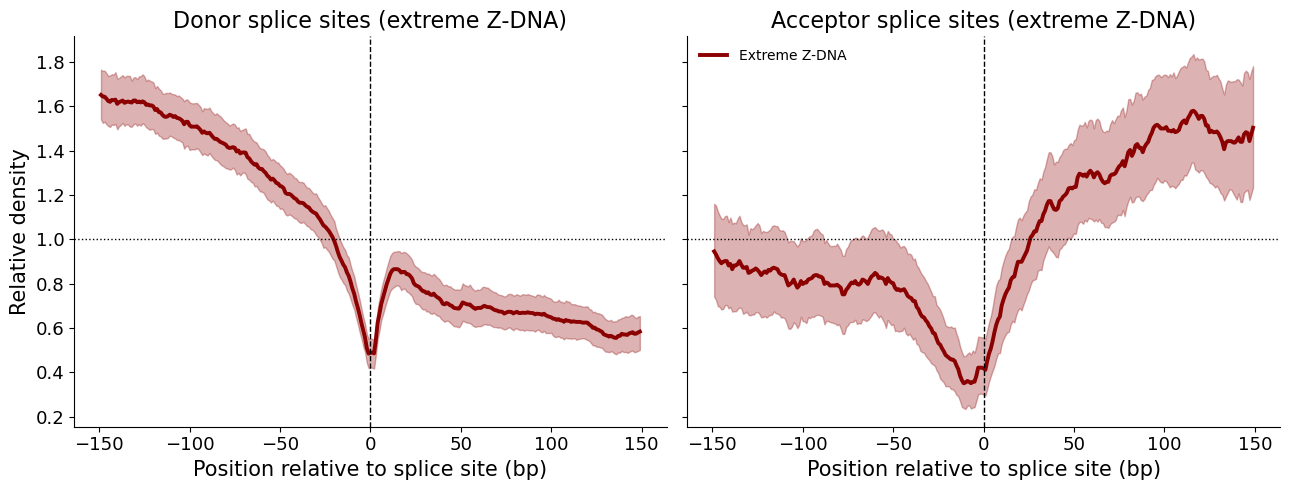

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/splice_site_profiles_plots/zdna_splice_sites_extreme_only.png


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------
# Paths
# ------------------
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

DONOR_DIR = Path(f"{BASE}/tmp/marbl/splice_donor_extreme")
ACCEPTOR_DIR = Path(f"{BASE}/tmp/marbl/splice_acceptor_extreme")

OUTDIR = Path(f"{BASE}/splice_site_profiles_plots")
OUTDIR.mkdir(exist_ok=True)

# ------------------
# Parameters
# ------------------
N_BOOTS = 500
MAX_ROWS_BOOT = 50_000
CLIP = 1

LABEL_FONTSIZE = 15
TICK_FONTSIZE  = 13
TITLE_FONTSIZE = 16

# ------------------
# Utilities
# ------------------
def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def bootstrap_mean_rows_norm(mat, n_boot=500, seed=42, clip=1, max_rows=50_000):
    rng = np.random.default_rng(seed)
    n = mat.shape[0]

    mat_c = mat[:, clip:-clip]

    mean = mat_c.mean(axis=0)
    mean_norm = mean / mean.mean()

    k = min(n, max_rows)

    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, k)
        v = mat_c[idx].mean(axis=0)
        m = v.mean()
        boots.append(v / m if m else np.full_like(v, np.nan))

    boots = np.stack(boots)
    lo = np.nanpercentile(boots, 2.5, axis=0)
    hi = np.nanpercentile(boots, 97.5, axis=0)

    return mean_norm, lo, hi

# ------------------
# Core plotting function
# ------------------
def plot_extreme(ax, indir, title):
    zdna = pd.read_csv(indir / "zdna_splice_sites.tsv", sep="\t")

    cols = [c for c in zdna.columns if c.startswith("pos_")]
    offsets = np.array([int(c.split("_")[1]) for c in cols])
    offsets_c = offsets[CLIP:-CLIP]

    Z = zdna[cols].to_numpy(dtype=float)

    Zm, Zlo, Zhi = bootstrap_mean_rows_norm(
        Z, n_boot=N_BOOTS, clip=CLIP, max_rows=MAX_ROWS_BOOT
    )

    ax.plot(
        offsets_c,
        Zm,
        lw=2.8,
        color="darkred",
        label="Extreme Z-DNA"
    )
    ax.fill_between(
        offsets_c,
        Zlo,
        Zhi,
        alpha=0.30,
        color="darkred"
    )

    ax.axvline(0, ls="--", color="black", lw=1)
    ax.axhline(1, ls=":", color="black", lw=1)

    ax.set_title(title, fontsize=TITLE_FONTSIZE)
    ax.set_xlabel("Position relative to splice site (bp)", fontsize=LABEL_FONTSIZE)
    ax.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax)

# ------------------
# Make figure
# ------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharey=True
)

plot_extreme(
    axes[0],
    DONOR_DIR,
    "Donor splice sites (extreme Z-DNA)"
)

plot_extreme(
    axes[1],
    ACCEPTOR_DIR,
    "Acceptor splice sites (extreme Z-DNA)"
)

axes[0].set_ylabel("Relative density", fontsize=LABEL_FONTSIZE)
axes[1].legend(frameon=False)

plt.tight_layout()

out = OUTDIR / "zdna_splice_sites_extreme_only.png"
plt.savefig(out, dpi=600)
plt.show()

print(f"[OK] Wrote {out}")

## Methylation

Methylation comparison (Z-DNA vs Control)
Z-DNA:    n=174209, median=0.8631, IQR=0.5416 (Q1=0.4043, Q3=0.9459)
Control:  n=169368, median=0.7519, IQR=0.8562 (Q1=0.0731, Q3=0.9294)
Mann–Whitney U p=0.000e+00
Cliff's δ=0.136
Coverage fraction (median):
Z-DNA    = 0.200
Control  = 0.205
Coverage fraction (IQR):
Z-DNA    = 0.286
Control  = 0.267


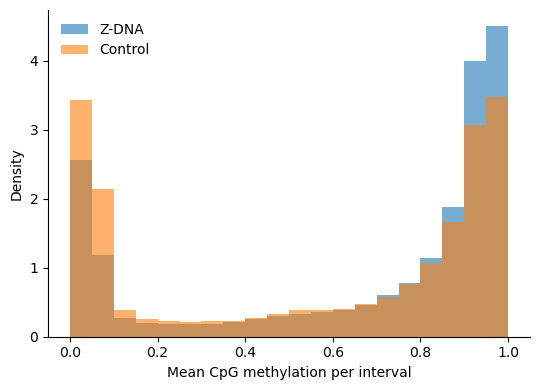

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyBigWig

# =========================
# USER INPUTS
# =========================
BW_PATH = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/chm13v2.0_hg002_CpG_ont_guppy6.1.2.bw"
Z_BED  = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/enrichment_investigation_v2/Z.sorted.bed"
C_BED  = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/marbl/enrichment_investigation_v2/C.sorted.bed"

# =========================
# Helpers
# =========================
def read_bed3(path):
    df = pd.read_csv(
        path, sep="\t", header=None, usecols=[0,1,2],
        names=["Chromosome","Start","End"],
        dtype={"Chromosome": str, "Start": np.int64, "End": np.int64}
    )
    return df[df.End > df.Start].reset_index(drop=True)

def bw_interval_stats(bw, chrom, start, end):
    if end <= start:
        return np.nan, np.nan

    # mean methylation over covered positions
    mean = bw.stats(chrom, int(start), int(end), type="mean", exact=True)[0]

    # coverage fraction: fraction of bases with signal
    covered = bw.stats(chrom, int(start), int(end), type="coverage", exact=True)[0]

    mean = float(mean) if mean is not None else np.nan
    covered = float(covered) if covered is not None else np.nan

    return mean, covered

# =========================
# Load & annotate
# =========================
Z_df = read_bed3(Z_BED)
C_df = read_bed3(C_BED)

bw = pyBigWig.open(BW_PATH)

Z_stats = [bw_interval_stats(bw, r.Chromosome, r.Start, r.End)
           for r in Z_df.itertuples()]
C_stats = [bw_interval_stats(bw, r.Chromosome, r.Start, r.End)
           for r in C_df.itertuples()]

bw.close()

Z_df["meth_mean"], Z_df["cov_frac"] = zip(*Z_stats)
C_df["meth_mean"], C_df["cov_frac"] = zip(*C_stats)

# keep only intervals with methylation signal
Z_df = Z_df[np.isfinite(Z_df.meth_mean)]
C_df = C_df[np.isfinite(C_df.meth_mean)]

z = Z_df.meth_mean.to_numpy()
c = C_df.meth_mean.to_numpy()
from scipy.stats import mannwhitneyu

# =========================
# Summary statistics
# =========================
def summarize(x):
    q1, q3 = np.percentile(x, [25, 75])
    return {
        "median": np.median(x),
        "IQR": q3 - q1,
        "Q1": q1,
        "Q3": q3
    }

sz = summarize(z)
sc = summarize(c)

# =========================
# Mann–Whitney U test
# =========================
U, pval = mannwhitneyu(z, c, alternative="two-sided")

# Cliff's delta
cliffs_delta = (2 * U) / (len(z) * len(c)) - 1

print("Methylation comparison (Z-DNA vs Control)")
print(f"Z-DNA:    n={len(z)}, median={sz['median']:.4f}, "
      f"IQR={sz['IQR']:.4f} (Q1={sz['Q1']:.4f}, Q3={sz['Q3']:.4f})")
print(f"Control:  n={len(c)}, median={sc['median']:.4f}, "
      f"IQR={sc['IQR']:.4f} (Q1={sc['Q1']:.4f}, Q3={sc['Q3']:.4f})")
print(f"Mann–Whitney U p={pval:.3e}")
print(f"Cliff's δ={cliffs_delta:.3f}")

# =========================
# Coverage diagnostics
# =========================
print("Coverage fraction (median):")
print(f"Z-DNA    = {np.nanmedian(Z_df.cov_frac):.3f}")
print(f"Control  = {np.nanmedian(C_df.cov_frac):.3f}")

print("Coverage fraction (IQR):")
print(f"Z-DNA    = {np.nanpercentile(Z_df.cov_frac,75) - np.nanpercentile(Z_df.cov_frac,25):.3f}")
print(f"Control  = {np.nanpercentile(C_df.cov_frac,75) - np.nanpercentile(C_df.cov_frac,25):.3f}")

# =========================
# Plot: histogram only
# =========================
fig, ax = plt.subplots(figsize=(5.5, 4))

bins = np.linspace(0, 1, 21)

ax.hist(z, bins=bins, density=True, alpha=0.6, label="Z-DNA")
ax.hist(c, bins=bins, density=True, alpha=0.6, label="Control")

ax.set_xlabel("Mean CpG methylation per interval")
ax.set_ylabel("Density")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/methylation_hist_only.png", dpi=600)
plt.show()

## Mutational profiles

### Preprocessing, vcf explosion and mutation categorization

In [2]:
from pathlib import Path
import gzip
import pandas as pd
SIZE_BINS = [
    (1, 1, "1bp"),
    (2, 5, "2_5bp"),
    (6, 20, "6_20bp"),
    (21, 50, "21_50bp"),
    (51, 200, "51_200bp"),
    (201, float("inf"), "gt200bp"),
]

vcf_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.vcf.gz")

def parse_VCF_first9(vcf_path: Path) -> pd.DataFrame:
    """
    Parse the VCF and return a DataFrame containing only the first 9 columns
    (#CHROM, POS, ID, REF, ALT, QUAL, FILTER, INFO, FORMAT).
    """
    with gzip.open(vcf_path, "rt") as f:
        # Skip meta lines, capture the VCF header line
        for line in f:
            if line.startswith("##"):
                continue
            header = line.strip().split("\t")[:9]
            break

        # Now f is positioned at the first data row
        df_vcf = pd.read_table(
            f,
            header=None,
            usecols=range(9),
            names=header
        )
    return df_vcf

df_vcf = parse_VCF_first9(vcf_path)
df_vcf.shape

# # Analyses treat each ALT allele as an independent mutational event.”

from collections import defaultdict

def mutation_metadata(ref: str, alt: str):
    ref_len = len(ref)
    alt_len = len(alt)

    # ---- structural class ----
    if ref_len == alt_len == 1:
        struct = "snp"
    elif ref_len == alt_len:
        struct = "mnp"
    elif ref_len < alt_len:
        struct = "ins" if ref_len == 1 else "complex"
    elif ref_len > alt_len:
        struct = "del" if alt_len == 1 else "complex"
    else:
        raise RuntimeError("unreachable")

    # ---- dominant operation ----
    if struct == "complex":
        if ref_len > alt_len:
            dominant = "del_like"
        elif alt_len > ref_len:
            dominant = "ins_like"
        else:
            dominant = "balanced"
    else:
        dominant = struct

    # ---- size (reference span) ----
    ref_span = ref_len
    for lo, hi, label in SIZE_BINS:
        if lo <= ref_span <= hi:
            size_bin = label
            break

    # ---- anchor type ----
    if struct == "snp":
        anchor = "single_base"
    elif struct == "mnp" and ref_len <= 5:
        anchor = "midpoint"
    elif dominant == "del_like":
        anchor = "left_breakpoint"
    else:
        anchor = "insertion_site"

    return {
        "struct_class": struct,
        "dominant_op": dominant,
        "ref_span": ref_span,
        "alt_span": alt_len,
        "size_bin": size_bin,
        "anchor_type": anchor,
    }


def parse_attributes(attrs: str):
    """
    Parse the INFO field of a VCF row.
    Only keep: AC, AF, AN, LEN, TYPE, NS (same as lab script).
    Return a nested dict: attributes[key][i] = value_for_ALT_i
    and attributes['NS'][0], attributes['AN'][0] for constants.
    """
    attributes = defaultdict(dict)
    valid_attributes = {"AC", "AF", "AN", "LEN", "TYPE", "NS"}
    
    for aa in attrs.split(";"):
        if "=" not in aa:
            # Some flags may appear without '='
            continue
        key, val = aa.split("=", 1)
        if key not in valid_attributes:
            continue
        
        # NS, AN are single values
        if key in {"NS", "AN"}:
            try:
                val_cast = int(val)
            except ValueError:
                val_cast = val
            attributes[key][0] = val_cast
            continue
        
        # AC, AF, LEN, TYPE are per-ALT lists
        for i, v in enumerate(val.split(",")):
            if key in {"AC", "LEN"}:
                try:
                    v_cast = int(v)
                except ValueError:
                    v_cast = v
            elif key == "AF":
                try:
                    v_cast = float(v)
                except ValueError:
                    v_cast = v
            else:
                v_cast = v
            attributes[key][i] = v_cast

    return attributes


from tqdm import tqdm
import uuid

def explode_vcf(df_vcf: pd.DataFrame) -> pd.DataFrame:
    vcf_enriched = []

    for _, row in tqdm(df_vcf.iterrows(), total=df_vcf.shape[0]):
        seqID = row["#CHROM"]
        reference = row["REF"]
        alts = row["ALT"]
        info = row["INFO"]
        pos0 = row["POS"] - 1  # 0-based

        if isinstance(alts, float):
            continue

        alt_list = alts.split(",")
        attributes = parse_attributes(info)
        subvariants = len(alt_list)

        for i, alt in enumerate(alt_list):
            meta = mutation_metadata(reference, alt)

            ref_len = len(reference)
            start0 = int(pos0)

            # --- anchor ---
            if meta["anchor_type"] == "single_base":
                center = start0
            elif meta["anchor_type"] == "midpoint":
                center = start0 + ref_len // 2
            elif meta["anchor_type"] == "left_breakpoint":
                center = start0
            elif meta["anchor_type"] == "right_breakpoint":
                center = start0 + ref_len - 1
            elif meta["anchor_type"] == "insertion_site":
                center = start0
            else:
                raise RuntimeError("Unknown anchor type")

            start = center
            end = center + 1  # half-open

            mut_id = f"{seqID}:{pos0+1}:{reference}:{alt}"

            # INFO attributes
            attrs = {}
            for key in {"AC", "AF", "LEN", "TYPE"}:
                if key in attributes and i in attributes[key]:
                    attrs[key] = attributes[key][i]
            for key in {"AN", "NS"}:
                if key in attributes and 0 in attributes[key]:
                    attrs[key] = attributes[key][0]

            vcf_enriched.append({
                "seqID": seqID,
                "start": start,
                "end": end,
                "mut_id": mut_id,

                # enriched metadata
                "struct_class": meta["struct_class"],
                "dominant_op": meta["dominant_op"],
                "ref_span": meta["ref_span"],
                "alt_span": meta["alt_span"],
                "size_bin": meta["size_bin"],
                "anchor_type": meta["anchor_type"],

                # legacy compatibility
                "mutation": f"{meta['struct_class']}_{meta['size_bin']}",
                "general_mut": meta["struct_class"],

                # required downstream
                "reference": reference,
                "variant": alt,
                "subvariants": subvariants,
                "is_multiallelic": subvariants > 1,
            } | attrs)

    return pd.DataFrame(vcf_enriched)


vcf_enriched = explode_vcf(df_vcf)
vcf_enriched.head()
output_exploded_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.exploded.tsv.gz")

vcf_enriched.to_csv(
    output_exploded_path,
    sep="\t",
    index=False,
    compression="gzip"
)

output_exploded_path

vcf_enriched = pd.read_csv(
    "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/"
    "hprc-v2.0-mc-chm13.wave.exploded.tsv.gz",
    sep="\t",
    compression="gzip"
)

bed_df = pd.DataFrame({
    "chrom": vcf_enriched["seqID"],
    "start": vcf_enriched["start"].astype(int),
    "end": vcf_enriched["end"].astype(int),
    "name": vcf_enriched["mut_id"],
    "score": 0,
    "strand": ".",
})

bed_output_path = Path(
    "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/"
    "hprc-v2.0-mc-chm13.wave.mutations.bed.gz"
)

bed_df.to_csv(
    bed_output_path,
    sep="\t",
    header=False,
    index=False,
    compression="gzip"
)


bed_output_path

meta_df = vcf_enriched[[
    "mut_id",
    "seqID",
    "start",
    "end",

    # NEW enriched fields (required)
    "struct_class",
    "dominant_op",
    "ref_span",
    "alt_span",
    "anchor_type",
    "size_bin",

    # legacy / compatibility
    "mutation",
    "general_mut",

    # sequence info
    "reference",
    "variant",

    # INFO fields
    "AC",
    "AF",
    "AN",
    "NS",
    "LEN",
    "TYPE",

    "subvariants",
    "is_multiallelic",
]].copy()

meta_output_path = Path(
    "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/"
    "hprc-v2.0-mc-chm13.wave.mutations.meta.tsv.gz"
)

meta_df.to_csv(
    meta_output_path,
    sep="\t",
    index=False,
    compression="gzip"
)
threecol_df = pd.DataFrame({
    "chrom": vcf_enriched["seqID"],
    "pos": vcf_enriched["start"],  # 0-based coordinate
    "mutation": vcf_enriched["mutation"],
})

threecol_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.3col.tsv.gz")
threecol_df.to_csv(threecol_path, sep="\t", index=False, compression="gzip")
threecol_path

PosixPath('/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.3col.tsv.gz')

### Mutational profiles

In [12]:
import numpy as np
import pandas as pd
from pathlib import Path
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
MASTER   = f"{BASE}/controls_combined/CHM13_controls_MASTER.tsv"
MUT_BED  = f"{BASE}/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz"
MUT_META = f"{BASE}/ann_files/hprc-v2.0-mc-chm13.wave.mutations.meta.tsv.gz"
CHROM_LEN_TSV = f"{BASE}/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
ANCHOR_MODE = "left"   # "right" or "left" — run twice
TOL = "10%"
WINDOW_RADIUS = 500
N_BOOTS = 500
CI_LOW, CI_HIGH = 2.5, 97.5
MIN_MUTS = 500
OUTDIR = Path(f"{BASE}/mutation_profiles_cached_tol10_{ANCHOR_MODE}")
OUTDIR.mkdir(parents=True, exist_ok=True)

def chrom_block_bootstrap_windowmean_norm(counts_by_chr, n_boot):
    chroms = list(counts_by_chr)
    mat = np.stack([counts_by_chr[c].astype(float) for c in chroms])
    rng = np.random.default_rng(42)

    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(chroms), len(chroms))
        v = mat[idx].sum(axis=0)
        m = v.mean()
        boots.append(v / m if m else np.full_like(v, np.nan))

    boots = np.stack(boots)
    return (
        np.nanpercentile(boots, CI_LOW, axis=0),
        np.nanpercentile(boots, CI_HIGH, axis=0),
    )

def build_bool_coverage(starts, ends, L):
    starts = np.asarray(starts, dtype=np.int64)
    ends   = np.asarray(ends,   dtype=np.int64)

    starts = np.clip(starts, 0, L)
    ends   = np.clip(ends,   0, L)

    mask = ends > starts
    if not np.any(mask):
        return np.zeros(L, dtype=bool)

    starts = starts[mask]
    ends   = ends[mask]

    diff = np.zeros(L + 1, dtype=np.int32)
    np.add.at(diff, starts,  1)
    np.add.at(diff, ends,   -1)

    return np.cumsum(diff[:-1]) > 0

chrom_len = dict(pd.read_csv(
    CHROM_LEN_TSV, sep="\t",
    usecols=["ucsc_pansn_name", "gcf_seq_length"]
).values)

m = pd.read_csv(MASTER, sep="\t")
m = m[(m["tol_level"] == TOL) & (m["has_control"])].drop_duplicates(
    ["Chromosome", "Start0", "End0"]
)

z_intervals = {
    c: d[["Start0", "End0"]].values
    for c, d in m.groupby("Chromosome")
}
c_intervals = {
    c: d[["Ctrl_Start", "Ctrl_End"]].values
    for c, d in m.groupby("Chromosome")
}

mut = pd.read_csv(
    MUT_BED, sep="\t", header=None,
    names=["Chromosome", "Start", "End", "mut_id", "score", "strand"]
)

meta = pd.read_csv(MUT_META, sep="\t", compression="gzip")

need = ["mut_id","struct_class","dominant_op","ref_span","alt_span"]
mut = mut.merge(meta[need], on="mut_id", how="left").dropna()

mut["indel_len"] = (mut["alt_span"] - mut["ref_span"]).abs()

def assign_main_stratum(r):
    sc, dom, L = r["struct_class"], r["dominant_op"], r["indel_len"]
    if sc == "snp": return "SNP"
    if sc == "mnp": return "MNP"
    if sc == "ins": return "INS_gt20bp" if L > 20 else "INS_<=20bp"
    if sc == "del": return "DEL_gt20bp" if L > 20 else "DEL_<=20bp"
    if sc == "complex":
        return f"COMPLEX_{dom}_gt20bp" if L > 20 else f"COMPLEX_{dom}_<=20bp"
    return "OTHER"

mut["stratum"] = mut.apply(assign_main_stratum, axis=1)

offsets = np.arange(-WINDOW_RADIUS, WINDOW_RADIUS + 1)

DUAL_ANCHOR_STRATA = {
    "DEL_<=20bp", "DEL_gt20bp",
    "COMPLEX_del_like_<=20bp", "COMPLEX_del_like_gt20bp",
    "COMPLEX_ins_like_<=20bp", "COMPLEX_ins_like_gt20bp",
}

for stratum, sub in mut.groupby("stratum"):
    if len(sub) < MIN_MUTS:
        continue

    Z_by_chr, C_by_chr = {}, {}
    Z_total = np.zeros(len(offsets), int)
    C_total = np.zeros(len(offsets), int)

    for chrom, d in sub.groupby("Chromosome"):
        if chrom not in z_intervals:
            continue

        L = chrom_len[chrom]

        if stratum in DUAL_ANCHOR_STRATA:
            if ANCHOR_MODE == "right":
                anchors = (
                    d["Start"].to_numpy(dtype=np.int64)
                    + d["ref_span"].to_numpy(dtype=np.int64)
                    - 1
                )
            elif ANCHOR_MODE == "left":
                anchors = d["Start"].to_numpy(dtype=np.int64)
            else:
                raise ValueError("ANCHOR_MODE must be 'left' or 'right'")
        else:
            # SNP, MNP, simple INS
            anchors = d["Start"].to_numpy(dtype=np.int64)

        z_cov = build_bool_coverage(
            z_intervals[chrom][:,0], z_intervals[chrom][:,1], L)
        c_cov = build_bool_coverage(
            c_intervals[chrom][:,0], c_intervals[chrom][:,1], L)

        Zc = np.zeros(len(offsets), int)
        Cc = np.zeros(len(offsets), int)

        for i, k in enumerate(offsets):
            pos = anchors + k
            mask = (pos >= 0) & (pos < L)
            if mask.any():
                Zc[i] = z_cov[pos[mask]].sum()
                Cc[i] = c_cov[pos[mask]].sum()

        Z_total += Zc
        C_total += Cc
        Z_by_chr[chrom] = Zc
        C_by_chr[chrom] = Cc

    Z_mean = Z_total / Z_total.mean()
    C_mean = C_total / C_total.mean()

    Z_lo, Z_hi = chrom_block_bootstrap_windowmean_norm(Z_by_chr, N_BOOTS)
    C_lo, C_hi = chrom_block_bootstrap_windowmean_norm(C_by_chr, N_BOOTS)

    out = pd.DataFrame({
        "offset": offsets,
        "Z_mean": Z_mean,
        "Z_lo": Z_lo,
        "Z_hi": Z_hi,
        "C_mean": C_mean,
        "C_lo": C_lo,
        "C_hi": C_hi,
        "n_junctions": len(Z_total) and len(anchors)
    })

    out.to_csv(OUTDIR / f"profile_{stratum}.tsv", sep="\t", index=False)

print("[DONE] Profiles computed and cached.")

[DONE] Profiles computed and cached.


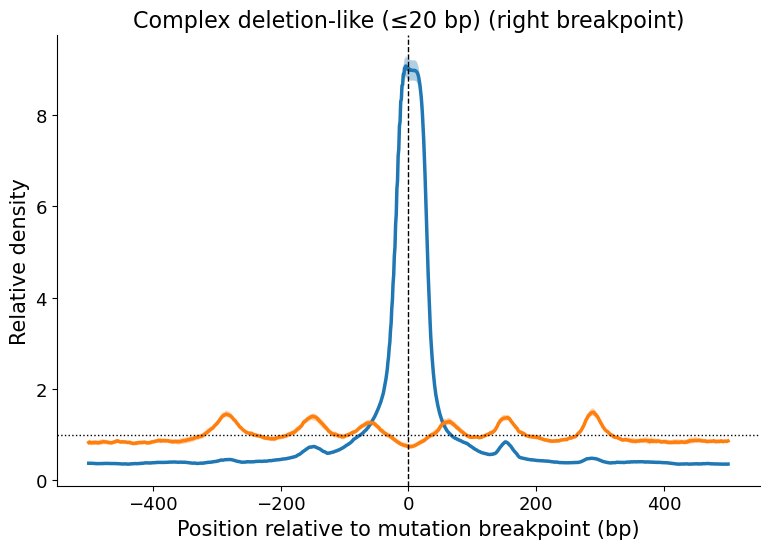

[OK] Wrote COMPLEX_del_like_<=20bp_right.png


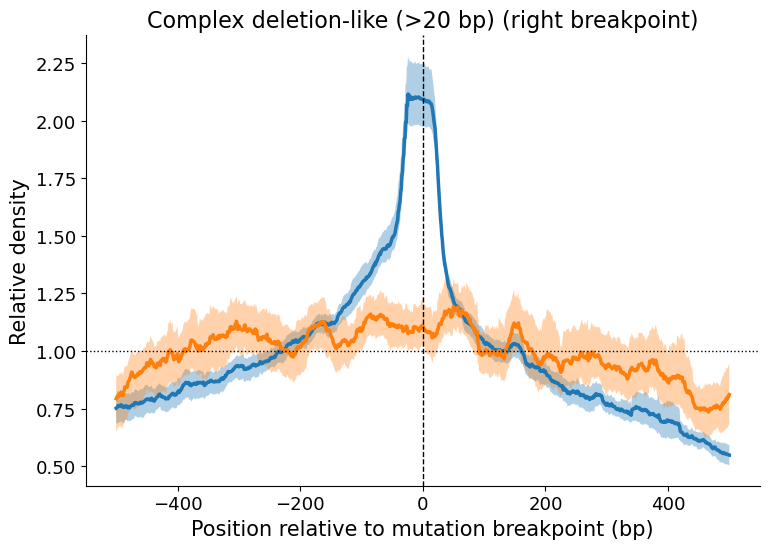

[OK] Wrote COMPLEX_del_like_gt20bp_right.png


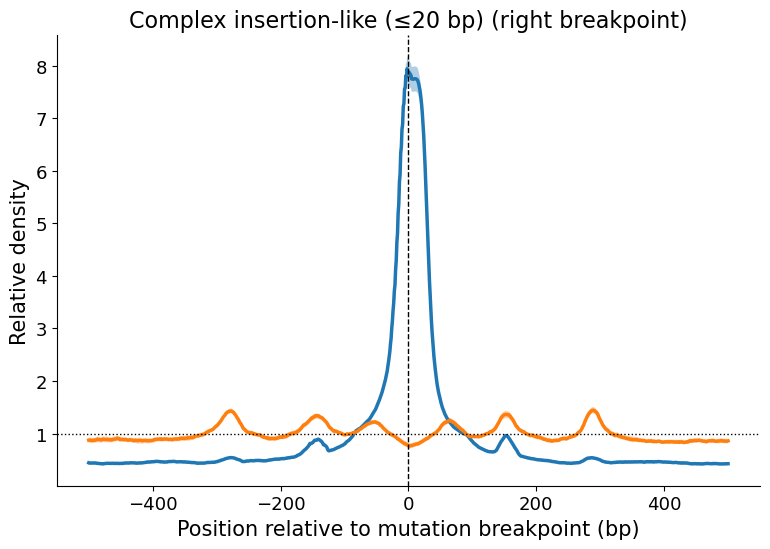

[OK] Wrote COMPLEX_ins_like_<=20bp_right.png


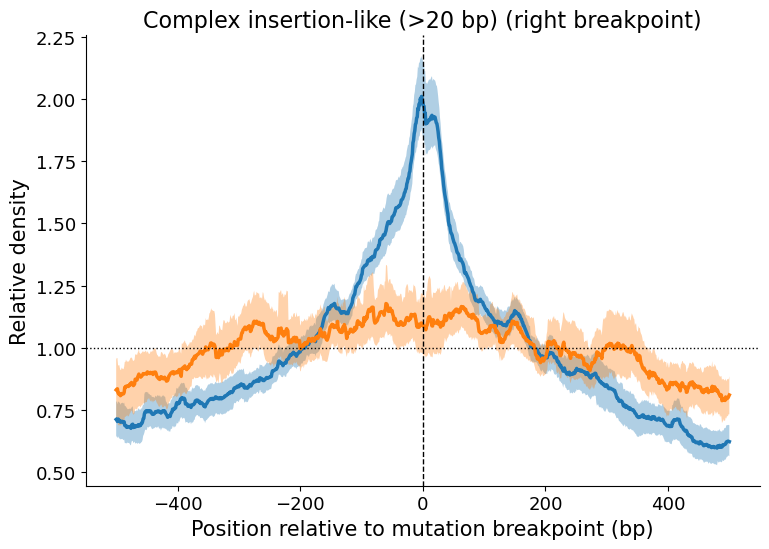

[OK] Wrote COMPLEX_ins_like_gt20bp_right.png


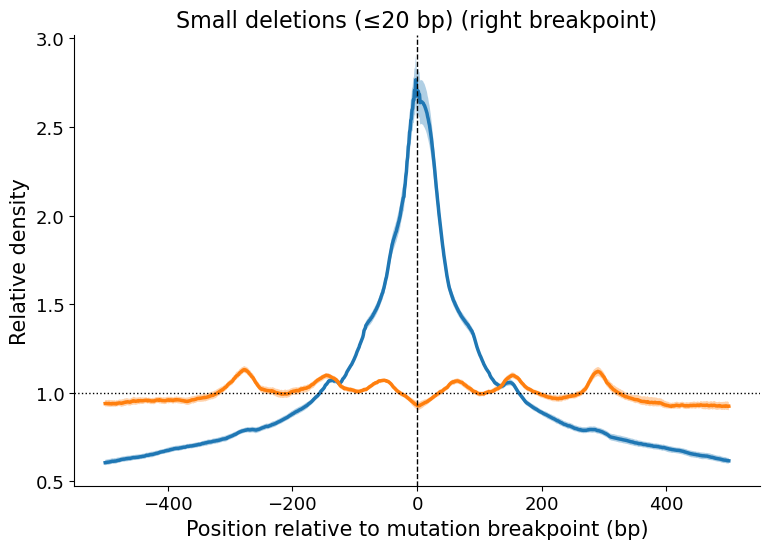

[OK] Wrote DEL_<=20bp_right.png


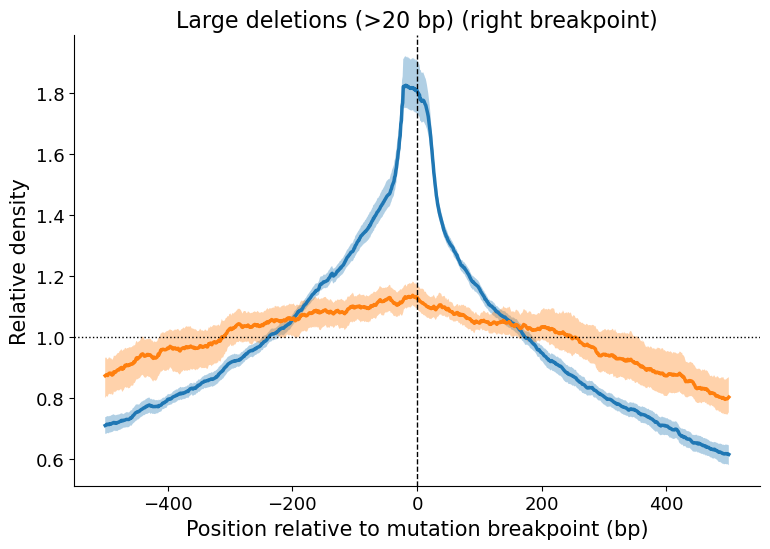

[OK] Wrote DEL_gt20bp_right.png


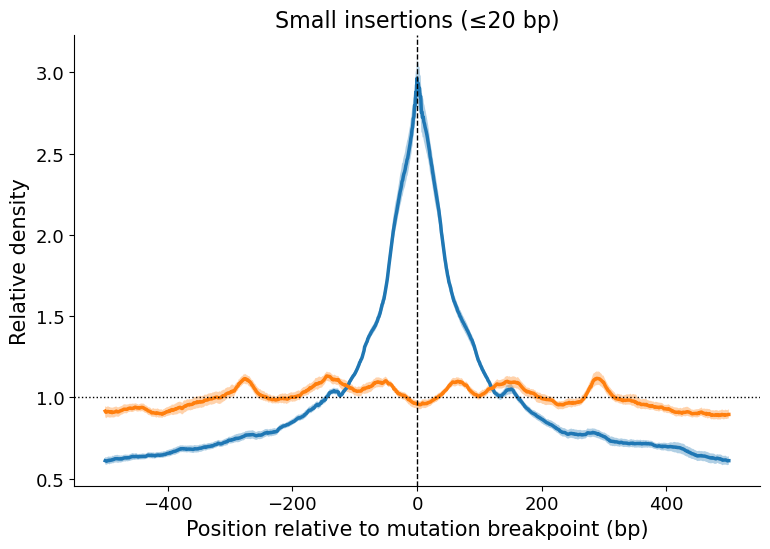

[OK] Wrote INS_<=20bp_right.png


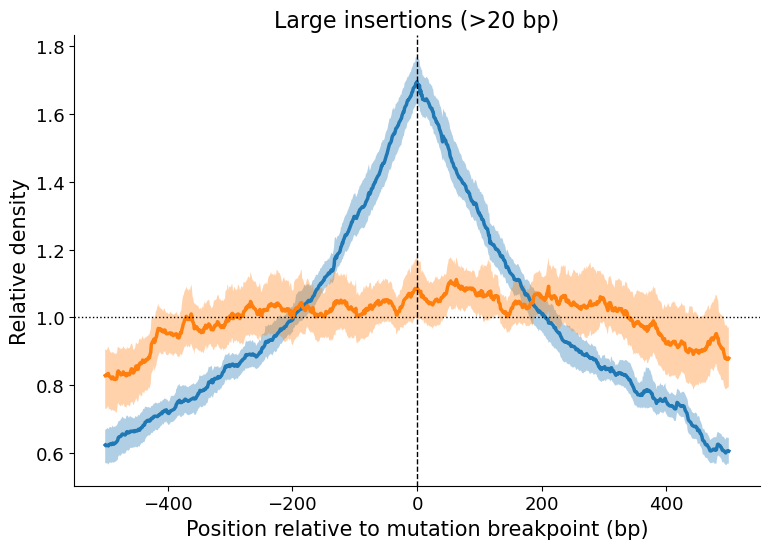

[OK] Wrote INS_gt20bp_right.png


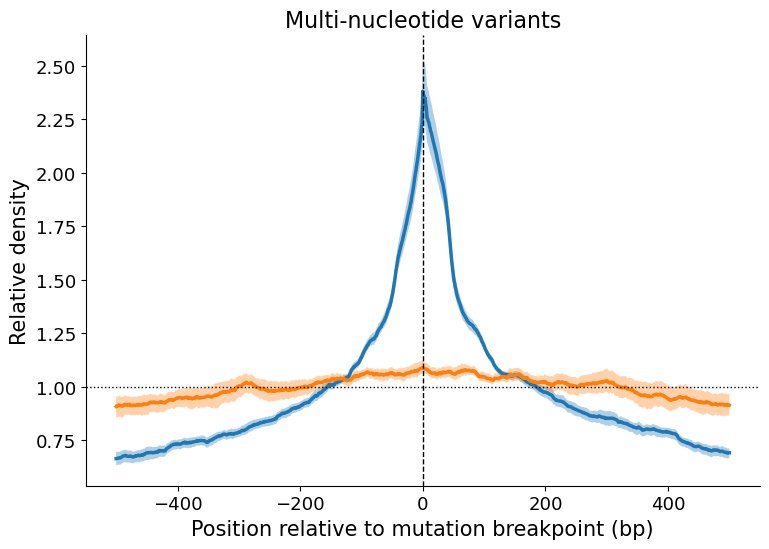

[OK] Wrote MNP_right.png


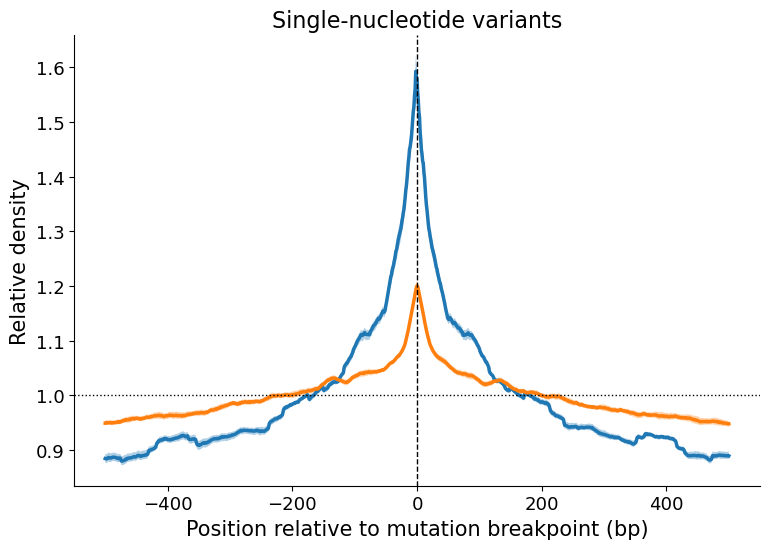

[OK] Wrote SNP_right.png


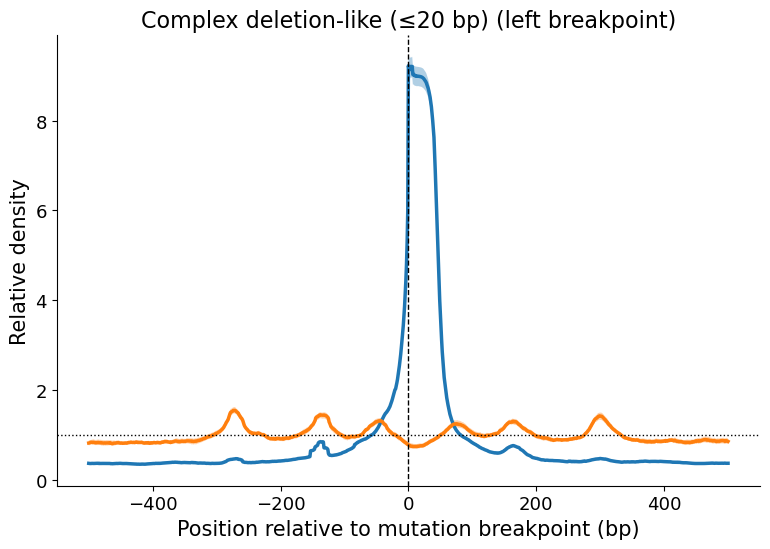

[OK] Wrote COMPLEX_del_like_<=20bp_left.png


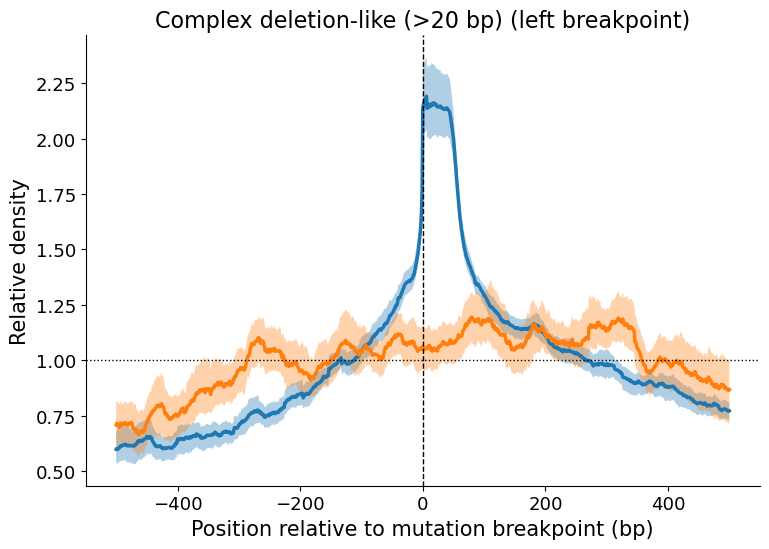

[OK] Wrote COMPLEX_del_like_gt20bp_left.png


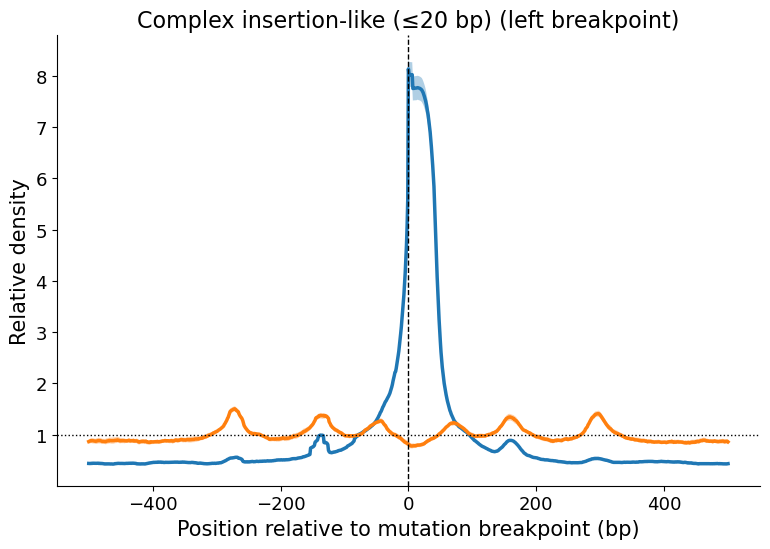

[OK] Wrote COMPLEX_ins_like_<=20bp_left.png


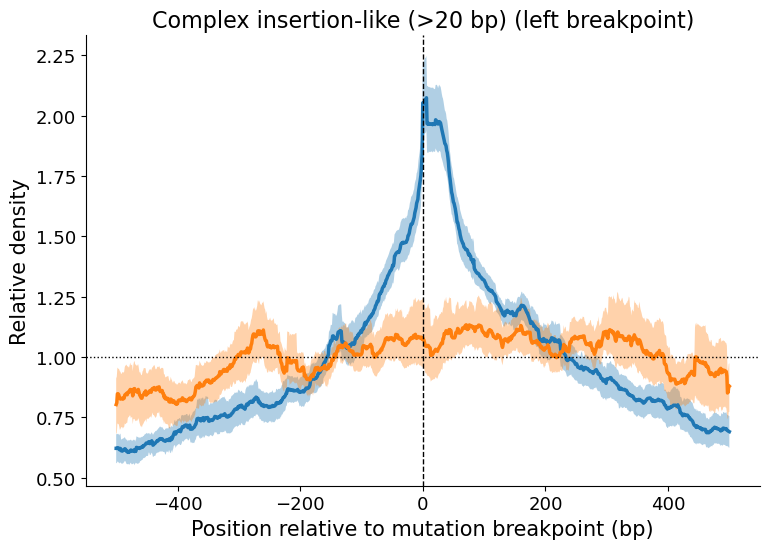

[OK] Wrote COMPLEX_ins_like_gt20bp_left.png


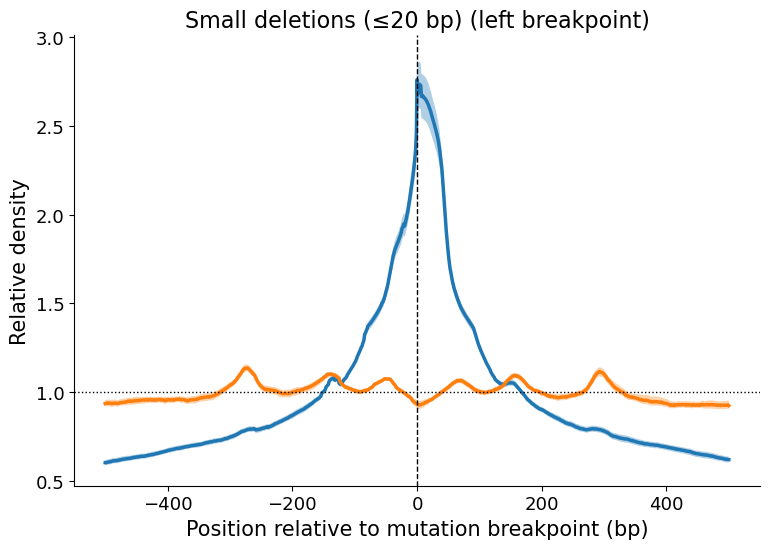

[OK] Wrote DEL_<=20bp_left.png


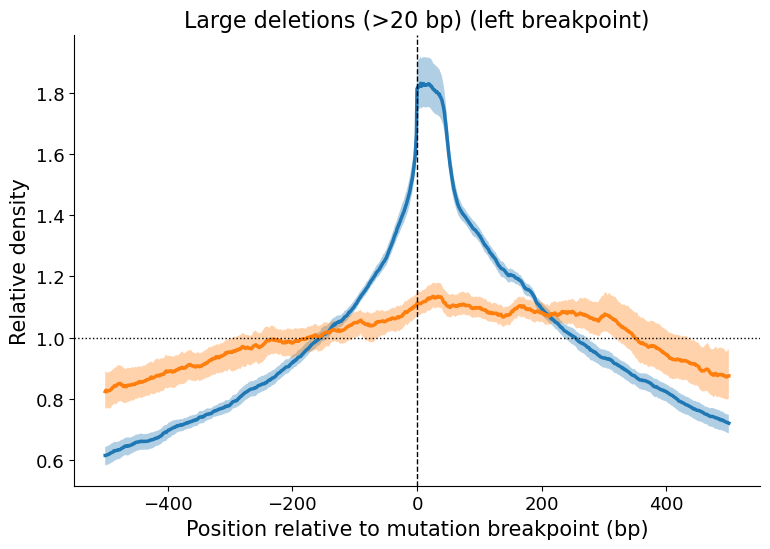

[OK] Wrote DEL_gt20bp_left.png


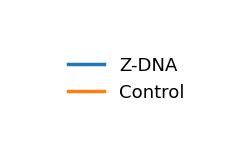

[OK] Wrote legend: /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_plots_tol10/mutation_profiles_legend.png
[DONE] All plots generated.


In [13]:
#!/usr/bin/env python3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

# ================= CONFIG =================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

ANCHOR_MODES = ["right", "left"]

INDIRS = {
    a: Path(f"{BASE}/mutation_profiles_cached_tol10_{a}")
    for a in ANCHOR_MODES
}

OUTDIR = Path(f"{BASE}/mutation_profiles_plots_tol10")
OUTDIR.mkdir(exist_ok=True)

# Typography
LABEL_FONTSIZE = 15
TICK_FONTSIZE  = 13
TITLE_FONTSIZE = 16

# ================= STRATA DEFINITIONS =================
DUAL_ANCHOR_STRATA = {
    "DEL_<=20bp",
    "DEL_gt20bp",
    "COMPLEX_del_like_<=20bp",
    "COMPLEX_del_like_gt20bp",
    "COMPLEX_ins_like_<=20bp",
    "COMPLEX_ins_like_gt20bp",
}
NO_BREAKPOINT_STRATA = {
    "SNP",
    "MNP",
    "INS_<=20bp",
    "INS_gt20bp",
}

# Human-readable titles
TITLE_MAP = {
    "SNP": "Single-nucleotide variants",
    "MNP": "Multi-nucleotide variants",
    "INS_<=20bp": "Small insertions (≤20 bp)",
    "INS_gt20bp": "Large insertions (>20 bp)",
    "DEL_<=20bp": "Small deletions (≤20 bp)",
    "DEL_gt20bp": "Large deletions (>20 bp)",
    "COMPLEX_ins_like_<=20bp": "Complex insertion-like (≤20 bp)",
    "COMPLEX_ins_like_gt20bp": "Complex insertion-like (>20 bp)",
    "COMPLEX_del_like_<=20bp": "Complex deletion-like (≤20 bp)",
    "COMPLEX_del_like_gt20bp": "Complex deletion-like (>20 bp)",
}

# ================= HELPERS =================
def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def plot_profile(df, title, outpath):
    plt.figure(figsize=(7.8, 5.6))

    plt.plot(df["offset"], df["Z_mean"], lw=2.5)
    plt.fill_between(df["offset"], df["Z_lo"], df["Z_hi"], alpha=0.35)

    plt.plot(df["offset"], df["C_mean"], lw=2.5)
    plt.fill_between(df["offset"], df["C_lo"], df["C_hi"], alpha=0.35)

    plt.axvline(0, ls="--", color="black", lw=1)
    plt.axhline(1, ls=":", color="black", lw=1)

    plt.xlabel("Position relative to mutation breakpoint (bp)",
               fontsize=LABEL_FONTSIZE)
    plt.ylabel("Relative density",
               fontsize=LABEL_FONTSIZE)

    plt.title(title, fontsize=TITLE_FONTSIZE)

    plt.tick_params(labelsize=TICK_FONTSIZE)
    despine(plt.gca())

    plt.tight_layout()
    plt.savefig(outpath, dpi=600)
    plt.show()

# ================= MAIN LOOP =================
for anchor in ANCHOR_MODES:

    indir = INDIRS[anchor]
    if not indir.exists():
        continue

    for path in sorted(indir.glob("profile_*.tsv")):
        df = pd.read_csv(path, sep="\t")
        stratum = path.stem.replace("profile_", "")

        if stratum not in TITLE_MAP:
            continue

        # Skip left-anchor plots for strata that don't support it
        if anchor == "left" and stratum not in DUAL_ANCHOR_STRATA:
            continue
        if stratum in NO_BREAKPOINT_STRATA:
            title = TITLE_MAP[stratum]
        else:
            anchor_label = (
                "right breakpoint" if anchor == "right"
                else "left breakpoint"
            )
            title = f"{TITLE_MAP[stratum]} ({anchor_label})"


        outname = f"{stratum}_{anchor}.png"
        outpath = OUTDIR / outname

        plot_profile(df, title, outpath)

        print(f"[OK] Wrote {outname}")

# ================= LEGEND ONLY =================
legend_fig = plt.figure(figsize=(3.0, 1.8))
ax_leg = legend_fig.add_subplot(111)
ax_leg.axis("off")

legend_handles = [
    Line2D([0], [0], lw=2.5, label="Z-DNA", color="tab:blue"),
    Line2D([0], [0], lw=2.5, label="Control", color="tab:orange"),
]

ax_leg.legend(
    handles=legend_handles,
    loc="center",
    frameon=False,
    fontsize=13
)

legend_out = OUTDIR / "mutation_profiles_legend.png"
legend_fig.savefig(legend_out, dpi=600, bbox_inches="tight")
plt.show(legend_fig)

print(f"[OK] Wrote legend: {legend_out}")
print("[DONE] All plots generated.")

### Mutation and methylation

In [40]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
import pyBigWig
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

MASTER   = f"{BASE}/controls_combined/CHM13_controls_MASTER.tsv"
MUT_BED  = f"{BASE}/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz"
MUT_META = f"{BASE}/ann_files/hprc-v2.0-mc-chm13.wave.mutations.meta.tsv.gz"
CHROM_LEN_TSV = f"{BASE}/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
BW_METH = f"{BASE}/tmp/marbl/chm13v2.0_hg002_CpG_ont_guppy6.1.2.bw"

TOL = "10%"

# mutation profiling
WINDOW_RADIUS = 500
OFFSETS = np.arange(-WINDOW_RADIUS, WINDOW_RADIUS + 1)

ANCHOR_MODE = "left"   # "left" or "right"; run twice if needed
N_BOOTS = 500
CI_LOW, CI_HIGH = 2.5, 97.5
MIN_MUTS = 500

# methylation stratification
N_BINS = 3  # tertiles; set 4 for quartiles
BIN_LABELS = [f"Q{i+1}" for i in range(N_BINS)]  # Q1..Q3 or Q1..Q4

OUTDIR = Path(f"{BASE}/mutation_profiles_methstrat_tol10_{ANCHOR_MODE}_Q{N_BINS}")
OUTDIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# HELPERS
# ============================================================
def chrom_block_bootstrap_windowmean_norm(counts_by_chr, n_boot, seed=42):
    chroms = list(counts_by_chr)
    if len(chroms) < 2:
        return (np.full(len(OFFSETS), np.nan), np.full(len(OFFSETS), np.nan))

    mat = np.stack([counts_by_chr[c].astype(float) for c in chroms])
    rng = np.random.default_rng(seed)

    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(chroms), len(chroms))
        v = mat[idx].sum(axis=0)
        m = v.mean()
        boots.append(v / m if m else np.full_like(v, np.nan))

    boots = np.stack(boots)
    return (
        np.nanpercentile(boots, CI_LOW, axis=0),
        np.nanpercentile(boots, CI_HIGH, axis=0),
    )

def build_bool_coverage(starts, ends, L):
    starts = np.asarray(starts, dtype=np.int64)
    ends   = np.asarray(ends,   dtype=np.int64)

    starts = np.clip(starts, 0, L)
    ends   = np.clip(ends,   0, L)

    mask = ends > starts
    if not np.any(mask):
        return np.zeros(L, dtype=bool)

    starts = starts[mask]
    ends   = ends[mask]

    diff = np.zeros(L + 1, dtype=np.int32)
    np.add.at(diff, starts,  1)
    np.add.at(diff, ends,   -1)

    return np.cumsum(diff[:-1]) > 0

def bw_interval_mean(bw, chrom, start0, end0):
    """Mean over covered positions in bigwig; missing positions ignored. None -> NaN."""
    if end0 <= start0:
        return np.nan
    m = bw.stats(str(chrom), int(start0), int(end0), type="mean", exact=True)[0]
    return float(m) if m is not None else np.nan

def assign_main_stratum(df):
    df = df.copy()
    df["indel_len"] = (df["alt_span"] - df["ref_span"]).abs()

    def f(r):
        sc, dom, L = r["struct_class"], r["dominant_op"], r["indel_len"]
        if sc == "snp": return "SNP"
        if sc == "mnp": return "MNP"
        if sc == "ins": return "INS_gt20bp" if L > 20 else "INS_<=20bp"
        if sc == "del": return "DEL_gt20bp" if L > 20 else "DEL_<=20bp"
        if sc == "complex":
            return f"COMPLEX_{dom}_gt20bp" if L > 20 else f"COMPLEX_{dom}_<=20bp"
        return "OTHER"

    df["stratum"] = df.apply(f, axis=1)
    return df

DUAL_ANCHOR_STRATA = {
    "DEL_<=20bp", "DEL_gt20bp",
    "COMPLEX_del_like_<=20bp", "COMPLEX_del_like_gt20bp",
    "COMPLEX_ins_like_<=20bp", "COMPLEX_ins_like_gt20bp",
}

# ============================================================
# LOAD CHROM LENGTHS
# ============================================================
chrom_len = dict(
    pd.read_csv(CHROM_LEN_TSV, sep="\t", usecols=["ucsc_pansn_name", "gcf_seq_length"]).values
)

# ============================================================
# LOAD MATCHED PAIRS (0-based already)
# ============================================================
m = pd.read_csv(MASTER, sep="\t")
m = m[(m["tol_level"] == TOL) & (m["has_control"])].copy()

need_cols = ["Chromosome", "Start0", "End0", "Ctrl_Start", "Ctrl_End"]
missing = [c for c in need_cols if c not in m.columns]
if missing:
    raise RuntimeError(f"MASTER missing columns: {missing}")

# Deduplicate Z intervals if needed, but keep pair rows for downstream binning
m = m.drop_duplicates(["Chromosome", "Start0", "End0", "Ctrl_Start", "Ctrl_End"]).copy()
m.reset_index(drop=True, inplace=True)

# ============================================================
# COMPUTE Z INTERVAL METHYLATION (CpG-observed space)
# ============================================================
bw = pyBigWig.open(BW_METH)

# Compute per row (pair) methylation of the Z interval
# NOTE: bigwig is 0-based half-open, same as Start0/End0
m["Z_meth_mean"] = [
    bw_interval_mean(bw, r.Chromosome, r.Start0, r.End0)
    for r in m.itertuples(index=False)
]

bw.close()

# Drop pairs with no methylation info in Z interval (strict CpG-observed space)
m = m[np.isfinite(m["Z_meth_mean"])].copy()
m.reset_index(drop=True, inplace=True)

if m.empty:
    raise RuntimeError("No matched pairs have finite Z_meth_mean. Check bigWig / coordinates.")

# ============================================================
# ASSIGN METHYLATION QUANTILE BINS (on Z only)
# ============================================================
# Use qcut on Z_meth_mean. If ties cause issues, use rank-based jitter fallback.
# ============================================================
# ASSIGN METHYLATION BINS (fixed thresholds on Z only)
# ============================================================
# Define fixed CpG methylation thresholds
LOW_THR  = 0.2
HIGH_THR = 0.8

# Q1: low, Q2: intermediate, Q3: high
m["meth_bin"] = pd.cut(
    m["Z_meth_mean"],
    bins=[-np.inf, LOW_THR, HIGH_THR, np.inf],
    labels=["Q1", "Q2", "Q3"],
    include_lowest=True,
    right=True,   # (<= LOW_THR) goes to Q1; (<= HIGH_THR) goes to Q2
)

m = m.dropna(subset=["meth_bin"]).copy()
m["meth_bin"] = m["meth_bin"].astype(str)

# Sanity
bin_counts = m["meth_bin"].value_counts().sort_index()
print("[INFO] Pairs per methylation bin (fixed thresholds):")
print(bin_counts.to_string())
print(f"[INFO] Thresholds: Q1<= {LOW_THR}, Q2=({LOW_THR},{HIGH_THR}], Q3> {HIGH_THR}")


# Sanity
bin_counts = m["meth_bin"].value_counts().sort_index()
print("[INFO] Pairs per methylation bin:")
print(bin_counts.to_string())

# ============================================================
# LOAD MUTATIONS + META, DEFINE STRATA
# ============================================================
mut = pd.read_csv(
    MUT_BED, sep="\t", header=None,
    names=["Chromosome", "Start", "End", "mut_id", "score", "strand"]
)

meta = pd.read_csv(MUT_META, sep="\t", compression="gzip")

need = ["mut_id","struct_class","dominant_op","ref_span","alt_span"]
mut = mut.merge(meta[need], on="mut_id", how="left").dropna()

mut = assign_main_stratum(mut)

# ============================================================
# MAIN: PROFILE PER (METH_BIN, STRATUM)
# ============================================================
for meth_bin, mpairs in m.groupby("meth_bin"):
    # build interval dicts per chrom for this bin
    z_intervals = {
        c: d[["Start0", "End0"]].to_numpy(dtype=np.int64)
        for c, d in mpairs.groupby("Chromosome")
    }
    c_intervals = {
        c: d[["Ctrl_Start", "Ctrl_End"]].to_numpy(dtype=np.int64)
        for c, d in mpairs.groupby("Chromosome")
    }

    # precompute coverage masks per chromosome ONCE per bin (saves time across strata)
    # WARNING: memory heavy but manageable because it’s per chromosome sequentially in loop below.
    # We will build per-chrom inside strata loop to avoid storing all masks at once.

    for stratum, sub in mut.groupby("stratum"):
        if len(sub) < MIN_MUTS:
            continue

        Z_by_chr, C_by_chr = {}, {}
        Z_total = np.zeros(len(OFFSETS), dtype=np.int64)
        C_total = np.zeros(len(OFFSETS), dtype=np.int64)

        n_mut_used = 0
        n_chr_used = 0
        n_pairs_used = int(len(mpairs))

        for chrom, dchr in sub.groupby("Chromosome"):
            if chrom not in z_intervals:
                continue

            L = int(chrom_len.get(chrom, 0))
            if L <= 0:
                continue

            # anchors (same logic you already use)
            if stratum in DUAL_ANCHOR_STRATA:
                if ANCHOR_MODE == "right":
                    anchors = (
                        dchr["Start"].to_numpy(dtype=np.int64)
                        + dchr["ref_span"].to_numpy(dtype=np.int64)
                        - 1
                    )
                elif ANCHOR_MODE == "left":
                    anchors = dchr["Start"].to_numpy(dtype=np.int64)
                else:
                    raise ValueError("ANCHOR_MODE must be 'left' or 'right'")
            else:
                anchors = dchr["Start"].to_numpy(dtype=np.int64)

            if anchors.size == 0:
                continue

            # build coverage masks for this chrom + bin
            z_cov = build_bool_coverage(z_intervals[chrom][:,0], z_intervals[chrom][:,1], L)
            c_cov = build_bool_coverage(c_intervals[chrom][:,0], c_intervals[chrom][:,1], L)

            # count anchor±offset positions falling in Z/C masks
            Zc = np.zeros(len(OFFSETS), dtype=np.int64)
            Cc = np.zeros(len(OFFSETS), dtype=np.int64)

            for i, k in enumerate(OFFSETS):
                pos = anchors + k
                mask = (pos >= 0) & (pos < L)
                if mask.any():
                    Zc[i] = z_cov[pos[mask]].sum()
                    Cc[i] = c_cov[pos[mask]].sum()

            Z_total += Zc
            C_total += Cc
            Z_by_chr[chrom] = Zc
            C_by_chr[chrom] = Cc

            n_mut_used += anchors.size
            n_chr_used += 1

        # if nothing accumulated, skip
        if n_mut_used < MIN_MUTS:
            continue
        if Z_total.mean() == 0 or C_total.mean() == 0:
            continue

        # normalize by profile mean (same as your existing code)
        Z_mean = Z_total / Z_total.mean()
        C_mean = C_total / C_total.mean()

        Z_lo, Z_hi = chrom_block_bootstrap_windowmean_norm(Z_by_chr, N_BOOTS, seed=42)
        C_lo, C_hi = chrom_block_bootstrap_windowmean_norm(C_by_chr, N_BOOTS, seed=42)

        out = pd.DataFrame({
            "meth_bin": meth_bin,
            "stratum": stratum,
            "anchor_mode": ANCHOR_MODE,
            "offset": OFFSETS,
            "Z_mean": Z_mean,
            "Z_lo": Z_lo,
            "Z_hi": Z_hi,
            "C_mean": C_mean,
            "C_lo": C_lo,
            "C_hi": C_hi,
            "n_mut_used": n_mut_used,
            "n_chr_used": n_chr_used,
            "n_pairs_used": n_pairs_used,
            "Z_meth_bin_median": float(mpairs["Z_meth_mean"].median()),
        })

        outpath = OUTDIR / f"profile_{stratum}__{meth_bin}.tsv"
        out.to_csv(outpath, sep="\t", index=False)
        print(f"[OK] wrote {outpath}")

print("[DONE] Methylation-stratified mutation profiles computed.")

[INFO] Pairs per methylation bin (fixed thresholds):
meth_bin
Q1     36745
Q2     36996
Q3    100468
[INFO] Thresholds: Q1<= 0.2, Q2=(0.2,0.8], Q3> 0.8
[INFO] Pairs per methylation bin:
meth_bin
Q1     36745
Q2     36996
Q3    100468
[OK] wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_tol10_left_Q3/profile_COMPLEX_del_like_<=20bp__Q1.tsv
[OK] wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_tol10_left_Q3/profile_COMPLEX_del_like_gt20bp__Q1.tsv
[OK] wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_tol10_left_Q3/profile_COMPLEX_ins_like_<=20bp__Q1.tsv
[OK] wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_tol10_left_Q3/profile_COMPLEX_ins_like_gt20bp__Q1.tsv
[OK] wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_tol10_left_Q3/profile_DEL_<=20bp__Q1.tsv
[OK] wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_tol10_left_Q3/profile_DEL_gt2

[INFO] Found 10 mutation strata


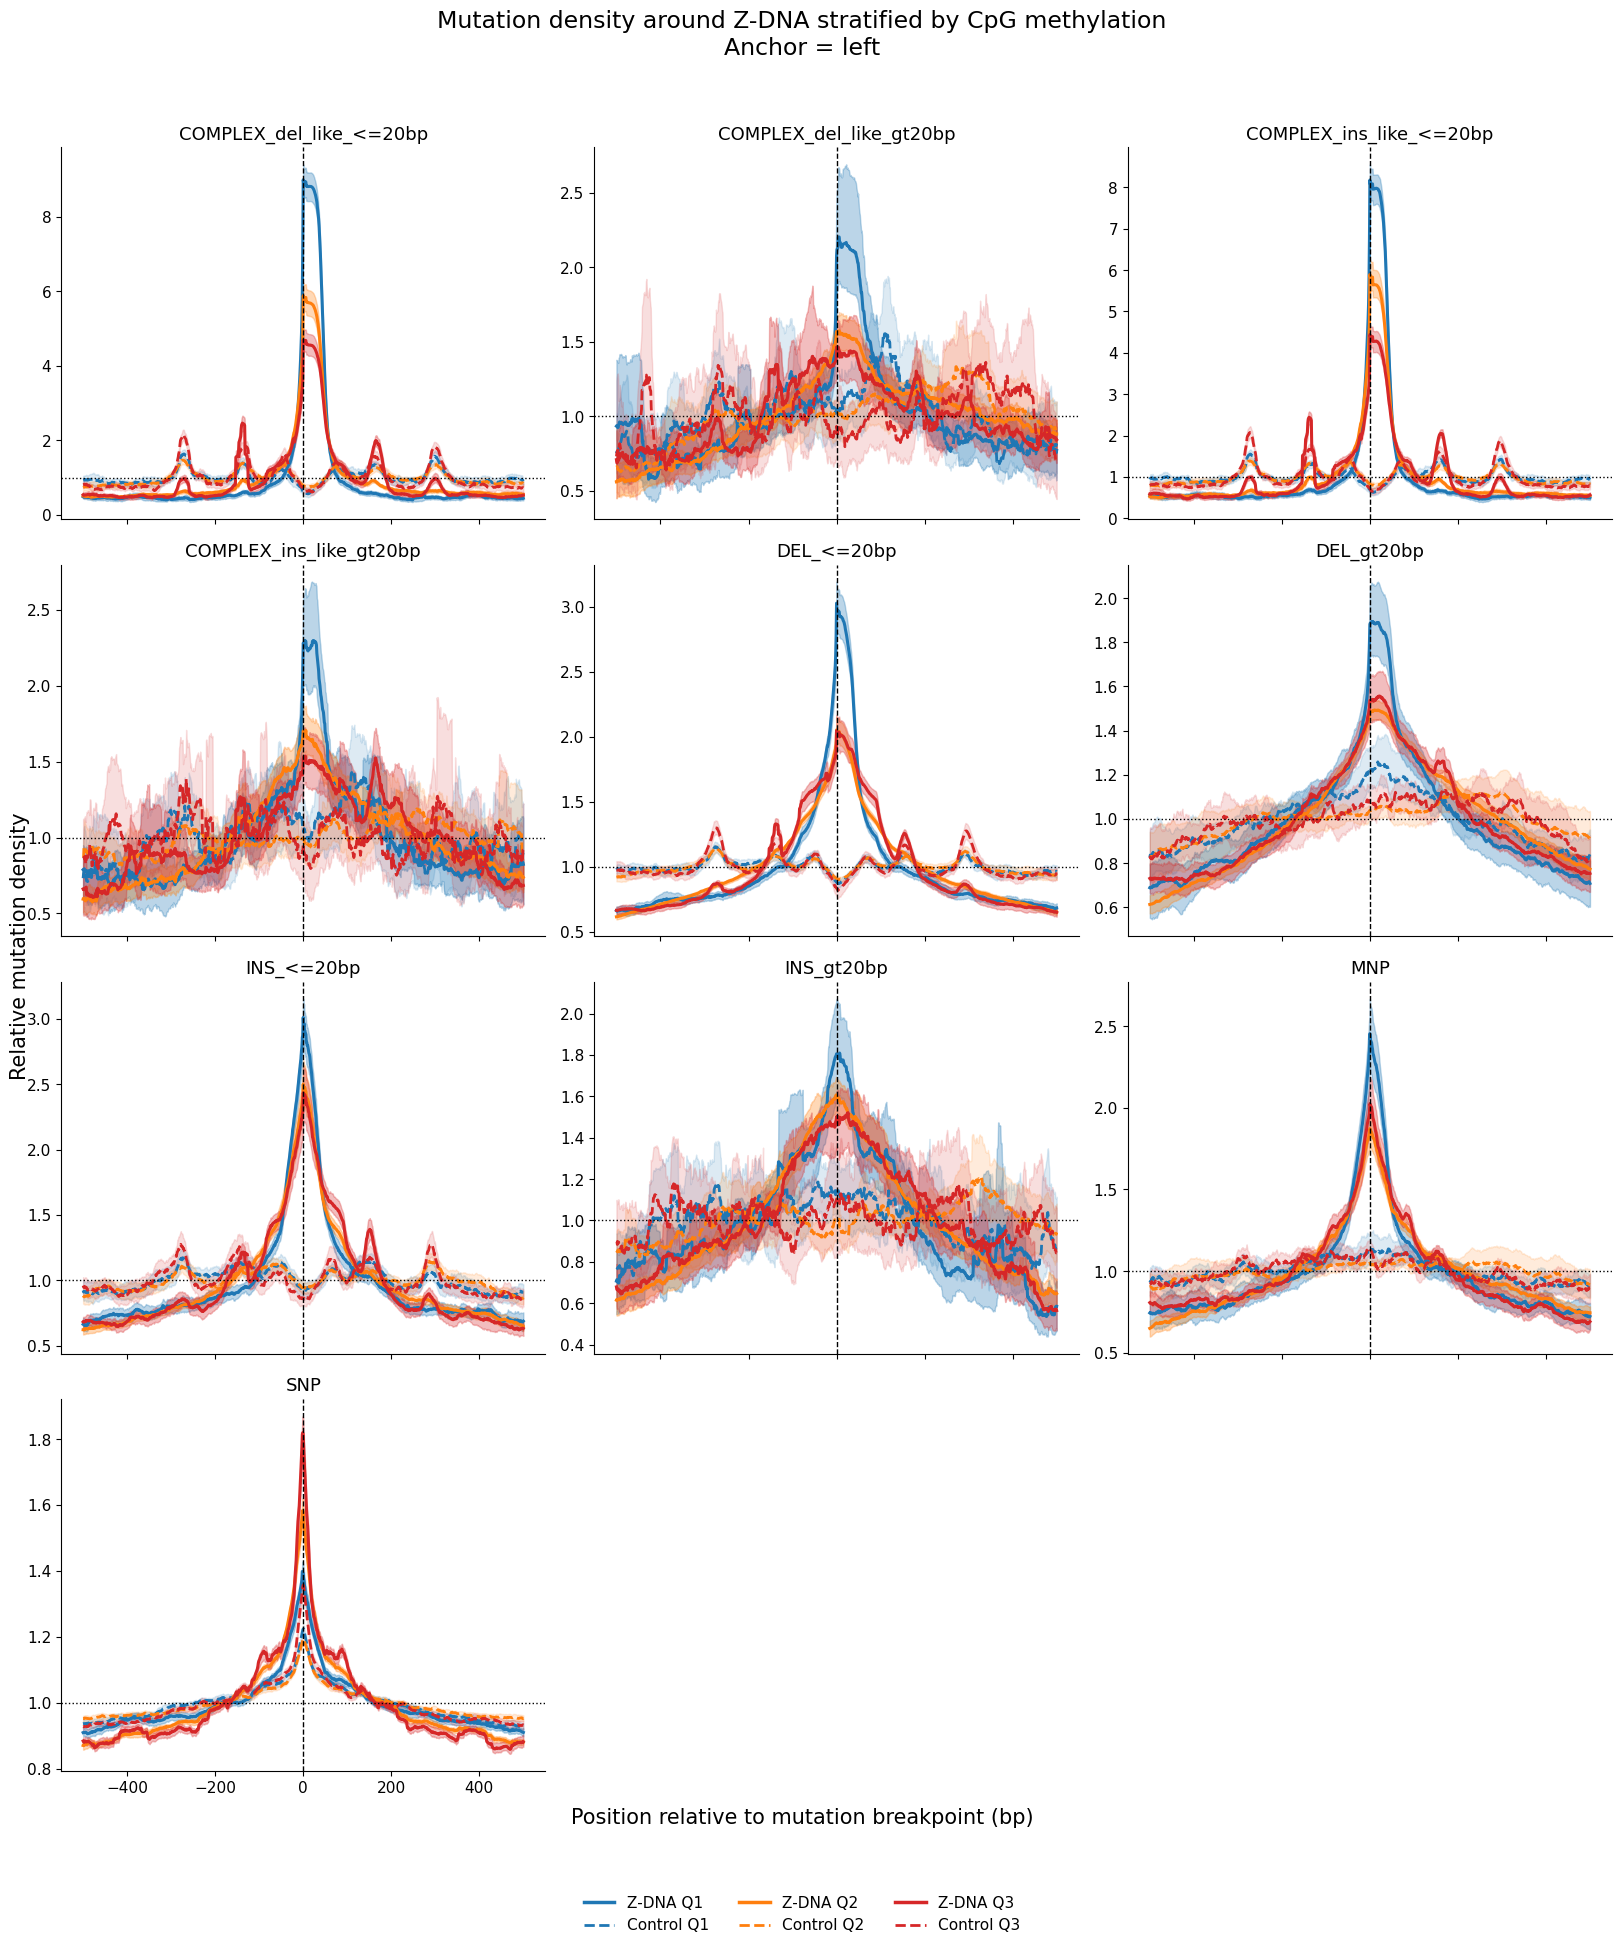

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import math

# ============================================================
# CONFIG
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

ANCHOR_MODE = "left"
N_BINS = 3

INDIR = Path(
    f"{BASE}/mutation_profiles_methstrat_tol10_{ANCHOR_MODE}_Q{N_BINS}"
)

BIN_ORDER = ["Q1", "Q2", "Q3"]
BIN_COLORS = {
    "Q1": "#1f77b4",
    "Q2": "#ff7f0e",
    "Q3": "#d62728",
}

# ============================================================
# DISCOVER STRATA
# ============================================================
paths = list(INDIR.glob("profile_*__Q1.tsv"))
if not paths:
    raise RuntimeError("No profile files found")

STRATA = sorted(
    p.name.replace("profile_", "").replace("__Q1.tsv", "")
    for p in paths
)

print(f"[INFO] Found {len(STRATA)} mutation strata")

# ============================================================
# FIGURE LAYOUT
# ============================================================
n_panels = len(STRATA)
n_cols = 3
n_rows = math.ceil(n_panels / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5.5 * n_cols, 4.5 * n_rows),
    sharex=True,
    sharey=False
)

axes = axes.flatten()

# ============================================================
# MAIN LOOP
# ============================================================
for ax, stratum in zip(axes, STRATA):

    dfs = {}
    for q in BIN_ORDER:
        path = INDIR / f"profile_{stratum}__{q}.tsv"
        if not path.exists():
            dfs = None
            break
        dfs[q] = pd.read_csv(path, sep="\t")

    if dfs is None:
        ax.set_visible(False)
        continue

    offsets = dfs[BIN_ORDER[0]]["offset"].to_numpy()

    for q in BIN_ORDER:
        d = dfs[q]
        col = BIN_COLORS[q]

        # Z-DNA
        ax.plot(offsets, d["Z_mean"], lw=2.2, color=col)
        ax.fill_between(offsets, d["Z_lo"], d["Z_hi"], color=col, alpha=0.30)

        # Control
        ax.plot(offsets, d["C_mean"], lw=2.0, ls="--", color=col)
        ax.fill_between(offsets, d["C_lo"], d["C_hi"], color=col, alpha=0.15)

    ax.axvline(0, color="black", ls="--", lw=1)
    ax.axhline(1, color="black", ls=":", lw=1)

    ax.set_title(stratum, fontsize=13)
    ax.tick_params(labelsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Hide unused axes
for ax in axes[len(STRATA):]:
    ax.set_visible(False)

# ============================================================
# GLOBAL LABELS
# ============================================================
fig.supxlabel(
    "Position relative to mutation breakpoint (bp)",
    fontsize=15
)
fig.supylabel(
    "Relative mutation density",
    fontsize=15
)

fig.suptitle(
    f"Mutation density around Z-DNA stratified by CpG methylation\n"
    f"Anchor = {ANCHOR_MODE}",
    fontsize=17,
    y=1.02
)

# ============================================================
# LEGEND (ONCE)
# ============================================================
from matplotlib.lines import Line2D

legend_handles = []
for q in BIN_ORDER:
    legend_handles.append(
        Line2D([0], [0], color=BIN_COLORS[q], lw=2.5, label=f"Z-DNA {q}")
    )
    legend_handles.append(
        Line2D([0], [0], color=BIN_COLORS[q], lw=2.0, ls="--", label=f"Control {q}")
    )

fig.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=11,
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout()
plt.show()


[INFO] Found 10 mutation strata


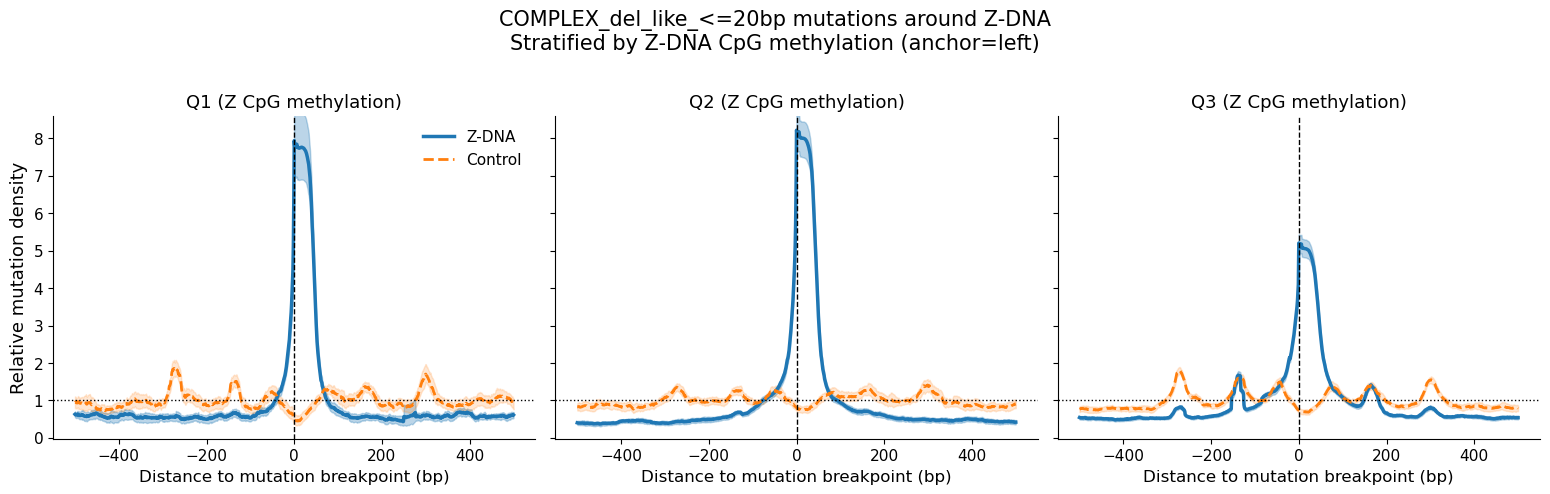

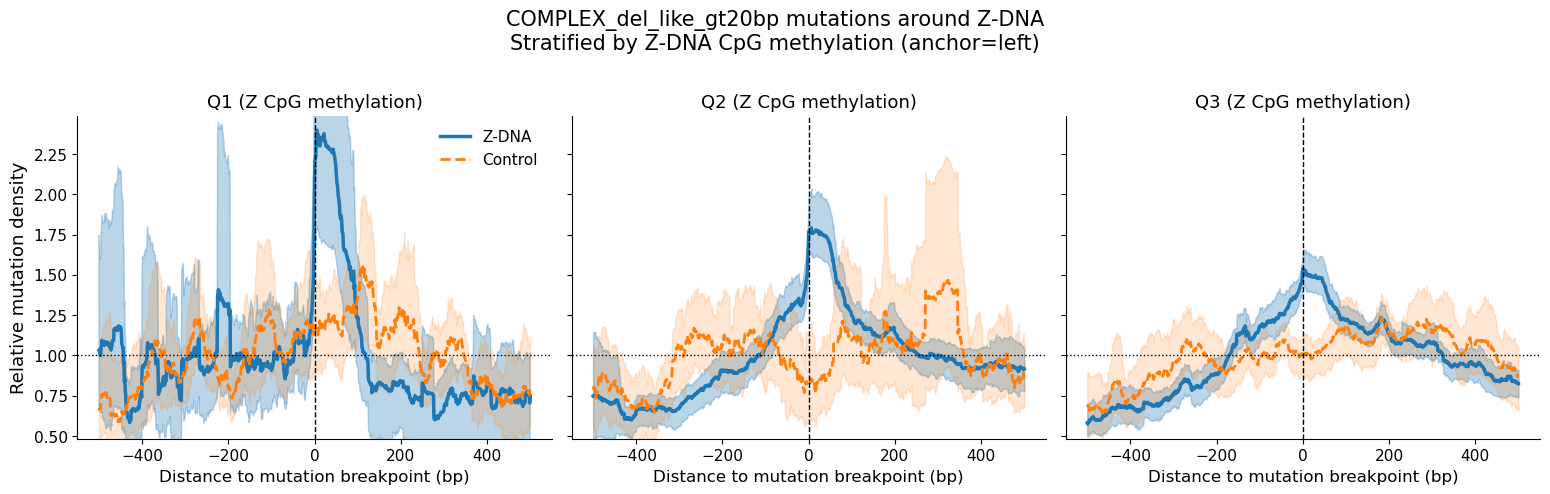

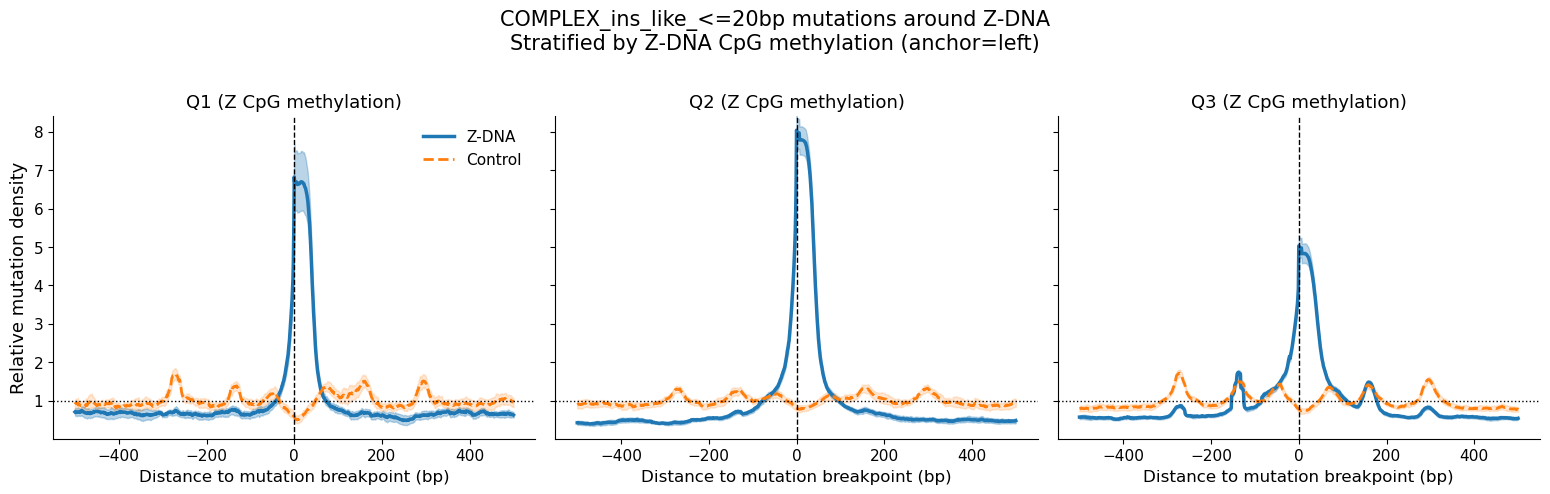

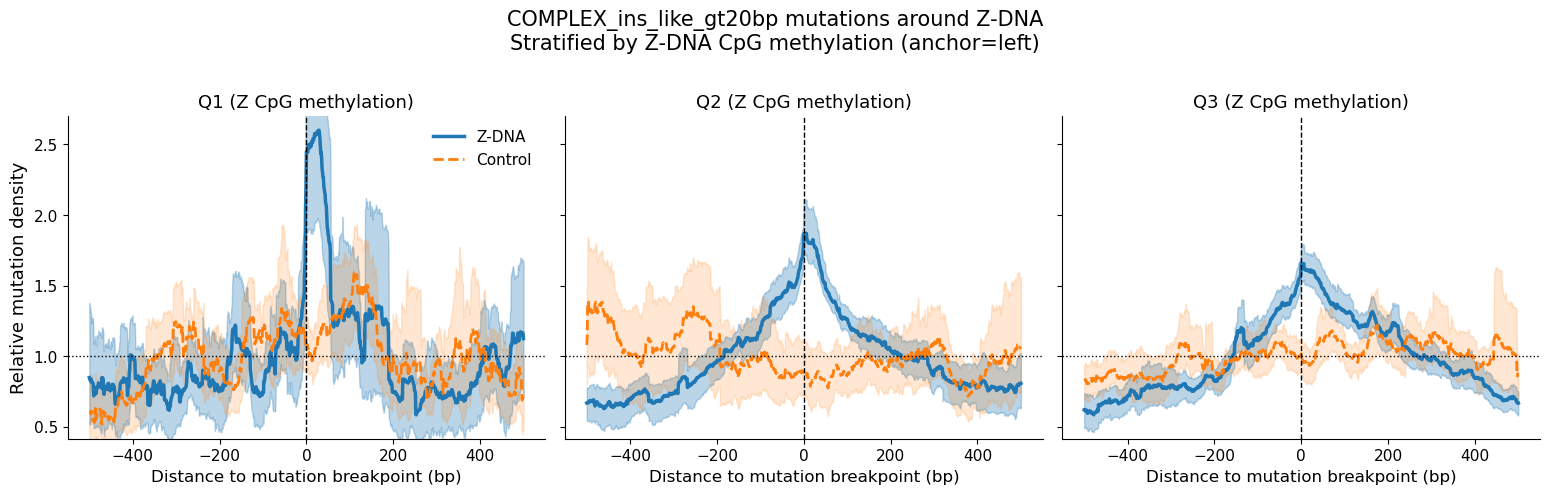

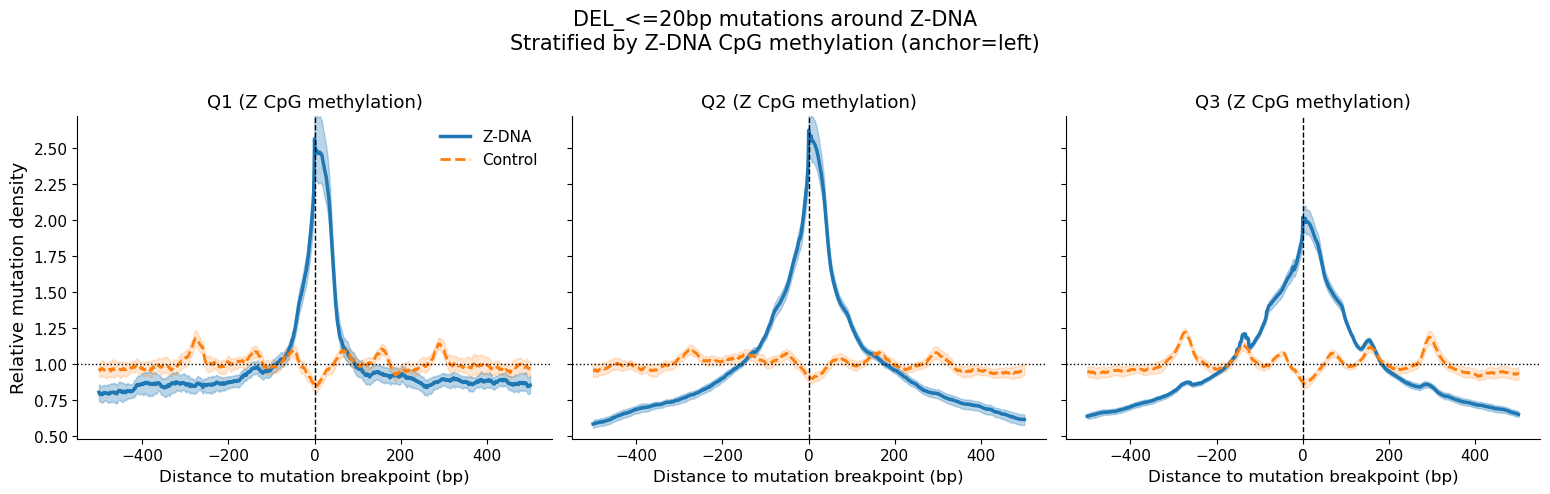

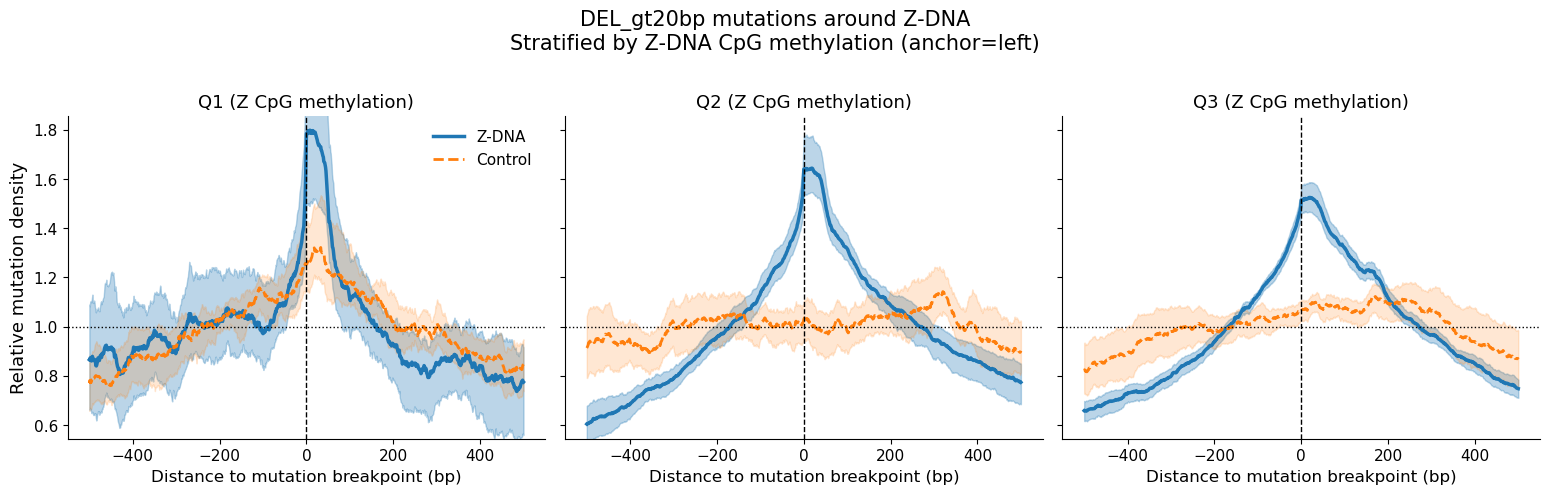

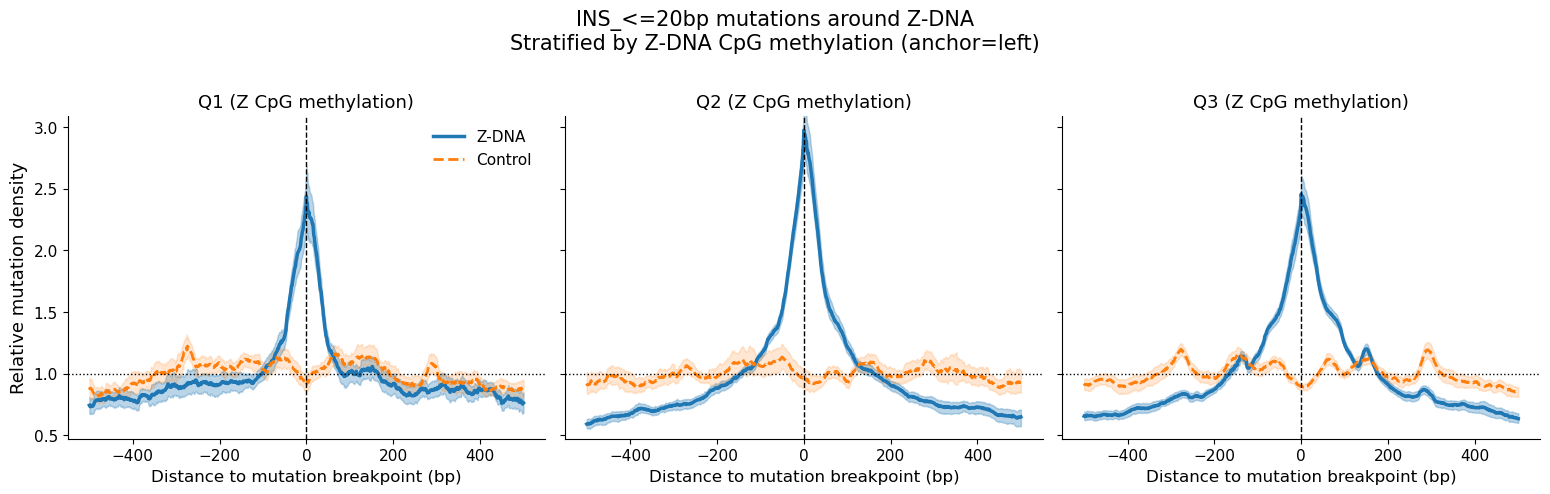

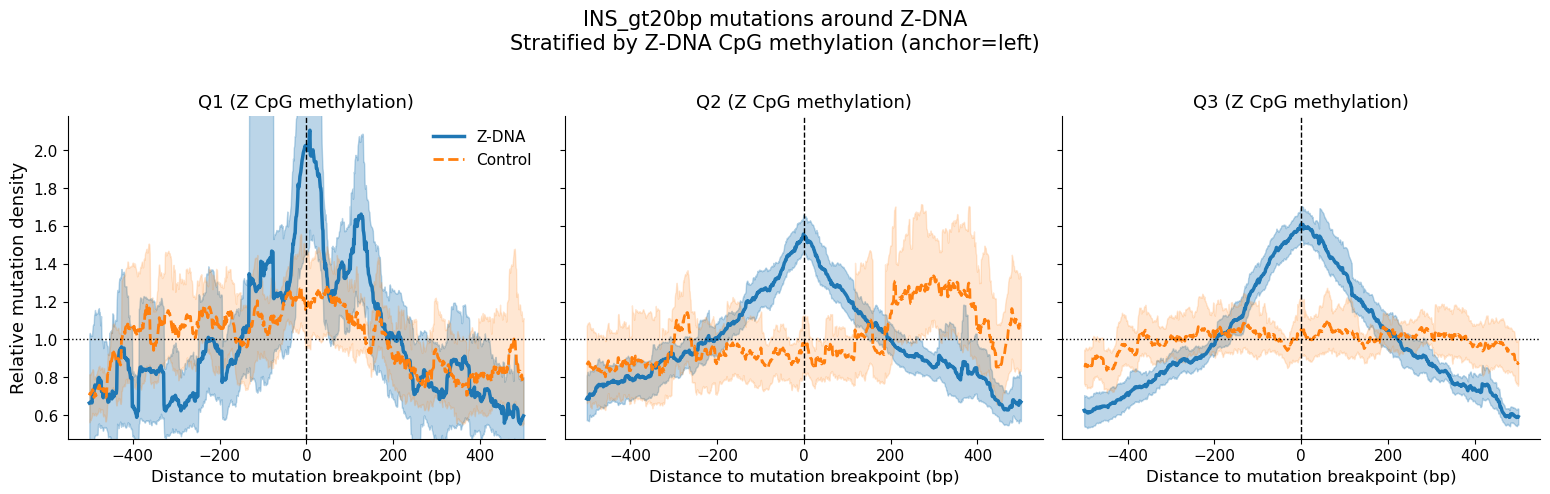

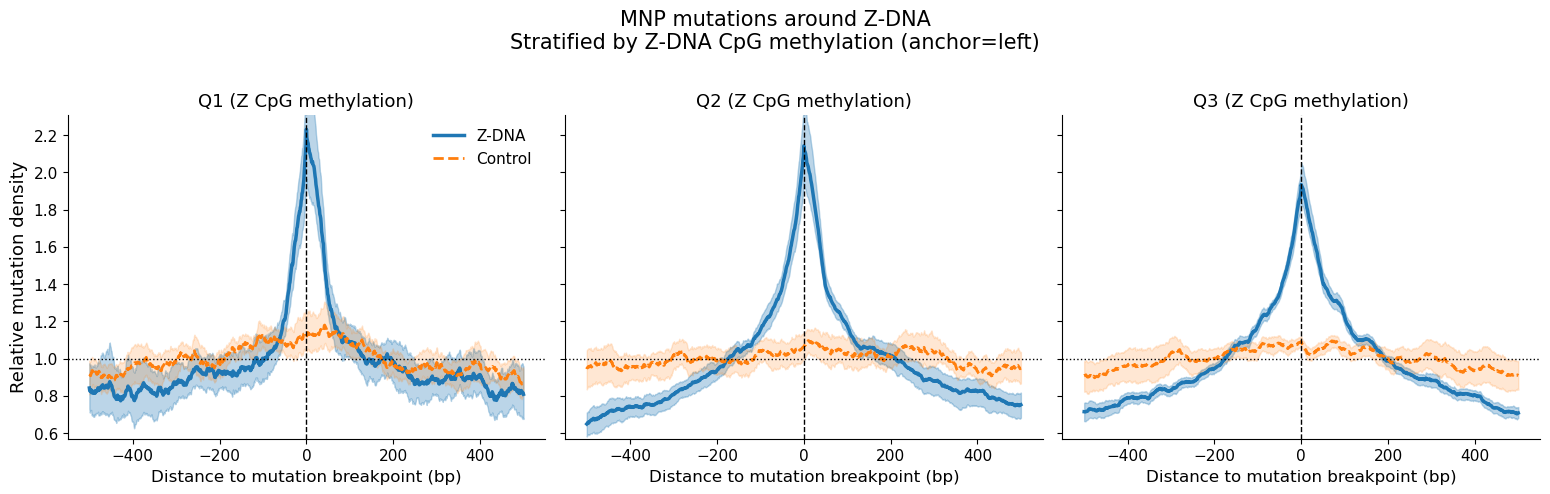

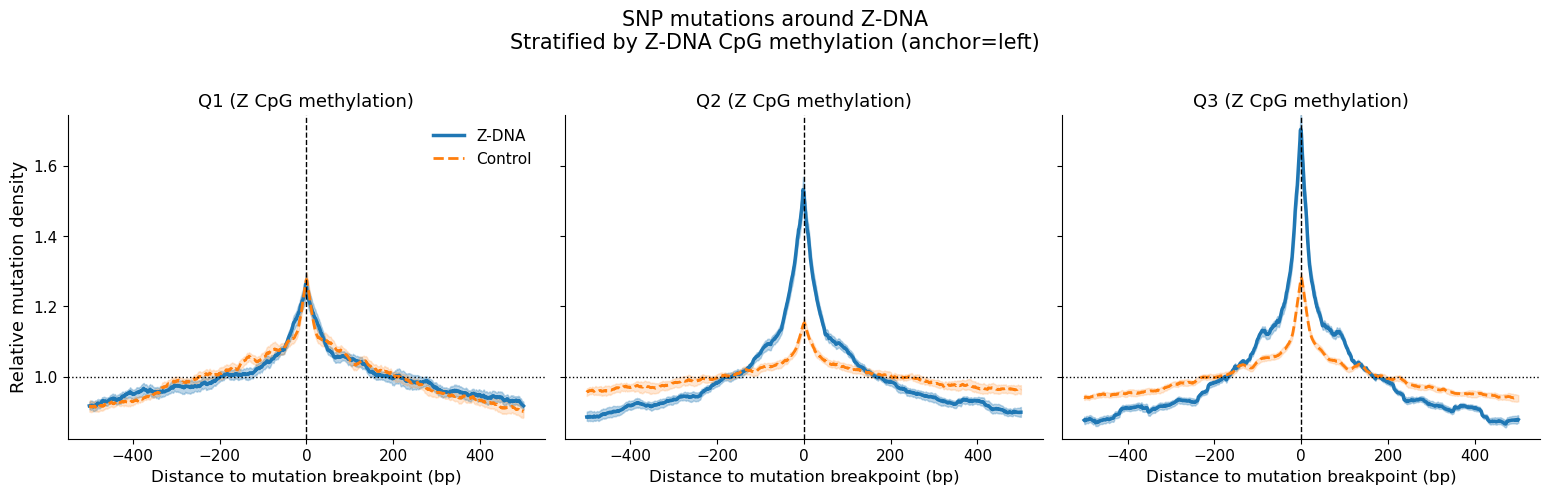

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

ANCHOR_MODE = "left"
N_BINS = 3

INDIR = Path(
    f"{BASE}/mutation_profiles_methstrat_tol10_{ANCHOR_MODE}_Q{N_BINS}"
)

BIN_ORDER = ["Q1", "Q2", "Q3"]
COLORS = {
    "Z": "tab:blue",
    "C": "tab:orange",
}

# ============================================================
# DISCOVER MUTATION STRATA
# ============================================================
paths = sorted(INDIR.glob("profile_*__Q1.tsv"))
STRATA = [
    p.name.replace("profile_", "").replace("__Q1.tsv", "")
    for p in paths
]

print(f"[INFO] Found {len(STRATA)} mutation strata")

# ============================================================
# LOOP OVER STRATA
# ============================================================
for STRATUM in STRATA:

    # -------------------------
    # Load data for this stratum
    # -------------------------
    dfs = {}
    for q in BIN_ORDER:
        path = INDIR / f"profile_{STRATUM}__{q}.tsv"
        if not path.exists():
            dfs = None
            break
        dfs[q] = pd.read_csv(path, sep="\t")

    if dfs is None:
        print(f"[SKIP] {STRATUM} (missing bins)")
        continue

    offsets = dfs[BIN_ORDER[0]]["offset"].to_numpy()

    # -------------------------
    # Plot: one panel per bin
    # -------------------------
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(BIN_ORDER),
        figsize=(5.2 * len(BIN_ORDER), 4.8),
        sharey=True   # <-- each panel gets its own y-scale
    )

    for ax, q in zip(axes, BIN_ORDER):
        d = dfs[q]

        # Z-DNA
        ax.plot(offsets, d["Z_mean"], lw=2.5, color=COLORS["Z"], label="Z-DNA")
        ax.fill_between(offsets, d["Z_lo"], d["Z_hi"],
                        color=COLORS["Z"], alpha=0.30)

        # Control
        ax.plot(offsets, d["C_mean"], lw=2.0, ls="--",
                color=COLORS["C"], label="Control")
        ax.fill_between(offsets, d["C_lo"], d["C_hi"],
                        color=COLORS["C"], alpha=0.18)

        ax.axvline(0, color="black", ls="--", lw=1)
        ax.axhline(1, color="black", ls=":", lw=1)

        ax.set_title(f"{q} (Z CpG methylation)", fontsize=13)
        ax.set_xlabel("Distance to mutation breakpoint (bp)", fontsize=12)

        ax.tick_params(labelsize=11)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # enforce local autoscaling
        ax.relim()
        ax.autoscale(axis="y")

    axes[0].set_ylabel("Relative mutation density", fontsize=13)
    axes[0].legend(frameon=False, fontsize=11)

    fig.suptitle(
        f"{STRATUM} mutations around Z-DNA\n"
        f"Stratified by Z-DNA CpG methylation (anchor={ANCHOR_MODE})",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    plt.show()


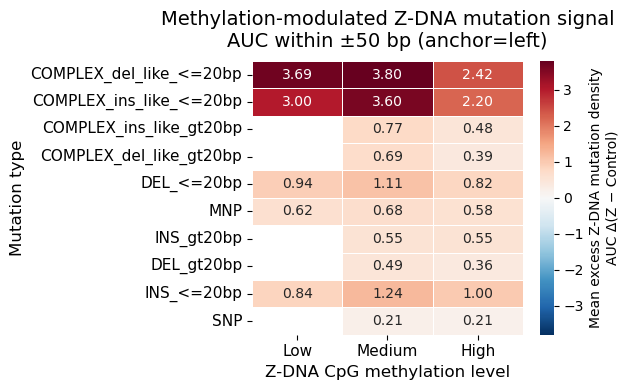

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/methstrat_AUCdelta_heatmap.png


In [71]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
ANCHOR_MODE = "left"
N_BINS = 3

INDIR = Path(
    f"{BASE}/mutation_profiles_methstrat_tol10_{ANCHOR_MODE}_Q{N_BINS}"
)

OUTFIG = INDIR.parent / "methstrat_AUCdelta_heatmap.png"

BIN_ORDER = ["Q1", "Q2", "Q3"]
BIN_LABELS = ["Low", "Medium", "High"]

WINDOW_BP = 50

# ============================================================
# DISCOVER STRATA
# ============================================================
paths = sorted(INDIR.glob("profile_*__Q1.tsv"))
if not paths:
    raise RuntimeError("No profile files found")

STRATA = [
    p.name.replace("profile_", "").replace("__Q1.tsv", "")
    for p in paths
]

# ============================================================
# HELPERS
# ============================================================
def compute_auc_delta(df, window):
    m = df[np.abs(df["offset"]) <= window]
    if m.empty:
        return np.nan
    return float(np.mean(m["Z_mean"] - m["C_mean"]))

def compute_ci_width(df, window):
    m = df[np.abs(df["offset"]) <= window]
    if m.empty:
        return np.nan
    lo = np.mean(m["Z_lo"] - m["C_hi"])
    hi = np.mean(m["Z_hi"] - m["C_lo"])
    return hi - lo

# ============================================================
# BUILD MATRICES
# ============================================================
auc_mat = pd.DataFrame(index=STRATA, columns=BIN_ORDER, dtype=float)
mask_mat = pd.DataFrame(index=STRATA, columns=BIN_ORDER, dtype=bool)

for stratum in STRATA:
    for q in BIN_ORDER:
        path = INDIR / f"profile_{stratum}__{q}.tsv"
        if not path.exists():
            continue

        df = pd.read_csv(path, sep="\t")

        auc = compute_auc_delta(df, WINDOW_BP)
        ciw = compute_ci_width(df, WINDOW_BP)

        auc_mat.loc[stratum, q] = auc

        # mask if effect smaller than uncertainty
        if np.isfinite(auc) and np.isfinite(ciw):
            mask_mat.loc[stratum, q] = abs(auc) < 0.5 * ciw
        else:
            mask_mat.loc[stratum, q] = True

# ============================================================
# ORDER STRATA BY Q3 − Q1 CONTRAST
# ============================================================
contrast = auc_mat["Q3"] - auc_mat["Q1"]
order = contrast.sort_values().index

auc_mat = auc_mat.loc[order]
mask_mat = mask_mat.loc[order]

# ============================================================
# COLOR SCALE (SYMMETRIC)
# ============================================================
vmax = np.nanmax(np.abs(auc_mat.values))
vmax = max(vmax, 1e-6)  # safety

# ============================================================
# PLOT
# ============================================================
fig, ax = plt.subplots(
    figsize=(6.2, max(4, 0.4 * len(order)))
)

sns.heatmap(
    auc_mat,
    mask=mask_mat,
    cmap="RdBu_r",
    center=0.0,
    vmin=-vmax,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={
        "label": "Mean excess Z-DNA mutation density\nAUC Δ(Z − Control)"
    },
    ax=ax,
)

ax.set_xlabel("Z-DNA CpG methylation level", fontsize=12)
ax.set_ylabel("Mutation type", fontsize=12)

ax.set_xticklabels(BIN_LABELS, fontsize=11)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=11)

ax.set_title(
    "Methylation-modulated Z-DNA mutation signal\n"
    f"AUC within ±{WINDOW_BP} bp (anchor={ANCHOR_MODE})",
    fontsize=14,
    pad=10,
)

plt.tight_layout()
plt.savefig(OUTFIG, dpi=600, bbox_inches="tight")
plt.show()

print(f"[OK] Wrote {OUTFIG}")


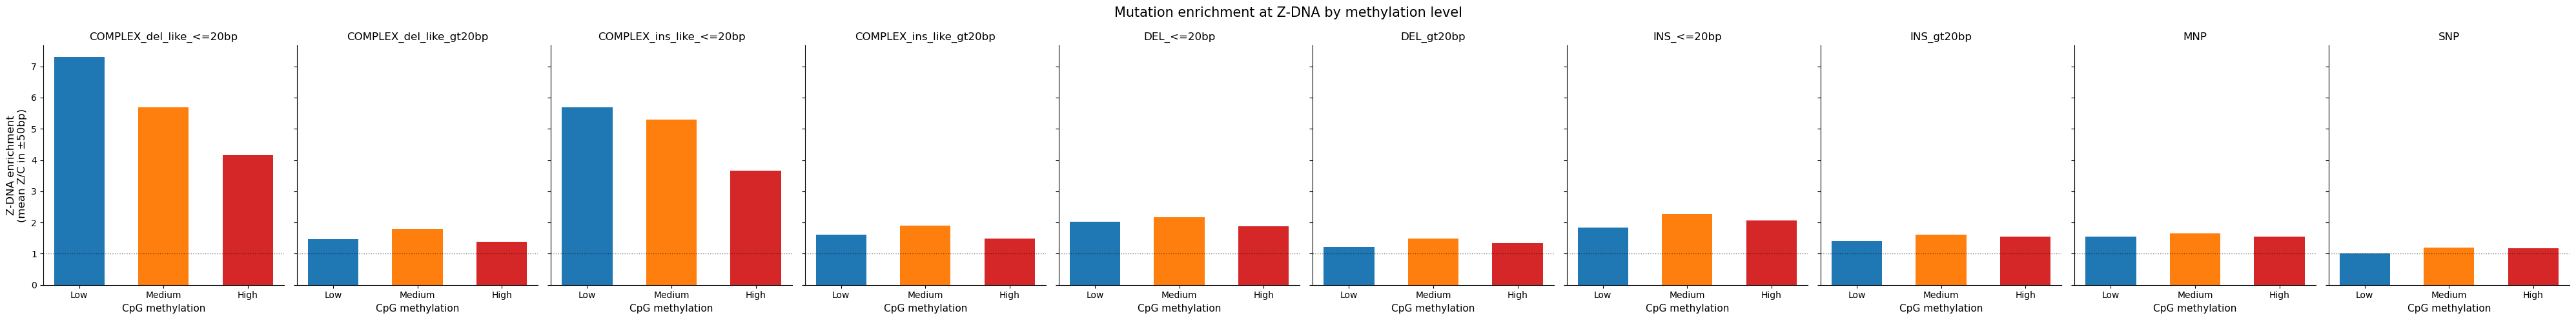

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
ANCHOR_MODE = "left"
N_BINS = 3
INDIR = Path(f"{BASE}/mutation_profiles_methstrat_tol10_{ANCHOR_MODE}_Q{N_BINS}")

BIN_ORDER = ["Q1", "Q2", "Q3"]
BIN_COLORS = {"Q1": "#1f77b4", "Q2": "#ff7f0e", "Q3": "#d62728"}

paths = list(INDIR.glob("profile_*__Q1.tsv"))
STRATA = sorted(p.name.replace("profile_", "").replace("__Q1.tsv", "") for p in paths)

# Collect peak enrichments
results = []
for stratum in STRATA:
    for q in BIN_ORDER:
        path = INDIR / f"profile_{stratum}__{q}.tsv"
        if not path.exists():
            continue
        
        d = pd.read_csv(path, sep="\t")
        
        # Get enrichment in window around breakpoint (-50 to +50 bp)
        window = d[d["offset"].between(-50, 50)]
        peak_enrichment = (window["Z_mean"] / window["C_mean"]).mean()
        
        results.append({
            "stratum": stratum,
            "meth_bin": q,
            "peak_enrichment": peak_enrichment
        })

df_results = pd.DataFrame(results)

# Plot
fig, axes = plt.subplots(1, len(STRATA), figsize=(4*len(STRATA), 5), sharey=True)
if len(STRATA) == 1:
    axes = [axes]

x_pos = np.arange(len(BIN_ORDER))
width = 0.6

for ax, stratum in zip(axes, STRATA):
    sub = df_results[df_results["stratum"] == stratum]
    
    bars = ax.bar(x_pos, sub["peak_enrichment"], width, 
                  color=[BIN_COLORS[q] for q in sub["meth_bin"]])
    
    ax.axhline(1, color="black", ls=":", lw=1, alpha=0.5)
    ax.set_title(stratum, fontsize=12)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(["Low", "Medium", "High"], fontsize=10)
    ax.set_xlabel("CpG methylation", fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Z-DNA enrichment\n(mean Z/C in ±50bp)", fontsize=12)
fig.suptitle("Mutation enrichment at Z-DNA by methylation level", fontsize=15)

plt.tight_layout()
plt.savefig(INDIR.parent / "peak_enrichment_by_methylation.png", dpi=300, bbox_inches="tight")
plt.show()

[INFO] Found 10 mutation strata


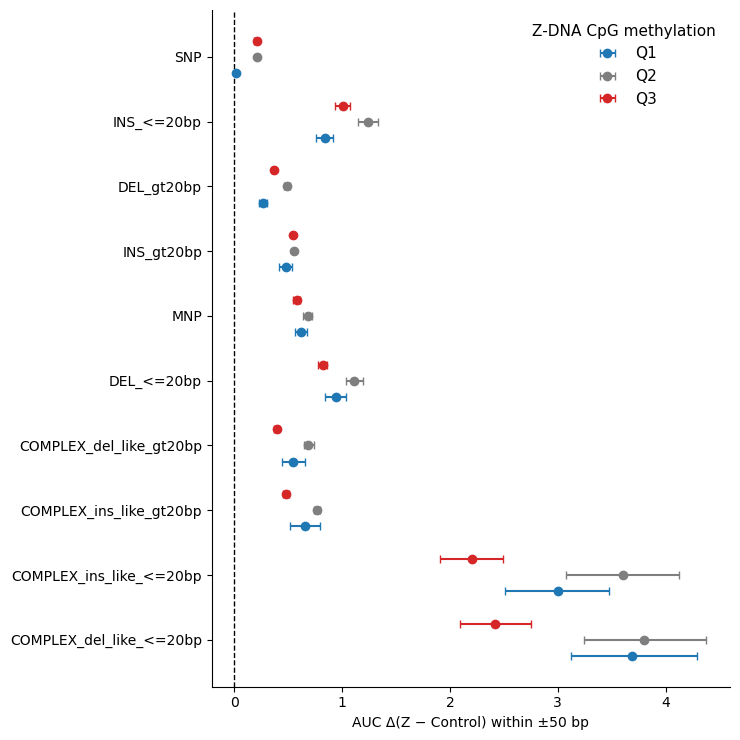

[OK] Wrote /work/10906/geomeg/vista/pangenomes_zdna/mutation_profiles_methstrat_AUCdelta_left.png


In [72]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"

ANCHOR_MODE = "left"
N_BINS = 3
BIN_ORDER = ["Q1", "Q2", "Q3"]

INDIR = Path(
    f"{BASE}/mutation_profiles_methstrat_tol10_{ANCHOR_MODE}_Q{N_BINS}"
)

OUTFIG = Path(
    f"{BASE}/mutation_profiles_methstrat_AUCdelta_{ANCHOR_MODE}.png"
)

# biological window around breakpoint
WINDOW_BP = 50     # ±25 bp
CI_LOW, CI_HIGH = 2.5, 97.5
N_BOOT = 1000

BIN_COLORS = {
    "Q1": "#1f77b4",
    "Q2": "#7f7f7f",
    "Q3": "#d62728",
}

# ============================================================
# DISCOVER STRATA
# ============================================================
paths = sorted(INDIR.glob("profile_*__Q1.tsv"))
if not paths:
    raise RuntimeError("No profile files found")

STRATA = [
    p.name.replace("profile_", "").replace("__Q1.tsv", "")
    for p in paths
]

print(f"[INFO] Found {len(STRATA)} mutation strata")

# ============================================================
# HELPERS
# ============================================================
def auc_delta(df, window_bp):
    """Mean(Z - C) within ±window_bp."""
    m = df[np.abs(df["offset"]) <= window_bp]
    if m.empty:
        return np.nan
    return float(np.mean(m["Z_mean"] - m["C_mean"]))

def bootstrap_auc(df, window_bp, n_boot):
    """
    Bootstrap AUC by chromosome.
    Requires per-offset Z_mean/C_mean already aggregated,
    so we resample offsets with replacement (chrom-level already baked in).
    """
    m = df[np.abs(df["offset"]) <= window_bp]
    if m.empty:
        return (np.nan, np.nan)

    deltas = (m["Z_mean"] - m["C_mean"]).to_numpy()
    if np.all(~np.isfinite(deltas)):
        return (np.nan, np.nan)

    rng = np.random.default_rng(42)
    boots = []

    for _ in range(n_boot):
        idx = rng.integers(0, len(deltas), len(deltas))
        boots.append(np.nanmean(deltas[idx]))

    lo, hi = np.nanpercentile(boots, [CI_LOW, CI_HIGH])
    return float(lo), float(hi)

# ============================================================
# COLLECT RESULTS
# ============================================================
rows = []

for stratum in STRATA:
    for q in BIN_ORDER:
        path = INDIR / f"profile_{stratum}__{q}.tsv"
        if not path.exists():
            continue

        df = pd.read_csv(path, sep="\t")

        auc = auc_delta(df, WINDOW_BP)
        lo, hi = bootstrap_auc(df, WINDOW_BP, N_BOOT)

        rows.append(dict(
            stratum=stratum,
            meth_bin=q,
            auc_delta=auc,
            ci_lo=lo,
            ci_hi=hi,
        ))

res = pd.DataFrame(rows)

if res.empty:
    raise RuntimeError("No AUC results computed")

# ============================================================
# ORDER STRATA BY EFFECT SIZE (Q3 − Q1)
# ============================================================
pivot = res.pivot(index="stratum", columns="meth_bin", values="auc_delta")
order = (
    pivot["Q3"] - pivot["Q1"]
).sort_values().index.tolist()

res["stratum"] = pd.Categorical(
    res["stratum"],
    categories=order,
    ordered=True
)

# ============================================================
# PLOT
# ============================================================
fig, ax = plt.subplots(
    figsize=(7.5, max(4, 0.75 * len(order)))
)

ypos = np.arange(len(order))
offsets = {"Q1": -0.25, "Q2": 0.0, "Q3": 0.25}

for q in BIN_ORDER:
    sub = res[res["meth_bin"] == q].sort_values("stratum")

    ax.errorbar(
        sub["auc_delta"],
        ypos + offsets[q],
        xerr=[
            sub["auc_delta"] - sub["ci_lo"],
            sub["ci_hi"] - sub["auc_delta"],
        ],
        fmt="o",
        color=BIN_COLORS[q],
        ecolor=BIN_COLORS[q],
        capsize=3,
        markersize=6,
        label=q,
        zorder=3,
    )

ax.axvline(0, color="black", lw=1, ls="--")

ax.set_yticks(ypos)
ax.set_yticklabels(order)
ax.set_xlabel(f"AUC Δ(Z − Control) within ±{WINDOW_BP} bp")
# ax.set_title(
#     "Methylation-dependent Z-DNA mutation signal\n"
#     f"AUC around breakpoint (anchor={ANCHOR_MODE})"
# )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Z-DNA CpG methylation",
    frameon=False,
    fontsize=11,
    title_fontsize=11,
    loc="upper right",
)

plt.tight_layout()
plt.savefig(OUTFIG, dpi=600)
plt.show()

print(f"[OK] Wrote {OUTFIG}")


## MNAse-seq analysis

### Resource

In [ ]:
# https://www.encodeproject.org/search/?type=Experiment&control_type!=*&assay_term_name=MNase-seq&status=released

### K562

In [3]:
import pandas as pd
from pathlib import Path

BASE = Path("/work/10906/geomeg/vista/pangenomes_zdna")
MASTER = BASE / "controls_combined/CHM13_controls_MASTER.tsv"
OUTDIR = BASE / "mnase_K562"
OUTDIR.mkdir(exist_ok=True)

TOL = "10%"

m = pd.read_csv(MASTER, sep="\t", dtype={"Chromosome": str})

m["has_control"] = m["has_control"].astype(str).map({"True": True, "False": False})

m = (
    m[
        (m["tol_level"] == TOL) &
        (m["has_control"]) &
        (m["Chromosome"] != "chrY")
    ]
    .drop_duplicates(subset=["Chromosome", "Start0", "End0"])
    .reset_index(drop=True)
)

############################
# Z-DNA BED
############################
z = m[["Chromosome", "Start0", "End0"]].copy()
z.columns = ["chrom", "start", "end"]
z = z.astype({"start": int, "end": int})
z["name"] = [f"Z{i:06d}" for i in range(len(z))]
z["score"] = 0
z["strand"] = "."

z_bed = OUTDIR / "ZDNA_tol10.bed"
z[["chrom", "start", "end", "name", "score", "strand"]].to_csv(
    z_bed, sep="\t", header=False, index=False
)

############################
# CONTROL BED
############################
c = m[["Chromosome", "Ctrl_Start", "Ctrl_End"]].copy()
c.columns = ["chrom", "start", "end"]
c = c.astype({"start": int, "end": int})
c["name"] = [f"C{i:06d}" for i in range(len(c))]
c["score"] = 0
c["strand"] = "."

c_bed = OUTDIR / "CTRL_tol10.bed"
c[["chrom", "start", "end", "name", "score", "strand"]].to_csv(
    c_bed, sep="\t", header=False, index=False
)

print("Wrote:")
print(z_bed)
print(c_bed)


Wrote:
/work/10906/geomeg/vista/pangenomes_zdna/mnase_K562/ZDNA_tol10.bed
/work/10906/geomeg/vista/pangenomes_zdna/mnase_K562/CTRL_tol10.bed


In [ ]:
#!/usr/bin/env bash
set -euo pipefail

BASE="/work/10906/geomeg/vista/pangenomes_zdna"
MNASE="$BASE/mnase_K562"

BW="$MNASE/ENCFF000VNN.chm13v2.bigWig"
CHROMSIZES="$MNASE/hs1.chrom.sizes.txt"

ZBED="$MNASE/ZDNA_tol10.bed"
CBED="$MNASE/CTRL_tol10.bed"

WINDOW=100
BINSIZE=5
SHIFT=1000

############################
# sort BEDs
############################
sort -k1,1 -k2,2n "$ZBED" > "$MNASE/ZDNA_tol10.sorted.bed"
sort -k1,1 -k2,2n "$CBED" > "$MNASE/CTRL_tol10.sorted.bed"

ZBED="$MNASE/ZDNA_tol10.sorted.bed"
CBED="$MNASE/CTRL_tol10.sorted.bed"

############################
# junction anchors (1 bp)
############################
awk 'BEGIN{OFS="\t"} {print $1,$2,$2+1}' "$ZBED" > "$MNASE/ZDNA_start_1bp.bed"
awk 'BEGIN{OFS="\t"} {print $1,$3-1,$3}' "$ZBED" > "$MNASE/ZDNA_end_1bp.bed"

awk 'BEGIN{OFS="\t"} {print $1,$2,$2+1}' "$CBED" > "$MNASE/CTRL_start_1bp.bed"
awk 'BEGIN{OFS="\t"} {print $1,$3-1,$3}' "$CBED" > "$MNASE/CTRL_end_1bp.bed"

############################
# chromosome-safe filtering
############################
filter_valid () {
  bedtools slop \
    -i "$1" \
    -g "$CHROMSIZES" \
    -b "$WINDOW" \
  | awk '($2 >= 0)' \
  > "$2"
}

filter_valid "$MNASE/ZDNA_start_1bp.bed" "$MNASE/ZDNA_start_1bp.valid.bed"
filter_valid "$MNASE/ZDNA_end_1bp.bed"   "$MNASE/ZDNA_end_1bp.valid.bed"
filter_valid "$MNASE/CTRL_start_1bp.bed" "$MNASE/CTRL_start_1bp.valid.bed"
filter_valid "$MNASE/CTRL_end_1bp.bed"   "$MNASE/CTRL_end_1bp.valid.bed"

############################
# shifted negative controls
############################
awk -v S=$SHIFT 'BEGIN{OFS="\t"} {print $1,$2+S,$3+S}' \
  "$MNASE/ZDNA_start_1bp.valid.bed" > "$MNASE/ZDNA_start_shifted.bed"

awk -v S=$SHIFT 'BEGIN{OFS="\t"} {print $1,$2+S,$3+S}' \
  "$MNASE/CTRL_start_1bp.valid.bed" > "$MNASE/CTRL_start_shifted.bed"

filter_valid "$MNASE/ZDNA_start_shifted.bed" "$MNASE/ZDNA_start_shifted.valid.bed"
filter_valid "$MNASE/CTRL_start_shifted.bed" "$MNASE/CTRL_start_shifted.valid.bed"


In [ ]:
computeMatrix reference-point \
  --referencePoint center \
  -b 100 -a 100 \
  --binSize 5 \
  -S "$BW" \
  -R \
    "$MNASE/ZDNA_start_1bp.valid.bed" \
    "$MNASE/CTRL_start_1bp.valid.bed" \
  --sortRegions keep \
  -o "$MNASE/mnase_start.mat.gz" \
  --outFileNameMatrix "$MNASE/mnase_start.matrix.tsv" \
  -p max

computeMatrix reference-point \
  --referencePoint center \
  -b 100 -a 100 \
  --binSize 5 \
  -S "$BW" \
  -R \
    "$MNASE/ZDNA_end_1bp.valid.bed" \
    "$MNASE/CTRL_end_1bp.valid.bed" \
  --sortRegions keep \
  -o "$MNASE/mnase_end.mat.gz" \
  --outFileNameMatrix "$MNASE/mnase_end.matrix.tsv" \
  -p max


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

###############################################################################
# CONFIG
###############################################################################

BASE = Path("/work/10906/geomeg/vista/pangenomes_zdna/mnase_K562")
OUTDIR = BASE / "figures"
OUTDIR.mkdir(exist_ok=True)

MATRICES = {
    "BtoZ": BASE / "mnase_start.matrix.tsv",
    "ZtoB": BASE / "mnase_end.matrix.tsv",
}

WINDOW = 100
MAX_MISSING_FRAC = 0.25
SORT_WINDOW = 20
META_COLS = 6
MAX_ROWS = 50000

# typography
LABEL_FONTSIZE = 14
TICK_FONTSIZE = 12
TITLE_FONTSIZE = 15

###############################################################################
# UTILITIES
###############################################################################

def load_matrix(path):
    df = pd.read_csv(path, sep="\t", comment="#", header=None, low_memory=False)
    vals = df.iloc[:, META_COLS:].apply(pd.to_numeric, errors="coerce")
    return vals.to_numpy(dtype=np.float32)


def filter_regions(arr):
    keep = np.mean(np.isnan(arr), axis=1) <= MAX_MISSING_FRAC
    return arr[keep]


def downsample_rows(A, max_rows=MAX_ROWS):
    if A.shape[0] <= max_rows:
        return A
    idx = np.linspace(0, A.shape[0] - 1, max_rows).astype(int)
    return A[idx]


def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


###############################################################################
# MAIN LOOP
###############################################################################

for label, matrix_path in MATRICES.items():

    print(f"[INFO] Processing {label}")

    vals = load_matrix(matrix_path)

    n = vals.shape[0] // 2
    Z = vals[:n]
    C = vals[n:2*n]

    Z = filter_regions(Z)
    C = filter_regions(C)

    valid_bins = ~(np.all(np.isnan(Z), axis=0) & np.all(np.isnan(C), axis=0))
    Z = Z[:, valid_bins]
    C = C[:, valid_bins]

    x = np.linspace(-WINDOW, WINDOW, Z.shape[1], endpoint=False)

    sort_mask = (x >= -SORT_WINDOW) & (x <= SORT_WINDOW)
    z_score = np.nanmean(Z[:, sort_mask], axis=1)
    order = np.argsort(z_score)[::-1]

    Zs = Z[order]
    Cs = C[order[:C.shape[0]]]

    Zp = downsample_rows(Zs)
    Cp = downsample_rows(Cs)

    combined = np.concatenate([Zp.ravel(), Cp.ravel()])
    combined = combined[~np.isnan(combined)]
    vmin, vmax = np.percentile(combined, [2, 98])

    ###########################################################################
    # FIGURE
    ###########################################################################

    fig = plt.figure(figsize=(7.5, 8.5))

    ax0 = plt.subplot2grid((3, 1), (0, 0))
    ax1 = plt.subplot2grid((3, 1), (1, 0))
    ax2 = plt.subplot2grid((3, 1), (2, 0))

    # profile
    ax0.plot(x, np.nanmean(Z, axis=0), label="Z-DNA", lw=2)
    ax0.plot(x, np.nanmean(C, axis=0), label="Control", lw=2)
    ax0.axvline(0, color="black", ls="--", lw=0.8)
    ax0.set_ylabel("MNase signal", fontsize=LABEL_FONTSIZE)
    ax0.legend(frameon=False, fontsize=LABEL_FONTSIZE)
    ax0.set_title(f"MNase signal at {label} junctions", fontsize=TITLE_FONTSIZE)
    ax0.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax0)

    # Z-DNA heatmap
    im = ax1.imshow(
        Zp,
        aspect="auto",
        interpolation="nearest",
        cmap="cividis",
        vmin=vmin,
        vmax=vmax,
        extent=[x[0], x[-1], Zp.shape[0], 0],
    )
    ax1.axvline(0, color="black", ls="--", lw=0.8)
    ax1.set_ylabel("Regions", fontsize=LABEL_FONTSIZE)
    ax1.set_title("Z-DNA (sorted by ±20 bp mean)", fontsize=TITLE_FONTSIZE)
    ax1.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax1)

    # Control heatmap
    ax2.imshow(
        Cp,
        aspect="auto",
        interpolation="nearest",
        cmap="cividis",
        vmin=vmin,
        vmax=vmax,
        extent=[x[0], x[-1], Cp.shape[0], 0],
    )
    ax2.axvline(0, color="black", ls="--", lw=0.8)
    ax2.set_xlabel("Position relative to junction (bp)", fontsize=LABEL_FONTSIZE)
    ax2.set_ylabel("Regions", fontsize=LABEL_FONTSIZE)
    ax2.set_title("Controls (displayed with Z sorting)", fontsize=TITLE_FONTSIZE)
    ax2.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax2)

    plt.tight_layout()
    fig_path = OUTDIR / f"MNase_heatmap_{label}_python.png"
    plt.savefig(fig_path, dpi=300)
    plt.close(fig)

    ###########################################################################
    # SEPARATE COLORBAR
    ###########################################################################

    fig_cb, ax_cb = plt.subplots(figsize=(1.2, 4))
    cb = plt.colorbar(im, cax=ax_cb)
    cb.set_label("MNase signal", fontsize=LABEL_FONTSIZE)
    cb.ax.tick_params(labelsize=TICK_FONTSIZE)
    #despine(ax_cb)
    plt.tight_layout()
    cb_path = OUTDIR / f"MNase_heatmap_{label}_colorbar.png"
    plt.savefig(cb_path, dpi=300)
    plt.close(fig_cb)

    print(f"  Saved: {fig_path.name}")
    print(f"  Saved: {cb_path.name}")

print("[DONE] All heatmaps generated.")


[INFO] Processing BtoZ


/tmp/ipykernel_2520798/3156830640.py:81: RuntimeWarning: Mean of empty slice
  z_score = np.nanmean(Z[:, sort_mask], axis=1)
/tmp/ipykernel_2520798/3156830640.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 750x850 with 3 Axes> than <Figure size 120x400 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, cax=ax_cb)


  Saved: MNase_heatmap_BtoZ_python.png
  Saved: MNase_heatmap_BtoZ_colorbar.png
[INFO] Processing ZtoB


/tmp/ipykernel_2520798/3156830640.py:81: RuntimeWarning: Mean of empty slice
  z_score = np.nanmean(Z[:, sort_mask], axis=1)


  Saved: MNase_heatmap_ZtoB_python.png
  Saved: MNase_heatmap_ZtoB_colorbar.png
[DONE] All heatmaps generated.


/tmp/ipykernel_2520798/3156830640.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 750x850 with 3 Axes> than <Figure size 120x400 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, cax=ax_cb)


In [ ]:
# We sorted Z-DNA loci by MNase signal within ±20 bp of the junction,
# which reveals strong, coherent chromatin organization at Z-DNA boundaries
# that is absent from matched controls.

### K562 methylation

In [5]:
import pandas as pd
from pathlib import Path
BASE = Path("/work/10906/geomeg/vista/pangenomes_zdna")
MNASE = BASE / "mnase_K562"
METH_FILE = BASE / "zdna_vs_ctrl_methylation_paired.tsv"
OUT_Z_LOW  = MNASE / "ZDNA_low.bed"
OUT_Z_HIGH = MNASE / "ZDNA_high.bed"
OUT_C_LOW  = MNASE / "CTRL_low.bed"
OUT_C_HIGH = MNASE / "CTRL_high.bed"
LOW_Q  = 0.25
HIGH_Q = 0.75
df = pd.read_csv(METH_FILE, sep="\t")
required = {
    "Chromosome",
    "Start0",
    "End0",
    "Ctrl_Start",
    "Ctrl_End",
    "Z_meth"
}
missing = required - set(df.columns)
if missing:
    raise RuntimeError(f"Missing columns: {missing}")
q_lo = df["Z_meth"].quantile(LOW_Q)
q_hi = df["Z_meth"].quantile(HIGH_Q)
low  = df[df["Z_meth"] <= q_lo].copy()
high = df[df["Z_meth"] >= q_hi].copy()
print(f"[INFO] LOW methylation loci : {len(low):,}")
print(f"[INFO] HIGH methylation loci: {len(high):,}")
def write_bed(df, start_col, end_col, outpath, prefix):
    bed = pd.DataFrame({
        "chrom":  df["Chromosome"],
        "start":  df[start_col].astype(int),
        "end":    df[end_col].astype(int),
        "name":   [f"{prefix}{i:06d}" for i in range(len(df))],
        "score":  0,
        "strand": ".",
    })
    bed.to_csv(outpath, sep="\t", header=False, index=False)
write_bed(low,  "Start0",     "End0",     OUT_Z_LOW,  "ZL")
write_bed(high, "Start0",     "End0",     OUT_Z_HIGH, "ZH")
write_bed(low,  "Ctrl_Start", "Ctrl_End", OUT_C_LOW,  "CL")
write_bed(high, "Ctrl_Start", "Ctrl_End", OUT_C_HIGH, "CH")
print("[DONE] Wrote BED files:")
print(" ", OUT_Z_LOW.name)
print(" ", OUT_Z_HIGH.name)
print(" ", OUT_C_LOW.name)
print(" ", OUT_C_HIGH.name)

[INFO] LOW methylation loci : 1,874
[INFO] HIGH methylation loci: 1,867
[DONE] Wrote BED files:
  ZDNA_low.bed
  ZDNA_high.bed
  CTRL_low.bed
  CTRL_high.bed


In [9]:
BASE="/work/10906/geomeg/vista/pangenomes_zdna"
MNASE="$BASE/mnase_K562"
BW="$MNASE/ENCFF000VNN.chm13v2.bigWig"
CHROMSIZES="$MNASE/hs1.chrom.sizes.txt"
WINDOW=100
BINSIZE=5
Z_LOW="$MNASE/ZDNA_low.bed"
Z_HIGH="$MNASE/ZDNA_high.bed"
C_LOW="$MNASE/CTRL_low.bed"
C_HIGH="$MNASE/CTRL_high.bed"
for f in "$Z_LOW" "$Z_HIGH" "$C_LOW" "$C_HIGH"; do
    sort -k1,1 -k2,2n "$f" > "${f%.bed}.sorted.bed"
done
make_anchors () {
    inbed="$1"
    prefix="$2"
    awk 'BEGIN{OFS="\t"} {print $1,$2,$2+1}' "$inbed" > "$MNASE/${prefix}_start_1bp.bed"
    awk 'BEGIN{OFS="\t"} {print $1,$3-1,$3}' "$inbed" > "$MNASE/${prefix}_end_1bp.bed"
}
make_anchors "$MNASE/ZDNA_low.sorted.bed"  "ZLOW"
make_anchors "$MNASE/ZDNA_high.sorted.bed" "ZHIGH"
make_anchors "$MNASE/CTRL_low.sorted.bed"  "CLOW"
make_anchors "$MNASE/CTRL_high.sorted.bed" "CHIGH"
filter_valid () {
  bedtools slop -i "$1" -g "$CHROMSIZES" -b "$WINDOW" \
  | awk '($2 >= 0)' > "$2"
}
for f in ZLOW ZHIGH CLOW CHIGH; do
    filter_valid "$MNASE/${f}_start_1bp.bed" "$MNASE/${f}_start_1bp.valid.bed"
    filter_valid "$MNASE/${f}_end_1bp.bed"   "$MNASE/${f}_end_1bp.valid.bed"
done
run_matrix () {
    label="$1"
    Z="$2"
    C="$3"

    computeMatrix reference-point \
      --referencePoint center \
      -b "$WINDOW" -a "$WINDOW" \
      --binSize "$BINSIZE" \
      -S "$BW" \
      -R "$Z" "$C" \
      --sortRegions keep \
      -o "$MNASE/mnase_${label}.mat.gz" \
      --outFileNameMatrix "$MNASE/mnase_${label}.matrix.tsv" \
      -p max
}
run_matrix "low_start"  "$MNASE/ZLOW_start_1bp.valid.bed"  "$MNASE/CLOW_start_1bp.valid.bed"
run_matrix "high_start" "$MNASE/ZHIGH_start_1bp.valid.bed" "$MNASE/CHIGH_start_1bp.valid.bed"
run_matrix "low_end"    "$MNASE/ZLOW_end_1bp.valid.bed"    "$MNASE/CLOW_end_1bp.valid.bed"
run_matrix "high_end"   "$MNASE/ZHIGH_end_1bp.valid.bed"   "$MNASE/CHIGH_end_1bp.valid.bed"
echo "[DONE] Methylation-stratified MNase matrices generated."


[B→Z]
  Low CpG : Z=1,684  CTRL=1,539
  High CpG: Z=1,589  CTRL=1,485

[Z→B]
  Low CpG : Z=1,683  CTRL=1,533
  High CpG: Z=1,601  CTRL=1,479


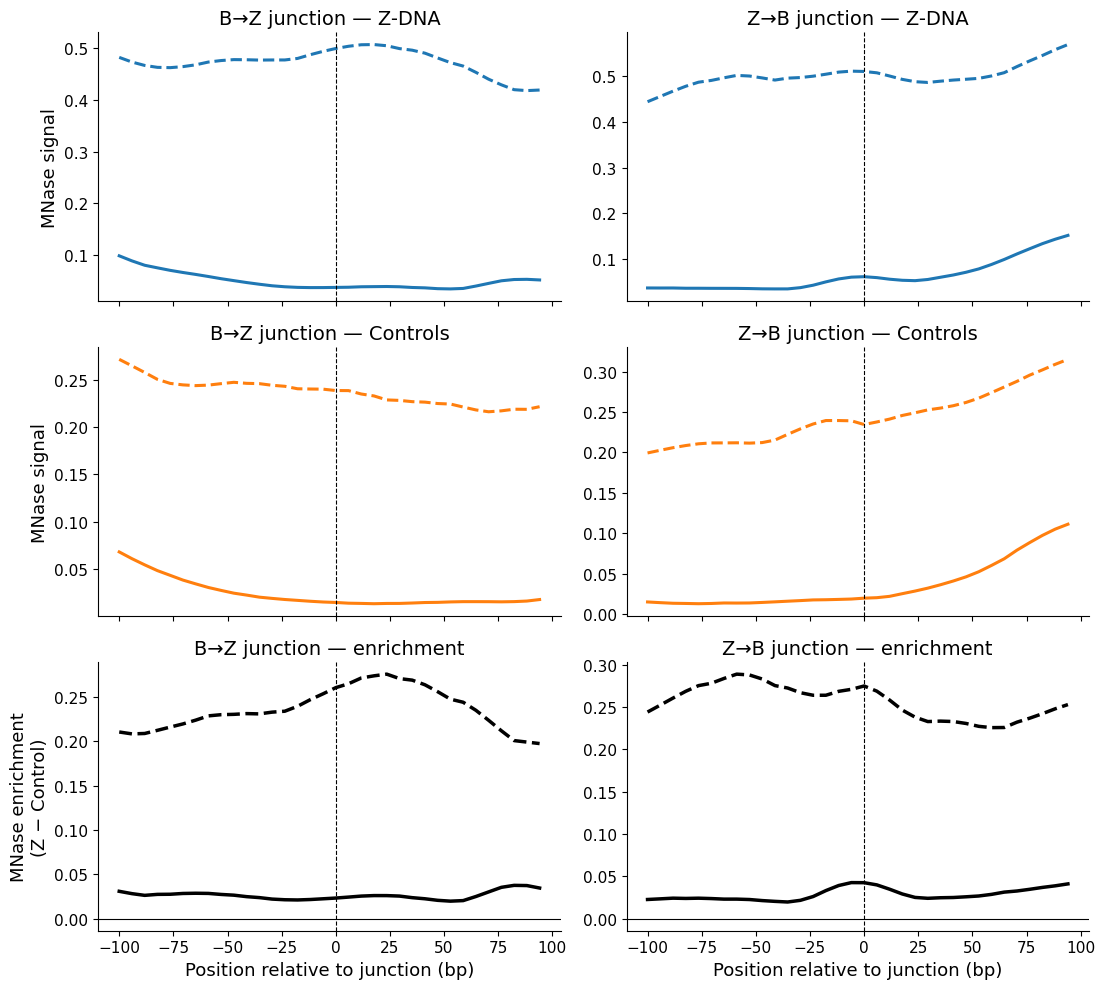

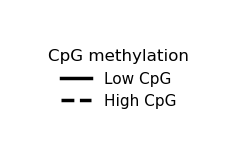

[OK] Wrote legend: /work/10906/geomeg/vista/pangenomes_zdna/mnase_K562/figures/MNase_methylation_stratified_profiles_legend.png

[DONE] Wrote: /work/10906/geomeg/vista/pangenomes_zdna/mnase_K562/figures/MNase_methylation_stratified_profiles.png


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
COLORS = {
    "Z": "tab:blue",
    "C": "tab:orange",
}
LINESTYLES = {
    "Low CpG": "-",
    "High CpG": "--",
}
BASE = Path("/work/10906/geomeg/vista/pangenomes_zdna/mnase_K562")
OUT  = BASE / "figures" / "MNase_methylation_stratified_profiles.png"
OUT.parent.mkdir(exist_ok=True)
FILES = {
    "B→Z": {
        "Low CpG":  BASE / "mnase_low_start.matrix.tsv",
        "High CpG": BASE / "mnase_high_start.matrix.tsv",
    },
    "Z→B": {
        "Low CpG":  BASE / "mnase_low_end.matrix.tsv",
        "High CpG": BASE / "mnase_high_end.matrix.tsv",
    },
}
WINDOW = 100
META_COLS = 6
MAX_MISSING_FRAC = 0.25
LABEL_FONTSIZE = 13
TICK_FONTSIZE  = 11
TITLE_FONTSIZE = 14
def load_matrix(path):
    df = pd.read_csv(path, sep="\t", comment="#", header=None)
    return df.iloc[:, META_COLS:].apply(pd.to_numeric, errors="coerce").to_numpy()
def filter_regions(arr):
    keep = np.mean(np.isnan(arr), axis=1) <= MAX_MISSING_FRAC
    return arr[keep], keep
def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
def hide_yaxis(ax):
    ax.set_ylabel("")
fig, axes = plt.subplots(
    nrows=3, ncols=2,
    figsize=(12, 10),
    sharex=True
)
for col, (junction, groups) in enumerate(FILES.items()):
    profiles = {}
    for label, path in groups.items():
        vals = load_matrix(path)
        n = vals.shape[0] // 2
        Z_raw = vals[:n]
        C_raw = vals[n:2*n]
        Z, _ = filter_regions(Z_raw)
        C, _ = filter_regions(C_raw)
        valid_bins = ~(
            np.all(np.isnan(Z), axis=0) &
            np.all(np.isnan(C), axis=0)
        )
        Z = Z[:, valid_bins]
        C = C[:, valid_bins]
        x = np.linspace(-WINDOW, WINDOW, Z.shape[1], endpoint=False)
        profiles[label] = {
            "x": x,
            "Z_mean": np.nanmean(Z, axis=0),
            "C_mean": np.nanmean(C, axis=0),
            "nZ": Z.shape[0],
            "nC": C.shape[0],
        }
    ax = axes[0, col]
    for label, p in profiles.items():
        ax.plot(
            p["x"], p["Z_mean"],
            lw=2.2,
            color=COLORS["Z"],
            linestyle=LINESTYLES[label],
            label=label
        )
    ax.axvline(0, color="black", ls="--", lw=0.8)
    if col == 0:
        ax.set_ylabel("MNase signal", fontsize=LABEL_FONTSIZE)
    else:
        hide_yaxis(ax)
    ax.set_title(f"{junction} junction — Z-DNA", fontsize=TITLE_FONTSIZE)
    ax.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax)
    ax = axes[1, col]
    for label, p in profiles.items():
        ax.plot(
            p["x"], p["C_mean"],
            lw=2.2,
            color=COLORS["C"],
            linestyle=LINESTYLES[label]
        )
    ax.axvline(0, color="black", ls="--", lw=0.8)
    if col == 0:
        ax.set_ylabel("MNase signal", fontsize=LABEL_FONTSIZE)
    else:
        hide_yaxis(ax)
    ax.set_title(f"{junction} junction — Controls", fontsize=TITLE_FONTSIZE)
    ax.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax)
    ax = axes[2, col]
    for label, p in profiles.items():
        ax.plot(
            p["x"],
            p["Z_mean"] - p["C_mean"],
            lw=2.5,
            color="black",
            linestyle=LINESTYLES[label]
        )
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(0, color="black", ls="--", lw=0.8)
    if col == 0:
        ax.set_ylabel("MNase enrichment\n(Z − Control)", fontsize=LABEL_FONTSIZE)
    else:
        hide_yaxis(ax)
    ax.set_title(f"{junction} junction — enrichment", fontsize=TITLE_FONTSIZE)
    ax.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax)
    print(f"\n[{junction}]")
    for label, p in profiles.items():
        print(f"  {label:8s}: Z={p['nZ']:,}  CTRL={p['nC']:,}")
axes[2, 0].set_xlabel("Position relative to junction (bp)", fontsize=LABEL_FONTSIZE)
axes[2, 1].set_xlabel("Position relative to junction (bp)", fontsize=LABEL_FONTSIZE)
from matplotlib.lines import Line2D
legend_lines = [
    Line2D([0], [0], color="black", lw=2.5, linestyle="-",  label="Low CpG"),
    Line2D([0], [0], color="black", lw=2.5, linestyle="--", label="High CpG"),
]
plt.tight_layout(rect=[0, 0, 0.93, 1])
plt.savefig(OUT, dpi=600)
plt.show(fig)
fig_leg = plt.figure(figsize=(2.8, 1.8))
ax_leg = fig_leg.add_subplot(111)
ax_leg.axis("off")
ax_leg.legend(
    handles=legend_lines,
    labels=[h.get_label() for h in legend_lines],
    title="CpG methylation",
    frameon=False,
    loc="center",
    fontsize=11,
    title_fontsize=12,
)
LEGEND_OUT = OUT.with_name(OUT.stem + "_legend.png")
fig_leg.savefig(LEGEND_OUT, dpi=600, bbox_inches="tight")
plt.show(fig_leg)
print("[OK] Wrote legend:", LEGEND_OUT)
print("\n[DONE] Wrote:", OUT)

### GM12878 (redo)

In [14]:
import pandas as pd
from pathlib import Path

BASE = Path("/work/10906/geomeg/vista/pangenomes_zdna")
MASTER = BASE / "controls_combined/CHM13_controls_MASTER.tsv"
OUTDIR = BASE / "mnase_GM12878"
OUTDIR.mkdir(exist_ok=True)

TOL = "10%"

m = pd.read_csv(MASTER, sep="\t", dtype={"Chromosome": str})

m["has_control"] = m["has_control"].astype(str).map({"True": True, "False": False})

m = (
    m[
        (m["tol_level"] == TOL) &
        (m["has_control"]) &
        (m["Chromosome"] != "chrY")
    ]
    .drop_duplicates(subset=["Chromosome", "Start0", "End0"])
    .reset_index(drop=True)
)

############################
# Z-DNA BED
############################
z = m[["Chromosome", "Start0", "End0"]].copy()
z.columns = ["chrom", "start", "end"]
z = z.astype({"start": int, "end": int})
z["name"] = [f"Z{i:06d}" for i in range(len(z))]
z["score"] = 0
z["strand"] = "."

z_bed = OUTDIR / "ZDNA_tol10.bed"
z[["chrom", "start", "end", "name", "score", "strand"]].to_csv(
    z_bed, sep="\t", header=False, index=False
)

############################
# CONTROL BED
############################
c = m[["Chromosome", "Ctrl_Start", "Ctrl_End"]].copy()
c.columns = ["chrom", "start", "end"]
c = c.astype({"start": int, "end": int})
c["name"] = [f"C{i:06d}" for i in range(len(c))]
c["score"] = 0
c["strand"] = "."

c_bed = OUTDIR / "CTRL_tol10.bed"
c[["chrom", "start", "end", "name", "score", "strand"]].to_csv(
    c_bed, sep="\t", header=False, index=False
)

print("Wrote:")
print(z_bed)
print(c_bed)

Wrote:
/work/10906/geomeg/vista/pangenomes_zdna/mnase_GM12878/ZDNA_tol10.bed
/work/10906/geomeg/vista/pangenomes_zdna/mnase_GM12878/CTRL_tol10.bed


In [ ]:
#!/usr/bin/env bash
set -euo pipefail

BASE="/work/10906/geomeg/vista/pangenomes_zdna"
MNASE="$BASE/mnase_GM12878"

BW="$MNASE/mnase_GM12878.chm13.bigWig"
CHROMSIZES="$MNASE/hs1.chrom.sizes.txt"

ZBED="$MNASE/ZDNA_tol10.bed"
CBED="$MNASE/CTRL_tol10.bed"

WINDOW=100
BINSIZE=5
SHIFT=1000

############################
# sort BEDs
############################
sort -k1,1 -k2,2n "$ZBED" > "$MNASE/ZDNA_tol10.sorted.bed"
sort -k1,1 -k2,2n "$CBED" > "$MNASE/CTRL_tol10.sorted.bed"

ZBED="$MNASE/ZDNA_tol10.sorted.bed"
CBED="$MNASE/CTRL_tol10.sorted.bed"

############################
# junction anchors (1 bp)
############################
awk 'BEGIN{OFS="\t"} {print $1,$2,$2+1}' "$ZBED" > "$MNASE/ZDNA_start_1bp.bed"
awk 'BEGIN{OFS="\t"} {print $1,$3-1,$3}' "$ZBED" > "$MNASE/ZDNA_end_1bp.bed"

awk 'BEGIN{OFS="\t"} {print $1,$2,$2+1}' "$CBED" > "$MNASE/CTRL_start_1bp.bed"
awk 'BEGIN{OFS="\t"} {print $1,$3-1,$3}' "$CBED" > "$MNASE/CTRL_end_1bp.bed"

############################
# chromosome-safe filtering
############################
filter_valid () {
  bedtools slop \
    -i "$1" \
    -g "$CHROMSIZES" \
    -b "$WINDOW" \
  | awk '($2 >= 0)' \
  > "$2"
}

filter_valid "$MNASE/ZDNA_start_1bp.bed" "$MNASE/ZDNA_start_1bp.valid.bed"
filter_valid "$MNASE/ZDNA_end_1bp.bed"   "$MNASE/ZDNA_end_1bp.valid.bed"
filter_valid "$MNASE/CTRL_start_1bp.bed" "$MNASE/CTRL_start_1bp.valid.bed"
filter_valid "$MNASE/CTRL_end_1bp.bed"   "$MNASE/CTRL_end_1bp.valid.bed"

############################
# shifted negative controls
############################
awk -v S=$SHIFT 'BEGIN{OFS="\t"} {print $1,$2+S,$3+S}' \
  "$MNASE/ZDNA_start_1bp.valid.bed" > "$MNASE/ZDNA_start_shifted.bed"

awk -v S=$SHIFT 'BEGIN{OFS="\t"} {print $1,$2+S,$3+S}' \
  "$MNASE/CTRL_start_1bp.valid.bed" > "$MNASE/CTRL_start_shifted.bed"

filter_valid "$MNASE/ZDNA_start_shifted.bed" "$MNASE/ZDNA_start_shifted.valid.bed"
filter_valid "$MNASE/CTRL_start_shifted.bed" "$MNASE/CTRL_start_shifted.valid.bed"


In [ ]:
computeMatrix reference-point \
  --referencePoint center \
  -b 100 -a 100 \
  --binSize 5 \
  -S "$BW" \
  -R \
    "$MNASE/ZDNA_start_1bp.valid.bed" \
    "$MNASE/CTRL_start_1bp.valid.bed" \
  --sortRegions keep \
  -o "$MNASE/mnase_start.mat.gz" \
  --outFileNameMatrix "$MNASE/mnase_start.matrix.tsv" \
  -p max

computeMatrix reference-point \
  --referencePoint center \
  -b 100 -a 100 \
  --binSize 5 \
  -S "$BW" \
  -R \
    "$MNASE/ZDNA_end_1bp.valid.bed" \
    "$MNASE/CTRL_end_1bp.valid.bed" \
  --sortRegions keep \
  -o "$MNASE/mnase_end.mat.gz" \
  --outFileNameMatrix "$MNASE/mnase_end.matrix.tsv" \
  -p max


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

###############################################################################
# CONFIG
###############################################################################

BASE = Path("/work/10906/geomeg/vista/pangenomes_zdna/mnase_GM12878")
OUTDIR = BASE / "figures"
OUTDIR.mkdir(exist_ok=True)

MATRICES = {
    "BtoZ": BASE / "mnase_start.matrix.tsv",
    "ZtoB": BASE / "mnase_end.matrix.tsv",
}

WINDOW = 100
MAX_MISSING_FRAC = 0.25
SORT_WINDOW = 20
META_COLS = 6
MAX_ROWS = 50000

# typography
LABEL_FONTSIZE = 14
TICK_FONTSIZE = 12
TITLE_FONTSIZE = 15

###############################################################################
# UTILITIES
###############################################################################

def load_matrix(path):
    df = pd.read_csv(path, sep="\t", comment="#", header=None, low_memory=False)
    vals = df.iloc[:, META_COLS:].apply(pd.to_numeric, errors="coerce")
    return vals.to_numpy(dtype=np.float32)


def filter_regions(arr):
    keep = np.mean(np.isnan(arr), axis=1) <= MAX_MISSING_FRAC
    return arr[keep]


def downsample_rows(A, max_rows=MAX_ROWS):
    if A.shape[0] <= max_rows:
        return A
    idx = np.linspace(0, A.shape[0] - 1, max_rows).astype(int)
    return A[idx]


def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


###############################################################################
# MAIN LOOP
###############################################################################

for label, matrix_path in MATRICES.items():

    print(f"[INFO] Processing {label}")

    vals = load_matrix(matrix_path)

    n = vals.shape[0] // 2
    Z = vals[:n]
    C = vals[n:2*n]

    Z = filter_regions(Z)
    C = filter_regions(C)

    valid_bins = ~(np.all(np.isnan(Z), axis=0) & np.all(np.isnan(C), axis=0))
    Z = Z[:, valid_bins]
    C = C[:, valid_bins]

    x = np.linspace(-WINDOW, WINDOW, Z.shape[1], endpoint=False)

    sort_mask = (x >= -SORT_WINDOW) & (x <= SORT_WINDOW)
    z_score = np.nanmean(Z[:, sort_mask], axis=1)
    order = np.argsort(z_score)[::-1]

    Zs = Z[order]
    Cs = C[order[:C.shape[0]]]

    Zp = downsample_rows(Zs)
    Cp = downsample_rows(Cs)

    combined = np.concatenate([Zp.ravel(), Cp.ravel()])
    combined = combined[~np.isnan(combined)]
    vmin, vmax = np.percentile(combined, [2, 98])

    ###########################################################################
    # FIGURE
    ###########################################################################

    fig = plt.figure(figsize=(7.5, 8.5))

    ax0 = plt.subplot2grid((3, 1), (0, 0))
    ax1 = plt.subplot2grid((3, 1), (1, 0))
    ax2 = plt.subplot2grid((3, 1), (2, 0))

    # profile
    ax0.plot(x, np.nanmean(Z, axis=0), label="Z-DNA", lw=2)
    ax0.plot(x, np.nanmean(C, axis=0), label="Control", lw=2)
    ax0.axvline(0, color="black", ls="--", lw=0.8)
    ax0.set_ylabel("MNase signal", fontsize=LABEL_FONTSIZE)
    ax0.legend(frameon=False, fontsize=LABEL_FONTSIZE)
    ax0.set_title(f"MNase signal at {label} junctions", fontsize=TITLE_FONTSIZE)
    ax0.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax0)

    # Z-DNA heatmap
    im = ax1.imshow(
        Zp,
        aspect="auto",
        interpolation="nearest",
        cmap="cividis",
        vmin=vmin,
        vmax=vmax,
        extent=[x[0], x[-1], Zp.shape[0], 0],
    )
    ax1.axvline(0, color="black", ls="--", lw=0.8)
    ax1.set_ylabel("Regions", fontsize=LABEL_FONTSIZE)
    ax1.set_title("Z-DNA (sorted by ±20 bp mean)", fontsize=TITLE_FONTSIZE)
    ax1.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax1)

    # Control heatmap
    ax2.imshow(
        Cp,
        aspect="auto",
        interpolation="nearest",
        cmap="cividis",
        vmin=vmin,
        vmax=vmax,
        extent=[x[0], x[-1], Cp.shape[0], 0],
    )
    ax2.axvline(0, color="black", ls="--", lw=0.8)
    ax2.set_xlabel("Position relative to junction (bp)", fontsize=LABEL_FONTSIZE)
    ax2.set_ylabel("Regions", fontsize=LABEL_FONTSIZE)
    ax2.set_title("Controls (displayed with Z sorting)", fontsize=TITLE_FONTSIZE)
    ax2.tick_params(labelsize=TICK_FONTSIZE)
    despine(ax2)

    plt.tight_layout()
    fig_path = OUTDIR / f"MNase_heatmap_{label}_python.png"
    plt.savefig(fig_path, dpi=300)
    plt.close(fig)

    ###########################################################################
    # SEPARATE COLORBAR
    ###########################################################################

    fig_cb, ax_cb = plt.subplots(figsize=(1.2, 4))
    cb = plt.colorbar(im, cax=ax_cb)
    cb.set_label("MNase signal", fontsize=LABEL_FONTSIZE)
    cb.ax.tick_params(labelsize=TICK_FONTSIZE)
    #despine(ax_cb)
    plt.tight_layout()
    cb_path = OUTDIR / f"MNase_heatmap_{label}_colorbar.png"
    plt.savefig(cb_path, dpi=300)
    plt.close(fig_cb)

    print(f"  Saved: {fig_path.name}")
    print(f"  Saved: {cb_path.name}")

print("[DONE] All heatmaps generated.")


[INFO] Processing BtoZ


/tmp/ipykernel_2520798/933210165.py:81: RuntimeWarning: Mean of empty slice
  z_score = np.nanmean(Z[:, sort_mask], axis=1)
/tmp/ipykernel_2520798/933210165.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 750x850 with 3 Axes> than <Figure size 120x400 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, cax=ax_cb)


  Saved: MNase_heatmap_BtoZ_python.png
  Saved: MNase_heatmap_BtoZ_colorbar.png
[INFO] Processing ZtoB


/tmp/ipykernel_2520798/933210165.py:81: RuntimeWarning: Mean of empty slice
  z_score = np.nanmean(Z[:, sort_mask], axis=1)


  Saved: MNase_heatmap_ZtoB_python.png
  Saved: MNase_heatmap_ZtoB_colorbar.png
[DONE] All heatmaps generated.


/tmp/ipykernel_2520798/933210165.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 750x850 with 3 Axes> than <Figure size 120x400 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, cax=ax_cb)


In [ ]:
# bigWigToBedGraph ENCFF000VME.bigWig mnase.hg19.bedGraph

# liftOver \
#   mnase.hg19.bedGraph \
#   hg19-chm13v2.chain \
#   mnase.chm13.bedGraph \
#   mnase.hg19_to_chm13.unmapped.bedGraph

# wc -l mnase.hg19.bedGraph mnase.chm13.bedGraph mnase.hg19_to_chm13.unmapped.bedGraph

# sort -k1,1 -k2,2n mnase.chm13.bedGraph > mnase.chm13.sorted.bedGraph

# bedGraphToBigWig \
#   mnase.chm13.sorted.bedGraph \
#   hs1.chrom.sizes.txt \
#   mnase_GM12878.chm13.bigWig

# ls -lh mnase_GM12878.chm13.bigWig
# file mnase_GM12878.chm13.bigWig


# bigWigInfo mnase_GM12878.chm13.bigWig | head

# Draft